# FSBI → Inflation → Markets: one linear pipeline

**Question for Fiserv.** Is the Fiserv Small Business Index (FSBI) a useful leading read on US inflation (CPI, core CPI, PCE, core PCE), and where does it carry information that can be traded?

This notebook replaces the consolidated v3 notebook with a single top-to-bottom pipeline. Each stage feeds the next, every experiment runs through one forecasting engine, and every strategy runs through one backtest engine.

| # | Stage | Capstone deliverable | What it produces |
|---|---|---|---|
| 0 | Setup | – | configuration, caches, statistical helpers |
| 1 | Data | Preprocessed dataset | FSBI panel (national / sector / state / region), first-print inflation targets, benchmarks (Cleveland nowcast, Kalshi), macro features, prices → `processed/fsbi_macro_dataset.csv` |
| 2 | EDA | EDA report | trends, seasonality, structural break, lead–lag correlations, sector ↔ CPI-component and region ↔ regional-CPI links |
| 3 | Forecasting | Forecasting model | feature-set ladder (what FSBI adds), model zoo with tuning, anchor test (alone / vs nowcast / vs Kalshi), granular models, final online-selected forecast, feature importance by model, economic nowcasts and a leading-indicator scan |
| 4 | Trading | Simulation framework + performance report | twelve strategy families across ETFs, TIPS, corporate credit, small-cap sectors, FX, commodities, volatility and Kalshi; leaderboard with multiple-testing guards, risk overlays, Monte Carlo, value of forecast accuracy |
| 5 | Dashboard | Interactive visualisation | static Plotly page `processed/fsbi_dashboard.html`; section 7 exports the data for the full interactive Streamlit app `app.py` |
| 6 | Findings | Final report inputs | scorecard and use cases for Fiserv, generated from this run |

**Timing convention (used everywhere).** FSBI for reference month *t* is published in the first days of *t+1*. All features are read on **FSBI day** (the 6th of *t+1* or the next trading day), which is before the CPI release (mid *t+1*) and the PCE release (end of *t+1*). So every forecast here is a *nowcast of month t made before the official print*, and every trade is entered on or after FSBI day.

```
 month t ends ── FSBI day (≈6th) ───── CPI release (≈13th) ───── PCE release (≈28th) ── next FSBI day
                 features known          first print of CPI          first print of PCE
                 forecasts made          surprise trades exit        monthly trades roll
```

**What changed from v3** (details in the last section): one data layer instead of two, one backtest engine instead of three, explicit sector mappings instead of keyword matching, 180 cells → about 75. The Kalshi Greeks section, the PDF generator and the backtrader replay were removed; nothing downstream depended on them.

**To run:** put the two Fiserv exports in a `Data/` folder next to the notebook: `Non Inflation Adjusted.csv` (nominal, required) and `Inflation Adjusted.csv` (real, optional). Set `FRED_API_KEY` in the environment or a `.env` file, then *Run All*. Set `FAST = True` for a quick end-to-end pass.

**After each FSBI release:** replace the two CSV files in `Data/` and *Run All*. Nothing else needs to change. The forecast month, the release calendar, every table, chart and the dashboard follow the newest month in the file. Downloads are cached under `Data/cache/` and refreshed when they are more than `CACHE_HOURS` old (a rerun with no network falls back to the cache).

## 0. Setup

All configuration lives in this one cell. The two settings that matter most for honesty:

- **Design period vs live period.** Every forecast and every strategy is run through the newest month, so the dashboard is always current. But the statistics used to *choose* models and strategies (scores, p-values, leaderboard) are computed on months before `HOLDOUT_START` only. Months from `HOLDOUT_START` on are the **live track record**: real-time results of a design that was fixed before they happened, reported separately. Look at them, but do not change the design because of them.

- `HOLDOUT_START`: months from here on are never used for model choice or strategy design. Flip `RUN_HOLDOUT = True` once, when the design is frozen.
- `COVID`: March 2020 – June 2021 is excluded from training and scoring. FSBI moves of ±20% in those months would otherwise dominate every fit.

In [46]:
import json, os, pickle, time, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from scipy.stats import norm
from pandas.tseries.holiday import USFederalHolidayCalendar
from pandas.tseries.offsets import CustomBusinessDay
from sklearn.decomposition import PCA
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LassoCV, LinearRegression, RidgeCV
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    from xgboost import XGBRegressor
    HAVE_XGB = True
except ImportError:                      # falls back to scikit-learn gradient boosting
    HAVE_XGB = False
try:
    from dotenv import load_dotenv; load_dotenv()
except ImportError:
    pass

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
sns.set_theme(style="whitegrid", context="notebook")

# ------------------------------------------------------------------ configuration
FAST          = False                          # True: fewer trees / draws, for a quick end-to-end check
SEED          = 7
FSBI_DAY      = 6                              # FSBI lands on the 2nd-6th; everything is read on the 6th (or next trading day)
COVID         = ("2020-03-01", "2021-06-01")   # excluded from fitting and scoring
HOLDOUT_START = pd.Timestamp("2025-03-01")     # statistics for model and strategy choice use months before this; later months are the live track record
RUN_HOLDOUT   = False
MIN_TRAIN     = 24                             # months of history before the first out-of-sample forecast
COST          = 0.0005                         # ETF trading cost per side, on gross exposure (5 bp)
START         = "2010-01-01"                   # earliest FRED / price history requested
CACHE_HOURS   = 12                             # downloads older than this are refreshed (cached copy used if the refresh fails)
NOMINAL_FILE, REAL_FILE = "Non Inflation Adjusted.csv", "Inflation Adjusted.csv"
RELEASE_FILE  = "fsbi_release_dates.csv"       # optional, in the Data folder: columns month (YYYY-MM) and release_date; months not listed fall back to FSBI_DAY

TARGETS = ["cpi", "core_cpi", "pce", "core_pce"]
LABEL   = {"cpi": "CPI", "core_cpi": "core CPI", "pce": "PCE", "core_pce": "core PCE"}
FRED_ID = {"cpi": "CPIAUCSL", "core_cpi": "CPILFESL", "pce": "PCEPI", "core_pce": "PCEPILFE"}

def find_fsbi(folder, real):
    """The newest Fiserv export in a folder: exact file name first, then any CSV whose name says (Non) Inflation Adjusted."""
    exact = folder / (REAL_FILE if real else NOMINAL_FILE)
    if exact.exists():
        return exact
    hits = [p for p in folder.glob("*Inflation Adjusted*.csv") if ("non inflation" in p.name.lower()) != real]
    return max(hits, key=lambda p: p.stat().st_mtime) if hits else None
DATA_DIR = next((p for p in [Path("Data"), Path("../Data"), Path("data"), Path("../data"), Path(".")] if p.is_dir() and find_fsbi(p, real=False)), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"'{NOMINAL_FILE}' not found in Data/, ../Data, data/, ../data or the working directory.")
NOMINAL_PATH, REAL_PATH = find_fsbi(DATA_DIR, real=False), find_fsbi(DATA_DIR, real=True)
FAR = pd.Timestamp("2100-01-01")
fresh = lambda f, hours=None: f.exists() and time.time() - f.stat().st_mtime < 3600 * (hours or CACHE_HOURS)
CACHE, PROC = DATA_DIR / "cache", DATA_DIR / "processed"
for p in (CACHE / "fred", CACHE / "yf", CACHE / "kalshi", PROC):
    p.mkdir(parents=True, exist_ok=True)
EVAL_END = pd.Timestamp("2100-01-01") if RUN_HOLDOUT else HOLDOUT_START
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------ small helpers used throughout
BDAY = CustomBusinessDay(calendar=USFederalHolidayCalendar())
FSBI_REL = {}
if (DATA_DIR / RELEASE_FILE).exists():
    _r = pd.read_csv(DATA_DIR / RELEASE_FILE); _r.columns = [c.strip().lower() for c in _r.columns]
    FSBI_REL = {pd.Timestamp(str(m) + "-01") if len(str(m)) == 7 else pd.Timestamp(m).replace(day=1): pd.Timestamp(d) for m, d in zip(_r["month"], _r["release_date"]) if pd.notna(d)}
def fsbi_day(t):
    """Calendar day FSBI for reference month t was published: the supplied date if there is one, else the FSBI_DAY-th of the next month."""
    return FSBI_REL.get(pd.Timestamp(t), pd.Timestamp(t) + pd.DateOffset(months=1, days=FSBI_DAY - 1))
rmse = lambda e: float(np.sqrt(np.mean(np.square(pd.Series(e, dtype=float).dropna()))))
mae  = lambda e: float(np.mean(np.abs(pd.Series(e, dtype=float).dropna())))

def in_covid(index):
    return pd.Series(index, index=index).between(*COVID).values

def expanding_z(x, min_periods=12):
    """z-score against the mean and sd of EARLIER observations only (no look-ahead)."""
    m, s = x.expanding(min_periods).mean().shift(1), x.expanding(min_periods).std().shift(1)
    return (x - m) / s.where(s > 0)

def dm_p(e_model, e_ref, lags=3):
    """Diebold-Mariano test of equal squared error (HAC standard errors). Small p + lower RMSE = reliably better."""
    d = (pd.Series(e_model, dtype=float) ** 2 - pd.Series(e_ref, dtype=float) ** 2).dropna()
    if len(d) < 8 or d.std() == 0:
        return np.nan
    return float(sm.OLS(d.values, np.ones(len(d))).fit(cov_type="HAC", cov_kwds={"maxlags": lags}).pvalues[0])

def cw_p(e_big, e_small, lags=3):
    """Clark-West (2007) test for NESTED models: is the larger model (e_big) better than the smaller one it contains (e_small)?
    Diebold-Mariano is biased against the larger model in that case, because estimating extra coefficients adds noise even when
    they are truly non-zero; CW removes that term. One-sided p-value: small = the extra inputs carry predictive content."""
    d = pd.concat([pd.Series(e_big, dtype=float).rename("b"), pd.Series(e_small, dtype=float).rename("s")], axis=1).dropna()
    if len(d) < 8:
        return np.nan
    f = d.s ** 2 - (d.b ** 2 - (d.s - d.b) ** 2)             # (e_small - e_big) equals the difference between the two forecasts
    if f.std() == 0:
        return np.nan
    fit = sm.OLS(f.values, np.ones(len(f))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(1 - norm.cdf(fit.tvalues[0]))

def block_bootstrap(r, stat, n_boot=None, block=3, seed=SEED):
    """Stationary-style block bootstrap of a return series; returns the bootstrap distribution of stat(sample)."""
    r = np.asarray(pd.Series(r, dtype=float).dropna()); n = len(r); n_boot = n_boot or (300 if FAST else 2000)
    if n < 2 * block:
        return np.array([np.nan])
    g = np.random.default_rng(seed); starts = np.arange(n - block + 1)
    return np.array([stat(np.concatenate([r[s:s + block] for s in g.choice(starts, n // block + 1)])[:n]) for _ in range(n_boot)])

def boot_p(r, stat=lambda x: x.mean()):
    """One-sided bootstrap p-value that stat(returns) is not above zero; (1 + count) / (n + 1), so it is never exactly 0."""
    bs = block_bootstrap(r, stat); bs = bs[np.isfinite(bs)]
    return float((1 + (bs <= 0).sum()) / (len(bs) + 1)) if len(bs) else np.nan

def holm(p):
    """Holm step-down adjustment: the honest p-value after trying many strategies."""
    p = pd.Series(p, dtype=float); ok = p.dropna().sort_values(); m = len(ok)
    adj = (ok * (m - np.arange(m))).cummax().clip(upper=1.0)
    return adj.reindex(p.index)

def perf(r, periods=12):
    """The capstone's performance metrics from a series of periodic net returns."""
    r = pd.Series(r, dtype=float).dropna()
    if len(r) < 3 or r.std() == 0:
        return {"periods": len(r)}
    c = (1 + r).cumprod(); down = r[r < 0]; wins, losses = r[r > 0], r[r < 0]
    return {"periods": len(r), "ROI (%)": 100 * (c.iloc[-1] - 1), "ann. return (%)": 100 * (c.iloc[-1] ** (periods / len(r)) - 1),
            "ann. vol (%)": 100 * r.std() * np.sqrt(periods), "Sharpe": r.mean() / r.std() * np.sqrt(periods),
            "Sortino": r.mean() / down.std() * np.sqrt(periods) if len(down) > 1 and down.std() > 0 else np.nan,
            "max DD (%)": 100 * (c / c.cummax() - 1).min(), "win rate": float((r[r != 0] > 0).mean()) if (r != 0).any() else np.nan,
            "win/loss": wins.mean() / -losses.mean() if len(wins) and len(losses) else np.nan}

# ------------------------------------------------------------------ FRED with a disk cache (reruns need no network)
_fred = None
def _fred_call(method, sid, **kw):
    global _fred
    f = CACHE / "fred" / f"{sid}_{method}.pkl"
    cached = pickle.loads(f.read_bytes()) if f.exists() else None
    if cached is not None and fresh(f, CACHE_HOURS if not isinstance(cached, Exception) else 24 * 30):
        if isinstance(cached, Exception):                   # a series FRED said does not exist is re-checked monthly
            raise cached
        return cached
    try:
        if _fred is None:
            from fredapi import Fred
            if not os.environ.get("FRED_API_KEY"):
                raise RuntimeError("Set FRED_API_KEY (free at fred.stlouisfed.org) in the environment or a .env file.")
            _fred = Fred(api_key=os.environ["FRED_API_KEY"])
        for attempt in range(6):
            try:
                time.sleep(0.55)                               # FRED allows ~120 requests a minute
                out = getattr(_fred, method)(sid, **kw); f.write_bytes(pickle.dumps(out)); return out
            except ValueError as exc:
                if "too many requests" in str(exc).lower() or "rate limit" in str(exc).lower():
                    time.sleep(min(15 * 2 ** attempt, 120)); continue
                if "does not exist" in str(exc).lower() or "bad request" in str(exc).lower():
                    f.write_bytes(pickle.dumps(ValueError(str(exc))))
                raise
        raise RuntimeError(f"FRED is still rate-limiting ({sid}); rerun the cell, progress is cached.")
    except Exception:
        if cached is not None and not isinstance(cached, Exception):
            STALE.add(sid); return cached                   # offline or failing: use the older copy and say so at the end
        raise
STALE = set()

def fred_series(sid, monthly=None):
    """A FRED series (latest vintage). monthly='mean' / 'last' resamples daily or weekly data to month-start."""
    s = _fred_call("get_series", sid, observation_start=START).astype(float); s.index = pd.to_datetime(s.index)
    return s if monthly is None else getattr(s.resample("MS"), monthly)()

def fred_try(sid, monthly=None):
    try:
        return fred_series(sid, monthly)
    except Exception as exc:
        print(f"  FRED series {sid} unavailable ({str(exc)[:50]}); skipped."); return None

def fred_vintages(sid):
    """Every published vintage of a series (ALFRED): columns date, realtime_start, value."""
    v = _fred_call("get_series_all_releases", sid, realtime_start="2017-01-01").copy()
    v["value"] = pd.to_numeric(v["value"], errors="coerce")
    v["date"], v["realtime_start"] = pd.to_datetime(v["date"]), pd.to_datetime(v["realtime_start"])
    return v

print(f"FSBI files: {NOMINAL_PATH.resolve()} (modified {pd.Timestamp(NOMINAL_PATH.stat().st_mtime, unit='s'):%Y-%m-%d %H:%M})"
      + (f" and {REAL_PATH.name}" if REAL_PATH else " (no real-sales file)")
      + f"\nFAST={FAST} | statistics use months before {EVAL_END.date()} | caches refresh after {CACHE_HOURS}h | XGBoost={'yes' if HAVE_XGB else 'no (sklearn GBM)'}")

FSBI files: C:\Users\liamf\OneDrive - Georgia Institute of Technology\QCF\Classes\Fall 2026\MGT 6785\QCF_Capstone_Fiserv\Data\Non Inflation Adjusted.csv (modified 2026-11-15 22:21) and Inflation Adjusted.csv
FAST=False | statistics use months before 2025-03-01 | caches refresh after 12h | XGBoost=yes


## 1. Data

### 1.1 FSBI panel

`Non Inflation Adjusted.csv` holds one row per month × geography × sector × sub-sector, with a **sales** index and a **transactions** index (seasonally adjusted and not). Three series are built for every entity:

| series | definition | reads as |
|---|---|---|
| `sales` | nominal sales index | spending = price × volume |
| `txn` | transaction-count index | **volume** (demand) |
| `ticket` | sales ÷ transactions | **price per purchase**, the inflation-like part of FSBI |

All growth rates are monthly log changes × 100 of the seasonally adjusted index. Levels are organised as `FSBI[level][metric]` with `level` ∈ national, sector, subsector, state, region, region_sector. Regions are the four Census regions, aggregated from states with 2020 Census population weights (a fixed constant, so no extra downloads). Each state index is based to 100 in its own base period, so a population-weighted average of indices is an approximation to a true regional index (which would weight by base-period sales).

The sector mapping below is explicit: each FSBI series that has a natural market or price counterpart is tied by hand to a sector ETF and a CPI component. v3 did this with keyword matching, which was hard to audit.

In [47]:
SHORT = {  # FSBI sector name (prefix) -> short label
    "Accommodation and Food": "Accommodation & food", "Administrative and Support": "Admin & support", "Arts, Entertainment": "Arts & recreation",
    "Construction": "Construction", "Educational": "Education", "Health Care": "Health care", "Information": "Information",
    "Other Services": "Other services", "Professional": "Professional services", "Real Estate": "Real estate & rental",
    "Retail Trade": "Retail", "Transportation": "Transportation & warehousing", "Wholesale": "Wholesale"}
# FSBI sub-sector -> (short label, sector ETF, CPI component on FRED, goods/services). None = no clean counterpart.
SUBMAP = {
    "Food Services and Drinking Places": ("Restaurants", "PEJ", "CUSR0000SEFV", "services"),
    "Accommodation": ("Hotels", "PEJ", "CUSR0000SEHB", "services"),
    "Arts, Entertainment, and Recreation": ("Entertainment", "PEJ", "CPIRECSL", "services"),
    "Food and Beverage Retailers": ("Grocery", "XLP", "CUSR0000SAF11", "goods"),
    "Gasoline Stations and Fuel Dealers": ("Gas stations", "XLE", "CUSR0000SETB01", "energy"),
    "General Merchandise Retailers": ("General merchandise", "XRT", "CUSR0000SACL1E", "goods"),
    "Clothing, Clothing Accessories, Shoe, and Jewelry Retailers": ("Clothing", "XRT", "CPIAPPSL", "goods"),
    "Sporting Goods, Hobby, Musical Instrument, Book, and Miscellaneous Retailers": ("Sporting & hobby", "XRT", None, "goods"),
    "Furniture, Home Furnishings, Electronics, and Appliance Retailers": ("Furniture & electronics", "XHB", "CUSR0000SAH3", "goods"),
    "Building Material and Garden Equipment and Supplies Dealers": ("Building materials", "XHB", None, "goods"),
    "Specialty Trade Contractors": ("Contractors", "XHB", None, "services"),
    "Motor Vehicle and Parts Dealers": ("Auto dealers", "CARZ", "CUSR0000SETA", "goods"),
    "Health and Personal Care Retailers": ("Drug stores", "XLV", "CUSR0000SAM1", "goods"),
    "Ambulatory Health Care Services": ("Ambulatory health", "XLV", "CUSR0000SAM2", "services"),
    "Transportation": ("Transportation", "IYT", "CUSR0000SAS4", "services"),
    "Information": ("Information", "XLC", None, "services"),
    "Merchant Wholesalers, Durable Goods": ("Wholesale durables", "XLI", None, "goods"),
    "Personal and Laundry Services": ("Personal care", None, "CUSR0000SAG1", "services"),
    "Repair and Maintenance": ("Repair & maintenance", None, "CUSR0000SETD", "services"),
}
STATE_POP = dict(CA=39.54, TX=29.15, FL=21.54, NY=20.20, PA=13.00, IL=12.81, OH=11.80, GA=10.71, NC=10.44, MI=10.08, NJ=9.29, VA=8.63, WA=7.71, AZ=7.15, MA=7.03,
                 TN=6.91, IN=6.79, MD=6.18, MO=6.15, WI=5.89, CO=5.77, MN=5.71, SC=5.12, AL=5.02, LA=4.66, KY=4.51, OR=4.24, OK=3.96, CT=3.61, UT=3.27, IA=3.19,
                 NV=3.10, AR=3.01, MS=2.96, KS=2.94, NM=2.12, NE=1.96, ID=1.84, WV=1.79, HI=1.46, NH=1.38, ME=1.36, RI=1.10, MT=1.08, DE=0.99, SD=0.89, ND=0.78,
                 AK=0.73, VT=0.64, WY=0.58)                                    # 2020 Census, millions
REGIONS = {"Northeast": "CT ME MA NH RI VT NJ NY PA", "Midwest": "IL IN MI OH WI IA KS MN MO NE ND SD",
           "South": "DE FL GA MD NC SC VA WV AL KY MS TN AR LA OK TX", "West": "AZ CO ID MT NV NM UT WY AK CA HI OR WA"}

def load_fsbi(path):
    """Tidy one Fiserv export (nominal or real): period, geo, sector, subsector, sales/txn index (SA and NSA)."""
    df = pd.read_csv(path)
    df.columns = df.columns.str.replace(r"\s+", " ", regex=True).str.strip()
    ren = {"Geo": "geo", "Sector Name": "sector", "Sub-Sector Name": "subsector", "Transactional Index - SA": "txn", "Transactional Index - NSA": "txn_nsa"}
    ren.update({c: "sales" for c in df.columns if c.endswith("Sales Index - SA")}); ren.update({c: "sales_nsa" for c in df.columns if c.endswith("Sales Index - NSA")})
    df = df.rename(columns=ren); df["date"] = pd.to_datetime(df["Period"].astype(str), format="%Y%m%d")
    return df[["date", "geo", "sector", "subsector", "sales", "txn", "sales_nsa", "txn_nsa"]]

def wide(df, key, col):
    return df.pivot_table(index="date", columns=key, values=col, aggfunc="first").where(lambda p: p > 0)

raw = load_fsbi(NOMINAL_PATH)
STATES = sorted(g for g in raw.geo.unique() if g in STATE_POP)
REGIONS = {r: [s for s in v.split() if s in STATES] for r, v in REGIONS.items()}
STATE_REGION = {s: r for r, v in REGIONS.items() for s in v}
short_sector = lambda s: next((v for k, v in SHORT.items() if s.startswith(k)), s)

us = raw[raw.geo == "US"]
nat = us[(us.sector == "ALL") & (us.subsector == "ALL")].set_index("date").sort_index()
IDX = nat.index                                                                   # the monthly index every table is aligned to
sec = us[(us.sector != "ALL") & (us.subsector == "ALL")].assign(entity=lambda d: d.sector.map(short_sector))
sub = us[us.subsector.isin(SUBMAP)].assign(entity=lambda d: d.subsector.map(lambda s: SUBMAP[s][0]))
st  = raw[raw.geo.isin(STATES) & (raw.sector == "ALL") & (raw.subsector == "ALL")]

FSBI = {"national": {m: nat[[m]].set_axis(["US"], axis=1) for m in ("sales", "txn")},
        "sector": {m: wide(sec, "entity", m).reindex(IDX) for m in ("sales", "txn")},
        "subsector": {m: wide(sub, "entity", m).reindex(IDX) for m in ("sales", "txn")},
        "state": {m: wide(st, "geo", m).reindex(IDX) for m in ("sales", "txn")}}
w_state = pd.Series(STATE_POP)
FSBI["region"] = {m: pd.DataFrame({r: (FSBI["state"][m][s] * w_state[s]).sum(axis=1, min_count=len(s)) / w_state[s].sum() for r, s in REGIONS.items()}) for m in ("sales", "txn")}
# region x sector: population-weighted over the states of a region that report the sector in every month (small states are suppressed)
st_sec = raw[raw.geo.isin(STATES) & (raw.sector != "ALL") & (raw.subsector == "ALL")].assign(entity=lambda d: d.sector.map(short_sector))
FSBI["region_sector"] = {}
for m in ("sales", "txn"):
    rs_ = {}
    for sec_name, grp in st_sec.groupby("entity"):
        Wd = wide(grp, "geo", m).reindex(IDX)
        for r, sts in REGIONS.items():
            full = [s for s in sts if s in Wd and Wd[s].notna().all()]
            if len(full) >= 3 and w_state[full].sum() >= 0.5 * w_state[sts].sum():
                rs_[f"{r} | {sec_name}"] = (Wd[full] * w_state[full]).sum(axis=1) / w_state[full].sum()
    FSBI["region_sector"][m] = pd.DataFrame(rs_, index=IDX)
_both = FSBI["region_sector"]["sales"].columns.intersection(FSBI["region_sector"]["txn"].columns)
FSBI["region_sector"] = {m: FSBI["region_sector"][m][_both] for m in ("sales", "txn")}
for lvl in FSBI:
    FSBI[lvl]["ticket"] = 100 * FSBI[lvl]["sales"] / FSBI[lvl]["txn"]

def g(level, metric, months=1):
    """Log growth (x100) of an FSBI index over `months` months: g('sector', 'ticket') or g('state', 'sales', 12)."""
    return np.log(FSBI[level][metric]).diff(months) * 100

ENTITY = pd.DataFrame([{"entity": v[0], "etf": v[1], "cpi_component": v[2], "type": v[3]} for v in SUBMAP.values()]).set_index("entity")
ENTITY = ENTITY.loc[[e for e in ENTITY.index if e in FSBI["subsector"]["sales"].columns]]

LIVE_MONTH = IDX.max()                                                            # the newest FSBI month: every live forecast is for this month
print(f"LATEST FSBI MONTH: {LIVE_MONTH:%B %Y}\n{len(raw):,} rows | {IDX.min():%Y-%m} to {IDX.max():%Y-%m} ({len(IDX)} months) | {len(STATES)} states, {len(REGIONS)} regions | "
      f"{FSBI['sector']['sales'].shape[1]} sectors, {len(ENTITY)} mapped sub-sectors, {FSBI['region_sector']['sales'].shape[1]} region x sector series")
missing = pd.DataFrame({lvl: {m: int(FSBI[lvl][m].isna().sum().sum()) for m in ("sales", "txn")} for lvl in FSBI}).T
print("Missing index values by level (suppressed cells; growth rates are left blank there, never imputed):"); display(missing)
display(ENTITY)

LATEST FSBI MONTH: October 2026
175,454 rows | 2019-01 to 2026-10 (94 months) | 50 states, 4 regions | 13 sectors, 19 mapped sub-sectors, 48 region x sector series
Missing index values by level (suppressed cells; growth rates are left blank there, never imputed):


,sales,txn
national,0,0
sector,0,0
subsector,0,0
state,0,0
region,0,0
region_sector,0,0


,etf,cpi_component,type
entity,,,
Restaurants,PEJ,CUSR0000SEFV,services
Hotels,PEJ,CUSR0000SEHB,services
Entertainment,PEJ,CPIRECSL,services
Grocery,XLP,CUSR0000SAF11,goods
Gas stations,XLE,CUSR0000SETB01,energy
General merchandise,XRT,CUSR0000SACL1E,goods
Clothing,XRT,CPIAPPSL,goods
Sporting & hobby,XRT,NaN,goods
Furniture & electronics,XHB,CUSR0000SAH3,goods


### 1.2 Inflation targets: first prints and release dates

The target is the month-on-month % change **as first published**, taken from ALFRED vintages. That is the number a forecaster is scored on, the number Kalshi settles on, and the number markets react to; today's revised series is none of those. The first vintage date of each month doubles as the **release calendar** for the trading section. The first print of advance **retail sales** is loaded the same way; it is not an inflation target, but FSBI is a direct proxy for it and its release is traded in section 4.G.

In [48]:
FILLED = {}                                                  # sid -> {month: estimated MoM} for months without a true first print
def first_print(sid):
    """MoM % for each month from the vintage in which that month first appeared, plus that vintage's date (the release date)."""
    v = fred_vintages(sid); first = v.groupby("date").realtime_start.min()
    out = {}
    for d, rel in first.loc["2018-06-01":].items():
        prev = d - pd.DateOffset(months=1)
        snap = v[v.date.isin([d, prev]) & (v.realtime_start <= rel)].sort_values("realtime_start").groupby("date").value.last()
        if d in snap.index and prev in snap.index and snap[prev] > 0:
            out[d] = (snap[d] / snap[prev] - 1) * 100
        elif d in snap.index and prev not in first.index:    # the month before was never published (October 2025 CPI): split the two-month change evenly
            p2 = prev - pd.DateOffset(months=1); s2 = v[(v.date == p2) & (v.realtime_start <= rel)].sort_values("realtime_start").value
            if len(s2) and s2.iloc[-1] > 0:
                FILLED.setdefault(sid, {}).update({m_: ((snap[d] / s2.iloc[-1]) ** 0.5 - 1) * 100 for m_ in (prev, d)})
    return pd.Series(out, dtype=float), first

_fp = {k: first_print(FRED_ID[k]) for k in TARGETS}
Y   = pd.DataFrame({k: _fp[k][0] for k in TARGETS}).reindex(IDX)                                # first-print MoM %, by reference month
REL = pd.DataFrame({k: _fp[k][1] for k in TARGETS}).reindex(IDX)                                # release date of each print
Y_LAG = Y.copy()                                                                                 # Y plus estimates for unpublished months: used ONLY as lagged inputs, never as a target or a score
for k in TARGETS:
    for m_, v_ in FILLED.get(FRED_ID[k], {}).items():
        if m_ in Y_LAG.index and pd.isna(Y_LAG.at[m_, k]):
            Y_LAG.at[m_, k] = v_
if any(FILLED.get(FRED_ID[k]) for k in TARGETS):
    print("Months without a published first print, filled for use as lags only (even split of the two-month change): "
          + "; ".join(f"{LABEL[k]} {', '.join(f'{m_:%Y-%m}' for m_ in sorted(FILLED[FRED_ID[k]]))}" for k in TARGETS if FILLED.get(FRED_ID[k])))
try:                                                                                             # secondary target: advance retail sales (used in 4.G)
    _rs = first_print("RSAFS"); RS, RS_REL = _rs[0].reindex(IDX), _rs[1].reindex(IDX)
except Exception as exc:
    print(f"Retail sales vintages unavailable ({str(exc)[:50]}); family G is skipped."); RS = RS_REL = pd.Series(np.nan, index=IDX)
LATEST = pd.DataFrame({k: fred_series(FRED_ID[k]) for k in TARGETS})

# ---------------- release calendar: the next scheduled release of each series, from FRED's published release schedule
def fred_api(path, **params):
    """A raw FRED API call (JSON), cached with the same expiry as the series."""
    key = "_".join(f"{k}={v}" for k, v in sorted(params.items()))
    f = CACHE / "fred" / f"api_{path.replace('/', '_')}_{key}.json"
    if fresh(f):
        return json.loads(f.read_text())
    try:
        r = requests.get(f"https://api.stlouisfed.org/fred/{path}", params={**params, "api_key": os.environ.get("FRED_API_KEY", ""), "file_type": "json"}, timeout=30)
        r.raise_for_status(); f.write_text(r.text); return r.json()
    except Exception:
        if f.exists():
            return json.loads(f.read_text())
        raise
def scheduled_dates(sid):
    """All release dates (past and scheduled) of the FRED release that publishes series `sid`."""
    rid = fred_api("series/release", series_id=sid)["releases"][0]["id"]
    js = fred_api("release/dates", release_id=rid, realtime_start=f"{pd.Timestamp.now().year - 1}-01-01", include_release_dates_with_no_data="true", sort_order="asc", limit=1000)
    return pd.to_datetime([d["date"] for d in js.get("release_dates", [])])
def next_release(sid, mom_series, rel_series):
    """(reference month, release date, source) of the next print: the month after the latest published one.
    Uses the full first-print history, not the FSBI-aligned copy, so it is right even when FSBI lags the official data."""
    last = mom_series.last_valid_index(); ref = last + pd.DateOffset(months=1)
    try:
        dates = scheduled_dates(sid); after = dates[dates > rel_series.max()]
        if len(after):
            return ref, after[0], "FRED release calendar"
    except Exception:
        pass
    lag = int((rel_series.dropna() - (rel_series.dropna().index + pd.offsets.MonthEnd(0))).dt.days.median())
    return ref, ref + pd.offsets.MonthEnd(0) + pd.Timedelta(days=lag), "estimated from the usual lag"
SCHEDULE = {}
for k in TARGETS:
    ref, date, src = next_release(FRED_ID[k], _fp[k][0], _fp[k][1]); SCHEDULE[k] = {"series": LABEL[k], "next month": ref, "release date": date, "source": src}
    if ref in REL.index:
        REL.at[ref, k] = date                                # scheduled date for the unpublished month (Kalshi quotes and the eve nowcast need it)
if RS.notna().any():
    ref, date, src = next_release("RSAFS", _rs[0], _rs[1]); SCHEDULE["retail_sales"] = {"series": "Advance retail sales", "next month": ref, "release date": date, "source": src}
SCHEDULE = pd.DataFrame(SCHEDULE).T
print("Next releases (one month after the latest published print; a cancelled release, such as October 2025 CPI, would shift this by a month):")
display(SCHEDULE.assign(**{"days from today": lambda d: (pd.to_datetime(d["release date"]) - pd.Timestamp.now().normalize()).dt.days}))                            # latest-vintage index levels (EDA only)
rev = (LATEST.pct_change() * 100).reindex(IDX) - Y
display(pd.DataFrame({"months": Y.notna().sum(), "mean MoM %": Y.mean(), "sd": Y.std(), "typical days from month-end to release": (REL.sub(IDX + pd.offsets.MonthEnd(0), axis=0)).apply(lambda s: s.dt.days.median()),
                      "revision RMS vs today's series (pp)": rev.apply(rmse)}).rename(index=LABEL).round(3))

Next releases (one month after the latest published print; a cancelled release, such as October 2025 CPI, would shift this by a month):


,series,next month,release date,source,days from today
cpi,CPI,2026-11-01 00:00:00,2026-12-10 00:00:00,FRED release calendar,20
core_cpi,core CPI,2026-11-01 00:00:00,2026-12-10 00:00:00,FRED release calendar,20
pce,PCE,2026-10-01 00:00:00,2026-11-25 00:00:00,FRED release calendar,5
core_pce,core PCE,2026-10-01 00:00:00,2026-11-25 00:00:00,FRED release calendar,5
retail_sales,Advance retail sales,2026-11-01 00:00:00,2026-12-16 00:00:00,FRED release calendar,26


,months,mean MoM %,sd,typical days from month-end to release,revision RMS vs today's series (pp)
CPI,92,0.312,0.320,12.0,0.065
core CPI,92,0.290,0.203,12.0,0.050
PCE,93,0.256,0.222,29.0,0.068
core PCE,93,0.243,0.157,29.0,0.069


### 1.3 Benchmarks: the Cleveland Fed nowcast and Kalshi

A forecast is only interesting relative to what is already public. Two benchmarks are read at the same moment as FSBI:

- **Cleveland Fed inflation nowcast** (Knotek & Zaman, 2017): a daily model-based nowcast of all four targets built from gasoline, oil and past inflation. `NC` is its value on FSBI day; `NC_EVE` its last value before the release.
- **Kalshi** (Diercks, Katz & Wright, 2026, find its CPI forecasts match or beat the Bloomberg consensus): each month has a ladder of binary contracts "CPI MoM > K". The strike where the price crosses 50% is the market's median forecast. Some markets are returned with an empty `floor_strike` field; their threshold is read from the market ticker (`…-T0.3` means *above 0.3*), which fills in months that would otherwise have too few strikes for a median. `KAL` is that median on FSBI day, `KAL_EVE` on the eve of the release, and `LADDER[(target, month, day)]` keeps the full bid/ask ladder for the prediction-market strategies.

Both are optional. If a download fails the notebook says so, and the sections that need it are skipped or fall back to the other benchmark.

In [49]:
# ---------------------------------------------------------------- Cleveland Fed nowcast
CLEV_URL  = "https://www.clevelandfed.org/-/media/files/webcharts/inflationnowcasting/nowcast_month.json"
CLEV_NAME = {"CPI Inflation": "cpi", "Core CPI Inflation": "core_cpi", "PCE Inflation": "pce", "Core PCE Inflation": "core_pce"}

def load_cleveland():
    f = CACHE / "cleveland_nowcast.json"
    if not fresh(f):
        try:
            f.write_text(requests.get(CLEV_URL, headers={"User-Agent": "Mozilla/5.0"}, timeout=60).text)
        except Exception as exc:
            if not f.exists():
                raise
            print(f"Cleveland refresh failed ({str(exc)[:40]}); using the cached copy.")
    rows = []
    for chart in json.loads(f.read_text()):
        month = pd.Period(chart["chart"]["subcaption"], "M")
        days = [c["label"] for c in chart["categories"][0]["category"] if not c.get("vline")]
        for series in chart["dataset"]:
            for label, point in zip(days, series["data"]):
                if point.get("value") not in (None, ""):
                    m, d = map(int, label.split("/"))
                    rows.append((month.to_timestamp(), pd.Timestamp(month.year + (m < month.month), m, d), series["seriesname"], float(point["value"])))
    d = pd.DataFrame(rows, columns=["date", "day", "series", "value"])
    d = d[d.series.isin(CLEV_NAME)].assign(k=lambda x: x.series.map(CLEV_NAME)).sort_values("day")
    out = {}
    for tag, cutoff in (("fsbi", lambda t, k: fsbi_day(t)), ("eve", lambda t, k: REL.at[t, k] - pd.Timedelta(days=1) if t in REL.index and pd.notna(REL.at[t, k]) else pd.NaT)):
        out[tag] = pd.DataFrame({k: {t: gk.value[gk.day <= cutoff(t, k)].iloc[-1] for t, gk in dk.groupby("date") if pd.notna(cutoff(t, k)) and (gk.day <= cutoff(t, k)).any()}
                                 for k, dk in d.groupby("k")}).reindex(index=IDX, columns=TARGETS)
    return out["fsbi"], out["eve"]

try:
    NC, NC_EVE = load_cleveland()
except Exception as exc:
    print(f"Cleveland nowcast unavailable ({type(exc).__name__}: {str(exc)[:60]}). Forecasts will be anchored on a trailing mean instead.")
    NC = NC_EVE = pd.DataFrame(np.nan, index=IDX, columns=TARGETS)
HAVE_NC = bool(NC.notna().sum().min() > MIN_TRAIN)
if not HAVE_NC:                                           # fallback public baseline: the trailing 12-month mean of first prints
    NC = NC_EVE = Y.rolling(12, min_periods=6).mean().shift(1)

In [50]:
# ---------------------------------------------------------------- Kalshi ladders (ported from v3, trimmed to what is used)
KALSHI_BASE   = "https://api.elections.kalshi.com/trade-api/v2"
KALSHI_SERIES = {"cpi": ["KXCPI", "CPI"], "core_cpi": ["KXCPICORE", "CPICORE"], "core_pce": ["KXPCECORE", "PCECORE"]}     # current ticker first, legacy second
KALSHI_START, GRID, MAX_SPREAD, KALSHI_FEE = pd.Timestamp("2021-07-01"), 0.1, 0.10, 0.07
HALF_GRID = GRID / 2                                       # a printed 0.3 means the unrounded value was within 0.05 of it

def _kcached(key, fetch, keep=lambda out: True):
    f = CACHE / "kalshi" / f"{key}.json"
    if f.exists():
        return json.loads(f.read_text())
    out = fetch()
    if keep(out):
        f.write_text(json.dumps(out))
    return out

def _kget(path, params=None, retries=6):
    for attempt in range(retries):
        resp = requests.get(f"{KALSHI_BASE}{path}", params=params, timeout=30)
        if resp.status_code in (429, 500, 502, 503, 504):
            time.sleep(min(2 ** attempt, 30)); continue
        if resp.status_code == 404:
            return None
        resp.raise_for_status(); time.sleep(0.12)
        return resp.json()
    raise RuntimeError(f"Kalshi {path} failed after {retries} tries")

def _event_markets(event_ticker, ref):
    found, old = {}, ref < pd.Timestamp.now() - pd.Timedelta(days=150)
    settled = lambda p: p is not None and all(m.get("result") in ("yes", "no") for m in p.get("markets", [])) and (old or bool(p.get("markets")))
    for tier, path in (("live", "/markets"), ("historical", "/historical/markets")):
        cursor = None
        while True:
            params = {"event_ticker": event_ticker, "limit": 1000, **({"cursor": cursor} if cursor else {})}
            payload = _kcached(f"markets_{tier}_{event_ticker}_{cursor or 'first'}", lambda: _kget(path, params), keep=settled)
            rows = (payload or {}).get("markets", [])
            for m in rows:
                if m.get("event_ticker") == event_ticker:
                    found.setdefault(m["ticker"], {**m, "tier": tier})
            cursor = (payload or {}).get("cursor")
            if not cursor or not rows:
                break
    return list(found.values())

def _candles(m, start, end):
    series = m["event_ticker"].rsplit("-", 1)[0]
    path = f"/historical/markets/{m['ticker']}/candlesticks" if m["tier"] == "historical" else f"/series/{series}/markets/{m['ticker']}/candlesticks"
    params = {"start_ts": int(start.timestamp()), "end_ts": int(end.timestamp()), "period_interval": 60}
    done = end < pd.Timestamp.now(tz="UTC")                 # only cache the candles of markets that have closed
    payload = _kcached(f"candles_{m['tier']}_{m['ticker']}_{params['start_ts']}_{params['end_ts']}", lambda: _kget(path, params), keep=lambda p: p is not None and done)
    return (payload or {}).get("candlesticks", [])

def _usd(block, field):
    """Kalshi prices arrive as integer cents or as dollar strings, depending on the endpoint and date."""
    for key in (f"{field}_dollars", field):
        v = (block or {}).get(key)
        if v is None or v == "" or isinstance(v, bool):
            continue
        x = v / 100 if isinstance(v, int) else (float(v) if float(v) <= 1.0 else float(v) / 100)
        if np.isfinite(x):
            return x
    return np.nan

def _quote_at(cs, ts):
    """Mid (if the spread is tight) or last trade, plus bid/ask, from the latest hourly candle ending at or before ts."""
    for c in sorted(cs, key=lambda c: c["end_period_ts"], reverse=True):
        if c["end_period_ts"] > ts:
            continue
        bid, ask, last = _usd(c.get("yes_bid"), "close"), _usd(c.get("yes_ask"), "close"), _usd(c.get("price"), "close")
        if not np.isfinite(last):
            last = _usd(c.get("price"), "previous")
        tight = bool(np.isfinite(bid) and np.isfinite(ask) and ask > 0 and 0 <= ask - bid <= MAX_SPREAD)
        p = (bid + ask) / 2 if tight else last
        if np.isfinite(p):
            return p, (bid if tight else np.nan), (ask if tight else np.nan)
    return np.nan, np.nan, np.nan

_TICKER_STRIKE = __import__("re").compile(r"-T(-?\d+(?:\.\d+)?)$")
N_FROM_TICKER = {"n": 0}
def _strike(m):
    """(strike_type, strike) of a market. Some CPI markets come back with a null floor_strike (and sometimes a null strike_type)
    although the threshold is in the ticker itself, e.g. KXCPI-24MAY-T0.3 = 'above 0.3'. Those are recovered from the ticker."""
    stype, strike = m.get("strike_type"), m.get("floor_strike")
    if strike is None and stype in (None, "", "greater", "greater_or_equal"):
        hit = _TICKER_STRIKE.search(m.get("ticker", ""))
        if hit:
            N_FROM_TICKER["n"] += 1
            return "greater", float(hit.group(1))
    return stype, strike

_ny_close = lambda day: (pd.Timestamp(day).normalize() + pd.Timedelta(days=1)).tz_localize("America/New_York").tz_convert("UTC")

def kalshi_month(kind, ref):
    """Closing quotes of every strike on each business day from FSBI day to the eve of the release."""
    rel = REL.at[ref, kind]
    if pd.isna(rel):
        return []
    days = pd.date_range(fsbi_day(ref), min(rel.normalize() - pd.Timedelta(days=1), pd.Timestamp.now().normalize() - pd.Timedelta(days=1)), freq=BDAY)
    if len(days) == 0 or _ny_close(days[0]) > pd.Timestamp.now(tz="UTC"):
        return []
    markets = next((m for m in (_event_markets(f"{s}-{ref:%y}{ref:%b}".upper(), ref) for s in KALSHI_SERIES[kind]) if m), [])
    rows = []
    for m in markets:
        stype, strike = _strike(m)
        opened, closed = pd.Timestamp(m["open_time"]), pd.Timestamp(m["close_time"])
        if opened >= _ny_close(days[-1]):
            continue
        cs = _candles(m, max(opened, _ny_close(days[0]) - pd.Timedelta(days=30)), closed)
        for d in days:
            p, bid, ask = _quote_at(cs, _ny_close(d).timestamp())
            rows.append({"kind": kind, "ref": ref, "strike_type": stype, "strike": strike, "ticker": m.get("ticker"), "result": m.get("result"), "day": d, "p": p, "bid": bid, "ask": ask})
    return rows

def ladder_median(lad):
    """The market's median forecast: where P(print > K) crosses 50%, interpolated between strikes, plus half a grid step."""
    d = lad[(lad.strike_type == "greater") & lad.strike.notna() & lad.p.notna()].groupby("strike", as_index=False).p.mean().sort_values("strike")
    if len(d) < 3:
        return np.nan
    k, s = d.strike.values.astype(float), d.p.values
    s = 0.5 * (np.minimum.accumulate(s) + np.maximum.accumulate(s[::-1])[::-1])                 # P(print > K) must fall with K
    above = np.flatnonzero(s > 0.5)
    if not len(above) or above[-1] + 1 >= len(k) or k[above[-1] + 1] - k[above[-1]] > 3 * GRID + 1e-9:
        return np.nan
    i = above[-1]
    return float(k[i] + (s[i] - 0.5) / (s[i] - s[i + 1]) * (k[i + 1] - k[i]) + HALF_GRID)

KAL = KAL_EVE = pd.DataFrame(np.nan, index=IDX, columns=list(KALSHI_SERIES)); LADDER = {}
try:
    pf = CACHE / f"kalshi_ladders_v2_{LIVE_MONTH:%Y%m}.csv"     # rebuilt for each new FSBI month and every CACHE_HOURS
    if fresh(pf):
        lad = pd.read_csv(pf, parse_dates=["ref", "day"])
    else:
        lad = pd.DataFrame([r for kind in KALSHI_SERIES for ref in IDX if ref >= KALSHI_START for r in kalshi_month(kind, ref)],
                           columns=["kind", "ref", "strike_type", "strike", "ticker", "result", "day", "p", "bid", "ask"])
        if N_FROM_TICKER["n"]:
            print(f"Kalshi: {N_FROM_TICKER['n']} markets had no floor_strike in the API response; their strike was read from the market ticker.")
        lad.to_csv(pf, index=False)                        # settled months come from the per-request cache
    lad["strike"] = lad.strike.astype(float).round(2)
    LADDER = {key: grp for key, grp in lad.groupby(["kind", "ref", "day"])}
    days_by = lad.groupby(["kind", "ref"]).day.agg(["min", "max"])
    KAL     = pd.DataFrame({k: {ref: ladder_median(LADDER[(k, ref, d["min"])]) for (kk, ref), d in days_by.iterrows() if kk == k} for k in KALSHI_SERIES}).reindex(index=IDX, columns=list(KALSHI_SERIES))
    KAL_EVE = pd.DataFrame({k: {ref: ladder_median(LADDER[(k, ref, d["max"])]) for (kk, ref), d in days_by.iterrows() if kk == k} for k in KALSHI_SERIES}).reindex(index=IDX, columns=list(KALSHI_SERIES))
    KAL_DAYS = days_by
except Exception as exc:
    print(f"Kalshi data unavailable ({type(exc).__name__}: {str(exc)[:70]}). Kalshi features, baselines and strategies are skipped.")
KAL_KINDS = [k for k in KAL.columns if KAL[k].notna().sum() >= 12]

# the market's expectation used by the announcement strategies: Kalshi on the eve where it exists, else the last public nowcast
EXPECT = pd.DataFrame({k: (KAL_EVE[k] if k in KAL_EVE else pd.Series(np.nan, index=IDX)).fillna(NC_EVE[k]) for k in TARGETS})

ok = ~in_covid(IDX) & (IDX < EVAL_END)
bench = {}
for k in TARGETS:
    bench[LABEL[k]] = {"nowcast months": int((NC[k].notna() & Y[k].notna() & ok).sum()), "RMSE nowcast (FSBI day)": rmse((Y[k] - NC[k])[ok]), "RMSE nowcast (eve)": rmse((Y[k] - NC_EVE[k])[ok]),
                       "Kalshi months": int((KAL[k].notna() & Y[k].notna() & ok).sum()) if k in KAL else 0,
                       "RMSE Kalshi (FSBI day)": rmse((Y[k] - KAL[k])[ok]) if k in KAL_KINDS else np.nan, "RMSE nowcast, Kalshi months": rmse((Y[k] - NC[k])[ok & KAL[k].notna()]) if k in KAL_KINDS else np.nan,
                       "RMSE last month's print": rmse((Y[k] - Y[k].shift(1))[ok]), "sd of target": float(Y[k][ok].std())}
print(f"Benchmarks (pp of MoM inflation, pre-holdout, ex-COVID). Cleveland nowcast: {'loaded' if HAVE_NC else 'NOT loaded (trailing-mean fallback)'}; Kalshi markets with data: {[LABEL[k] for k in KAL_KINDS] or 'none'}")
display(pd.DataFrame(bench).T.round(3))

Benchmarks (pp of MoM inflation, pre-holdout, ex-COVID). Cleveland nowcast: loaded; Kalshi markets with data: ['CPI', 'core CPI', 'core PCE']


,nowcast months,RMSE nowcast (FSBI day),RMSE nowcast (eve),Kalshi months,RMSE Kalshi (FSBI day),"RMSE nowcast, Kalshi months",RMSE last month's print,sd of target
CPI,58.0,0.156,0.158,39.0,0.128,0.170,0.327,0.295
core CPI,58.0,0.125,0.125,32.0,0.111,0.135,0.153,0.154
PCE,58.0,0.131,0.079,0.0,NaN,NaN,0.240,0.214
core PCE,58.0,0.120,0.094,3.0,0.103,0.112,0.150,0.140


### 1.4 Macro and market features

A deliberately small public-information block, so FSBI has to add to what a careful forecaster already has. Timing rule instead of vintage bookkeeping:

- **Monthly statistics** (CPI components, retail sales, payrolls, wages, PPI, sentiment) enter with a **one-month lag**: the value for *t−1* is always published before FSBI day of *t+1*.
- **Market prices** (gasoline, oil, yields, breakevens, dollar, VIX) enter as the change in the **month-*t* average**, fully known at month-end.

Retail gasoline is seasonally adjusted with the CPI gasoline index's own seasonal pattern (estimated on data before 2019 only, so nothing from the evaluation period is used), because the target is seasonally adjusted and pump prices are not. These series are latest-vintage; revisions to lagged macro data are small next to the first-print noise, but this is a simplification relative to v3's full vintage tracking.

In [51]:
MACRO_LAGGED = {"CUSR0000SAH1": ("shelter", "pct"), "CUSR0000SEFV": ("food_away", "pct"), "CUSR0000SAF11": ("food_home", "pct"), "CUSR0000SETA02": ("used_cars", "pct"),
                "RSAFS": ("retail_sales", "pct"), "PAYEMS": ("payrolls", "pct"), "AHETPI": ("wages", "pct"), "PPIFIS": ("ppi", "pct"), "UNRATE": ("unemployment", "diff"), "MICH": ("infl_expect", "diff")}
MACRO_MARKET = {"DCOILWTICO": ("oil", "pct"), "DGS2": ("ust2y", "diff"), "DGS10": ("ust10y", "diff"), "T5YIE": ("breakeven5y", "diff"), "DTWEXBGS": ("dollar", "pct"), "VIXCLS": ("vix", "diff")}

def build_macro():
    cols = {}
    chg = lambda s, kind: (s.pct_change(fill_method=None) * 100) if kind == "pct" else s.diff()
    for sid, (name, kind) in MACRO_LAGGED.items():
        s = fred_try(sid)
        if s is not None:
            cols[f"m_{name}_l1"] = chg(s, kind).shift(1).reindex(IDX)
    for sid, (name, kind) in MACRO_MARKET.items():
        s = fred_try(sid, "mean")
        if s is not None:
            cols[f"m_{name}"] = chg(s, kind).reindex(IDX)
    gas, nsa, sa = fred_try("GASREGW", "mean"), fred_try("CUUR0000SETB01"), fred_try("CUSR0000SETB01")
    if gas is not None:
        gg = gas.pct_change(fill_method=None) * 100
        if nsa is not None and sa is not None:
            seas = ((np.log(nsa).diff() - np.log(sa).diff()) * 100).loc[:"2018"]; seas = seas.groupby(seas.index.month).mean()
            gg = gg - gg.index.month.map(seas).values
        cols["m_gasoline"] = gg.reindex(IDX)
    return pd.DataFrame(cols, index=IDX)

MACRO = build_macro()
print(f"{MACRO.shape[1]} macro / market features; months with a missing value: {int(MACRO.isna().any(axis=1).sum())} of {len(MACRO)}")

17 macro / market features; months with a missing value: 2 of 94


### 1.5 Prices and the event calendar

Daily adjusted closes from Yahoo Finance (cached). One table, `EV`, holds every date a strategy can use, indexed by FSBI reference month. The regional-bank list includes the three 2023 failures (SVB, Signature, First Republic) with the equity loss booked on seizure, if Yahoo still serves their history; the notebook prints whether it does. Otherwise bank results carry survivorship bias.

In [52]:
UNIVERSE = {"broad": ["SPY", "QQQ", "IWM"], "rates": ["TLT", "IEF", "SHY", "TIP"], "macro": ["UUP", "GLD", "DBC"], "style": ["XLP", "XLY", "KRE"], "spdr": ["XLV", "XLI", "XLK", "XLRE", "XLE", "XLC"],
            "fx_commodity_vol": ["FXY", "CPER", "UGA", "SVXY"], "credit": ["HYG", "JNK", "LQD", "IGSB", "VCSH", "VCLT", "QLTA", "LQDB", "XBB", "XB"], "tips": ["STIP", "VTIP"],
            "smallcap": ["IJR", "PSCD", "PSCC", "PSCH", "PSCI", "PSCF", "PSCT", "PSCE", "XLF"],
            "sector": sorted(set(ENTITY.etf.dropna()))}
BANKS = {"MTB": "NY", "CFG": "RI", "PNC": "PA", "WBS": "CT", "VLY": "NJ", "FNB": "PA", "FITB": "OH", "HBAN": "OH", "KEY": "OH", "USB": "MN", "ONB": "IN", "ASB": "WI", "CBSH": "MO", "UMBF": "MO",
         "TFC": "NC", "RF": "AL", "FHN": "TN", "SNV": "GA", "CFR": "TX", "PB": "TX", "HWC": "MS", "BOKF": "OK", "PNFP": "TN", "ZION": "UT", "WAL": "AZ", "EWBC": "CA", "COLB": "WA", "CVBF": "CA", "WAFD": "WA", "FIBK": "MT",
         "SIVB": "CA", "SBNY": "NY", "FRC": "CA"}
FAILED_BANKS = {"SIVB": "2023-03-10", "SBNY": "2023-03-13", "FRC": "2023-05-01"}   # last trading day before seizure: equity holders lost everything

def load_close(ticker):
    f = CACHE / "yf" / f"{ticker}.csv"
    if fresh(f):
        return pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
    try:
        import yfinance as yf
        d = yf.download(ticker, start="2018-01-01", auto_adjust=True, progress=False, threads=False)
        if isinstance(d.columns, pd.MultiIndex):
            d.columns = d.columns.get_level_values(0)
        s = d["Close"].dropna()
        if len(s) < 250:
            raise ValueError("no usable price history")
        s.to_frame("Close").to_csv(f)
        return s
    except Exception:
        if f.exists():
            STALE.add(ticker); return pd.read_csv(f, index_col=0, parse_dates=True).iloc[:, 0]
        raise

# Listed pure-plays per FSBI sub-sector, for equal-weighted stock baskets (section 4.C). Large chains, so a proxy for the industry, not for small firms.
PUREPLAY = {"Restaurants": "MCD SBUX CMG DRI YUM TXRH DPZ", "Hotels": "MAR HLT H WH CHH", "Grocery": "KR ACI SFM WMK", "Gas stations": "CASY MUSA",
            "General merchandise": "WMT TGT COST DG DLTR BJ", "Clothing": "TJX ROST BURL ANF AEO URBN", "Sporting & hobby": "DKS ASO FIVE", "Furniture & electronics": "BBY WSM RH",
            "Building materials": "HD LOW TSCO FND", "Auto dealers": "AN KMX LAD PAG GPI", "Ambulatory health": "DVA THC SGRY", "Entertainment": "LYV CNK PLNT", "Transportation": "JBHT ODFL KNX SAIA"}
PUREPLAY = {e: v.split() for e, v in PUREPLAY.items() if e in ENTITY.index}
closes, skipped = {}, []
for t in dict.fromkeys([t for grp in UNIVERSE.values() for t in grp] + list(BANKS) + sum(PUREPLAY.values(), [])):
    try:
        closes[t] = load_close(t)
    except Exception:
        skipped.append(t)
if "SPY" not in closes:
    raise RuntimeError("SPY prices are required (trading calendar). Check network access to Yahoo Finance or the cache in data/cache/yf.")
CLOSE = pd.DataFrame(closes); TD = CLOSE["SPY"].dropna().index; CLOSE = CLOSE.reindex(TD)
for b_, d_ in FAILED_BANKS.items():                           # a held position takes the full loss on the next trading day; no price afterwards
    if b_ in CLOSE and CLOSE[b_].notna().any():
        last_ = min(CLOSE[b_].last_valid_index(), pd.Timestamp(d_)); nxt_ = TD[TD > last_]
        CLOSE.loc[CLOSE.index > last_, b_] = np.nan
        if len(nxt_):
            CLOSE.at[nxt_[0], b_] = 0.01 * CLOSE.at[last_, b_] if pd.notna(CLOSE.at[last_, b_]) else np.nan
_fb = [b for b in FAILED_BANKS if b in CLOSE]
print(f"Failed banks with price history (losses are booked): {_fb or 'none; Yahoo no longer serves them, so bank results still carry survivorship bias'}")

def repair_spikes(px_, jump=0.25, back=0.05):
    """Yahoo occasionally serves a single bad close (a missed split or a decimal slip) that reverses the next day. Such a print
    shows up as a daily move larger than `jump` followed by an opposite move that returns the price to within `back` of where it was.
    The bad close is replaced by the average of its neighbours, so the two-day return is kept and the fake swing is removed."""
    px_, fixed = px_.copy(), []
    for t in px_.columns:
        s_ = px_[t].dropna()
        if len(s_) < 3:
            continue
        r1, r2 = s_.pct_change(), s_.pct_change().shift(-1)
        bad = (r1.abs() > jump) & (r2.abs() > jump) & (np.sign(r1) != np.sign(r2)) & (((1 + r1) * (1 + r2) - 1).abs() < back)
        for d in bad[bad].index:
            i = s_.index.get_loc(d); px_.at[d, t] = (s_.iloc[i - 1] + s_.iloc[i + 1]) / 2; fixed.append(f"{t} {d:%Y-%m-%d}")
    return px_, fixed

CLOSE, _fixed = repair_spikes(CLOSE)
if _fixed:
    print(f"Repaired {len(_fixed)} one-day bad price prints: {', '.join(_fixed[:15])}{' ...' if len(_fixed) > 15 else ''}")
_big = CLOSE.drop(columns=_fb).pct_change(fill_method=None).abs().stack(); _big = _big[_big > 0.40]
if len(_big):
    print("Daily moves larger than 40% that remain in the price data (check that they are real):",
          ", ".join(f"{t} {d:%Y-%m-%d} ({CLOSE.pct_change(fill_method=None).at[d, t]:+.0%})" for (d, t) in _big.index[:15]))
BASKET = {}
for e, members in PUREPLAY.items():                         # equal-weighted, daily-rebalanced basket per sub-sector, stored as a price column
    r = CLOSE[[m for m in members if m in CLOSE]].pct_change(fill_method=None)
    if r.shape[1] >= 2:
        BASKET[e] = f"basket:{e}"; CLOSE[BASKET[e]] = (100 * (1 + r.mean(axis=1).where(r.notna().sum(axis=1) >= 2)).cumprod())
ret_of = lambda px_: px_.ffill(limit=5).pct_change(fill_method=None).where(px_.ffill(limit=5).notna())   # a missing close inside a holding window is carried forward, so the next valid close books the full move
RET = ret_of(CLOSE)
TDPOS = pd.Series(np.arange(len(TD)), index=TD)
def on_or_after(d):
    i = TD.searchsorted(pd.Timestamp(d)) if pd.notna(d) else len(TD)
    return TD[i] if i < len(TD) else pd.NaT

EV = pd.DataFrame({"fsbi": [on_or_after(fsbi_day(t)) for t in IDX]}, index=IDX)
print(f"FSBI release dates: {len([t for t in IDX if t in FSBI_REL])} of {len(IDX)} months from {RELEASE_FILE}; the rest assume day {FSBI_DAY} of the following month.")
EV["next_fsbi"] = EV.fsbi.shift(-1)
for k in TARGETS:                                           # release day and the trading day before it, per target
    EV[f"{k}_rel"] = [on_or_after(d) for d in REL[k]]
    EV[f"{k}_pre"] = [TD[TDPOS[d] - 1] if pd.notna(d) and TDPOS[d] > 0 else pd.NaT for d in EV[f"{k}_rel"]]
EV["rs_rel"] = [on_or_after(d) for d in RS_REL]             # advance retail sales release
EV["rs_pre"] = [TD[TDPOS[d] - 1] if pd.notna(d) and TDPOS[d] > 0 else pd.NaT for d in EV["rs_rel"]]
TRADE_MONTHS = IDX[~in_covid(IDX)]                           # every month is traded, through the newest; statistics use the design period only
DESIGN_MONTHS = TRADE_MONTHS[TRADE_MONTHS < EVAL_END]
_ev_design = EV.loc[EV.index < EVAL_END].drop(columns=[c for c in EV if c.endswith("_pre")], errors="ignore")
STAT_END_DAY = _ev_design.max().max() if not RUN_HOLDOUT else TD.max()   # last day of the last design-period trade
pre = lambda x: x[x.index < EVAL_END]                     # design-period slice of anything indexed by reference month
print(f"prices: {len(closes)} tickers and {len(BASKET)} pure-play baskets, {TD.min():%Y-%m-%d} to {TD.max():%Y-%m-%d}" + (f" | skipped (no data): {', '.join(skipped)}" if skipped else "")
      + f" | {len(TRADE_MONTHS)} tradable reference months ({len(DESIGN_MONTHS)} in the design period; statistics stop at {STAT_END_DAY:%Y-%m-%d})")
display(EV.dropna(subset=["fsbi"]).tail(3))

$SNV: possibly delisted; no price data found  (1d 2018-01-01 -> 2026-11-20)

1 Failed download:
['SNV']: possibly delisted; no price data found  (1d 2018-01-01 -> 2026-11-20)
$SIVB: possibly delisted; no timezone found

1 Failed download:
['SIVB']: possibly delisted; no timezone found
$FRC: possibly delisted; no timezone found

1 Failed download:
['FRC']: possibly delisted; no timezone found


Failed banks with price history (losses are booked): ['SBNY']
Daily moves larger than 40% that remain in the price data (check that they are real): SVXY 2018-02-06 (-83%), CNK 2020-03-19 (+73%), SGRY 2020-04-17 (+47%), CNK 2020-11-09 (+45%), WAL 2023-03-13 (-47%), WAL 2023-05-05 (+49%), RH 2025-04-03 (-40%), SGRY 2026-10-26 (+48%)
FSBI release dates: 0 of 94 months from fsbi_release_dates.csv; the rest assume day 6 of the following month.
prices: 133 tickers and 13 pure-play baskets, 2018-01-02 to 2026-11-20 | skipped (no data): WBS, SNV, SIVB, FRC | 78 tradable reference months (58 in the design period; statistics stop at 2025-04-07)


,fsbi,next_fsbi,cpi_rel,cpi_pre,core_cpi_rel,core_cpi_pre,pce_rel,pce_pre,core_pce_rel,core_pce_pre,rs_rel,rs_pre
date,,,,,,,,,,,,
2026-08-01,2026-09-08,2026-10-06,2026-09-11,2026-09-10,2026-09-11,2026-09-10,2026-09-30,2026-09-29,2026-09-30,2026-09-29,2026-09-16,2026-09-15
2026-09-01,2026-10-06,2026-11-06,2026-10-14,2026-10-13,2026-10-14,2026-10-13,2026-10-29,2026-10-28,2026-10-29,2026-10-28,2026-10-15,2026-10-14
2026-10-01,2026-11-06,NaT,2026-11-10,2026-11-09,2026-11-10,2026-11-09,NaT,NaT,NaT,NaT,2026-11-17,2026-11-16


### 1.6 Feature store and the integrated dataset

Everything the models use, in named blocks, so experiments are just lists of block names. All FSBI blocks are for month *t* and known on FSBI day.

| block | content | why |
|---|---|---|
| `own` | the target's two previous first prints | inflation persistence (the AR benchmark) |
| `mac` | macro and market features (1.4) | what a public-data forecaster has |
| `nat` | national FSBI: sales, transactions and ticket growth; sector and state breadth | headline small-business demand and pricing |
| `sec` | sub-sector **ticket** growth for price-relevant groups; goods and services ticket; cross-sector dispersion; demand-pull and supply-squeeze shares | where prices are moving, and whether volume agrees |
| `reg` | ticket growth of the four Census regions; regional dispersion | geography |
| `kal` | Kalshi's implied median on FSBI day, as a gap to the nowcast | what the prediction market already knows |

**Demand-pull vs supply-squeeze** follows Shapiro (2022, 2024): a category where price and quantity surprise in the *same* direction is demand-driven; opposite directions are supply-driven. FSBI gives both halves for every sector (ticket ≈ price, transactions ≈ quantity) weeks before official sector data. `demand_pull` is the share of sectors whose ticket and transaction growth are both above their own trailing six-month average; `supply_squeeze` the share with ticket above and transactions below. These two series are reused as trading signals in section 4. One caution: the ticket is sales ÷ transactions, so any measurement noise in the transaction count moves ticket and transactions in *opposite* directions by construction. That biases the split toward supply-squeeze readings in noisy sectors; the shares are therefore read against their own history (z-scores), never as absolute levels.

Missing values: FSBI and target rows are complete-case (never imputed). The Kalshi column, which only exists from late 2022, is median-imputed inside each training window.

In [53]:
tk, tx = g("subsector", "ticket"), g("subsector", "txn")
surprise = lambda x: x - x.rolling(6, min_periods=3).mean().shift(1)                                    # growth relative to the sector's own recent run-rate
zs_tk, zs_tx = g("sector", "ticket").apply(surprise), g("sector", "txn").apply(surprise)
both = zs_tk.notna() & zs_tx.notna()
SHAPIRO = pd.DataFrame({"demand_pull": ((zs_tk > 0) & (zs_tx > 0)).sum(axis=1) / both.sum(axis=1), "supply_squeeze": ((zs_tk > 0) & (zs_tx < 0)).sum(axis=1) / both.sum(axis=1)}).where(both.sum(axis=1) >= 8)
PRICE_ENTITIES = [e for e in ("Restaurants", "Grocery", "Gas stations", "General merchandise", "Clothing", "Auto dealers", "Ambulatory health", "Hotels") if e in tk]
of_type = lambda t: [e for e in ENTITY.index[ENTITY.type == t] if e in tk]

share_up = lambda d: (d > 0).sum(axis=1) / d.notna().sum(axis=1).where(lambda n: n > 0)    # share of series growing, among those with a reading (suppressed cells are not counted as shrinking)
F = {
    "nat": pd.DataFrame({"nat_sales": g("national", "sales")["US"], "nat_txn": g("national", "txn")["US"], "nat_ticket": g("national", "ticket")["US"],
                         "nat_ticket_3m": g("national", "ticket", 3)["US"] / 3, "breadth_sector": share_up(g("sector", "sales")), "breadth_state": share_up(g("state", "sales"))}),
    "sec": pd.concat([tk[PRICE_ENTITIES].add_prefix("tk_"), pd.DataFrame({"tk_goods": tk[of_type("goods")].mean(axis=1), "tk_services": tk[of_type("services")].mean(axis=1),
                      "tk_dispersion": g("sector", "ticket").std(axis=1), "txn_dispersion": g("sector", "txn").std(axis=1)}), SHAPIRO], axis=1),
    "reg": pd.concat([g("region", "ticket").add_prefix("tk_"), pd.DataFrame({"reg_sales_dispersion": g("region", "sales").std(axis=1), "state_ticket_dispersion": g("state", "ticket").std(axis=1)})], axis=1),
    "mac": MACRO,
}
for b in F:
    F[b].columns = [c.lower().replace(" ", "_").replace("&", "and") for c in F[b].columns]; F[b] = F[b].reindex(IDX)
F["nat"].iloc[0] = np.nan                                                        # first month has no growth rate
FSBI_BLOCKS = ["nat", "sec", "reg"]
def own_block(k):
    return pd.DataFrame({"y_l1": Y_LAG[k].shift(1), "y_l2": Y_LAG[k].shift(2)})
def kal_block(k):
    src = k if k in KAL_KINDS else ("core_cpi" if k == "core_pce" and "core_cpi" in KAL_KINDS else ("cpi" if "cpi" in KAL_KINDS else None))
    return pd.DataFrame({"kal_gap": (KAL[src] - NC[src]) if src else np.nan}, index=IDX)       # may be missing: imputed inside each fit
def block(k, name):
    return own_block(k) if name == "own" else kal_block(k) if name == "kal" else F[name]

DATASET = pd.concat([Y.add_prefix("y_"), NC.add_prefix("nowcast_"), KAL.add_prefix("kalshi_"), *[F[b] for b in ("nat", "sec", "reg", "mac")]], axis=1).rename_axis("ref_month")
DATASET.to_csv(PROC / "fsbi_macro_dataset.csv")
dd = pd.DataFrame({"block": ["target"] * 4 + ["benchmark"] * (NC.shape[1] + KAL.shape[1]) + sum([[b] * F[b].shape[1] for b in ("nat", "sec", "reg", "mac")], []),
                   "first month": DATASET.apply(lambda s: s.first_valid_index()), "non-missing": DATASET.notna().sum(), "mean": DATASET.mean(), "sd": DATASET.std()}, index=DATASET.columns)
dd.to_csv(PROC / "data_dictionary.csv")
print(f"Integrated dataset: {DATASET.shape[0]} months x {DATASET.shape[1]} columns -> {PROC / 'fsbi_macro_dataset.csv'}")
display(dd.groupby("block", sort=False).agg(columns=("mean", "size"), min_non_missing=("non-missing", "min")).T)

Integrated dataset: 94 months x 54 columns -> Data\processed\fsbi_macro_dataset.csv


block,target,benchmark,nat,sec,reg,mac
columns,4,7,6,14,6,17
min_non_missing,92,23,91,90,93,92


## 2. Exploratory analysis

Four questions, each answered with one figure or table: what do the series look like (trend, seasonality, the COVID break); which FSBI series move with inflation and at what lag; does a sector's ticket track its own CPI component; and is there a leakage trap in the data.

### 2.1 Trends, seasonality and the structural break

all months                     ex-COVID                  
                         mean   std    min    max     mean   std   min   max
FSBI sales growth        0.44  3.06 -18.32  13.53     0.34  0.77 -1.83  2.14
FSBI txn growth          0.05  3.50 -24.25  13.33     0.12  0.93 -4.05  2.49
FSBI ticket growth       0.39  1.03  -2.37   5.93     0.22  0.66 -0.69  4.14
CPI MoM                  0.31  0.32  -0.80   1.32     0.32  0.29 -0.42  1.32
core CPI MoM             0.29  0.20  -0.45   0.92     0.30  0.15 -0.02  0.71
PCE MoM                  0.26  0.22  -0.47   0.95     0.26  0.21 -0.11  0.95
core PCE MoM             0.24  0.16  -0.39   0.66     0.25  0.13  0.03  0.59

Structural break: the sd of FSBI sales growth is 4.0x larger with the COVID months included, which is why they are excluded from fitting and scoring (grey band). The purple line marks the holdout.


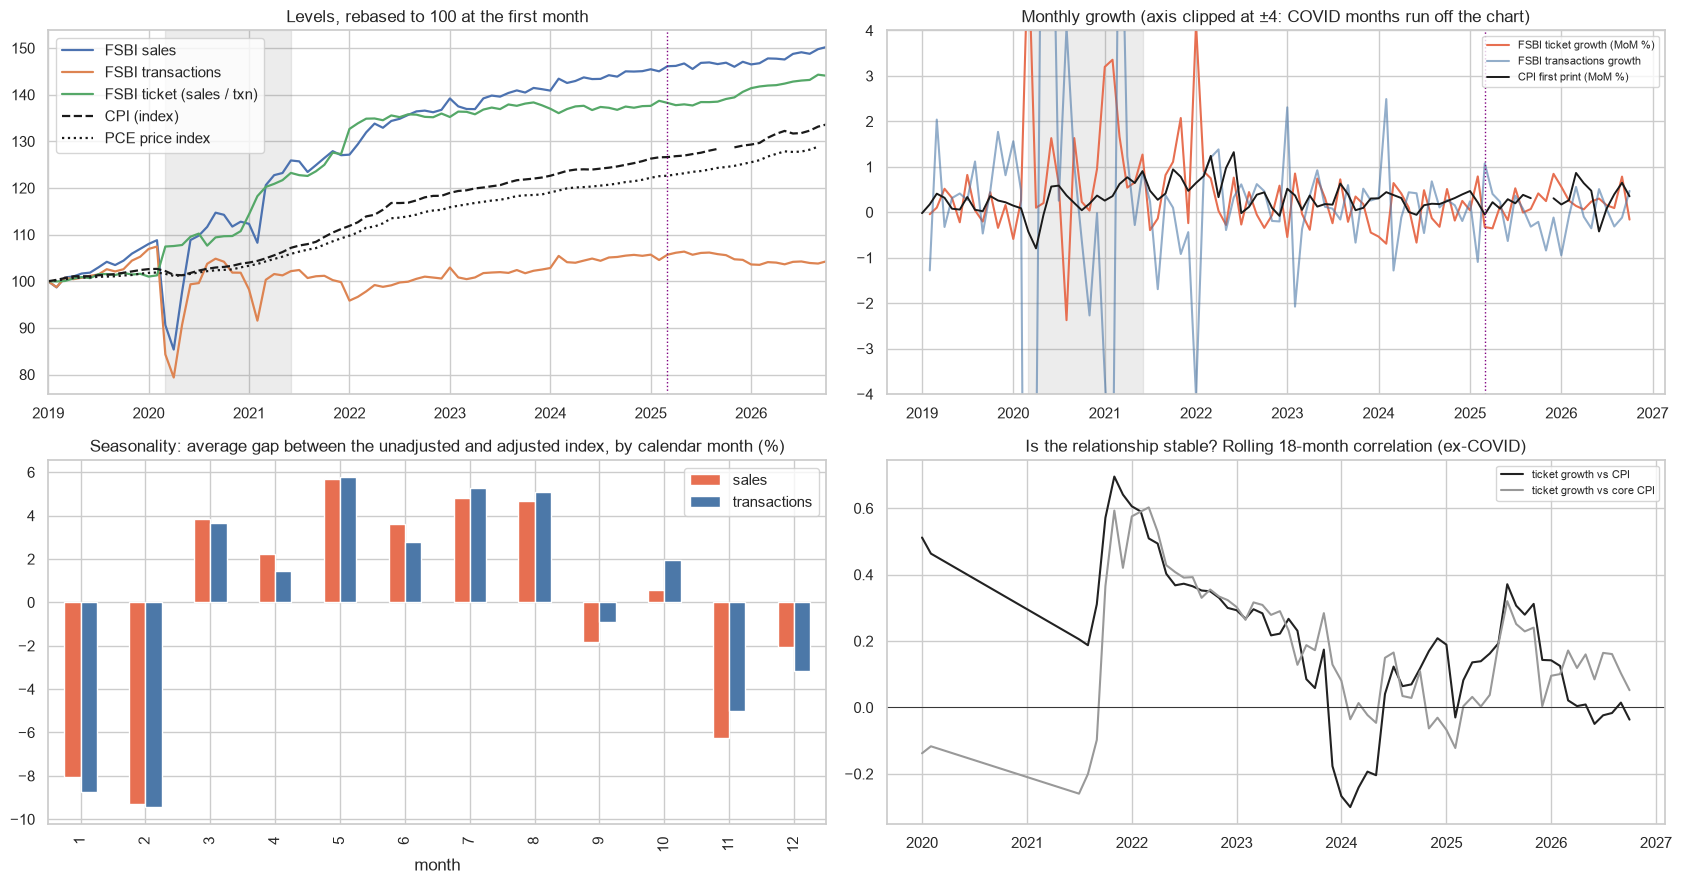

In [54]:
fig, axes = plt.subplots(2, 2, figsize=(17, 9))
ax = axes[0, 0]
lv = pd.DataFrame({"FSBI sales": FSBI["national"]["sales"]["US"], "FSBI transactions": FSBI["national"]["txn"]["US"], "FSBI ticket (sales / txn)": FSBI["national"]["ticket"]["US"],
                   "CPI (index)": LATEST["cpi"].reindex(IDX), "PCE price index": LATEST["pce"].reindex(IDX)})
(100 * lv / lv.iloc[0]).plot(ax=ax, lw=1.6, style=["-", "-", "-", "k--", "k:"]); ax.set_title("Levels, rebased to 100 at the first month"); ax.set_xlabel("")
ax = axes[0, 1]
ax.plot(IDX, g("national", "ticket")["US"], color="#e76f51", label="FSBI ticket growth (MoM %)"); ax.plot(IDX, g("national", "txn")["US"], color="#4c78a8", alpha=0.6, label="FSBI transactions growth")
ax.plot(IDX, Y["cpi"], "k-", lw=1.4, label="CPI first print (MoM %)"); ax.set_ylim(-4, 4); ax.set_title("Monthly growth (axis clipped at ±4: COVID months run off the chart)"); ax.legend(fontsize=8)
for a in axes[0]:
    a.axvspan(pd.Timestamp(COVID[0]), pd.Timestamp(COVID[1]), color="grey", alpha=0.15); a.axvline(HOLDOUT_START, color="purple", ls=":", lw=1)
ax = axes[1, 0]
seas = np.log(nat[["sales_nsa", "txn_nsa"]].values / nat[["sales", "txn"]].values) * 100
pd.DataFrame(seas, index=IDX, columns=["sales", "transactions"]).groupby(IDX.month).mean().plot.bar(ax=ax, color=["#e76f51", "#4c78a8"])
ax.set_title("Seasonality: average gap between the unadjusted and adjusted index, by calendar month (%)"); ax.set_xlabel("month")
ax = axes[1, 1]
for k, c in zip(("cpi", "core_cpi"), ("#222222", "#999999")):
    pair = pd.concat([g("national", "ticket")["US"], Y[k]], axis=1).loc[~in_covid(IDX)]
    ax.plot(pair.index, pair.iloc[:, 0].rolling(18, min_periods=12).corr(pair.iloc[:, 1]), color=c, label=f"ticket growth vs {LABEL[k]}")
ax.axhline(0, color="k", lw=0.6); ax.set_title("Is the relationship stable? Rolling 18-month correlation (ex-COVID)"); ax.legend(fontsize=8)
plt.tight_layout()

ex = ~in_covid(IDX)
desc = pd.DataFrame({"FSBI sales growth": g("national", "sales")["US"], "FSBI txn growth": g("national", "txn")["US"], "FSBI ticket growth": g("national", "ticket")["US"], **{f"{LABEL[k]} MoM": Y[k] for k in TARGETS}})
display(pd.concat({"all months": desc.describe().T[["mean", "std", "min", "max"]], "ex-COVID": desc[ex].describe().T[["mean", "std", "min", "max"]]}, axis=1).round(2))
print(f"Structural break: the sd of FSBI sales growth is {desc['FSBI sales growth'].std() / desc['FSBI sales growth'][ex].std():.1f}x larger with the COVID months included, "
      "which is why they are excluded from fitting and scoring (grey band). The purple line marks the holdout.")

### 2.2 Which FSBI series move with inflation, and at what lag?

Correlation of each FSBI feature in month *t−lag* with the target in month *t*, for two versions of the target: the **first print** (does FSBI track inflation?) and the **nowcast surprise**, print minus Cleveland nowcast (does FSBI know something the public nowcast does not?). Only the second matters for forecasting value. Lag 0 is usable in real time because FSBI for *t* is out before the print for *t*.

With this many correlations some are large by luck. The printed Bonferroni bar is the |r| needed after allowing for every cell in the figure.

416 correlations on about 54 months. Nominal 5% bar: |r| > 0.27 (87 cells pass; about 21 expected by chance). Bonferroni bar: |r| > 0.50 (4 pass).


,target,definition,feature,lag,r
0,CPI,print,tk_gas_stations,0,0.713
1,PCE,print,tk_gas_stations,0,0.606
2,PCE,print,nat_ticket_3m,0,0.524
3,CPI,print,nat_ticket_3m,0,0.510
4,CPI,print,reg_sales_dispersion,1,0.471
5,CPI,print,state_ticket_dispersion,1,0.434
6,PCE,surprise,demand_pull,0,0.430
7,PCE,print,state_ticket_dispersion,1,0.424
8,CPI,print,tk_restaurants,1,0.417
9,CPI,print,nat_ticket_3m,1,0.414


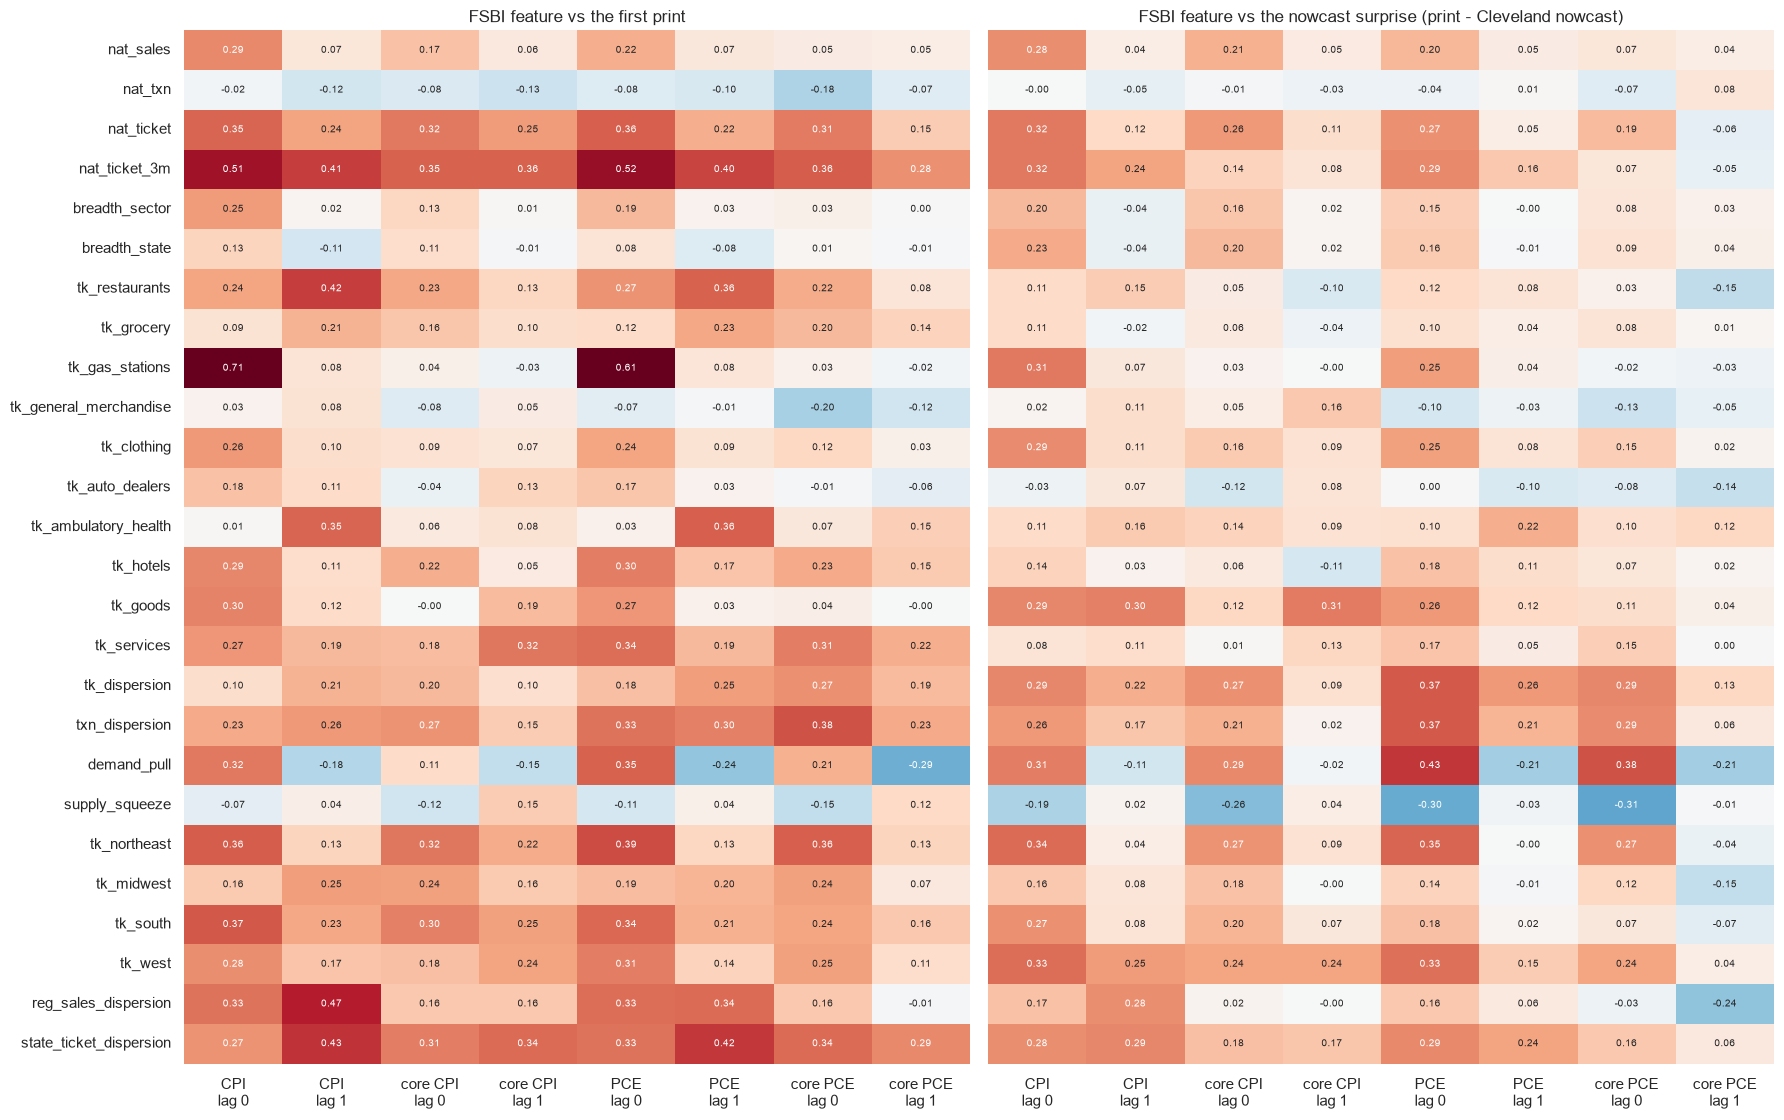

In [55]:
X_FSBI = pd.concat([F[b] for b in FSBI_BLOCKS], axis=1)
dev = ~in_covid(IDX) & (IDX < EVAL_END)
def lag_corr(X, y, lags=(0, 1)):
    return pd.DataFrame({l: {c: X[c].shift(l)[dev].corr(y[dev]) for c in X} for l in lags})
cc = {(LABEL[k], kind): lag_corr(X_FSBI, yy) for k in TARGETS for kind, yy in (("print", Y[k]), ("surprise", Y[k] - NC[k]))}
n_eff = int((X_FSBI.notna().all(axis=1) & Y.notna().all(axis=1) & dev).sum()); n_cells = sum(v.size for v in cc.values())
r_crit = lambda a: (lambda t: t / np.sqrt(n_eff - 2 + t ** 2))(stats.t.ppf(1 - a / 2, n_eff - 2))
fig, axes = plt.subplots(1, 2, figsize=(18, 0.36 * X_FSBI.shape[1] + 2), sharey=True)
for ax, kind in zip(axes, ("print", "surprise")):
    M = pd.concat({f"{t}\nlag {l}": cc[(t, kind)][l] for t in LABEL.values() for l in (0, 1)}, axis=1)
    sns.heatmap(M, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, cbar=False, ax=ax, annot_kws={"size": 7})
    ax.set_title(f"FSBI feature vs the {'first print' if kind == 'print' else 'nowcast surprise (print - Cleveland nowcast)'}")
plt.tight_layout()
flat = pd.concat({key: v.stack() for key, v in cc.items()}).dropna()
print(f"{n_cells} correlations on about {n_eff} months. Nominal 5% bar: |r| > {r_crit(0.05):.2f} ({int((flat.abs() > r_crit(0.05)).sum())} cells pass; about {0.05 * n_cells:.0f} expected by chance). "
      f"Bonferroni bar: |r| > {r_crit(0.05 / n_cells):.2f} ({int((flat.abs() > r_crit(0.05 / n_cells)).sum())} pass).")
display(flat.reindex(flat.abs().sort_values(ascending=False).index).head(10).rename("r").rename_axis(["target", "definition", "feature", "lag"]).reset_index().round(3))

### 2.3 Granularity: sector tickets vs CPI components, regions vs regional CPI

FSBI's distinctive feature is its breakdown. If a sector's **ticket** (price per purchase) is a price signal, it should co-move with the CPI component for the same goods: restaurant ticket with *food away from home*, gas-station ticket with *gasoline*, and so on (pairs are listed in section 1.1). The same check is run by geography: each Census region's FSBI against that region's own CPI. Section 3.5 turns these pairs into out-of-sample forecasts.

12 of 14 matched pairs have a positive same-month ticket correlation (half expected if unrelated); 2 clear the nominal 5% bar.


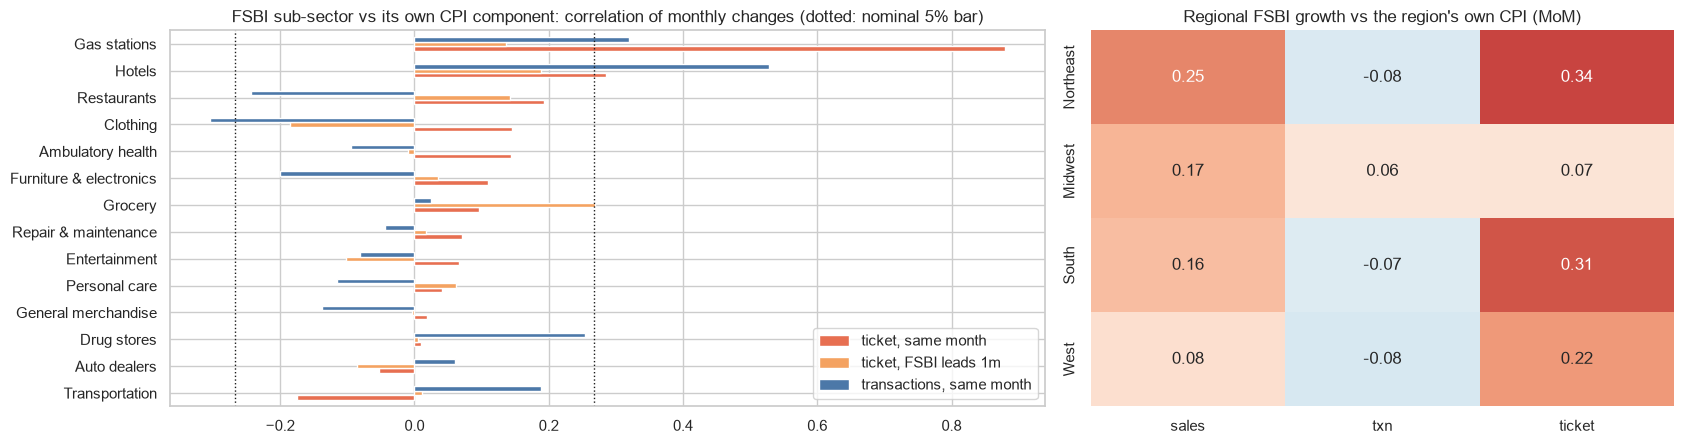

In [56]:
COMP = {}                                                                         # CPI component MoM %, by FSBI entity
for e, sid in ENTITY.cpi_component.dropna().items():
    s = fred_try(sid)
    if s is not None:
        COMP[e] = (s.pct_change(fill_method=None) * 100).reindex(IDX)
pairs = pd.DataFrame({e: {"CPI component": ENTITY.at[e, "cpi_component"], "ticket, same month": tk[e][dev].corr(y[dev]), "ticket, FSBI leads 1m": tk[e].shift(1)[dev].corr(y[dev]),
                          "transactions, same month": tx[e][dev].corr(y[dev])} for e, y in COMP.items()}).T

REG_ID = {"Northeast": "CUUR0100SA0", "Midwest": "CUUR0200SA0", "South": "CUUR0300SA0", "West": "CUUR0400SA0"}
nsa_us, REG_CPI = fred_try("CPIAUCNS"), {}
seas_gap = (np.log(nsa_us).diff() - np.log(LATEST["cpi"]).diff()) * 100 if nsa_us is not None else 0.0     # national seasonal factor, used to adjust regional CPI
for r, sid in REG_ID.items():
    s = fred_try(sid)
    if s is not None:
        REG_CPI[r] = (np.log(s).diff() * 100 - seas_gap).reindex(IDX)
REG_CPI = pd.DataFrame(REG_CPI)
reg_tab = pd.DataFrame({r: {m: g("region", m)[r][dev].corr(REG_CPI[r][dev]) for m in ("sales", "txn", "ticket")} for r in REG_CPI}).T

fig, axes = plt.subplots(1, 2, figsize=(17, 4.6), gridspec_kw={"width_ratios": [1.5, 1]})
if len(pairs):
    pairs[["ticket, same month", "ticket, FSBI leads 1m", "transactions, same month"]].astype(float).sort_values("ticket, same month").plot.barh(ax=axes[0], color=["#e76f51", "#f4a261", "#4c78a8"])
    axes[0].axvline(r_crit(0.05), color="k", ls=":", lw=1); axes[0].axvline(-r_crit(0.05), color="k", ls=":", lw=1)
    axes[0].set_title("FSBI sub-sector vs its own CPI component: correlation of monthly changes (dotted: nominal 5% bar)")
if len(reg_tab):
    sns.heatmap(reg_tab.astype(float), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-0.5, vmax=0.5, cbar=False, ax=axes[1]); axes[1].set_title("Regional FSBI growth vs the region's own CPI (MoM)")
plt.tight_layout()
if len(pairs):
    print(f"{int((pairs['ticket, same month'].astype(float) > 0).sum())} of {len(pairs)} matched pairs have a positive same-month ticket correlation (half expected if unrelated); "
          f"{int((pairs['ticket, same month'].astype(float).abs() > r_crit(0.05)).sum())} clear the nominal 5% bar.")

### 2.4 A leakage trap: the nominal ÷ real "implied deflator"

Earlier teams found that nominal FSBI sales divided by *real* FSBI sales reproduces CPI almost exactly. That is because Fiserv deflates with CPI: in a historical file the same-month ratio already contains the answer, and at release time the latest month's deflator can only be an estimate. This cell runs the check when the real-sales file is present. The ratio is **not** used as a feature anywhere in this notebook; price information comes only from the ticket, which is built from nominal data.

In [57]:
real_path = next((p for p in [DATA_DIR / "FSBI_data.csv", *DATA_DIR.glob("*Inflation Adjusted*.csv")] if p.exists() and "Non Inflation" not in p.name), None)
if real_path is None:
    print("No real-sales FSBI file found (optional): diagnostic skipped.")
else:
    rr = load_fsbi(real_path); rr = rr[(rr.geo == "US") & (rr.sector == "ALL") & (rr.subsector == "ALL")].set_index("date").sales.reindex(IDX)
    implied = np.log(FSBI["national"]["sales"]["US"] / rr).diff() * 100
    cpi_now = (np.log(LATEST["cpi"]).diff() * 100).reindex(IDX)
    print(f"Implied deflator (nominal / real sales) vs CPI, monthly changes, {int(implied.notna().sum())} months: same month r = {implied.corr(cpi_now):+.2f}; "
          f"deflator vs NEXT month's CPI r = {implied.shift(1).corr(cpi_now):+.2f}; CPI's own autocorrelation r = {cpi_now.corr(cpi_now.shift(1)):+.2f}.")
    print("Reading: a same-month correlation near 1 means the ratio is CPI itself (leakage if used as a same-month feature); "
          "lagged one month it carries no more than CPI's own persistence, which the 'own' block already provides.")

Implied deflator (nominal / real sales) vs CPI, monthly changes, 93 months: same month r = +0.84; deflator vs NEXT month's CPI r = +0.40; CPI's own autocorrelation r = +0.51.
Reading: a same-month correlation near 1 means the ratio is CPI itself (leakage if used as a same-month feature); lagged one month it carries no more than CPI's own persistence, which the 'own' block already provides.


## 3. Forecasting

### 3.1 One engine for every experiment

**Design.** `design(target, blocks, anchor)` builds one table per experiment. The model predicts `y = first print − anchor` and the forecast is `anchor + prediction`:

| anchor | the model has to explain | question answered |
|---|---|---|
| `none` | inflation itself | is FSBI a leading indicator on its own? (reference: AR model) |
| `nowcast` | what the Cleveland nowcast misses | does FSBI add to the best free public forecast? (main case) |
| `kalshi` | what the prediction market misses | does FSBI add to what is priced? (short sample) |

**Protocol.** Expanding-window walk-forward: for each month after the first `MIN_TRAIN`, fit on earlier months only, predict that month. Every comparison uses identical rows. Hyperparameters are tuned *inside* the training window with `TimeSeriesSplit` (re-tuned every six steps for the tree models to keep the runtime reasonable).

**Models** (the capstone's list, sized for about fifty monthly observations):

| family | models | tuning |
|---|---|---|
| Baselines | anchor alone; AR on own lags | – |
| Linear | OLS on the four best-screened inputs; Ridge; Lasso; principal-component regression | Ridge α by leave-one-out; Lasso α by time-series CV; screening inside each fit |
| Time series | ARIMAX(1,0,0) with the three exogenous inputs most correlated in the training window | – |
| Ensembles | random forest; gradient boosting (XGBoost when installed) | grid over depth / leaf size / learning rate, `TimeSeriesSplit(3)` |
| Neural | small MLP (one hidden layer, strong L2 penalty) | fixed |
| Combination | mean of all models | – |

An LSTM is left out on purpose: with roughly fifty usable monthly observations a recurrent network has far more parameters than data points, and the MLP row already shows what a neural model does at this sample size.

**Scores.** RMSE and MAE in percentage points of MoM inflation; out-of-sample **R²** = 1 − SSE/SST; RMSE relative to the reference; a Diebold–Mariano p-value against the reference (and Clark–West where the models are nested); directional accuracy (did inflation rise or fall versus the previous print?). MAPE is not reported because MoM inflation is often near zero, where percentage errors are meaningless.

A note on R². It is the standard 1 − SSE/SST, computed on out-of-sample forecasts with SST taken around the mean of the prints over the same months. It is **not bounded below by zero**: a negative value means the forecast was less accurate than a constant equal to that mean, which is common out of sample for a series as noisy as MoM inflation and is information, not an error. Whether a model beats the *nowcast* is read from the RMSE ratio and its test.

**Two tests.** Diebold–Mariano (DM) compares any two forecasts. When one model *contains* the other (with FSBI vs without), DM is biased against the larger model, so those comparisons also report the Clark–West (CW) test, which is the appropriate one for nested models and is one-sided (does the extra block help?).

In [58]:
from sklearn.pipeline import Pipeline
ALL_BLOCKS = ["own", "mac", "nat", "sec", "reg", "kal"]
OPTIONAL = {"kal_gap"}                                       # may be missing; imputed inside each training window

def design(k, blocks, anchor="nowcast", end=EVAL_END, labelled=True):
    base = NC[k] if anchor == "nowcast" else KAL[k] if anchor == "kalshi" else pd.Series(0.0, index=IDX)
    tbl = pd.DataFrame({"y": Y[k] - base, "base": base, "actual": Y[k]}).join(pd.concat([block(k, b) for b in blocks], axis=1))
    tbl = tbl.loc[~in_covid(IDX) & (IDX < end)]
    need = [c for c in tbl.columns if c not in OPTIONAL and (labelled or c not in ("y", "actual"))]
    return tbl.dropna(subset=need)
feats = lambda tbl: [c for c in tbl.columns if c not in ("y", "base", "actual")]
_rows_cache = {}
def rows_all(k):
    """Every labelled month (design and live period): the zoo and the online selection run through the newest print."""
    return design(k, ALL_BLOCKS, end=FAR).index
def rows(k, anchor="nowcast"):
    """The months on which every feature set is complete, so all experiments for a target share one sample."""
    if (k, anchor) not in _rows_cache:
        _rows_cache[(k, anchor)] = design(k, ALL_BLOCKS, anchor).index
    return _rows_cache[(k, anchor)]

def _pipe(est, *pre):
    return Pipeline([("imp", SimpleImputer(strategy="median", keep_empty_features=True)), ("sc", StandardScaler()), *[(f"p{i}", p) for i, p in enumerate(pre)], ("est", est)])
def m_fixed(make, *pre):
    """A model with fixed (or internally cross-validated) settings."""
    def factory(cols):
        return lambda tr, te: float(_pipe(make(), *[p(len(cols)) for p in pre]).fit(tr[cols], tr.y).predict(te[cols])[0])
    return factory
TUNED = {}
def m_tuned(name, make, grid, every=6):
    """A model whose hyperparameters are re-chosen every `every` steps by time-series CV inside the training window."""
    def factory(cols):
        state = {"n": 0, "best": None}
        def f(tr, te):
            if state["best"] is None or state["n"] % every == 0:
                gs = GridSearchCV(_pipe(make()), {f"est__{p}": v for p, v in grid.items()}, cv=TimeSeriesSplit(3), scoring="neg_mean_squared_error").fit(tr[cols], tr.y)
                state["best"] = {p.replace("est__", ""): v for p, v in gs.best_params_.items()}; TUNED.setdefault(name, []).append(state["best"])
            state["n"] += 1
            return float(_pipe(make().set_params(**state["best"])).fit(tr[cols], tr.y).predict(te[cols])[0])
        return f
    return factory
def m_arimax(cols, n_exog=3):
    def f(tr, te):
        ex = tr[cols].corrwith(tr.y).abs().dropna().sort_values(ascending=False).index[:n_exog].tolist()
        mu, sd = tr[ex].mean(), tr[ex].std().replace(0, 1)
        try:
            grid = pd.date_range(tr.index[0], te.index[0] - pd.DateOffset(months=1), freq="MS")      # excluded months become missing observations (the Kalman filter skips them)
            fit = SARIMAX(tr.y.reindex(grid).values, exog=((tr[ex] - mu) / sd).reindex(grid).fillna(0).values, order=(1, 0, 0), trend="c").fit(disp=False, maxiter=60)
            return float(fit.forecast(1, exog=((te[ex] - mu) / sd).fillna(0).values)[0])
        except Exception:
            return float(tr.y.mean())
    return f
def m_ar(cols):
    own = [c for c in cols if c in ("y_l1", "y_l2")]
    return (lambda tr, te: float(LinearRegression().fit(tr[own], tr.y).predict(te[own])[0])) if own else (lambda tr, te: float(tr.y.mean()))

N_TREES = 40 if FAST else 150
rf  = lambda: RandomForestRegressor(n_estimators=N_TREES, min_samples_leaf=3, max_features=0.4, random_state=SEED, n_jobs=1)
gbm = (lambda: XGBRegressor(n_estimators=N_TREES, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED, n_jobs=1)) if HAVE_XGB else \
      (lambda: GradientBoostingRegressor(n_estimators=N_TREES, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED))
# name: (estimator factory, extra preprocessing steps, tuning grid or None). The zoo and the importance analysis (3.7) are both built from this table.
SPEC = {
    "OLS (top-4 screened)": (LinearRegression, [lambda p: SelectKBest(f_regression, k=min(4, p))], None),
    "Ridge":                (lambda: RidgeCV(alphas=np.logspace(-1, 4, 30)), [], None),
    "Lasso":                (lambda: LassoCV(cv=TimeSeriesSplit(3), alphas=np.logspace(-3.5, 0, 30), max_iter=20000), [], None),
    "PCR (3 components)":   (LinearRegression, [lambda p: PCA(n_components=min(3, p))], None),
    "Random forest":        (rf, [], {"max_features": [0.3, 0.6], "min_samples_leaf": [2, 5]}),
    "Gradient boosting":    (gbm, [], {"max_depth": [1, 2], "learning_rate": [0.03, 0.1]}),
    "Neural net (MLP)":     (lambda: MLPRegressor(hidden_layer_sizes=(8,), alpha=5.0, solver="lbfgs", max_iter=2000, random_state=SEED), [], None),
}
ZOO = {"AR (own lags)": m_ar, "ARIMAX(1,0,0)": m_arimax, **{n: (m_tuned(n, mk, grid) if grid else m_fixed(mk, *pre)) for n, (mk, pre, grid) in SPEC.items()}}
LEAN = {"Ridge": ZOO["Ridge"], "Lasso": ZOO["Lasso"], "Random forest": m_fixed(rf)}        # fast, untuned-forest trio for the many-experiment sections

def walk_forward(tbl, models, min_train=MIN_TRAIN):
    """Expanding window: one forecast per month after the first `min_train`, each from a model fitted on earlier months only."""
    cols = feats(tbl); fns = {name: fac(cols) for name, fac in models.items()}; out = {}
    for i in range(min_train, len(tbl)):
        tr, te = tbl.iloc[:i], tbl.iloc[i:i + 1]; b = float(te.base.iloc[0])
        out[tbl.index[i]] = {"actual": float(te.actual.iloc[0]), "Anchor": b, **{name: b + fn(tr, te) for name, fn in fns.items()}}
    return pd.DataFrame(out).T

def r2(actual, fc):
    """Out-of-sample R-squared: 1 - SSE / SST, with SST around the mean of the actuals over the same months.
    1 is perfect, 0 is no better than predicting that mean, negative is worse than it."""
    d = pd.concat([pd.Series(actual, dtype=float), pd.Series(fc, dtype=float)], axis=1).dropna()
    sst = ((d.iloc[:, 0] - d.iloc[:, 0].mean()) ** 2).sum()
    return float(1 - ((d.iloc[:, 0] - d.iloc[:, 1]) ** 2).sum() / sst) if len(d) >= 3 and sst > 0 else np.nan

def score(f, k, ref="Anchor"):
    prev = Y[k].shift(1).reindex(f.index); e0 = f.actual - f[ref]; out = {}
    for m in f.columns.drop("actual"):
        e = f.actual - f[m]
        out[m] = {"RMSE": rmse(e), "MAE": mae(e), "R2": r2(f.actual, f[m]), f"RMSE / {ref}": rmse(e) / rmse(e0),
                  f"DM p vs {ref}": np.nan if m == ref else dm_p(e, e0), "direction hit": float((np.sign(f[m] - prev) == np.sign(f.actual - prev)).mean())}
    return pd.DataFrame(out).T
print({LABEL[k]: f"{len(rows(k))} months, {len(rows(k)) - MIN_TRAIN} out-of-sample ({rows(k)[MIN_TRAIN]:%Y-%m} to {rows(k)[-1]:%Y-%m})" for k in TARGETS})

{'CPI': '54 months, 30 out-of-sample (2022-09 to 2025-02)', 'core CPI': '54 months, 30 out-of-sample (2022-09 to 2025-02)', 'PCE': '54 months, 30 out-of-sample (2022-09 to 2025-02)', 'core PCE': '54 months, 30 out-of-sample (2022-09 to 2025-02)'}


### 3.2 Feature-set ladder: what does each block add?

The central test for Fiserv. Starting from the target's own lags, blocks are added one at a time (macro, then FSBI national, sector, region, then Kalshi), plus two cuts that isolate FSBI: **FSBI only**, and the **full set without FSBI**. Three different model types run on each set, because a conclusion only one model supports is a property of that model. All on identical months, anchored on the nowcast.

Read the heatmap as RMSE relative to the nowcast (below 1, green, beats it). Read the table underneath as the answer to *"what happens if FSBI is removed from the full model?"* (positive % = FSBI was helping).

RMSE full  RMSE without FSBI  RMSE change when FSBI is removed (%)   DM p   CW p
target   model                                                                                          
CPI      Ridge              0.152              0.152                                 0.360  0.952  0.162
         Lasso              0.156              0.132                               -15.246  0.040  0.622
         Random forest      0.145              0.147                                 1.294  0.786  0.185
core CPI Ridge              0.130              0.130                                 0.160  0.837  0.035
         Lasso              0.128              0.126                                -1.424  0.398  0.582
         Random forest      0.126              0.130                                 2.816  0.340  0.077
PCE      Ridge              0.140              0.129                                -7.946  0.298  0.296
         Lasso              0.155              0.145                                -6.448  0.602  0.030
         Random forest      0.136              0.138                                 1.520  0.536  0.059
core PCE Ridge              0.133              0.127                                -4.717  0.531  0.465
         Lasso              0.142              0.130                                -8.888  0.532  0.332
         Random forest      0.128              0.128                                 0.094  0.973  0.213

FSBI helped (removing it raised RMSE) in 6 of 12 target x model cells; 3 of those at Clark-West p < 0.10 (4 cells pass CW overall). Mean change -3.2%.  (281s)


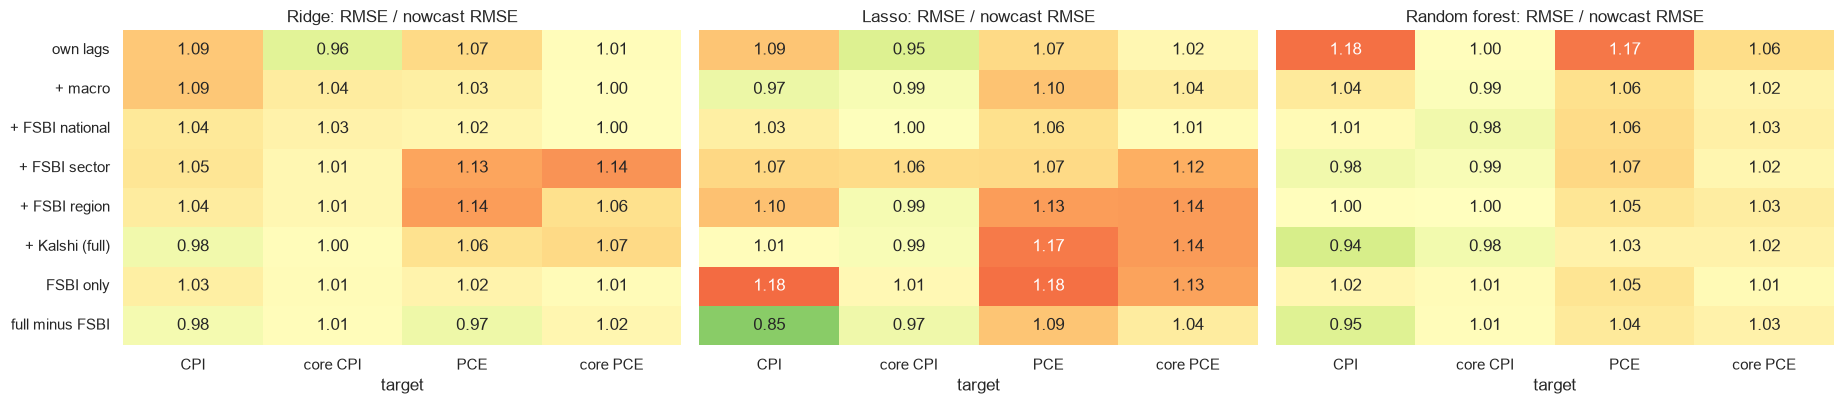

In [59]:
SETS = {"own lags": ["own"], "+ macro": ["own", "mac"], "+ FSBI national": ["own", "mac", "nat"], "+ FSBI sector": ["own", "mac", "nat", "sec"],
        "+ FSBI region": ["own", "mac", "nat", "sec", "reg"], "+ Kalshi (full)": ALL_BLOCKS, "FSBI only": FSBI_BLOCKS, "full minus FSBI": ["own", "mac", "kal"]}
t0 = time.time(); LAD_F, lad = {}, []
for k in TARGETS:
    for sname, blocks in SETS.items():
        f = walk_forward(design(k, blocks).loc[rows(k)], LEAN); LAD_F[(k, sname)] = f
        for m in LEAN:
            lad.append({"target": LABEL[k], "set": sname, "model": m, "n features": len(feats(design(k, blocks))), "RMSE": rmse(f.actual - f[m]), "ratio": rmse(f.actual - f[m]) / rmse(f.actual - f.Anchor)})
LAD = pd.DataFrame(lad)
fig, axes = plt.subplots(1, len(LEAN), figsize=(6.2 * len(LEAN), 4.2), sharey=True)
for ax, m in zip(axes, LEAN):
    M = LAD[LAD.model == m].pivot(index="set", columns="target", values="ratio").reindex(index=list(SETS), columns=list(LABEL.values()))
    sns.heatmap(M, annot=True, fmt=".2f", cmap="RdYlGn_r", center=1.0, vmin=0.7, vmax=1.3, cbar=False, ax=ax); ax.set_title(f"{m}: RMSE / nowcast RMSE"); ax.set_ylabel("")
plt.tight_layout()
abl = []
for k in TARGETS:
    full, no = LAD_F[(k, "+ Kalshi (full)")], LAD_F[(k, "full minus FSBI")]
    for m in LEAN:
        e1, e0 = full.actual - full[m], no.actual - no[m]
        abl.append({"target": LABEL[k], "model": m, "RMSE full": rmse(e1), "RMSE without FSBI": rmse(e0), "RMSE change when FSBI is removed (%)": 100 * (rmse(e0) / rmse(e1) - 1), "DM p": dm_p(e1, e0), "CW p": cw_p(e1, e0)})
ABLATION = pd.DataFrame(abl).set_index(["target", "model"])
display(ABLATION.round(3))
print(f"FSBI helped (removing it raised RMSE) in {int((ABLATION.iloc[:, 2] > 0).sum())} of {len(ABLATION)} target x model cells; "
      f"{int(((ABLATION.iloc[:, 2] > 0) & (ABLATION['CW p'] < 0.10)).sum())} of those at Clark-West p < 0.10 ({int((ABLATION['CW p'] < 0.10).sum())} cells pass CW overall). Mean change {ABLATION.iloc[:, 2].mean():+.1f}%.  ({time.time() - t0:.0f}s)")

### 3.3 Model zoo on the full feature set

The zoo runs through the newest published print (so the dashboard's forecast history is current), but the score table below covers the design period only; the live months are reported separately.

Every model family from the capstone brief on the full set, anchored on the nowcast, with tuning inside each training window. The same zoo is run a second time **without the FSBI blocks**; section 4 uses that twin to measure how much of any trading result is due to FSBI rather than to modelling.

  CPI done (101s)
  core CPI done (210s)
  PCE done (312s)
  core PCE done (409s)


RMSE    MAE     R2  RMSE / Anchor  DM p vs Anchor  direction hit
CPI      Anchor                0.155  0.120  0.191          1.000             NaN          0.700
         AR (own lags)         0.166  0.126  0.077          1.068           0.314          0.600
         ARIMAX(1,0,0)         0.157  0.123  0.171          1.012           0.902          0.800
         OLS (top-4 screened)  0.166  0.131  0.075          1.069           0.444          0.733
         Ridge                 0.152  0.118  0.225          0.979           0.846          0.767
         Lasso                 0.156  0.122  0.179          1.007           0.953          0.767
         PCR (3 components)    0.156  0.124  0.181          1.006           0.954          0.733
         Random forest         0.145  0.115  0.294          0.934           0.382          0.767
         Gradient boosting     0.136  0.108  0.374          0.879           0.284          0.767
         Neural net (MLP)      0.156  0.122  0.176          1.009           0.920          0.767
         Model average         0.145  0.113  0.291          0.936           0.488          0.767
core CPI Anchor                0.129  0.095 -0.434          1.000             NaN          0.733
         AR (own lags)         0.122  0.092 -0.291          0.949           0.399          0.767
         ARIMAX(1,0,0)         0.129  0.098 -0.427          0.998           0.965          0.667
         OLS (top-4 screened)  0.137  0.107 -0.616          1.062           0.079          0.567
         Ridge                 0.130  0.095 -0.448          1.005           0.912          0.733
         Lasso                 0.128  0.090 -0.403          0.989           0.840          0.733
         PCR (3 components)    0.127  0.097 -0.389          0.984           0.726          0.700
         Random forest         0.127  0.091 -0.388          0.984           0.665          0.700
         Gradient boosting     0.125  0.093 -0.353          0.971           0.622          0.733
         Neural net (MLP)      0.129  0.094 -0.431          0.999           0.981          0.733
         Model average         0.125  0.091 -0.350          0.970           0.470          0.733
PCE      Anchor                0.133  0.113  0.144          1.000             NaN          0.700
         AR (own lags)         0.145  0.119 -0.026          1.095           0.036          0.700
         ARIMAX(1,0,0)         0.154  0.118 -0.152          1.160           0.026          0.700
         OLS (top-4 screened)  0.149  0.115 -0.074          1.120           0.041          0.700
         Ridge                 0.140  0.099  0.045          1.056           0.589          0.767
         Lasso                 0.155  0.114 -0.166          1.167           0.172          0.900
         PCR (3 components)    0.133  0.109  0.135          1.005           0.929          0.767
         Random forest         0.140  0.109  0.052          1.053           0.338          0.767
         Gradient boosting     0.140  0.106  0.047          1.055           0.493          0.733
         Neural net (MLP)      0.135  0.108  0.115          1.017           0.721          0.733
         Model average         0.133  0.101  0.140          1.003           0.949          0.767
core PCE Anchor                0.125  0.105 -0.236          1.000             NaN          0.600
         AR (own lags)         0.129  0.109 -0.316          1.032           0.389          0.633
         ARIMAX(1,0,0)         0.141  0.108 -0.584          1.132           0.257          0.700
         OLS (top-4 screened)  0.137  0.105 -0.487          1.097           0.326          0.667
         Ridge                 0.133  0.106 -0.410          1.068           0.465          0.633
         Lasso                 0.142  0.111 -0.601          1.138           0.399          0.667
         PCR (3 components)    0.127  0.106 -0.277          1.016           0.559          0.633
         Random forest         0.129  0.106 -0.327     

Live track record since March 2025 (16 months, same models, not used for any choice):


RMSE                              R2                          RMSE / Anchor                         
                        CPI core CPI    PCE core PCE    CPI core CPI    PCE core PCE           CPI core CPI    PCE core PCE
Anchor                0.116    0.109  0.080    0.086  0.842   -0.140  0.814    0.015         1.000    1.000  1.000    1.000
AR (own lags)         0.120    0.098  0.081    0.087  0.832    0.069  0.806   -0.009         1.031    0.904  1.019    1.012
ARIMAX(1,0,0)         0.102    0.096  0.121    0.131  0.878    0.117  0.575   -1.310         0.877    0.880  1.510    1.531
OLS (top-4 screened)  0.104    0.101  0.119    0.114  0.873    0.015  0.588   -0.746         0.895    0.930  1.486    1.331
Ridge                 0.115    0.110  0.079    0.088  0.846   -0.162  0.817   -0.032         0.986    1.010  0.992    1.023
Lasso                 0.107    0.100  0.082    0.089  0.866    0.031  0.806   -0.065         0.920    0.922  1.020    1.039
PCR (3 components)    0.119    0.107  0.078    0.084  0.835   -0.106  0.822    0.053         1.022    0.985  0.978    0.980
Random forest         0.090    0.109  0.068    0.087  0.905   -0.142  0.865   -0.010         0.773    1.001  0.851    1.012
Gradient boosting     0.092    0.106  0.069    0.091  0.901   -0.089  0.862   -0.119         0.790    0.977  0.862    1.066
Neural net (MLP)      0.113    0.109  0.077    0.085  0.850   -0.148  0.829    0.022         0.972    1.004  0.958    0.996
Model average         0.103    0.100  0.079    0.090  0.876    0.033  0.819   -0.088         0.884    0.921  0.986    1.051

Most frequently chosen hyperparameters: {'Random forest': '{"max_features": 0.3, "min_samples_leaf": 5}', 'Gradient boosting': '{"learning_rate": 0.03, "max_depth": 1}'}


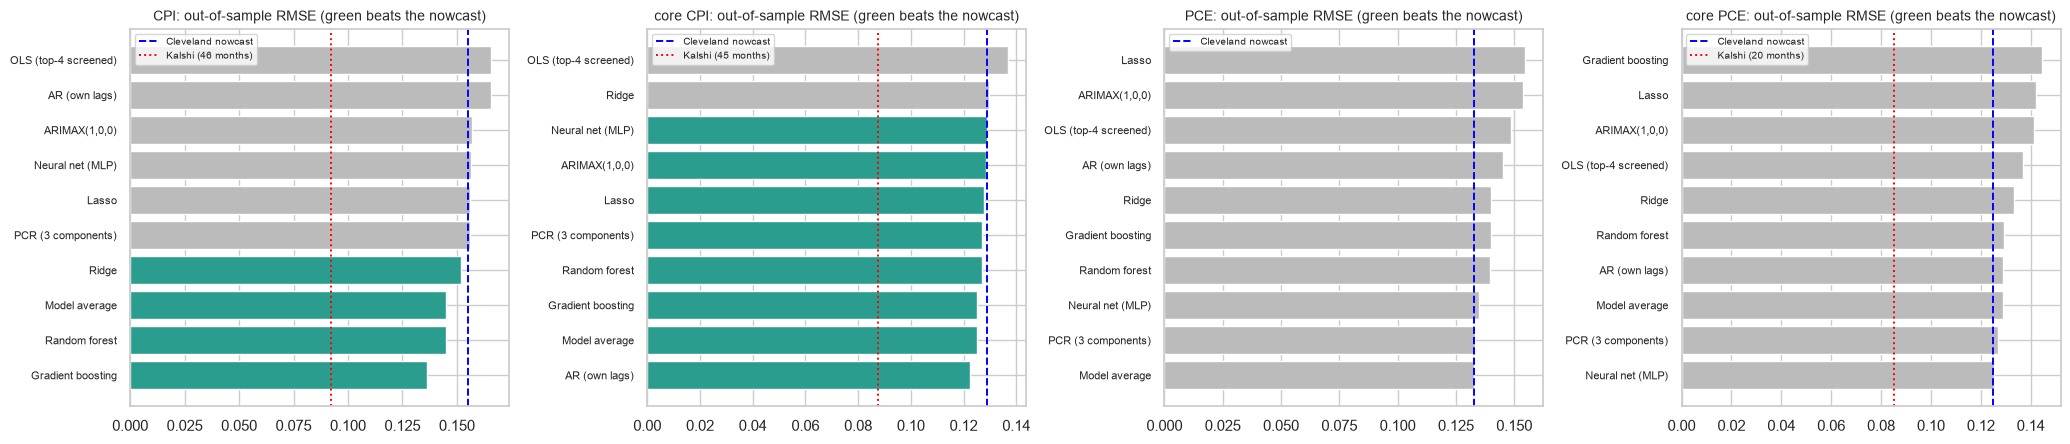

In [60]:
t0 = time.time(); OOS, OOS_NOFSBI = {}, {}
for k in TARGETS:
    for store, blocks in ((OOS, ALL_BLOCKS), (OOS_NOFSBI, ["own", "mac", "kal"])):
        f = walk_forward(design(k, blocks, end=FAR).loc[rows_all(k)], ZOO)
        f["Model average"] = f[list(ZOO)].mean(axis=1)
        if k in KAL_KINDS:
            f["Kalshi"] = KAL[k].reindex(f.index)
        store[k] = f
    print(f"  {LABEL[k]} done ({time.time() - t0:.0f}s)")
MODEL_NAMES = list(ZOO) + ["Model average"]
ZOO_TAB = pd.concat({LABEL[k]: score(pre(OOS[k]).drop(columns="Kalshi", errors="ignore"), k) for k in TARGETS})       # design period
_live = {k: OOS[k][OOS[k].index >= EVAL_END] for k in TARGETS}
ZOO_LIVE = pd.concat({LABEL[k]: score(_live[k].drop(columns="Kalshi", errors="ignore"), k) for k in TARGETS if len(_live[k]) >= 3}) if any(len(v) >= 3 for v in _live.values()) else pd.DataFrame()
fig, axes = plt.subplots(1, 4, figsize=(21, 4.6))
for ax, k in zip(axes, TARGETS):
    s = ZOO_TAB.loc[LABEL[k]]["RMSE"].drop("Anchor").sort_values(); base = ZOO_TAB.loc[(LABEL[k], "Anchor"), "RMSE"]
    ax.barh(s.index, s.values, color=["#2a9d8f" if v < base else "#bbbbbb" for v in s.values]); ax.axvline(base, color="blue", ls="--", lw=1.4, label="Cleveland nowcast")
    if "Kalshi" in OOS[k] and OOS[k]["Kalshi"].notna().sum() > 5:
        kk = OOS[k].dropna(subset=["Kalshi"]); ax.axvline(rmse(kk.actual - kk.Kalshi), color="red", ls=":", lw=1.4, label=f"Kalshi ({len(kk)} months)")
    ax.set_title(f"{LABEL[k]}: out-of-sample RMSE (green beats the nowcast)", fontsize=10); ax.legend(fontsize=7); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
display(ZOO_TAB.round(3))
if len(ZOO_LIVE):
    print(f"Live track record since {EVAL_END:%B %Y} ({len(_live[TARGETS[0]])} months, same models, not used for any choice):"); display(ZOO_LIVE[["RMSE", "R2", "RMSE / Anchor"]].unstack(0).round(3))
if TUNED:
    print("Most frequently chosen hyperparameters:", {m: pd.Series([json.dumps(p, sort_keys=True) for p in v]).mode().iloc[0] for m, v in TUNED.items()})

### 3.4 Three anchors: FSBI alone, beyond the nowcast, beyond the market

The same with/without-FSBI comparison under each anchor. Under `none` the reference is an AR model, so this row answers the brief's first goal directly (*is FSBI a good leading predictor?*). Under `kalshi` the sample is short (the ladders only exist from late 2022), so training starts from 12 months and the result should be read as a direction, not a verdict.

In [61]:
anc = []
for anchor in ("none", "nowcast", "kalshi"):
    for k in (KAL_KINDS if anchor == "kalshi" else TARGETS):
        mt = 12 if anchor == "kalshi" else MIN_TRAIN
        base_blocks = ["own", "mac"]; r_ = design(k, base_blocks + FSBI_BLOCKS, anchor).index
        if len(r_) < mt + 8:
            continue
        f0, f1 = walk_forward(design(k, base_blocks, anchor).loc[r_], {**LEAN, "AR": m_ar}, mt), walk_forward(design(k, base_blocks + FSBI_BLOCKS, anchor).loc[r_], LEAN, mt)
        ref = "AR" if anchor == "none" else "Anchor"
        for m in ("Ridge", "Lasso"):
            e0, e1 = f0.actual - f0[m], f1.actual - f1[m]
            anc.append({"anchor": anchor, "target": LABEL[k], "model": m, "months": len(f1), f"RMSE reference": rmse(f0.actual - f0[ref]), "RMSE without FSBI": rmse(e0), "RMSE with FSBI": rmse(e1),
                        "FSBI effect on RMSE (%)": 100 * (rmse(e1) / rmse(e0) - 1), "DM p (with vs without)": dm_p(e1, e0), "CW p (with vs without)": cw_p(e1, e0), "with FSBI / reference": rmse(e1) / rmse(f0.actual - f0[ref])})
ANCHOR_TAB = pd.DataFrame(anc).set_index(["anchor", "target", "model"])
display(ANCHOR_TAB.round(3))
summ = ANCHOR_TAB.groupby(level="anchor", sort=False).agg(cells=("months", "size"), fsbi_lowered_rmse=("FSBI effect on RMSE (%)", lambda s: int((s < 0).sum())), mean_effect_pct=("FSBI effect on RMSE (%)", "mean"),
                                                         beats_reference=("with FSBI / reference", lambda s: int((s < 1).sum())))
display(summ.round(2))

months  RMSE reference  RMSE without FSBI  RMSE with FSBI  FSBI effect on RMSE (%)  DM p (with vs without)  CW p (with vs without)  with FSBI / reference
anchor  target   model                                                                                                                                                           
none    CPI      Ridge      30           0.192              0.170           0.189                   11.136                   0.608                   0.121                  0.984
                 Lasso      30           0.192              0.127           0.141                   11.505                   0.138                   0.683                  0.737
        core CPI Ridge      30           0.097              0.117           0.112                   -4.601                   0.487                   0.057                  1.145
                 Lasso      30           0.097              0.110           0.114                    3.636                   0.513                   0.372                  1.174
        PCE      Ridge      30           0.166              0.124           0.162                   30.297                   0.070                   0.712                  0.973
                 Lasso      30           0.166              0.125           0.153                   22.254                   0.017                   0.462                  0.922
        core PCE Ridge      30           0.133              0.113           0.118                    4.753                   0.305                   0.586                  0.887
                 Lasso      30           0.133              0.116           0.142                   22.387                   0.066                   0.319                  1.067
nowcast CPI      Ridge      30           0.155              0.169           0.161                   -4.896                   0.311                   0.048                  1.037
                 Lasso      30           0.155              0.151           0.170                   12.903                   0.086                   0.726                  1.097
        core CPI Ridge      30           0.129              0.134           0.131                   -2.048                   0.243                   0.021                  1.014
                 Lasso      30           0.129              0.127           0.127                   -0.138                   0.936                   0.217                  0.986
        PCE      Ridge      30           0.133              0.137           0.151                   10.164                   0.241                   0.259                  1.136
                 Lasso      30           0.133              0.145           0.150                    3.466                   0.798                   0.027                  1.134
        core PCE Ridge      30           0.125              0.125           0.132                    5.412                   0.503                   0.493                  1.058
                 Lasso      30           0.125              0.130           0.142                    9.756                   0.532                   0.332                  1.138
kalshi  CPI      Ridge      27           0.079              0.081           0.116                   44.005                   0.185                   0.707                  1.470
                 Lasso      27           0.079              0.083           0.079                   -4.932                   0.022                   0.011                  0.999
        core CPI Ridge      20           0.079              0.080           0.085                    5.410                   0.219                   0.277                  1.075
                 Lasso      20           0.079              0.080           0.080                   -0.241                   0.260                   0.130                  1.020

,cells,fsbi_lowered_rmse,mean_effect_pct,beats_reference
anchor,,,,
none,8,1,12.67,5
nowcast,8,3,4.33,1
kalshi,4,2,11.06,1


### 3.5 Granular forecasts: CPI components and regional CPI

Headline inflation averages away what FSBI is best at. Two disaggregated tests:

- **Components.** For each matched pair from 2.3, forecast the CPI component with its own lag (plus pump prices for gasoline, which are public) and then add the FSBI sub-sector's ticket and transaction growth. A ratio below 1 means FSBI improves the component nowcast out of sample: a direct, sector-level use case.
- **Regions.** Forecast each Census region's CPI from public national information (the national nowcast, the region's own lag, gasoline), then add that region's FSBI.

In [62]:
def add_test(y, base_X, add_X, min_train=MIN_TRAIN, forecasts=False, end=None):
    """Walk-forward OLS with and without extra inputs; returns months, RMSE ratio (with / without), R2 and the DM p-value
    (or, with forecasts=True, the two forecast series)."""
    d = pd.concat([y.rename("y"), base_X, add_X], axis=1).loc[~in_covid(IDX) & (IDX < (end or EVAL_END))].dropna()
    if len(d) < min_train + 8:
        return None
    bc, ac = list(base_X.columns), list(base_X.columns) + list(add_X.columns); fc = {}
    for i in range(min_train, len(d)):
        tr, te = d.iloc[:i], d.iloc[i:i + 1]
        fc[d.index[i]] = {"actual": te.y.iloc[0], "public": LinearRegression().fit(tr[bc], tr.y).predict(te[bc])[0], "with_fsbi": LinearRegression().fit(tr[ac], tr.y).predict(te[ac])[0]}
    fc = pd.DataFrame(fc).T
    if forecasts:
        return fc
    e0, e1 = fc.actual - fc.public, fc.actual - fc.with_fsbi
    return {"months": len(fc), "RMSE public only": rmse(e0), "RMSE with FSBI": rmse(e1), "ratio": rmse(e1) / rmse(e0), "DM p": dm_p(e1, e0), "CW p": cw_p(e1, e0), "R2 public only": r2(fc.actual, fc.public), "R2 with FSBI": r2(fc.actual, fc.with_fsbi)}

comp_rows = {}
for e, y in COMP.items():
    base_X = pd.DataFrame({"own_l1": y.shift(1)}); 
    if e == "Gas stations" and "m_gasoline" in MACRO:
        base_X["pump_prices"] = MACRO["m_gasoline"]
    r_ = add_test(y, base_X, pd.DataFrame({"fsbi_ticket": tk[e], "fsbi_txn": tx[e]}))
    if r_:
        comp_rows[f"{e} -> {ENTITY.at[e, 'cpi_component']}"] = r_
COMP_TAB = pd.DataFrame(comp_rows).T
reg_rows = {}
for r in REG_CPI:
    base_X = pd.DataFrame({"own_l1": REG_CPI[r].shift(1), "national_nowcast": NC["cpi"]}).join(MACRO[["m_gasoline"]] if "m_gasoline" in MACRO else pd.DataFrame(index=IDX))
    r_ = add_test(REG_CPI[r], base_X, pd.DataFrame({m: g("region", m)[r] for m in ("txn", "ticket")}).add_prefix("fsbi_"))
    if r_:
        reg_rows[r] = r_
REGION_TAB = pd.DataFrame(reg_rows).T
for title, tab in (("CPI components: does the matched FSBI sub-sector improve the component nowcast?", COMP_TAB), ("Regional CPI: does the region's own FSBI improve on national public information?", REGION_TAB)):
    if len(tab):
        print(title); display(tab.sort_values("ratio").round(3))
        print(f"  FSBI lowered RMSE in {int((tab.ratio < 1).sum())} of {len(tab)}; {int((tab['CW p'] < 0.10).sum())} pass the Clark-West test at p < 0.10.\n")

CPI components: does the matched FSBI sub-sector improve the component nowcast?


,months,RMSE public only,RMSE with FSBI,ratio,DM p,CW p,R2 public only,R2 with FSBI
Gas stations -> CUSR0000SETB01,33.0,1.550,1.412,0.911,0.021,0.002,0.860,0.884
Furniture & electronics -> CUSR0000SAH3,33.0,0.302,0.276,0.911,0.126,0.014,0.054,0.214
Hotels -> CUSR0000SEHB,33.0,1.600,1.533,0.958,0.624,0.094,-0.118,-0.026
Clothing -> CPIAPPSL,33.0,0.471,0.460,0.978,0.359,0.018,-0.075,-0.029
Drug stores -> CUSR0000SAM1,33.0,0.473,0.466,0.985,0.626,0.092,-0.183,-0.148
Transportation -> CUSR0000SAS4,33.0,0.739,0.737,0.997,0.892,0.087,-0.274,-0.267
Entertainment -> CPIRECSL,33.0,0.302,0.303,1.005,0.366,0.752,-0.048,-0.059
Personal care -> CUSR0000SAG1,33.0,0.322,0.325,1.010,0.403,0.521,-0.048,-0.070
Ambulatory health -> CUSR0000SAM2,33.0,0.352,0.356,1.011,0.566,0.526,0.123,0.104
Grocery -> CUSR0000SAF11,33.0,0.234,0.239,1.021,0.006,0.996,0.484,0.462


  FSBI lowered RMSE in 6 of 14; 6 pass the Clark-West test at p < 0.10.

Regional CPI: does the region's own FSBI improve on national public information?


,months,RMSE public only,RMSE with FSBI,ratio,DM p,CW p,R2 public only,R2 with FSBI
Northeast,33.0,0.254,0.242,0.955,0.263,0.043,-0.127,-0.027
South,33.0,0.187,0.188,1.006,0.762,0.382,0.515,0.509
Midwest,33.0,0.254,0.258,1.018,0.045,0.977,0.214,0.185
West,33.0,0.233,0.238,1.023,0.484,0.497,0.305,0.273


  FSBI lowered RMSE in 1 of 4; 1 pass the Clark-West test at p < 0.10.



### 3.6 The final forecast: chosen online, one per target

Trading needs a single forecast each month, and picking the best model in hindsight would flatter it. The selection is therefore **online**: each month, use the model with the lowest squared error over the *earlier* out-of-sample months (at least six). The result, `SEL`, is a series that could have been produced in real time. `SEL_NOFSBI` is the same procedure applied to the twin zoo without FSBI.

The table reports the selected forecast against the nowcast with a block-bootstrap 90% interval for the RMSE ratio, which is the honest statement of how sure we can be with about thirty months.

,months,RMSE selected,RMSE nowcast,ratio,90% interval,share of resamples < 1,DM p,R2 selected,R2 nowcast,"RMSE selected, no FSBI",RMSE Kalshi,most selected model
CPI,24,0.104072,0.128275,0.811321,0.69 to 1.24,0.779,0.303984,0.580129,0.362134,0.098903,0.081704,Gradient boosting
core CPI,24,0.104034,0.110068,0.945181,0.81 to 1.10,0.8185,0.558164,-0.180606,-0.321523,0.104013,0.077761,AR (own lags)
PCE,24,0.127533,0.114758,1.111318,0.95 to 1.31,0.1165,0.310964,-0.02691,0.168513,0.104186,NaN,PCR (3 components)
core PCE,24,0.135321,0.113709,1.190065,0.87 to 1.65,0.3065,0.411718,-1.092757,-0.47767,0.115086,NaN,Neural net (MLP)


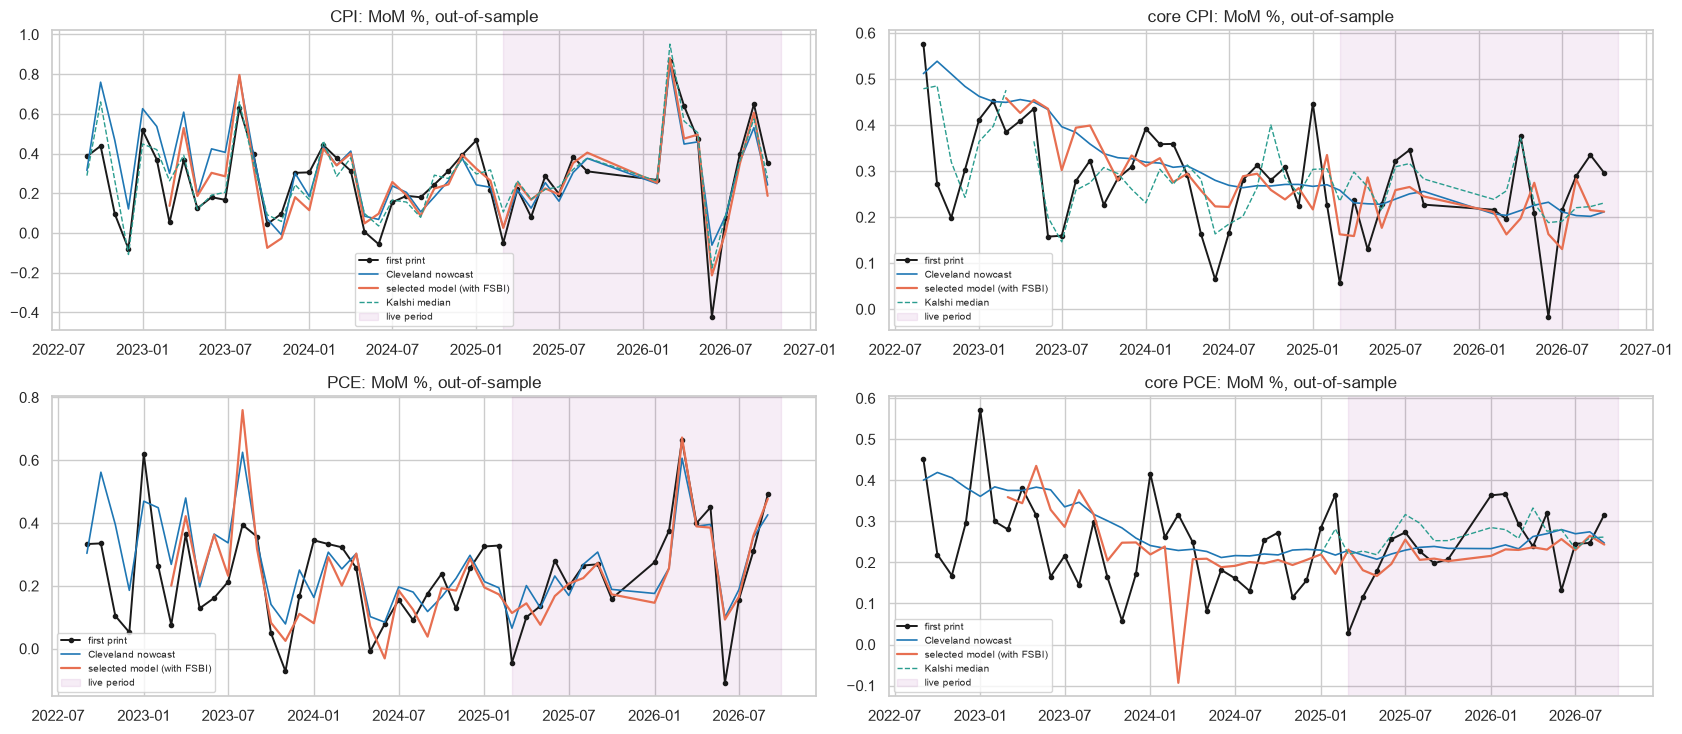

In [63]:
def online_select(f, names, min_hist=6):
    e2 = f[names].sub(f.actual, axis=0) ** 2
    past = e2.expanding(min_hist).mean().shift(1)
    pick = past.dropna(how="all").idxmin(axis=1)
    return pd.Series({t: f.at[t, m] for t, m in pick.items()}, dtype=float), pick
SEL, SEL_NOFSBI, PICK, sel_rows = {}, {}, {}, {}
for k in TARGETS:
    SEL[k], PICK[k] = online_select(OOS[k], MODEL_NAMES); SEL_NOFSBI[k], _ = online_select(OOS_NOFSBI[k], MODEL_NAMES)
    f = pre(OOS[k].loc[SEL[k].index]); e, e0, en = f.actual - SEL[k].reindex(f.index), f.actual - f.Anchor, f.actual - SEL_NOFSBI[k].reindex(f.index)
    bs = block_bootstrap(np.arange(len(e)), lambda ix: np.sqrt((e.values[ix.astype(int)] ** 2).mean() / (e0.values[ix.astype(int)] ** 2).mean()))
    sel_rows[LABEL[k]] = {"months": len(e), "RMSE selected": rmse(e), "RMSE nowcast": rmse(e0), "ratio": rmse(e) / rmse(e0), "90% interval": f"{np.nanpercentile(bs, 5):.2f} to {np.nanpercentile(bs, 95):.2f}",
                          "share of resamples < 1": float(np.nanmean(bs < 1)), "DM p": dm_p(e, e0), "R2 selected": r2(f.actual, SEL[k].reindex(f.index)), "R2 nowcast": r2(f.actual, f.Anchor), "RMSE selected, no FSBI": rmse(en),
                          "RMSE Kalshi": rmse(f.actual - f.Kalshi) if "Kalshi" in f and f.Kalshi.notna().sum() > 5 else np.nan, "most selected model": PICK[k].value_counts().index[0]}
SEL_TAB = pd.DataFrame(sel_rows).T
display(SEL_TAB)
fig, axes = plt.subplots(2, 2, figsize=(17, 7.5))
for ax, k in zip(axes.flat, TARGETS):
    f = OOS[k]; ax.plot(f.index, f.actual, "k-o", ms=3, lw=1.4, label="first print"); ax.plot(f.index, f.Anchor, color="#1f77b4", lw=1.2, label="Cleveland nowcast")
    ax.plot(SEL[k].index, SEL[k], color="#e76f51", lw=1.6, label="selected model (with FSBI)")
    if "Kalshi" in f:
        ax.plot(f.index, f.Kalshi, color="#2a9d8f", lw=1, ls="--", label="Kalshi median")
    ax.axvspan(EVAL_END, f.index.max() + pd.offsets.MonthEnd(0), color="purple", alpha=0.07, label="live period")
    ax.set_title(f"{LABEL[k]}: MoM %, out-of-sample"); ax.legend(fontsize=7)
plt.tight_layout()

### 3.6c Combining with the nowcast, and when to trust the disagreement

Two questions the trading section depends on:

1. **Combination.** Even a forecast that does not beat the nowcast can improve it when the two are averaged, because their errors are not the same (Bates & Granger, 1969). Each month the weight on the selected forecast is the least-squares weight from earlier months only, clipped to [0, 1]. A weight near zero says FSBI's model adds nothing the nowcast lacks; a stable weight above zero is the honest measure of what it adds.
2. **Disagreement.** Strategies A2, J3 and L1 trade the *sign* of the model minus the nowcast. If that sign is informative at all, it should be most informative when the two disagree by a lot. Months are split by whether the disagreement is above the median of earlier months (known in real time), and for each group the hit rate is the share of months where the print landed on the model's side of the nowcast.

In [64]:
comb_rows, COMB = {}, {}
for k in TARGETS:
    d_ = pd.concat({"y": OOS[k].actual, "nc": OOS[k].Anchor, "m": SEL[k]}, axis=1).dropna()
    a_, b_ = d_.y - d_.nc, d_.m - d_.nc
    w_ = ((a_ * b_).expanding(6).sum() / (b_ ** 2).expanding(6).sum()).shift(1).clip(0, 1)
    COMB[k] = (d_.nc + w_ * b_).dropna(); dd = pre(d_.loc[COMB[k].index])
    e_c, e_n, e_m = dd.y - COMB[k].reindex(dd.index), dd.y - dd.nc, dd.y - dd.m
    gap = (dd.m - dd.nc).abs(); big = gap > (d_.m - d_.nc).abs().expanding(6).median().shift(1).reindex(dd.index)
    hit = np.sign(dd.m - dd.nc) == np.sign(dd.y - dd.nc); hit = hit[(dd.m - dd.nc) != 0]
    comb_rows[LABEL[k]] = {"months": len(dd), "combination / nowcast RMSE": rmse(e_c) / rmse(e_n), "selected / nowcast RMSE": rmse(e_m) / rmse(e_n), "CW p (combination vs nowcast)": cw_p(e_c, e_n),
                           "latest weight on the model": float(w_.dropna().iloc[-1]) if w_.notna().any() else np.nan, "mean weight": float(pre(w_).mean()),
                           "hit rate, large disagreement": float(hit[big.reindex(hit.index).fillna(False)].mean()), "months, large": int(big.reindex(hit.index).fillna(False).sum()),
                           "hit rate, small disagreement": float(hit[~big.reindex(hit.index).fillna(False)].mean()), "months, small": int((~big.reindex(hit.index).fillna(False)).sum())}
COMB_TAB = pd.DataFrame(comb_rows).T
display(COMB_TAB.round(3))
print("Reading: a combination ratio below 1 with a weight above 0 means FSBI's model adds information to the nowcast even if it does not beat it alone. "
      "A hit rate above 0.5 in the large-disagreement months is what the sign-based trades (A2, J3, L1) need; a hit rate below 0.5 there means the model's big disagreements are its own errors, which is when fading it (the reversals in 4.1b) works.")

,months,combination / nowcast RMSE,selected / nowcast RMSE,CW p (combination vs nowcast),latest weight on the model,mean weight,"hit rate, large disagreement","months, large","hit rate, small disagreement","months, small"
CPI,18.0,1.137,1.135,0.314,1.000,0.995,0.600,5.0,0.308,13.0
core CPI,18.0,1.007,1.007,0.333,0.936,1.000,0.615,13.0,0.200,5.0
PCE,18.0,1.021,1.122,0.615,0.122,0.153,0.667,6.0,0.583,12.0
core PCE,18.0,1.301,1.299,0.638,0.056,0.387,0.600,5.0,0.538,13.0


Reading: a combination ratio below 1 with a weight above 0 means FSBI's model adds information to the nowcast even if it does not beat it alone. A hit rate above 0.5 in the large-disagreement months is what the sign-based trades (A2, J3, L1) need; a hit rate below 0.5 there means the model's big disagreements are its own errors, which is when fading it (the reversals in 4.1b) works.


### 3.6b The live forecast: the newest FSBI month

Always for `LIVE_MONTH`, the newest month in the FSBI file, so it moves forward each time a new file is dropped in. Every model is refitted on all labelled months before it, and the headline is the model the online rule would pick next (lowest squared error over all past out-of-sample months), the same rule that produced the forecast history. If a non-FSBI input for that month is not out yet, its last value is carried forward and the table lists it. The 90% band is 1.64 × the selected forecast's out-of-sample RMSE.

**Previous-month check:** the month before the live month (or the latest earlier month with a published print), its real-time forecast and the miss (print minus forecast), for the selected model, the nowcast and Kalshi.

In [65]:
def live_forecast(k, t=None):
    t = t or LIVE_MONTH; base = NC[k]
    tbl = pd.DataFrame({"y": Y[k] - base, "base": base, "actual": Y[k]}).join(pd.concat([block(k, b) for b in ALL_BLOCKS], axis=1)).loc[~in_covid(IDX)]
    cols = feats(tbl); need = [c for c in cols + ["base"] if c not in OPTIONAL]
    if t not in tbl.index or tbl.loc[t, [c for c in cols if c.startswith(tuple(F["nat"].columns))]].isna().all():
        raise ValueError(f"no FSBI features for {t:%Y-%m}")
    row = tbl.loc[[t]].copy(); imputed = [c for c in need if pd.isna(row.at[t, c])]
    row[need] = tbl[need].ffill().loc[[t]]                       # carry forward any input not yet published
    train = tbl[tbl.index < t].dropna(subset=["y"] + need)
    preds = {m: float(row.base.iloc[0] + fac(cols)(train, row)) for m, fac in ZOO.items()}
    preds["Model average"] = float(np.mean(list(preds.values())))
    past = OOS[k][MODEL_NAMES].sub(OOS[k].actual, axis=0).pow(2)
    pick = past[past.index < t].mean().idxmin()
    return {"month": t, "pick": pick, "forecast": preds[pick], "preds": preds, "nowcast": float(row.base.iloc[0]), "imputed": imputed}

LIVE, cur, prev = {}, {}, {}
for k in TARGETS:
    try:
        L_ = LIVE[k] = live_forecast(k)
    except Exception as exc:
        print(f"{LABEL[k]}: live forecast unavailable ({exc})"); continue
    band = 1.64 * rmse(OOS[k].actual.reindex(SEL[k].index) - SEL[k])
    cur[LABEL[k]] = {"month": f"{L_['month']:%Y-%m}", "status": "unpublished" if pd.isna(Y.at[L_["month"], k]) else f"published {Y.at[L_['month'], k]:.2f}",
                     "forecast": L_["forecast"], "selected model": L_["pick"], "model average": L_["preds"]["Model average"], "Cleveland nowcast": L_["nowcast"],
                     "Kalshi": float(KAL.at[L_["month"], k]) if k in KAL and pd.notna(KAL.at[L_["month"], k]) else np.nan, "90% band (+/-)": band,
                     "release date": f"{SCHEDULE.at[k, 'release date']:%Y-%m-%d}" if SCHEDULE.at[k, "next month"] == L_["month"] else "", "inputs carried forward": ", ".join(L_["imputed"]) or "none"}
    checkable = SEL[k].dropna().index.intersection(Y[k].dropna().index)
    t_prev = LIVE_MONTH - pd.DateOffset(months=1) if (LIVE_MONTH - pd.DateOffset(months=1)) in checkable else checkable[checkable < LIVE_MONTH].max()
    if pd.notna(t_prev):
        a_ = Y.at[t_prev, k]; f_ = OOS[k].loc[t_prev] if t_prev in OOS[k].index else None
        prev[LABEL[k]] = {"month": f"{t_prev:%Y-%m}", "first print": a_, "forecast": SEL[k][t_prev], "miss (print - forecast)": a_ - SEL[k][t_prev], "selected model": PICK[k].get(t_prev, ""),
                          "nowcast": NC.at[t_prev, k], "nowcast miss": a_ - NC.at[t_prev, k], "Kalshi": KAL.at[t_prev, k] if k in KAL else np.nan,
                          "Kalshi miss": a_ - KAL.at[t_prev, k] if k in KAL and pd.notna(KAL.at[t_prev, k]) else np.nan}
CURRENT, PREVIOUS = pd.DataFrame(cur).T, pd.DataFrame(prev).T
for k in LIVE:                                                    # the live month joins the forecast series used by signals and the dashboard
    SEL[k] = pd.concat([SEL[k], pd.Series({LIVE[k]["month"]: LIVE[k]["forecast"]})]).groupby(level=0).first().sort_index()
print(f"LIVE FORECASTS for {LIVE_MONTH:%B %Y} (MoM %):"); display(CURRENT)
print("Previous month: real-time forecast vs first print (pp):"); display(PREVIOUS.round(3) if len(PREVIOUS) else "none")

LIVE FORECASTS for October 2026 (MoM %):


,month,status,forecast,selected model,model average,Cleveland nowcast,Kalshi,90% band (+/-),release date,inputs carried forward
CPI,2026-10,published 0.35,0.187036,Gradient boosting,0.238874,0.242106,0.275806,0.162989,,none
core CPI,2026-10,published 0.30,0.21196,AR (own lags),0.207495,0.211437,0.230723,0.166803,,none
PCE,2026-10,unpublished,0.250949,Model average,0.250949,0.265227,NaN,0.183639,2026-11-25,none
core PCE,2026-10,unpublished,0.218219,Neural net (MLP),0.211717,0.256482,0.258696,0.192172,2026-11-25,none


Previous month: real-time forecast vs first print (pp):


,month,first print,forecast,miss (print - forecast),selected model,nowcast,nowcast miss,Kalshi,Kalshi miss
CPI,2026-09,0.648548,0.605886,0.042662,Gradient boosting,0.530663,0.117885,0.574419,0.074129
core CPI,2026-09,0.334848,0.215237,0.119611,AR (own lags),0.201681,0.133167,0.22284,0.112009
PCE,2026-09,0.49084,0.477332,0.013508,Model average,0.426204,0.064636,NaN,NaN
core PCE,2026-09,0.316502,0.243506,0.072996,Neural net (MLP),0.247277,0.069225,0.261765,0.054737


### 3.7 Which features matter? By target, by model, and for the selected forecast

**Method.** Each model is refitted on the full pre-holdout sample (tree models with their most frequently chosen hyperparameters) and scored by **permutation importance**: shuffle one feature, measure how much the model's squared error rises, repeat, and express each feature's rise as a share of the total. The same yardstick works for every model, so a Lasso and a random forest can be compared directly. ARIMAX, which is not a scikit-learn model, is scored by the size of its standardised exogenous coefficients.

Three views per target:

- **each model** on its own (what Lasso leans on vs what the forest leans on);
- **Overall**: the average share across models;
- **Online-selected**: model shares weighted by how often the online selection in 3.6 picked each model, i.e. what the forecast that is actually used leans on.

The stacked bars on the right add the shares up by block, which answers the Fiserv question in one number: *what fraction of each model's signal comes from FSBI?*

How to read it: importance says what a fitted model relies on in sample. It is not evidence that the feature improves forecasts out of sample; that is what the ladder and ablation in 3.2 test. A feature that is important here and whose block also helps in 3.2 is the credible case. Lasso can legitimately show no bars at all: it then predicts the anchor plus a constant.

FSBI's share of each model's importance, % (rows with 0 across the board selected no features)   (115s)


,CPI,core CPI,PCE,core PCE
Overall (mean of models),25.6,30.6,45.3,59.6
Online-selected forecast,29.6,0.0,54.1,63.2
Lasso,16.5,18.7,41.2,70.0
Ridge,36.6,43.1,44.8,57.7
OLS (top-4 screened),4.3,14.2,70.1,78.2
PCR (3 components),50.5,62.9,56.0,68.8
Random forest,35.9,46.6,51.1,55.7
Gradient boosting,29.6,20.3,33.9,45.7
Neural net (MLP),37.0,43.2,48.5,60.0
"ARIMAX(1,0,0)",20.1,26.2,62.2,100.0


Top three features by view:


,CPI,core CPI,PCE,core PCE
Overall (mean of models),"kal_gap (29%), m_food_home_l1 (15%), y_l1 (10%)","kal_gap (27%), y_l2 (14%), demand_pull (8%)","demand_pull (18%), kal_gap (16%), y_l2 (11%)","demand_pull (23%), y_l2 (13%), tk_dispersion (11%)"
Online-selected forecast,"kal_gap (42%), tk_gas_stations (19%), m_shelter_l1 (11%)","y_l2 (57%), y_l1 (43%)","demand_pull (19%), supply_squeeze (9%), kal_gap (7%)","demand_pull (24%), m_unemployment_l1 (12%), tk_dispersion (11%)"
Lasso,"kal_gap (53%), m_food_home_l1 (18%), m_shelter_l1 (13%)","kal_gap (59%), y_l2 (15%), tk_northeast (10%)","demand_pull (28%), kal_gap (19%), m_food_home_l1 (13%)","demand_pull (47%), m_unemployment_l1 (21%), tk_dispersion (17%)"
Random forest,"kal_gap (32%), tk_gas_stations (10%), m_shelter_l1 (8%)","kal_gap (11%), m_food_home_l1 (5%), m_shelter_l1 (5%)","kal_gap (11%), txn_dispersion (9%), m_vix (7%)","txn_dispersion (11%), m_vix (10%), m_used_cars_l1 (4%)"


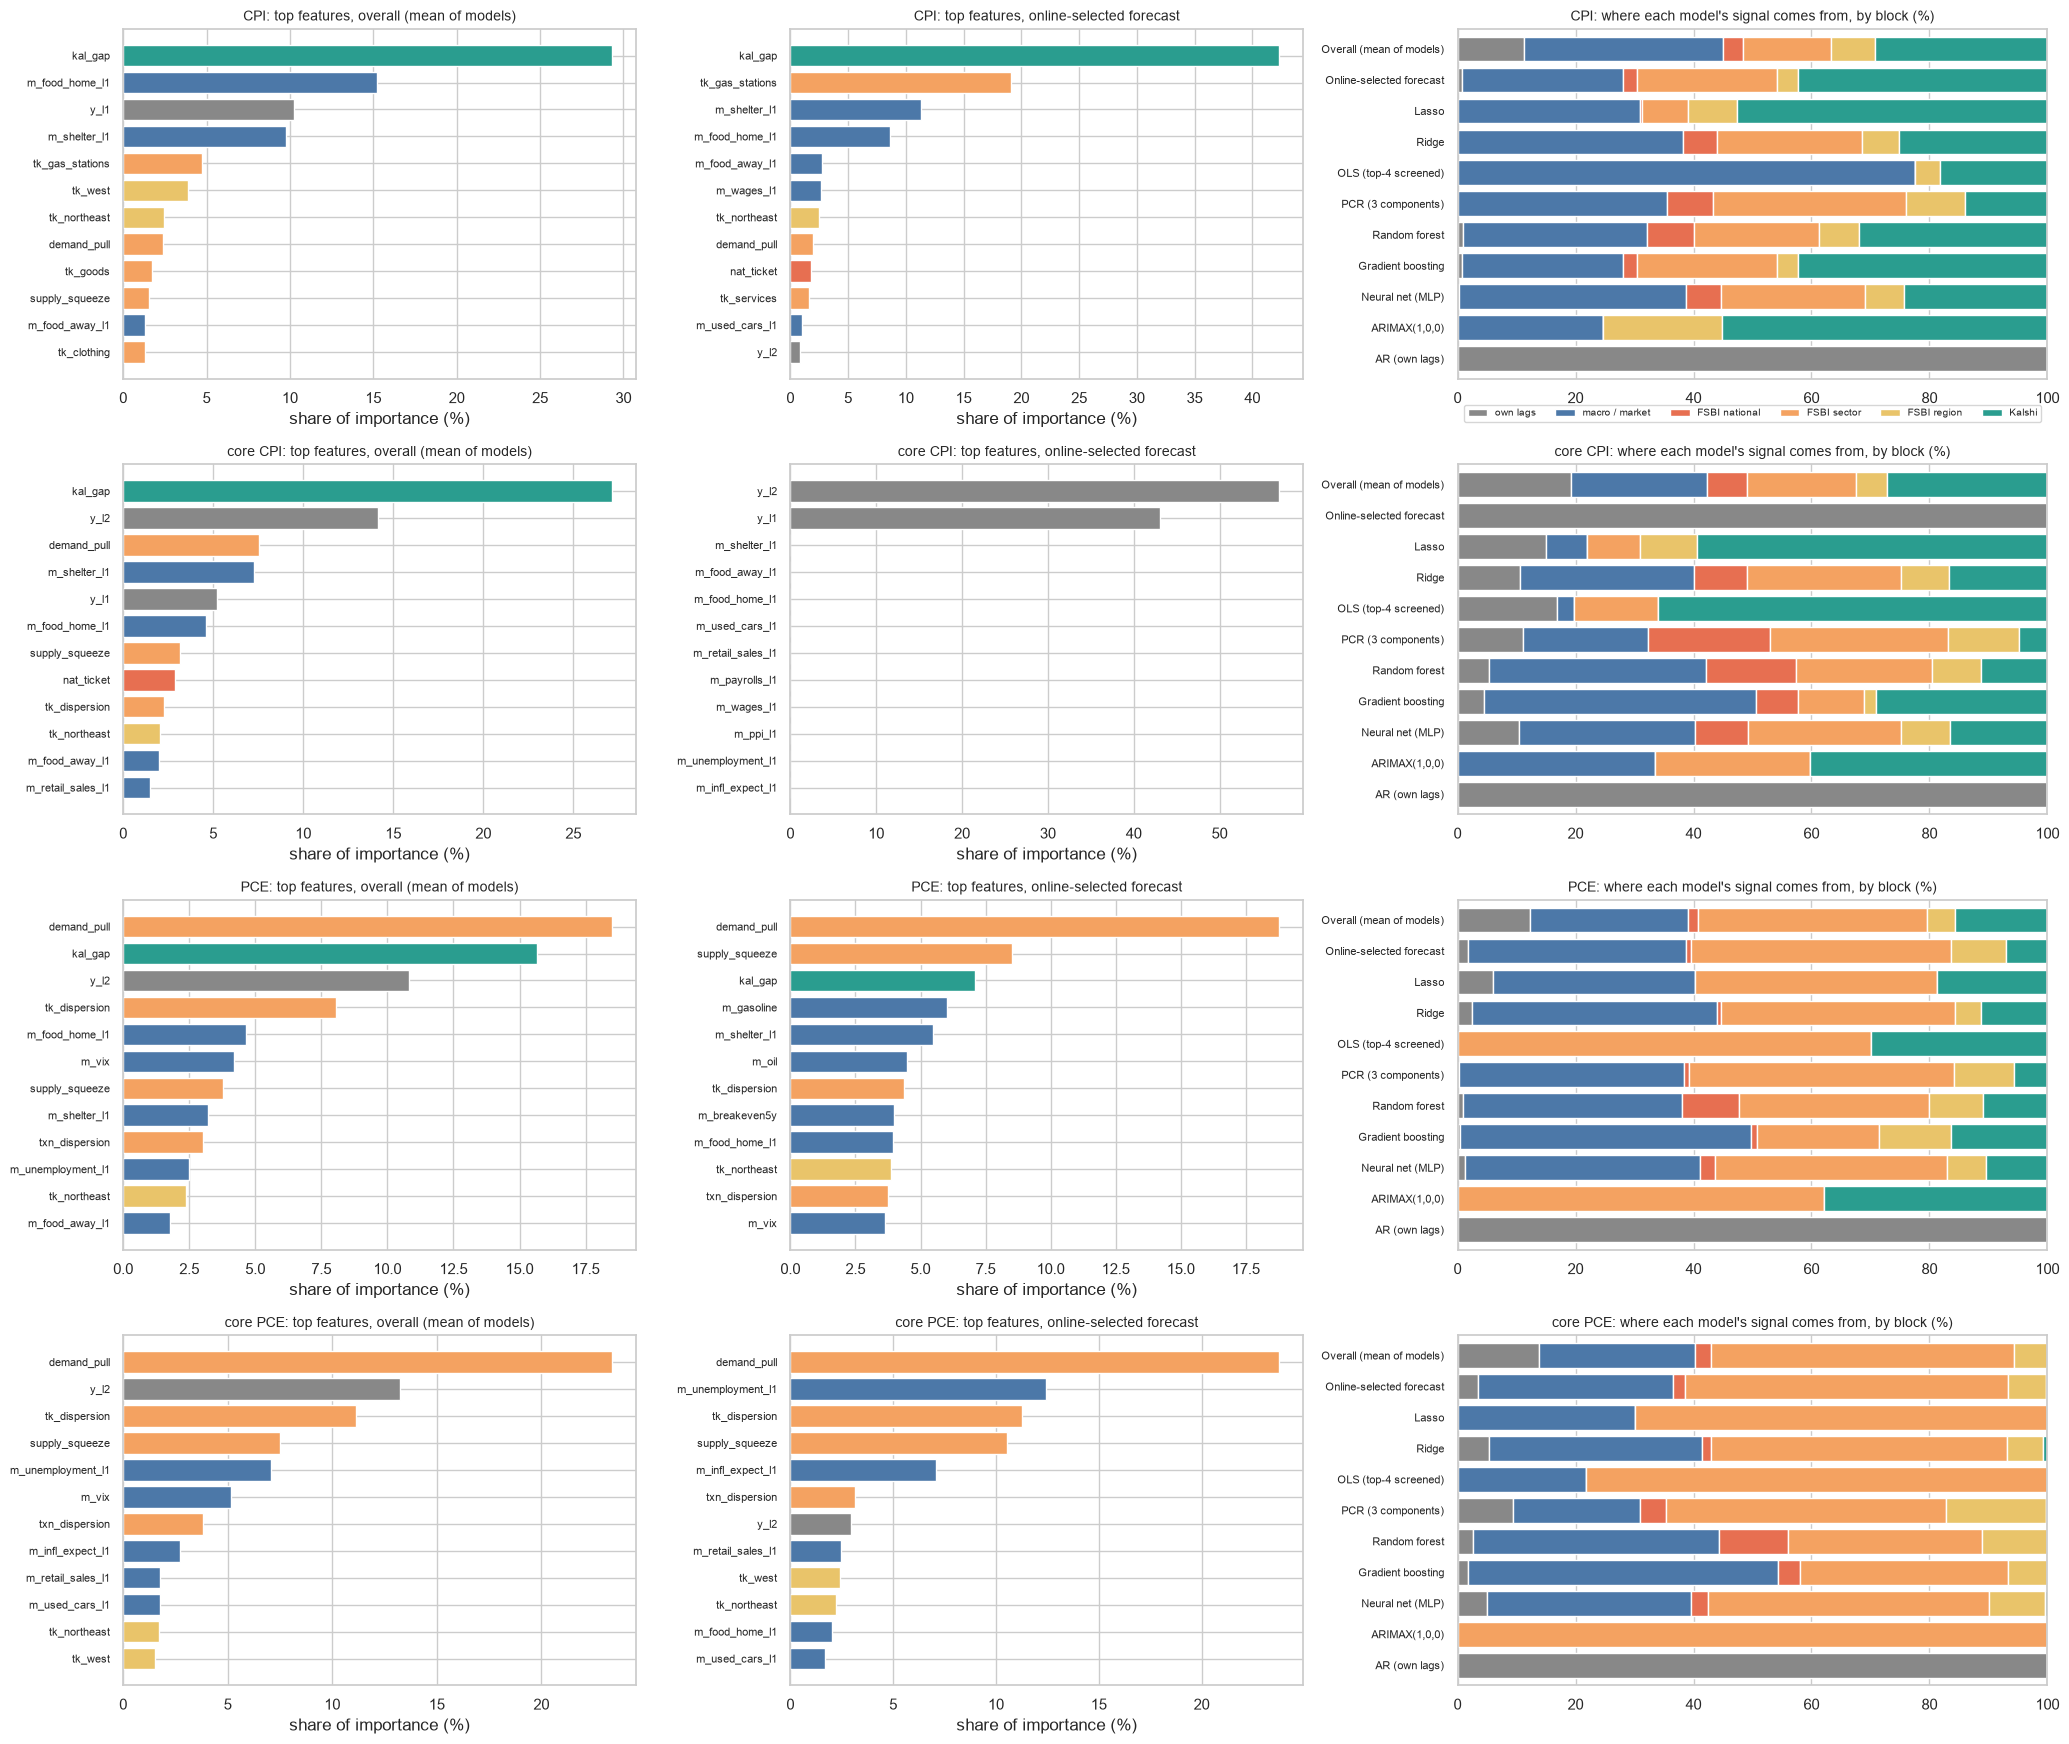

In [66]:
BLOCK_OF = {c: b for b in ("nat", "sec", "reg", "mac") for c in F[b].columns}; BLOCK_OF.update({"y_l1": "own", "y_l2": "own", "kal_gap": "kal"})
BLOCK_NAME = {"own": "own lags", "mac": "macro / market", "nat": "FSBI national", "sec": "FSBI sector", "reg": "FSBI region", "kal": "Kalshi"}
BLOCK_COLOR = {"own lags": "#888888", "macro / market": "#4c78a8", "FSBI national": "#e76f51", "FSBI sector": "#f4a261", "FSBI region": "#e9c46a", "Kalshi": "#2a9d8f"}
N_PERM = 5 if FAST else 15

def perm_importance(predict, X, y, n_rep=N_PERM):
    """Share of the total rise in squared error caused by shuffling each feature (negative rises count as zero)."""
    g_ = np.random.default_rng(SEED); base = np.mean((y - predict(X)) ** 2); out = {}
    for c in X.columns:
        rise = []
        for _ in range(n_rep):
            Xp = X.copy(); Xp[c] = g_.permutation(X[c].to_numpy(copy=True)); rise.append(np.mean((y - predict(Xp)) ** 2) - base)
        out[c] = max(float(np.mean(rise)), 0.0)
    s = pd.Series(out)
    return s / s.sum() if s.sum() > 0 else s

def model_importance(k):
    tbl = design(k, ALL_BLOCKS).loc[rows(k)]; cols = feats(tbl); X, y = tbl[cols], tbl.y.values; out = {}
    own = [c for c in cols if c in ("y_l1", "y_l2")]; ar = LinearRegression().fit(X[own], y)
    out["AR (own lags)"] = perm_importance(lambda d: ar.predict(d[own]), X, y)
    for name, (make, pre, grid) in SPEC.items():
        est = make()
        if grid and TUNED.get(name):
            est.set_params(**json.loads(pd.Series([json.dumps(p, sort_keys=True) for p in TUNED[name]]).mode().iloc[0]))
        pipe = _pipe(est, *[p(len(cols)) for p in pre]).fit(X, y)
        out[name] = perm_importance(pipe.predict, X, y)
    try:                                                    # ARIMAX: |standardised exogenous coefficients|
        ex = X.corrwith(tbl.y).abs().dropna().sort_values(ascending=False).index[:3].tolist()
        fit = SARIMAX(y, exog=((X[ex] - X[ex].mean()) / X[ex].std()).fillna(0).values, order=(1, 0, 0), trend="c").fit(disp=False, maxiter=60)
        coef = pd.Series(np.abs(np.asarray(fit.params)[1:1 + len(ex)]), index=ex)
        out["ARIMAX(1,0,0)"] = (coef / coef.sum()).reindex(cols).fillna(0.0)
    except Exception:
        pass
    imp = pd.DataFrame(out).reindex(cols).fillna(0.0)
    used = imp.loc[:, imp.sum() > 0]
    imp["Overall (mean of models)"] = used.mean(axis=1) if used.shape[1] else 0.0
    w = PICK[k].value_counts(normalize=True); sel = pd.Series(0.0, index=cols)
    for m, share in w.items():                              # 'Model average' picks count as the overall mean
        sel += share * (imp[m] if m in imp and imp[m].sum() > 0 else imp["Overall (mean of models)"])
    imp["Online-selected forecast"] = sel / sel.sum() if sel.sum() > 0 else sel
    return imp

t0 = time.time()
IMP = {k: model_importance(k) for k in TARGETS}
IMP_VIEWS = ["Overall (mean of models)", "Online-selected forecast"] + [m for m in ["Lasso", "Ridge", "OLS (top-4 screened)", "PCR (3 components)", "Random forest", "Gradient boosting", "Neural net (MLP)", "ARIMAX(1,0,0)", "AR (own lags)"] if m in IMP[TARGETS[0]]]
BLOCK_SHARE = {k: IMP[k].groupby(IMP[k].index.map(lambda c: BLOCK_NAME[BLOCK_OF.get(c, "mac")])).sum().T.reindex(index=IMP_VIEWS, columns=list(BLOCK_COLOR)).fillna(0.0) for k in TARGETS}
fig, axes = plt.subplots(len(TARGETS), 3, figsize=(21, 4.4 * len(TARGETS)), gridspec_kw={"width_ratios": [1, 1, 1.15]})
for row, k in zip(axes, TARGETS):
    for ax, view in zip(row[:2], IMP_VIEWS[:2]):
        s = IMP[k][view].sort_values(ascending=False).head(12)[::-1]
        ax.barh(s.index, 100 * s.values, color=[BLOCK_COLOR[BLOCK_NAME[BLOCK_OF.get(c, "mac")]] for c in s.index]); ax.tick_params(axis="y", labelsize=8)
        ax.set_title(f"{LABEL[k]}: top features, {view.lower()}", fontsize=10); ax.set_xlabel("share of importance (%)")
    (100 * BLOCK_SHARE[k]).iloc[::-1].plot.barh(stacked=True, ax=row[2], color=[BLOCK_COLOR[c] for c in BLOCK_SHARE[k].columns], width=0.8, legend=(k == TARGETS[0]))
    row[2].set_title(f"{LABEL[k]}: where each model's signal comes from, by block (%)", fontsize=10); row[2].tick_params(axis="y", labelsize=8)
    if k == TARGETS[0]:
        row[2].legend(fontsize=7, ncol=6, loc="upper center", bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
fsbi_cols = ["FSBI national", "FSBI sector", "FSBI region"]
FSBI_SHARE = pd.DataFrame({LABEL[k]: 100 * BLOCK_SHARE[k][fsbi_cols].sum(axis=1) for k in TARGETS})
print(f"FSBI's share of each model's importance, % (rows with 0 across the board selected no features)   ({time.time() - t0:.0f}s)"); display(FSBI_SHARE.round(1))
top = pd.DataFrame({LABEL[k]: {view: ", ".join(f"{c} ({100 * v:.0f}%)" for c, v in IMP[k][view].sort_values(ascending=False).head(3).items() if v > 0) or "none selected" for view in ("Overall (mean of models)", "Online-selected forecast", "Lasso", "Random forest")} for k in TARGETS})
with pd.option_context("display.max_colwidth", 110):
    print("Top three features by view:"); display(top)
pd.concat({LABEL[k]: IMP[k].assign(block=[BLOCK_NAME[BLOCK_OF.get(c, "mac")] for c in IMP[k].index]) for k in TARGETS}, names=["target", "feature"]).to_csv(PROC / "feature_importance.csv")

### 3.8 Beyond inflation: FSBI as a real-time read on activity

Inflation is one use of FSBI. The same data is, more directly, a sample of consumer spending at small firms, published before any official activity statistic for the month. Three tests of that economic use, all with the same walk-forward design as 3.5 (a public model with the target's own lag, then the same model plus FSBI; ratio below 1 means FSBI helped; Clark–West p-value because the models are nested):

1. **National activity.** Advance retail sales (first print), retail sales ex autos, food-service sales, nominal and real PCE and PCE services are *nowcasts*: the official number for month *t* arrives two to four weeks after FSBI. Payrolls, the unemployment rate and consumer sentiment are released at about the same time as FSBI, so there the test is whether FSBI in month *t* *leads* the official series in *t+1*. The Chicago Fed activity index is tested against FSBI's breadth measures (the share of sectors and states growing), which work as a small-business diffusion index.
2. **Sales by kind of business.** Each FSBI sub-sector against the Census retail-trade series for the same kind of store (restaurants, grocers, gasoline stations, clothing, and so on). This is the sales counterpart of the ticket-vs-CPI-component test, and the most direct check that FSBI measures what it says it measures, sector by sector.
3. **State economies.** A pooled panel of all states: does a state's FSBI help nowcast that state's unemployment-rate change and its Philadelphia Fed coincident index? Run twice: on the raw series, and on each state's deviation from the national average that month, which isolates the *local* information (what a state's FSBI says beyond the national cycle). This is the application with the least public competition: no other monthly source covers small-business sales by state.

Growth-rate targets are scored on their first prints where ALFRED has the vintages, and on today's revised series otherwise; the notebook prints how many of each, since revised data favours FSBI slightly. The state block downloads two series per state on its first run (about a minute; cached afterwards).

Research: Aladangady et al. (2022) build spending indicators from the same card-processing source; Galbraith & Tkacz (2018) and Aprigliano, Ardizzi & Monteforte (2019) show payments data improve GDP and consumption nowcasts; Chetty et al. (2024) use private-sector data for state- and county-level tracking.

  FRED series CES7000000001 unavailable (Bad Request.  The series does not exist.); skipped.
Activity targets scored on first prints: 7 of 11 (the rest use today's revised series, which favours FSBI slightly).
1. National activity: public model (own lag) vs the same model plus FSBI


,months,RMSE public only,RMSE with FSBI,ratio,DM p,CW p,R2 public only,R2 with FSBI,horizon
Food services and drinking places sales,33,1.402597,1.218355,0.868642,0.168135,0.041326,0.025693,0.264848,"nowcast, ~2 weeks ahead"
"Unemployment rate change, next month",33,0.135056,0.131067,0.970468,0.195627,0.01627,-0.402788,-0.321157,"lead, 1 month"
PCE services,33,0.278161,0.273063,0.981671,0.728694,0.135902,-0.34809,-0.299125,"nowcast, ~4 weeks ahead"
"Consumer sentiment change, next month",33,4.589158,4.536653,0.988559,0.182263,0.058199,-0.111143,-0.085863,"lead, 1 month"
Retail sales ex autos,33,0.651254,0.647953,0.994931,0.924748,0.038673,-0.105192,-0.094015,"nowcast, ~2 weeks ahead"
"Total payrolls, next month",33,0.063659,0.065211,1.024381,0.690003,0.171662,0.0471,0.000067,"lead, 1 month"
Advance retail sales (first print),33,0.731655,0.769231,1.051357,0.303447,0.029291,0.031773,-0.070231,"nowcast, ~10 days ahead"
Chicago Fed activity index (level),33,0.365087,0.385385,1.055598,0.486687,0.314099,-0.250979,-0.39395,"nowcast, ~3 weeks ahead"
"Retail trade payrolls, next month",33,0.141178,0.14949,1.058876,0.187241,0.762745,-0.0778,-0.208449,"lead, 1 month"
Nominal PCE,33,0.361853,0.411047,1.13595,0.056846,0.693815,0.092208,-0.171398,"nowcast, ~4 weeks ahead"


   FSBI lowered RMSE in 5 of 11; 5 pass the Clark-West test at p < 0.10.

2. Census retail sales by kind of business vs the matching FSBI sub-sector


,months,RMSE public only,RMSE with FSBI,ratio,DM p,CW p,R2 public only,R2 with FSBI,same-month correlation
Gas stations -> RSGASS,33.0,2.575419,1.551219,0.602317,0.003609,0.000575,-0.186319,0.569621,0.808668
Auto dealers -> RSMVPD,33.0,1.790015,1.499045,0.837448,0.200486,0.013046,0.001507,0.299738,0.401323
Restaurants -> RSFSDP,33.0,1.402597,1.218355,0.868642,0.168135,0.041326,0.025693,0.264848,0.629590
Building materials -> RSBMGESD,33.0,1.314982,1.192863,0.907133,0.411481,0.031998,-0.020780,0.160011,0.458712
Furniture & electronics -> RSFHFS,33.0,1.522781,1.511167,0.992373,0.893771,0.045222,-0.044082,-0.028217,0.257491
Grocery -> RSGCS,33.0,0.484740,0.485195,1.000939,0.978278,0.145215,-0.095035,-0.097092,0.302536
Clothing -> RSCCAS,33.0,0.970932,0.999276,1.029193,0.541868,0.098415,-0.051295,-0.113571,0.264759
Drug stores -> RSHPCS,33.0,0.829892,0.859898,1.036157,0.045833,0.964925,-0.151756,-0.236550,-0.057908
General merchandise -> RSGMS,33.0,0.955249,1.042862,1.091718,0.068183,0.346241,-0.137251,-0.355430,-0.128819
Sporting & hobby -> RSSGHBMS,33.0,1.433295,1.644437,1.147313,0.339340,0.019565,-0.079910,-0.421514,0.122407


   FSBI lowered RMSE in 5 of 10; 7 pass the Clark-West test at p < 0.10.

3. State panel


months  states  RMSE public only  RMSE with FSBI     ratio      CW p
State unemployment rate, monthly change (pp) raw                                 31.0    50.0          0.071634        0.071827  1.002697  0.211314
                                             relative to the national average    31.0    50.0          0.062928        0.062944  1.000261  0.401374
State coincident index, monthly growth (%)   raw                                 31.0    50.0          0.159981        0.161231  1.007816  0.304459
                                             relative to the national average    31.0    50.0          0.135155        0.135990  1.006184  0.168304

   FSBI lowered RMSE in 0 of 4; 0 pass the Clark-West test at p < 0.10.

(17s)


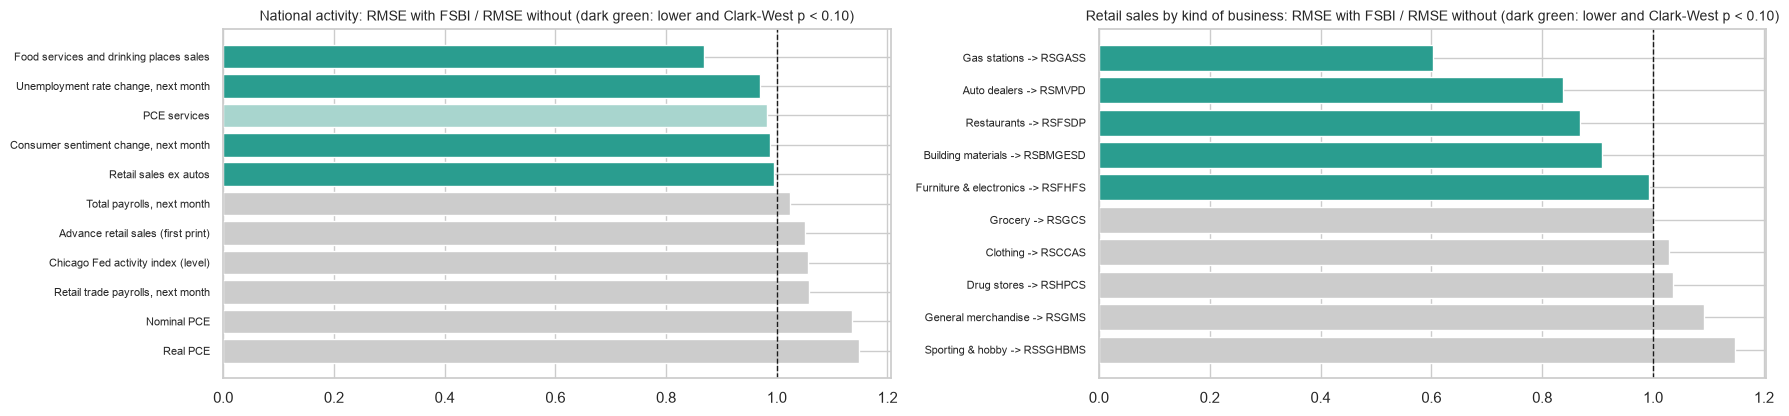

In [67]:
t0 = time.time()
mom = lambda s: (s.pct_change(fill_method=None) * 100).reindex(IDX)
def fsbi_cols(*specs):
    """FSBI inputs by (level, metric, name), e.g. ('sector', 'sales', 'Retail'); missing names are skipped."""
    return pd.DataFrame({f"fsbi_{lvl}_{m}_{n}".lower().replace(" ", "_").replace("&", "and"): g(lvl, m)[n] for lvl, m, n in specs if n in FSBI[lvl][m]})
NAT_IN = fsbi_cols(("national", "sales", "US"), ("national", "txn", "US"))
def activity_test(y, inputs, lead=0):
    """lead=0: nowcast month t from FSBI of month t. lead=1: does FSBI of month t lead the official series in t+1 (own value for t is public)?"""
    if y is None:
        return None
    y = y.reindex(IDX)
    return add_test(y, pd.DataFrame({"own_l1": y.shift(1)}), inputs) if lead == 0 else add_test(y.shift(-1), pd.DataFrame({"own_l0": y}), inputs)

# 1. national activity
RS_ADD = fsbi_cols(("sector", "sales", "Retail"), ("national", "sales", "US"), ("national", "txn", "US"))
RS_TAB = RS_FC = None
if RS.notna().sum() > MIN_TRAIN + 8:
    RS_TAB = add_test(RS, pd.DataFrame({"own_l1": RS.shift(1)}), RS_ADD); RS_FC = add_test(RS, pd.DataFrame({"own_l1": RS.shift(1)}), RS_ADD, forecasts=True, end=FAR)   # forecasts through the newest print (family G trades them); the score above is design-period
_f_latest = lambda sid, how="pct": (lambda s: None if s is None else (mom(s) if how == "pct" else s.diff().reindex(IDX) if how == "diff" else s.reindex(IDX)))(fred_try(sid))
VINTAGE = {}
def _f(sid, how="pct"):
    """Monthly change as FIRST PUBLISHED where ALFRED has the vintages (growth-rate series), else today's revised series. VINTAGE records which."""
    if how == "pct":
        try:
            fp_ = first_print(sid)[0].reindex(IDX)
            if fp_.notna().sum() >= MIN_TRAIN + 8:
                VINTAGE[sid] = "first print"; return fp_
        except Exception:
            pass
    VINTAGE[sid] = "latest vintage"; return _f_latest(sid, how)
REST_IN = fsbi_cols(("subsector", "sales", "Restaurants"), ("subsector", "txn", "Restaurants"))
ACTIVITY = {"Retail sales ex autos": (_f("RSFSXMV"), RS_ADD, 0, "nowcast, ~2 weeks ahead"), "Food services and drinking places sales": (_f("RSFSDP"), REST_IN, 0, "nowcast, ~2 weeks ahead"),
            "Nominal PCE": (_f("PCE"), NAT_IN, 0, "nowcast, ~4 weeks ahead"), "Real PCE": (_f("PCEC96"), NAT_IN, 0, "nowcast, ~4 weeks ahead"), "PCE services": (_f("PCES"), NAT_IN, 0, "nowcast, ~4 weeks ahead"),
            "Chicago Fed activity index (level)": (_f("CFNAI", "level"), F["nat"][["breadth_sector", "breadth_state", "nat_txn"]], 0, "nowcast, ~3 weeks ahead"),
            "Total payrolls, next month": (_f("PAYEMS"), NAT_IN, 1, "lead, 1 month"), "Leisure and hospitality payrolls, next month": (_f("CES7000000001"), fsbi_cols(("sector", "txn", "Accommodation & food"), ("sector", "sales", "Accommodation & food")), 1, "lead, 1 month"),
            "Retail trade payrolls, next month": (_f("USTRADE"), fsbi_cols(("sector", "txn", "Retail"), ("sector", "sales", "Retail")), 1, "lead, 1 month"),
            "Unemployment rate change, next month": (_f("UNRATE", "diff"), F["nat"][["breadth_state", "nat_txn"]], 1, "lead, 1 month"), "Consumer sentiment change, next month": (_f("UMCSENT", "diff"), NAT_IN, 1, "lead, 1 month")}
nat_rows = {"Advance retail sales (first print)": {**RS_TAB, "horizon": "nowcast, ~10 days ahead"}} if RS_TAB else {}
for name, (y, inputs, lead, horizon) in ACTIVITY.items():
    r_ = activity_test(y, inputs, lead)
    if r_:
        nat_rows[name] = {**r_, "horizon": horizon}
ECON_NAT = pd.DataFrame(nat_rows).T
print(f"Activity targets scored on first prints: {sum(v == 'first print' for v in VINTAGE.values())} of {len(VINTAGE)} (the rest use today's revised series, which favours FSBI slightly).")

# 2. Census retail sales by kind of business vs the matching FSBI sub-sector
MRTS = {"Restaurants": "RSFSDP", "Grocery": "RSGCS", "Gas stations": "RSGASS", "General merchandise": "RSGMS", "Clothing": "RSCCAS", "Sporting & hobby": "RSSGHBMS",
        "Furniture & electronics": "RSFHFS", "Building materials": "RSBMGESD", "Auto dealers": "RSMVPD", "Drug stores": "RSHPCS"}
sec_rows = {}
for e, sid in MRTS.items():
    y = _f(sid)
    if y is None or e not in FSBI["subsector"]["sales"]:
        continue
    r_ = add_test(y, pd.DataFrame({"own_l1": y.shift(1)}), fsbi_cols(("subsector", "sales", e), ("subsector", "txn", e)))
    if r_:
        sec_rows[f"{e} -> {sid}"] = {**r_, "same-month correlation": g("subsector", "sales")[e][dev].corr(y[dev])}
ECON_SEC = pd.DataFrame(sec_rows).T

# 3. state panel: unemployment rate and coincident index
def panel_test(Yp, Xs, min_train=MIN_TRAIN, relative=False):
    """Pooled walk-forward OLS over states: own lag vs own lag + the state's FSBI. relative=True removes each month's cross-state mean
    from every variable, so only a state's deviation from the nation is being explained."""
    if relative:
        Yp = Yp.sub(Yp.mean(axis=1), axis=0); Xs = [X.sub(X.mean(axis=1), axis=0) for X in Xs]
    L = pd.concat({"y": Yp.stack(), "own": Yp.shift(1).stack(), **{f"x{i}": X.reindex(columns=Yp.columns).stack() for i, X in enumerate(Xs)}}, axis=1).dropna()
    d_ = L.index.get_level_values(0); L = L[~pd.Series(d_).between(*COVID).values & (d_ < EVAL_END)]; months = sorted(L.index.get_level_values(0).unique())
    if len(months) < min_train + 8:
        return None
    xc = [c for c in L if c.startswith("x")]; rows_ = []
    for i in range(min_train, len(months)):
        tr, te = L[L.index.get_level_values(0) < months[i]], L[L.index.get_level_values(0) == months[i]]
        e0 = te.y - LinearRegression().fit(tr[["own"]], tr.y).predict(te[["own"]]); e1 = te.y - LinearRegression().fit(tr[["own"] + xc], tr.y).predict(te[["own"] + xc])
        rows_.append({"mse0": (e0 ** 2).mean(), "mse1": (e1 ** 2).mean(), "adj": ((e0 - e1) ** 2).mean()})
    R_ = pd.DataFrame(rows_); f = R_.mse0 - (R_.mse1 - R_.adj)
    cw = float(1 - norm.cdf(sm.OLS(f.values, np.ones(len(f))).fit(cov_type="HAC", cov_kwds={"maxlags": 3}).tvalues[0])) if f.std() > 0 else np.nan
    return {"months": len(R_), "states": Yp.shape[1], "RMSE public only": np.sqrt(R_.mse0.mean()), "RMSE with FSBI": np.sqrt(R_.mse1.mean()), "ratio": np.sqrt(R_.mse1.mean() / R_.mse0.mean()), "CW p": cw}
PANEL_STATES = STATES[:10] if FAST else STATES
st_ur = pd.DataFrame({s: v.diff().reindex(IDX) for s in PANEL_STATES if (v := fred_try(f"{s}UR")) is not None})
st_ci = pd.DataFrame({s: mom(v) for s in PANEL_STATES if (v := fred_try(f"{s}PHCI")) is not None})
ST_IN = [g("state", "sales"), g("state", "txn"), g("state", "sales", 3) / 3]
state_rows = {}
for name, Yp in (("State unemployment rate, monthly change (pp)", st_ur), ("State coincident index, monthly growth (%)", st_ci)):
    for rel in (False, True):
        if Yp.shape[1] >= 5:
            r_ = panel_test(Yp, ST_IN, relative=rel)
            if r_:
                state_rows[(name, "relative to the national average" if rel else "raw")] = r_
ECON_STATE = pd.DataFrame(state_rows).T
ECON_MAP = pd.Series({s: g("state", "sales", 3)[s][dev].corr(st_ci[s].rolling(3).sum()[dev]) for s in st_ci}, dtype=float) if st_ci.shape[1] else pd.Series(dtype=float)

for title, tab in (("1. National activity: public model (own lag) vs the same model plus FSBI", ECON_NAT), ("2. Census retail sales by kind of business vs the matching FSBI sub-sector", ECON_SEC), ("3. State panel", ECON_STATE)):
    if len(tab):
        print(title); display(tab.sort_values("ratio") if tab.index.nlevels == 1 else tab)
        num = tab.apply(pd.to_numeric, errors="coerce")
        print(f"   FSBI lowered RMSE in {int((num.ratio < 1).sum())} of {len(tab)}; {int((num['CW p'] < 0.10).sum())} pass the Clark-West test at p < 0.10.\n")
fig, axes = plt.subplots(1, 2, figsize=(18, max(4.2, 0.36 * (len(ECON_NAT) + 1))))
for ax, tab, ttl in ((axes[0], ECON_NAT, "National activity"), (axes[1], ECON_SEC, "Retail sales by kind of business")):
    if len(tab):
        s = tab.ratio.astype(float).sort_values(ascending=False); p = tab["CW p"].astype(float).reindex(s.index)
        ax.barh(s.index, s.values, color=["#2a9d8f" if (v < 1 and q < 0.10) else "#a8d5ce" if v < 1 else "#cccccc" for v, q in zip(s.values, p.values)]); ax.axvline(1, color="k", ls="--", lw=1)
        ax.set_title(f"{ttl}: RMSE with FSBI / RMSE without (dark green: lower and Clark-West p < 0.10)", fontsize=10); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); print(f"({time.time() - t0:.0f}s)")

### 3.9 Leading-indicator scan: which official series does FSBI move ahead of?

Section 3.8 asked whether FSBI improves a forecast out of sample. This section casts a wider net in sample, over twenty official and market series that a small-business spending index plausibly leads: labour (claims, payrolls, openings, quits), credit (C&I loans, consumer credit, high-yield spreads), **business formation** (Census business applications, a direct small-business outcome), activity (industrial production, housing starts, income, consumption, the Philadelphia Fed survey) and small-cap equities.

For each series and each of five national FSBI measures:

- **Lead profile.** The correlation of FSBI in month *t* with the series in month *t + k*, for *k* from −6 to +6. A peak at positive *k* means FSBI moves first.
- **Granger test in both directions** (Granger, 1969): do three lags of FSBI help explain the series beyond the series' own three lags (and the reverse)? "FSBI leads" needs the first to pass and the second to fail.

All growth rates are monthly; COVID months are excluded; p-values are Holm-adjusted across every test in the table, since many pairs were tried. Timing note: FSBI for month *t* is published around the 6th of *t + 1*, before most of these series for month *t*, so even a coincident relationship (*k* = 0) is a few days to weeks of advance information; *k* ≥ 1 is a lead in the strict sense. These are in-sample associations on latest-vintage data; the out-of-sample tests in 3.8 are the stricter standard.

,group,FSBI measure,months,peak lead (months),corr at peak,"corr, FSBI 1 month ahead",Granger p: FSBI -> series,Granger Holm p: FSBI -> series,Granger Holm p: series -> FSBI,verdict
series,,,,,,,,,,
Real disposable income,activity,FSBI ticket,70,0,-0.628,0.040,0.000,0.031,1.000,FSBI leads
Payrolls,labour,FSBI sales,71,-4,0.305,0.279,0.001,0.131,1.000,no clear link
Retail sales,activity,FSBI ticket,71,-6,-0.323,0.124,0.006,0.545,1.000,no clear link
Initial jobless claims,labour,FSBI ticket,71,-3,-0.418,-0.338,0.013,1.000,0.012,series leads FSBI
Quits rate (JOLTS),labour,FSBI transactions,70,3,-0.344,-0.039,0.013,1.000,1.000,no clear link
Unemployment rate,labour,FSBI ticket,66,-2,-0.479,-0.332,0.013,1.000,0.004,series leads FSBI
PPI final demand,prices,FSBI ticket,71,2,0.403,0.208,0.014,1.000,1.000,coincident
Industrial production,activity,FSBI ticket,71,1,0.261,0.261,0.032,1.000,1.000,no clear link
Small caps minus large caps (IWM - SPY),markets,FSBI sector breadth,71,2,-0.265,0.194,0.066,1.000,1.000,no clear link


100 series x FSBI-measure pairs. Holm-adjusted FSBI -> series at p < 0.10: 1; verdict counts (best measure per series): {'no clear link': 15, 'series leads FSBI': 2, 'coincident': 2, 'FSBI leads': 1}  (4s)


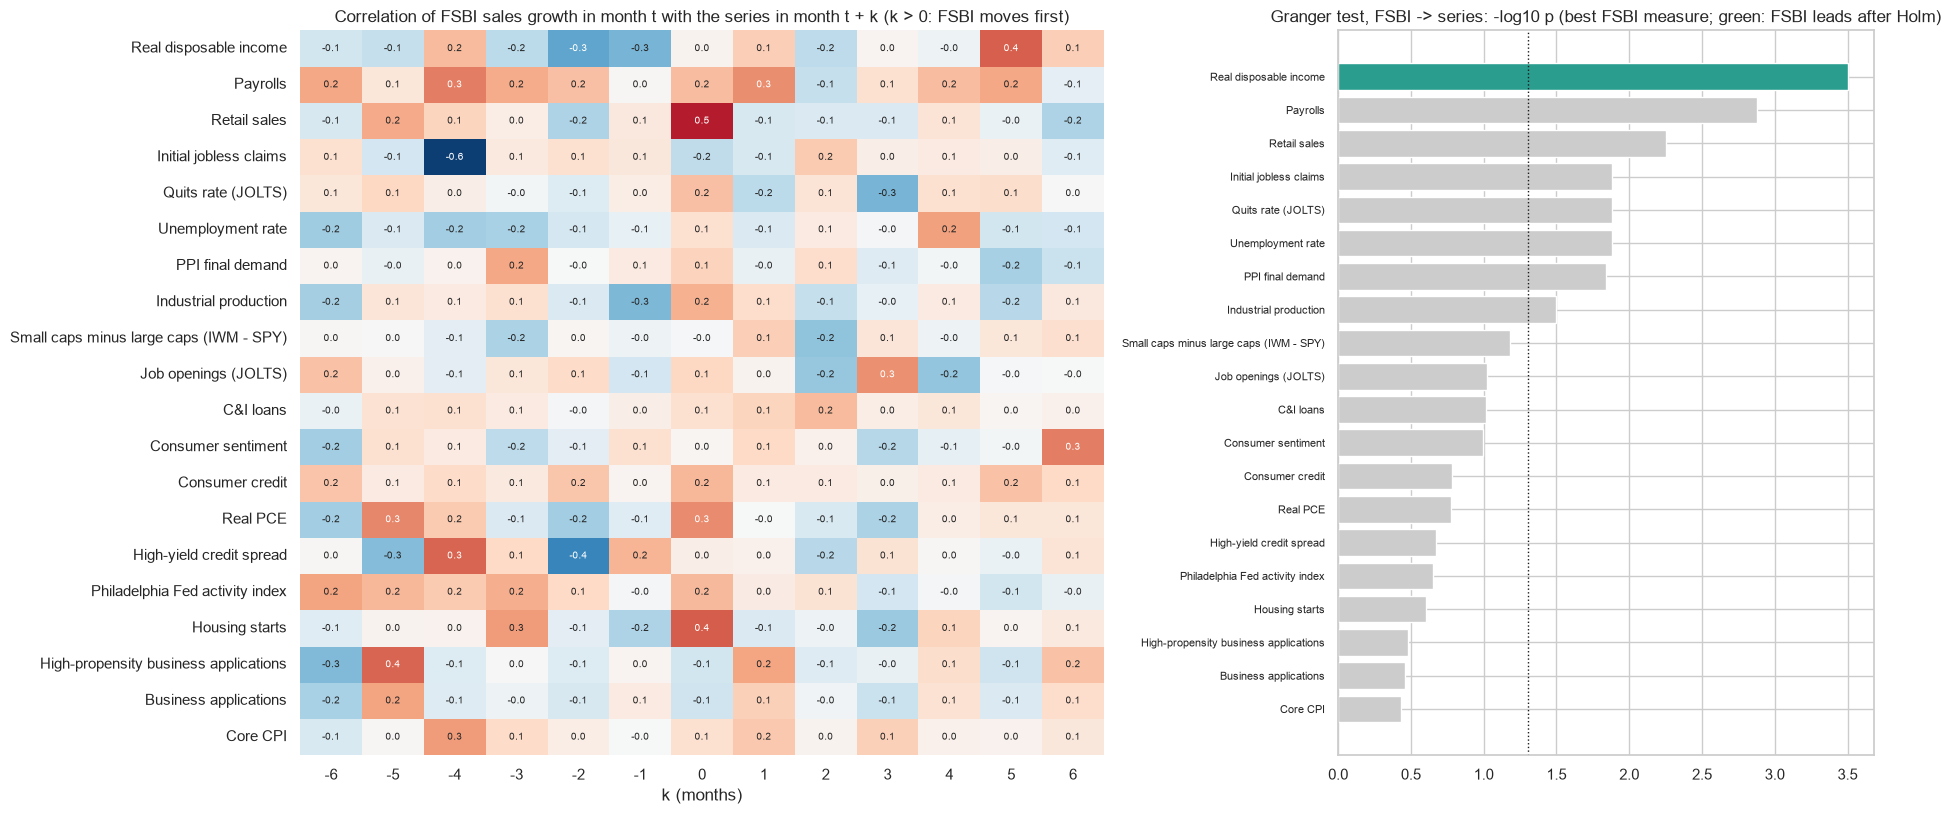

In [68]:
from statsmodels.stats.multitest import multipletests
t0 = time.time()
LEAD_SERIES = {"Initial jobless claims": ("ICSA", "mean", "pct", "labour"), "Payrolls": ("PAYEMS", None, "pct", "labour"), "Unemployment rate": ("UNRATE", None, "diff", "labour"),
               "Job openings (JOLTS)": ("JTSJOL", None, "pct", "labour"), "Quits rate (JOLTS)": ("JTSQUR", None, "diff", "labour"),
               "Business applications": ("BABATOTALSAUS", None, "pct", "business formation"), "High-propensity business applications": ("BAHBATOTALSAUS", None, "pct", "business formation"),
               "C&I loans": ("BUSLOANS", None, "pct", "credit"), "Consumer credit": ("TOTALSL", None, "pct", "credit"), "High-yield credit spread": ("BAMLH0A0HYM2", "mean", "diff", "credit"),
               "Retail sales": ("RSAFS", None, "pct", "activity"), "Real PCE": ("PCEC96", None, "pct", "activity"), "Real disposable income": ("DSPIC96", None, "pct", "activity"),
               "Industrial production": ("INDPRO", None, "pct", "activity"), "Housing starts": ("HOUST", None, "pct", "activity"), "Philadelphia Fed activity index": ("GACDFSA066MSFRBPHI", None, "level", "activity"),
               "Consumer sentiment": ("UMCSENT", None, "diff", "sentiment"), "Core CPI": ("CPILFESL", None, "pct", "prices"), "PPI final demand": ("PPIFIS", None, "pct", "prices")}
LEAD_Y = {}
for name, (sid, how, kind, grp) in LEAD_SERIES.items():
    s = fred_try(sid, how)
    if s is not None:
        s = s.resample("MS").mean() if how is None and s.index.inferred_freq not in ("MS", None) else s
        LEAD_Y[name] = (s.pct_change(fill_method=None) * 100 if kind == "pct" else s.diff() if kind == "diff" else s).reindex(IDX)
if {"IWM", "SPY"} <= set(CLOSE.columns):                      # small caps vs large caps, calendar-month return spread (%)
    _me = CLOSE[["IWM", "SPY"]].resample("MS").last(); LEAD_Y["Small caps minus large caps (IWM - SPY)"] = (_me.IWM.pct_change() - _me.SPY.pct_change()).mul(100).reindex(IDX)
    LEAD_SERIES["Small caps minus large caps (IWM - SPY)"] = ("", None, "pct", "markets")
LEAD_Y = pd.DataFrame(LEAD_Y).mask(pd.Series(in_covid(IDX), index=IDX), axis=0)
LEAD_X = pd.DataFrame({"FSBI sales": g("national", "sales")["US"], "FSBI transactions": g("national", "txn")["US"], "FSBI ticket": g("national", "ticket")["US"],
                       "FSBI state breadth": F["nat"]["breadth_state"], "FSBI sector breadth": F["nat"]["breadth_sector"]}).mask(pd.Series(in_covid(IDX), index=IDX), axis=0)
LAGS = range(-6, 7)

def granger_p(y, x, p=3):
    """F-test that p lags of x add to p lags of y (rows with any gap dropped). Returns (p-value, months)."""
    d = pd.concat({"y": y, **{f"y{i}": y.shift(i) for i in range(1, p + 1)}, **{f"x{i}": x.shift(i) for i in range(1, p + 1)}}, axis=1).dropna()
    if len(d) < 30:
        return np.nan, len(d)
    full = sm.OLS(d.y, sm.add_constant(d.drop(columns="y"))).fit(); restr = sm.OLS(d.y, sm.add_constant(d[[f"y{i}" for i in range(1, p + 1)]])).fit()
    return float(full.compare_f_test(restr)[1]), len(d)

lead_rows, LEAD_CORR = [], {}
for yname in LEAD_Y:
    y = LEAD_Y[yname]
    for xname in LEAD_X:
        x = LEAD_X[xname]; prof = pd.Series({k: x.corr(y.shift(-k)) for k in LAGS})
        p_fwd, n = granger_p(y, x); p_back, _ = granger_p(x, y)
        LEAD_CORR[(yname, xname)] = prof
        lead_rows.append({"series": yname, "group": LEAD_SERIES[yname][3], "FSBI measure": xname, "months": n, "peak lead (months)": int(prof.abs().idxmax()) if prof.notna().any() else np.nan,
                          "corr at peak": float(prof[prof.abs().idxmax()]) if prof.notna().any() else np.nan, "corr, same month": float(prof.get(0, np.nan)), "corr, FSBI 1 month ahead": float(prof.get(1, np.nan)),
                          "Granger p: FSBI -> series": p_fwd, "Granger p: series -> FSBI": p_back})
LEADS = pd.DataFrame(lead_rows)
for c in ("Granger p: FSBI -> series", "Granger p: series -> FSBI"):
    ok_ = LEADS[c].notna(); LEADS.loc[ok_, c.replace("p:", "Holm p:")] = multipletests(LEADS.loc[ok_, c], method="holm")[1]
def lead_verdict(r):
    f, b = r["Granger Holm p: FSBI -> series"] < 0.10, r["Granger Holm p: series -> FSBI"] < 0.10
    return "FSBI leads" if f and not b else "two-way" if f and b else "series leads FSBI" if b else ("coincident" if abs(r["corr, same month"]) >= 0.3 else "no clear link")
LEADS["verdict"] = LEADS.apply(lead_verdict, axis=1)
BEST_LEAD = LEADS.sort_values("Granger p: FSBI -> series").groupby("series").head(1).set_index("series").sort_values("Granger p: FSBI -> series")
display(BEST_LEAD[["group", "FSBI measure", "months", "peak lead (months)", "corr at peak", "corr, FSBI 1 month ahead", "Granger p: FSBI -> series", "Granger Holm p: FSBI -> series", "Granger Holm p: series -> FSBI", "verdict"]].round(3))
print(f"{len(LEADS)} series x FSBI-measure pairs. Holm-adjusted FSBI -> series at p < 0.10: {int((LEADS['Granger Holm p: FSBI -> series'] < 0.10).sum())}; "
      f"verdict counts (best measure per series): {BEST_LEAD.verdict.value_counts().to_dict()}  ({time.time() - t0:.0f}s)")
fig, axes = plt.subplots(1, 2, figsize=(19, max(4.5, 0.34 * len(BEST_LEAD) + 1.5)), gridspec_kw={"width_ratios": [1.5, 1]})
H = pd.DataFrame({s: LEAD_CORR[(s, "FSBI sales")] for s in BEST_LEAD.index}).T
sns.heatmap(H, cmap="RdBu_r", center=0, vmin=-0.6, vmax=0.6, annot=True, fmt=".1f", annot_kws={"size": 7}, cbar=False, ax=axes[0])
axes[0].set_title("Correlation of FSBI sales growth in month t with the series in month t + k (k > 0: FSBI moves first)"); axes[0].set_xlabel("k (months)")
b_ = -np.log10(BEST_LEAD["Granger p: FSBI -> series"].astype(float).clip(lower=1e-12)).iloc[::-1]
axes[1].barh(b_.index, b_.values, color=["#2a9d8f" if v == "FSBI leads" else "#e9c46a" if v == "two-way" else "#cccccc" for v in BEST_LEAD.verdict.iloc[::-1]])
axes[1].axvline(-np.log10(0.05), color="k", ls=":", lw=1); axes[1].set_title("Granger test, FSBI -> series: -log10 p (best FSBI measure; green: FSBI leads after Holm)"); axes[1].tick_params(axis="y", labelsize=8)
plt.tight_layout()

### 3.10 Further macro reads: spending mix, dispersion, revisions, and whether the market reacts to the release

Sections 3.8 and 3.9 test FSBI's headline measures. Four further questions use what only a sector-by-state panel can give:

1. **Spending mix.** Households under pressure cut restaurants, recreation and general retail before groceries, pharmacies and fuel. The gap between year-on-year sales growth at discretionary and at essential small businesses is a consumer-stress gauge available by state and weeks before sentiment surveys.
2. **Dispersion.** The cross-state standard deviation of sales growth measures how uneven the economy is. Rising dispersion with a flat national number is what the start of a regional slowdown looks like.
3. **Price vs volume.** National ticket growth minus transaction growth: positive means revenue is growing through prices, not through customers, which is the small-business version of a margin squeeze.
4. **Acceleration.** Three-month annualised sales growth minus twelve-month growth.

Each indicator in month *t* is tested as a predictor of what happens *next* to unemployment, credit spreads, the 2-year yield, VIX, consumer sentiment and real spending (next month and the next three months, controlling for the target's own latest change). For the daily market series (spreads, yield, VIX) "next month" is measured from FSBI day to the next FSBI day, so no part of the target precedes publication; and of three market spreads over the following FSBI-to-FSBI window. The predictor is each indicator's deviation from its own previous six months, because the levels are persistent and a persistent predictor overstates t-statistics in a sample this short. Newey-West standard errors, Holm adjustment across the whole table, design period only. Because Newey-West errors are too small when both series are persistent and the sample is short, each test also reports a **shift p**: the share of circular shifts of the indicator (by six months or more) that give a t-statistic at least as large. A link counts only if both p-values are small. With about forty months this is a screen for what to watch, not proof.

Two further checks:

- **Revisions.** Advance retail sales are revised. If FSBI growth in a month is above the advance print (both standardised), is the print later revised up? A yes means FSBI keeps its value after the official number is out.
- **The release day.** If markets already treated FSBI as news, prices would move on the release day in the direction of the surprise, and release days would be more volatile than other days. No reaction means the information is not yet priced on arrival, which is the condition every FSBI-day strategy in section 4 relies on.

52 indicator x target x horizon tests; raw p < 0.10: 16 (about 5 expected by chance); Holm p < 0.10: 6; raw p < 0.10 and shift p < 0.10: 7


,FSBI indicator,target,kind,horizon,effect per 1 sd,t-stat,p,months,shift p,Holm p
13,State dispersion (std of state YoY sales growth),"2-year Treasury yield (change, pp)",macro,next 3 months,-0.387,-9.634,0.000,40,0.033,0.000
31,Acceleration (3m annualised - 12m sales growth),Consumer sentiment (change),macro,next 3 months,-2.905,-3.452,0.001,40,0.033,0.028
22,"Price vs volume (ticket - transactions, YoY pp)",VIX (change),macro,next 3 months,2.260,3.274,0.001,40,0.067,0.053
24,"Spending mix (discretionary - essential, YoY pp)",Consumer sentiment (change),macro,next 1 month,1.494,3.123,0.002,40,0.067,0.088
9,State dispersion (std of state YoY sales growth),"2-year Treasury yield (change, pp)",macro,next 1 month,-0.114,-3.084,0.002,40,0.200,0.098
33,State dispersion (std of state YoY sales growth),"Real consumer spending (growth, %)",macro,next 1 month,0.099,3.076,0.002,40,0.033,0.099
1,State dispersion (std of state YoY sales growth),"Unemployment rate (change, pp)",macro,next 1 month,0.045,2.969,0.003,40,0.067,0.137
5,State dispersion (std of state YoY sales growth),"Unemployment rate (change, pp)",macro,next 3 months,0.075,2.939,0.003,40,0.200,0.148
48,"Spending mix (discretionary - essential, YoY pp)","High yield - Treasuries (HYG - IEF, %)",market,FSBI day to next FSBI day,0.805,2.073,0.038,40,0.067,1.000
20,"Spending mix (discretionary - essential, YoY pp)",VIX (change),macro,next 3 months,-1.716,-1.977,0.048,40,0.100,1.000


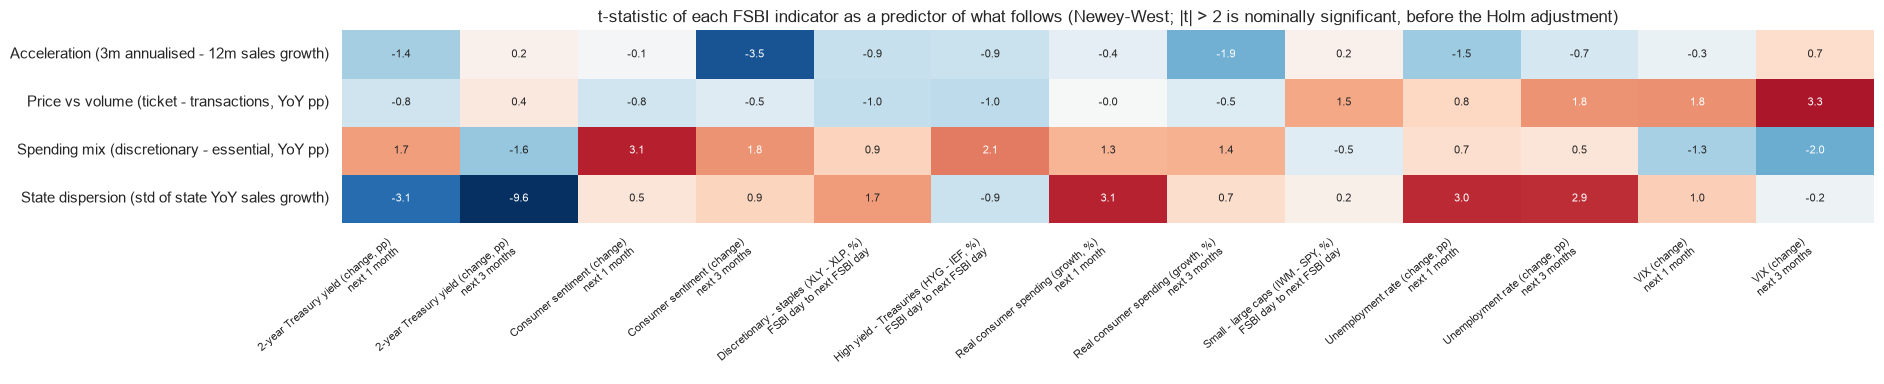

Advance retail sales: later revision (latest vintage minus first print, MoM pp) regressed on the FSBI-minus-print gap


,effect per 1 sd,t-stat,p,months,mean absolute revision (pp)
value,0.271,2.452,0.014,57.0,0.433


FSBI release day: same-day price move against the transaction-growth surprise, and release-day volatility against other days


,move per 1 sd FSBI surprise (bp),t-stat,p,release days,"mean |move|, release days (bp)","mean |move|, other days (bp)",ratio
asset,,,,,,,
S&P 500 (SPY),-4.60,-0.44,0.66,45,68.01,83.04,0.82
Small - large caps (IWM - SPY),-2.70,-0.25,0.81,45,60.10,62.26,0.97
Retailers - market (XRT - SPY),-14.36,-0.85,0.40,45,77.15,94.98,0.81
Discretionary - staples (XLY - XLP),-14.31,-0.75,0.45,45,88.47,91.81,0.96
Long Treasuries (TLT),5.85,0.56,0.58,45,88.76,80.87,1.10
High yield (HYG),-5.80,-1.15,0.25,45,29.25,36.59,0.80


Assets with a significant same-day reaction (p < 0.10): 0 of 6. A ratio near 1 means the release day is an ordinary day for that asset.  (5s)


In [69]:
t0 = time.time(); _cov = pd.Series(in_covid(IDX), index=IDX)
_s12 = pd.concat([g("sector", "sales", 12), g("subsector", "sales", 12)], axis=1); _s12 = _s12.loc[:, ~_s12.columns.duplicated()]
DISCRETIONARY = [c for c in ("Retail", "Accommodation & food", "Arts & recreation", "Other services", "Restaurants", "Clothing", "Furniture", "Electronics") if c in _s12]
ESSENTIAL = [c for c in ("Grocery", "Drug stores", "Gas stations", "Health care") if c in _s12]
_nat = lambda m, k: g("national", m, k)["US"]
MX = {}
if DISCRETIONARY and ESSENTIAL:
    MX["Spending mix (discretionary - essential, YoY pp)"] = _s12[DISCRETIONARY].mean(axis=1) - _s12[ESSENTIAL].mean(axis=1)
MX["State dispersion (std of state YoY sales growth)"] = g("state", "sales", 12).std(axis=1)
MX["Price vs volume (ticket - transactions, YoY pp)"] = _nat("ticket", 12) - _nat("txn", 12)
MX["Acceleration (3m annualised - 12m sales growth)"] = 4 * _nat("sales", 3) - _nat("sales", 12)
MX = pd.DataFrame(MX).reindex(IDX).mask(_cov, axis=0)
MX_DEV = MX - MX.rolling(6, min_periods=4).mean().shift(1)     # each indicator against its own previous six months: levels are persistent, and a persistent predictor overstates t-statistics in a short sample

MACRO_Y = {"Unemployment rate (change, pp)": ("UNRATE", None, "diff"), "High-yield spread (change, pp)": ("BAMLH0A0HYM2", "mean", "diff"), "2-year Treasury yield (change, pp)": ("DGS2", "mean", "diff"),
           "VIX (change)": ("VIXCLS", "mean", "diff"), "Consumer sentiment (change)": ("UMCSENT", None, "diff"), "Real consumer spending (growth, %)": ("PCEC96", None, "pct")}
def pred_reg(y, x, own=None, hac=3, shift=False):
    """OLS of y on standardised x (and optionally the target's own current value) with Newey-West errors."""
    d = pd.concat({"y": y, "x": (x - x.mean()) / x.std(), **({"own": own} if own is not None else {})}, axis=1).dropna()
    if len(d) < 24 or d.x.std() == 0:
        return None
    f = sm.OLS(d.y, sm.add_constant(d.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": hac})
    out = {"effect per 1 sd": float(f.params["x"]), "t-stat": float(f.tvalues["x"]), "p": float(f.pvalues["x"]), "months": int(len(d))}
    if shift:                                               # circular-shift check: slide x against y by 6+ months, which keeps each series' own persistence and breaks the link
        X0 = sm.add_constant(d.drop(columns="y")); ts = []
        for k in range(6, len(d) - 5):
            Xk = X0.copy(); Xk["x"] = np.roll(d.x.values, k); ts.append(abs(sm.OLS(d.y, Xk).fit(cov_type="HAC", cov_kwds={"maxlags": hac}).tvalues["x"]))
        out["shift p"] = float((1 + sum(t >= abs(out["t-stat"]) for t in ts)) / (len(ts) + 1)) if ts else np.nan
    return out

rows_ = []
_evf = EV.fsbi.reindex(IDX)
for yname, (sid, how, kind) in MACRO_Y.items():
    raw = fred_try(sid)
    if raw is None:
        continue
    if how == "mean":                                       # daily market series: change from this FSBI day to the next, so the whole target window follows publication
        lv = raw.reindex(TD, method="ffill"); at = pd.Series(lv.reindex(_evf.values).values, index=IDX)
        y = (at.shift(-1) - at).mask(_cov); own = y.shift(1)              # own = the change over the window that just ended (public on FSBI day)
        fwd_of = lambda h: sum(y.shift(-i) for i in range(0, h))
    else:                                                   # monthly statistics: month t+1 is published after FSBI day for month t
        y = (raw.pct_change(fill_method=None) * 100 if kind == "pct" else raw.diff()).reindex(IDX).mask(_cov); own = y
        fwd_of = lambda h: sum(y.shift(-i) for i in range(1, h + 1))
    for h in (1, 3):
        fwd = fwd_of(h)
        for xname in MX:
            r = pred_reg(pre(fwd), pre(MX_DEV[xname]), own=pre(own), hac=h + 2, shift=True)
            if r:
                rows_.append({"FSBI indicator": xname, "target": yname, "kind": "macro", "horizon": f"next {h} month{'s' if h > 1 else ''}", **r})
_ev = EV.loc[EV.index.intersection(TRADE_MONTHS)].dropna(subset=["fsbi", "next_fsbi"])
_wr = lambda t: pd.Series(CLOSE.loc[_ev.next_fsbi, t].values / CLOSE.loc[_ev.fsbi, t].values - 1, index=_ev.index) * 100
for yname, (a, b) in {"Discretionary - staples (XLY - XLP, %)": ("XLY", "XLP"), "Small - large caps (IWM - SPY, %)": ("IWM", "SPY"), "High yield - Treasuries (HYG - IEF, %)": ("HYG", "IEF")}.items():
    if a in CLOSE and b in CLOSE:
        for xname in MX:
            r = pred_reg(pre(_wr(a) - _wr(b)), pre(MX_DEV[xname]), hac=2, shift=True)
            if r:
                rows_.append({"FSBI indicator": xname, "target": yname, "kind": "market", "horizon": "FSBI day to next FSBI day", **r})
MACRO_READS = pd.DataFrame(rows_)
if len(MACRO_READS):
    MACRO_READS["Holm p"] = multipletests(MACRO_READS.p, method="holm")[1]
    print(f"{len(MACRO_READS)} indicator x target x horizon tests; raw p < 0.10: {int((MACRO_READS.p < 0.10).sum())} (about {0.1 * len(MACRO_READS):.0f} expected by chance); Holm p < 0.10: {int((MACRO_READS['Holm p'] < 0.10).sum())}; "
          f"raw p < 0.10 and shift p < 0.10: {int(((MACRO_READS.p < 0.10) & (MACRO_READS['shift p'] < 0.10)).sum())}")
    display(MACRO_READS.sort_values("p").head(12).round(3))
    T_ = MACRO_READS.assign(col=MACRO_READS.target + " | " + MACRO_READS.horizon).pivot_table(index="FSBI indicator", columns="col", values="t-stat", aggfunc="first")
    fig, ax = plt.subplots(figsize=(19, 1.2 + 0.7 * len(T_)))
    sns.heatmap(T_, cmap="RdBu_r", center=0, vmin=-4, vmax=4, annot=True, fmt=".1f", annot_kws={"size": 8}, cbar=False, ax=ax)
    ax.set_title("t-statistic of each FSBI indicator as a predictor of what follows (Newey-West; |t| > 2 is nominally significant, before the Holm adjustment)"); ax.set_xlabel(""); ax.set_ylabel("")
    ax.set_xticklabels([t.get_text().replace(" | ", "\n") for t in ax.get_xticklabels()], rotation=40, ha="right", fontsize=8); plt.tight_layout(); plt.show()

# Revisions: does FSBI say which way the advance retail sales print will be revised?
REVISION = None
_rs_latest = fred_try("RSAFS")
if RS.notna().sum() >= 24 and _rs_latest is not None:
    rev = ((_rs_latest.pct_change(fill_method=None) * 100).reindex(IDX) - RS).mask(_cov)
    zf = lambda x: (x - x.mean()) / x.std()
    gap = zf(_nat("sales", 1).mask(_cov)) - zf(RS.mask(_cov))
    REVISION = pred_reg(pre(rev), pre(gap))
    if REVISION:
        REVISION["mean absolute revision (pp)"] = float(pre(rev).abs().mean())
        print("Advance retail sales: later revision (latest vintage minus first print, MoM pp) regressed on the FSBI-minus-print gap"); display(pd.Series(REVISION).round(3).to_frame("value").T)

# The release day: do prices move with the FSBI surprise, and are release days unusual?
_dr = CLOSE.pct_change(fill_method=None) * 100; _fd = EV.loc[TRADE_MONTHS.intersection(pre(EV).index), "fsbi"].dropna()
_zs = expanding_z(_nat("txn", 1).mask(_cov)); ev_rows = []
for lab, (a, b) in {"S&P 500 (SPY)": ("SPY", None), "Small - large caps (IWM - SPY)": ("IWM", "SPY"), "Retailers - market (XRT - SPY)": ("XRT", "SPY"), "Discretionary - staples (XLY - XLP)": ("XLY", "XLP"),
                    "Long Treasuries (TLT)": ("TLT", None), "High yield (HYG)": ("HYG", None)}.items():
    if a not in _dr or (b and b not in _dr):
        continue
    d_ = (_dr[a] - (_dr[b] if b else 0)).dropna(); on = pd.Series(d_.reindex(_fd.values).values, index=_fd.index)
    r = pred_reg(on, _zs.reindex(on.index), hac=1); other = d_.loc[(d_.index >= _fd.min()) & (d_.index <= _fd.max()) & ~d_.index.isin(_fd.values)]
    if r:
        ev_rows.append({"asset": lab, "move per 1 sd FSBI surprise (bp)": 100 * r["effect per 1 sd"], "t-stat": r["t-stat"], "p": r["p"], "release days": r["months"],
                        "mean |move|, release days (bp)": 100 * on.abs().mean(), "mean |move|, other days (bp)": 100 * other.abs().mean(), "ratio": on.abs().mean() / other.abs().mean()})
FSBI_EVENT = pd.DataFrame(ev_rows)
if len(FSBI_EVENT):
    print("FSBI release day: same-day price move against the transaction-growth surprise, and release-day volatility against other days"); display(FSBI_EVENT.set_index("asset").round(2))
    print(f"Assets with a significant same-day reaction (p < 0.10): {int((FSBI_EVENT.p < 0.10).sum())} of {len(FSBI_EVENT)}. A ratio near 1 means the release day is an ordinary day for that asset.  ({time.time() - t0:.0f}s)")

## 4. Trading strategies

Each strategy family starts from a published finding (or, where marked *own construction*, from an economic argument made here), states the FSBI signal that should exploit it, and runs through the same engine. Two kinds of signal are used, as the brief allows: the **inflation forecast** from section 3 (families A and F) and **raw FSBI** series (families B to E).

| | family | research basis | FSBI signal | instruments | holding period |
|---|---|---|---|---|---|
| A | Announcement surprise | Asset prices move on the *surprise* in a macro release: Balduzzi, Elton & Green (2001); Gürkaynak, Kısacıkoğlu & Wright (2020). Stocks fall on hot CPI, most for firms without pricing power: Knox & Timmer (2025). Core inflation is what is priced across assets: Fang, Liu & Roussanov (2022) | selected forecast − market expectation | TLT, QQQ, UUP, SPY vs IWM | close before the release → release close |
| B | Inflation regime | Demand- vs supply-driven inflation: Shapiro (2022, 2024). "Good" vs "bad" inflation for stocks and bonds: Cieslak & Pflueger (2023). What works in inflationary regimes: Neville, Draaisma, Funnell, Harvey & Van Hemert (2021) | share of sectors in demand-pull / supply-squeeze | TIP vs IEF, DBC vs TLT, XLP vs XLY, SPY vs IWM | FSBI day → next FSBI day |
| C | Sector demand rotation | Card spending predicts firm revenue and returns before earnings: Agarwal, Qian & Zou (2021); Froot, Kang, Ozik & Sadka (2017). Industry information diffuses slowly: Hong, Torous & Valkanov (2007). Market power shields firms: Knox & Timmer (2025) | sub-sector transaction surprise, acceleration, pricing power | 10 sector ETFs, long/short | FSBI day → next FSBI day |
| D | Local economy → local banks | State economic conditions predict local stock returns: Korniotis & Kumar (2013); Smajlbegovic (2019) | state sales growth, by bank headquarters | 30 regional banks, long/short | FSBI day → next FSBI day |
| E | Small-business cycle → small caps | Small firms are more exposed to demand and credit conditions: Gertler & Gilchrist (1994); real-time sales data lead fundamentals: Froot et al. (2017) | national and retail transaction surprise | IWM vs SPY, XRT vs SPY | FSBI day → next FSBI day |
| G | Retail-sales announcement | Card transactions track Census retail sales in real time: Aladangady et al. (2022); prices move on activity surprises as well as inflation surprises: Balduzzi, Elton & Green (2001) | FSBI-based forecast of the advance retail sales print vs an AR expectation | XLY vs XLP, TLT, XRT vs SPY | close before the release → release close |
| H | Options and volatility | Implied volatility is bid up before macro releases and falls once the number is out: Beber & Brandt (2006); Ederington & Lee (1993) | size of the predicted CPI surprise | SPY straddle (modelled from VIX), SVXY | close before the release → release close |
| I | FX and commodities | Exchange rates respond to US macro news through the rate differential: Andersen, Bollerslev, Diebold & Vega (2003); real assets and inflation regimes: Neville et al. (2021) | demand-pull share, national and fuel demand surprise | UUP vs FXY, CPER vs GLD, UGA | FSBI day → next FSBI day |
| J | TIPS on the inflation forecast | Breakevens move on CPI news: Gürkaynak, Levin & Swanson (2010); TIPS are indexed to non-seasonally-adjusted CPI with a lag, so a better read on the next print is a read on the next accrual: Fleckenstein, Longstaff & Lustig (2014) | forecast vs breakeven (carried over from earlier drafts); forecast vs the market's expectation of the print (improved) | STIP vs SHY, TIP vs IEF | FSBI day → release / next FSBI day |
| K | Small-cap sectors by FSBI classification | Information reaches small firms' prices with a delay: Hou & Moskowitz (2005); Hong, Lim & Stein (2000). Small firms are more exposed to their sector's demand: Gertler & Gilchrist (1994) | FSBI sector and regional demand surprise, mapped from FSBI's industry classification to small-cap sector funds | S&P SmallCap 600 sector ETFs, small-minus-large spreads, regional bank baskets | FSBI day → next FSBI day |
| L | Fixed income: credit and rating | Corporate bonds carry inflation risk through their nominal coupons and through default: Kang & Pflueger (2015). Credit spreads price the business cycle: Gilchrist & Zakrajšek (2012). Long bonds lose on unexpected inflation: Chang & Pinegar (1986). Inflation disagreement overprices the long bond: Hong, Sraer & Yu (2017) | CPI forecast vs nowcast; FSBI demand-pull vs supply-squeeze; change in state breadth; dispersion of FSBI price growth | STIP, IGSB, VCSH, VCLT, LQD, HYG, IEF, TLT, SHY | FSBI day → CPI release, or → next FSBI day |
| F | Prediction markets | Prediction-market prices as probabilities: Wolfers & Zitzewitz (2004); Kalshi's macro markets: Diercks, Katz & Wright (2026); bet sizing: Kelly (1956) | model distribution vs Kalshi ladder | Kalshi CPI / core CPI / core PCE contracts | FSBI day → settlement |

Full references are listed at the end of the notebook.

**On the goal of statistically significant returns.** Significance cannot be engineered by trying more variants: every extra strategy raises the bar the best one has to clear. What *can* legitimately raise the odds is (1) signals with a clear economic prior, (2) composites that average several noisy readings of the same idea, (3) breadth (many assets per trade) and (4) combining weakly correlated strategies. The second round of strategies added below follows those four routes, and the leaderboard carries three guards: Holm, a joint **reality-check** bootstrap, and the untouched holdout as the final confirmation.

**Rules shared by every strategy.** Signals use only data available at entry (z-scores are against earlier months). Entry and exit are at the close. ETF trades pay 5 bp per side on gross exposure; Kalshi trades fill at the quoted ask (or 1 − bid) and pay Kalshi's fee. COVID months and the holdout are not traded. Long/short books have gross exposure of 1.

### 4.0 The backtest engine

A strategy is a list of trades `(reference month, entry date, exit date, {ticker: weight})`. `run_book` turns any such list into daily net returns, which is all the leaderboard, risk overlays and Monte Carlo need. Two helpers build the lists: `timing_trades` (one position, long or short, sized by a signal's sign) and `xs_trades` (rank a cross-section, long the top third, short the bottom third). Each has a **placebo**: the same trades with the signal shuffled, which tests whether the signal, and not the instruments, earned the return.

In [70]:
def run_book(trades, stop=None, delay=0, cost=COST):
    """Daily net returns of a list of trades, and each trade's own return. `stop` exits a trade at the first close below -stop;
    `delay` enters that many trading days late (an execution-lag stress test)."""
    daily, per = pd.Series(0.0, index=TD), {}
    for tr in trades:
        if pd.isna(tr["entry"]) or pd.isna(tr["exit"]):
            continue
        i, j = TDPOS[tr["entry"]] + delay, TDPOS[tr["exit"]]
        w = pd.Series(tr["w"], dtype=float); w = w[w != 0]
        if j <= i or w.empty or not set(w.index) <= set(CLOSE.columns) or CLOSE.iloc[i][list(w.index)].isna().any():
            continue                                         # a ticker that stops trading inside the window keeps its return to the last close
        r = (RET.iloc[i + 1:j + 1][list(w.index)].fillna(0.0) * w).sum(axis=1)
        if stop is not None:
            hit = np.flatnonzero(((1 + r).cumprod() - 1).values <= -stop)
            if len(hit):
                r = r.iloc[:hit[0] + 1]
        r = r.copy(); r.iloc[0] -= cost * w.abs().sum(); r.iloc[-1] -= cost * w.abs().sum()
        daily.loc[r.index] += r.values; per[tr["ref"]] = float((1 + r).prod() - 1)
    return daily, pd.Series(per, dtype=float)

def growth(m):
    """Growth of $1 from a monthly return series, starting at exactly 1.0 at the end of the month before the first return."""
    m = m.dropna()
    if m.empty:
        return m
    return pd.concat([pd.Series([1.0], index=[m.index[0] - pd.offsets.MonthBegin(1)]), (1 + m).cumprod()])

def to_monthly(daily):
    """Calendar-month returns between the first and last active day (idle months inside that span count as zero)."""
    act = daily[daily != 0]
    if act.empty:
        return pd.Series(dtype=float)
    d = daily.loc[act.index[0]:act.index[-1]]
    m = (1 + d).groupby(d.index.to_period("M")).prod() - 1; m.index = m.index.to_timestamp()
    return m[~((m == 0) & in_covid(m.index))]              # the untraded COVID gap is dropped, not counted as zero-return months

def window_ret(tickers, entry_col="fsbi", exit_col="next_fsbi"):
    """Close-to-close return of each ticker over each month's holding window (reference month x ticker)."""
    ev = EV.loc[EV.index.intersection(TRADE_MONTHS)].dropna(subset=[entry_col, exit_col]); tickers = [t for t in tickers if t in CLOSE]
    return pd.DataFrame(CLOSE.loc[ev[exit_col], tickers].values / CLOSE.loc[ev[entry_col], tickers].values - 1, index=ev.index, columns=tickers)

def timing_trades(pos, legs, entry_col="fsbi", exit_col="next_fsbi"):
    """pos: +1 / -1 / 0 by reference month. legs: the book held when pos = +1 (reversed when -1)."""
    pos = pos.reindex(TRADE_MONTHS).dropna()
    return [{"ref": t, "entry": EV.at[t, entry_col], "exit": EV.at[t, exit_col], "w": {a: p * w for a, w in legs.items()}} for t, p in pos.items() if p != 0]

def timing_placebo(pos, legs, entry_col="fsbi", exit_col="next_fsbi", n=None):
    """Share of signal shuffles (across months) whose mean trade return is at least the actual one."""
    n = n or (200 if FAST else 1000)
    if not set(legs) <= set(CLOSE.columns):
        return np.nan
    unit = (window_ret(list(legs), entry_col, exit_col) * pd.Series(legs)).sum(axis=1, min_count=len(legs))
    d = pre(pd.concat([pos.rename("p"), unit.rename("u")], axis=1).dropna())
    if len(d) < 12:
        return np.nan
    actual = (d.p * d.u).mean()
    return float((1 + sum((rng.permutation(d.p.to_numpy(copy=True)) * d.u.values).mean() >= actual for _ in range(n))) / (n + 1))

def xs_weights(sig_row, frac=1 / 3, min_n=6):
    s = sig_row.dropna()
    if len(s) < min_n:
        return {}
    n = max(1, int(round(len(s) * frac))); o = s.sort_values(kind="stable")
    return {**{a: 0.5 / n for a in o.index[-n:]}, **{a: -0.5 / n for a in o.index[:n]}}

def xs_trades(signal, entry_col="fsbi", exit_col="next_fsbi", **kw):
    """signal: reference month x ticker. Long the top third, short the bottom third, equal-weighted, gross exposure 1."""
    out = []
    for t in signal.index.intersection(TRADE_MONTHS):
        px_ok = [a for a in signal.columns if a in CLOSE and pd.notna(EV.at[t, entry_col]) and pd.notna(CLOSE.at[EV.at[t, entry_col], a])]
        w = xs_weights(signal.loc[t, px_ok], **kw)
        if w:
            out.append({"ref": t, "entry": EV.at[t, entry_col], "exit": EV.at[t, exit_col], "w": w})
    return out

def xs_placebo(signal, entry_col="fsbi", exit_col="next_fsbi", n=None, **kw):
    """Share of within-month shuffles of the signal across tickers whose mean long-short return is at least the actual one."""
    n = n or (100 if FAST else 500); R = pre(window_ret(list(signal.columns), entry_col, exit_col)); S = signal.reindex(index=R.index, columns=R.columns)
    def mean_ls(shuffle):
        v = []
        for t in R.index:
            s = S.loc[t].dropna(); s = s[R.loc[t, s.index].notna()]
            if shuffle:
                s = pd.Series(rng.permutation(s.to_numpy(copy=True)), index=s.index)
            w = xs_weights(s, **kw)
            if w:
                v.append(sum(R.at[t, a] * x for a, x in w.items()))
        return np.mean(v) if v else np.nan
    actual = mean_ls(False)
    return float((1 + sum(mean_ls(True) >= actual for _ in range(n))) / (n + 1)) if np.isfinite(actual) else np.nan

STRATS, CONTROLS = {}, {}
def tspec(signal, legs, entry="fsbi", exit="next_fsbi", deadband=0.0):
    """Recipe of a timing strategy: the continuous signal whose sign sets the position, the book held when it is positive, and the window."""
    return {"type": "timing", "signal": pd.Series(signal, dtype=float), "legs": legs, "entry": entry, "exit": exit, "deadband": deadband}
def register(name, family, trades=None, daily=None, per=None, placebo=np.nan, store=None, spec=None, min_trades=6):
    """Run the trades and file the strategy. `store=CONTROLS` files a comparison strategy that is kept off the leaderboard."""
    if trades is not None:
        daily, per = run_book(trades)
    if per is None or len(per) < min_trades:
        print(f"  [{family}] {name}: fewer than {min_trades} trades ({0 if per is None else len(per)}); not registered (missing prices or signal?)."); return None
    (STRATS if store is None else store)[name] = {"family": family, "trades": trades, "daily": daily, "per": per, "placebo": placebo, "spec": spec}
    return per
def trade_stats(per):
    per = pre(pd.Series(per, dtype=float).dropna())             # design period only
    if len(per) < 3:
        return {"trades": len(per)}
    return {"trades": len(per), "mean (bp)": 1e4 * per.mean(), "hit rate": float((per > 0).mean()), "t-stat": per.mean() / per.std() * np.sqrt(len(per)) if per.std() > 0 else np.nan, "total (%)": 100 * ((1 + per).prod() - 1)}
family_table = lambda fam, store=None: pd.DataFrame({n: {**trade_stats(s["per"]), "placebo p": s["placebo"]} for n, s in (STRATS if store is None else store).items() if s["family"] == fam}).T
print(f"engine ready | {len(TRADE_MONTHS)} tradable months | missing instruments: {sorted(set(sum(UNIVERSE.values(), [])) - set(CLOSE.columns)) or 'none'}")

engine ready | 78 tradable months | missing instruments: none


### 4.A Announcement surprise: trade the forecast against the market's expectation

**Research.** Bond, equity and currency prices respond to the *unexpected* part of a macro release within minutes, and the response to CPI is among the largest (Balduzzi, Elton & Green, 2001; Gürkaynak, Kısacıkoğlu & Wright, 2020). A hot print lifts yields and the dollar and hurts equities, with firms that lack pricing power hit hardest (Knox & Timmer, 2025), which motivates a large-vs-small leg.

**Signal.** `predicted surprise = forecast − market expectation`, where the expectation is Kalshi's median on the eve of the release where it exists and the last Cleveland nowcast otherwise. The forecast is made on FSBI day, about a week earlier, so its adjustment to the nowcast (`SEL − NC`) is carried onto the eve-of-release nowcast; otherwise the signal would mostly measure how far public information moved in that week. If the predicted surprise is hot (above a 0.01pp dead-band): short TLT, short QQQ, long UUP, long SPY / short IWM; the reverse if cool. Enter at the close before the release, exit at the release-day close.

**A2 (own construction).** The same basket for core CPI, entered on FSBI day instead of the eve of the release and sized by the sign of the model's adjustment to the nowcast. If the information in FSBI reaches prices gradually over that week, the early entry should earn more than the one-day trade.

**Three versions on identical months**, following Team 2's attribution design: the *ideal* signal uses the actual print (look-ahead: the ceiling a perfect forecast would reach), *with FSBI* uses `SEL`, *without FSBI* uses the twin forecast. The gap between the last two is FSBI's contribution; the gap to the ideal is what better forecasting could still earn.

In [71]:
ANN_LEGS = {"Duration: short TLT": {"TLT": -1.0}, "Equities: short QQQ": {"QQQ": -1.0}, "Dollar: long UUP": {"UUP": 1.0}, "Size: long SPY / short IWM": {"SPY": 0.5, "IWM": -0.5}}
ANN_LEGS["Basket (equal weight of the four)"] = {a: w / len(ANN_LEGS) for legs in list(ANN_LEGS.values()) for a, w in legs.items()}
DEADBAND = 0.01
def surprise_pos(fcast, k):
    s = (fcast - EXPECT[k]).reindex(SEL[k].index.intersection(TRADE_MONTHS))
    return np.sign(s).where(s.abs() > DEADBAND, 0.0).where(s.notna())
refresh = lambda fc, k: NC_EVE[k] + (fc - NC[k])           # carry the model's adjustment from FSBI day onto the latest public nowcast
ann = {}
for k in ("core_cpi", "cpi", "core_pce"):
    variants = {"ideal (look-ahead)": Y[k], "with FSBI": refresh(SEL[k], k), "without FSBI": refresh(SEL_NOFSBI[k], k)}
    for leg_name, legs in ANN_LEGS.items():
        for vname, fc in variants.items():
            pos = surprise_pos(fc, k); trades = timing_trades(pos, legs, f"{k}_pre", f"{k}_rel")
            per = run_book(trades)[1]; ann[(LABEL[k], leg_name, vname)] = trade_stats(per)
            if leg_name.startswith("Basket") and vname != "ideal (look-ahead)":
                register(f"A. Surprise basket on {LABEL[k]}" + ("" if vname == "with FSBI" else " [no-FSBI twin]"), "A. Announcement surprise", trades,
                         placebo=timing_placebo(pos, legs, f"{k}_pre", f"{k}_rel"), store=None if vname == "with FSBI" else CONTROLS, spec=tspec(fc - EXPECT[k], legs, f"{k}_pre", f"{k}_rel", DEADBAND))
if "core_cpi" in SEL:                                      # own construction: enter a week earlier, on FSBI day, to test for drift into the release
    pos = np.sign(SEL["core_cpi"] - NC["core_cpi"]).reindex(SEL["core_cpi"].index.intersection(TRADE_MONTHS)); legs = ANN_LEGS["Basket (equal weight of the four)"]
    register("A2. Surprise basket on core CPI, entered on FSBI day", "A. Announcement surprise", timing_trades(pos, legs, "fsbi", "core_cpi_rel"), placebo=timing_placebo(pos, legs, "fsbi", "core_cpi_rel"), spec=tspec(SEL["core_cpi"] - NC["core_cpi"], legs, "fsbi", "core_cpi_rel"))
ANN_TAB = pd.DataFrame(ann).T
if "mean (bp)" in ANN_TAB:
    print("Mean net return per release (bp), by asset and signal version:")
    display(ANN_TAB["mean (bp)"].unstack().reindex(columns=["ideal (look-ahead)", "with FSBI", "without FSBI"]).round(1))
    print("Hit rate:"); display(ANN_TAB["hit rate"].unstack().reindex(columns=["ideal (look-ahead)", "with FSBI", "without FSBI"]).round(2))
    b = ANN_TAB.xs("Basket (equal weight of the four)", level=1)["mean (bp)"].unstack()
    print("Reading the basket rows: 'ideal' > 0 means the surprise is tradable in principle; 'with FSBI' > 'without FSBI' means FSBI moved the forecast in the right direction on release days.")
display(family_table("A. Announcement surprise"))

Mean net return per release (bp), by asset and signal version:


ideal (look-ahead)  with FSBI  without FSBI
CPI      Basket (equal weight of the four)                25.6       -9.7          13.3
         Dollar: long UUP                                 19.3       -9.9           4.7
         Duration: short TLT                              54.6      -12.4          17.5
         Equities: short QQQ                               5.6        0.5          25.4
         Size: long SPY / short IWM                       23.2      -17.1           5.6
core CPI Basket (equal weight of the four)                32.8       -5.6          11.1
         Dollar: long UUP                                 26.1      -15.7          -5.8
         Duration: short TLT                              74.8        5.1          12.0
         Equities: short QQQ                              -2.1       -1.4          38.2
         Size: long SPY / short IWM                       32.4      -10.3          -0.0
core PCE Basket (equal weight of the four)               -19.3      -10.8         -25.5
         Dollar: long UUP                                -11.8      -17.3         -15.8
         Duration: short TLT                             -42.0       -7.9         -34.1
         Equities: short QQQ                             -12.7      -19.7         -48.4
         Size: long SPY / short IWM                      -10.5        1.6          -3.8

Hit rate:


ideal (look-ahead)  with FSBI  without FSBI
CPI      Basket (equal weight of the four)                0.50       0.26          0.44
         Dollar: long UUP                                 0.55       0.42          0.50
         Duration: short TLT                              0.64       0.37          0.50
         Equities: short QQQ                              0.59       0.47          0.61
         Size: long SPY / short IWM                       0.59       0.37          0.56
core CPI Basket (equal weight of the four)                0.52       0.39          0.41
         Dollar: long UUP                                 0.57       0.43          0.41
         Duration: short TLT                              0.71       0.52          0.45
         Equities: short QQQ                              0.48       0.43          0.55
         Size: long SPY / short IWM                       0.67       0.52          0.50
core PCE Basket (equal weight of the four)                0.29       0.41          0.30
         Dollar: long UUP                                 0.33       0.18          0.20
         Duration: short TLT                              0.29       0.55          0.40
         Equities: short QQQ                              0.43       0.41          0.35
         Size: long SPY / short IWM                       0.24       0.55          0.45

Reading the basket rows: 'ideal' > 0 means the surprise is tradable in principle; 'with FSBI' > 'without FSBI' means FSBI moved the forecast in the right direction on release days.


,trades,mean (bp),hit rate,t-stat,total (%),placebo p
A. Surprise basket on core CPI,23.0,-5.597036,0.391304,-0.367632,-1.337489,0.319680
A. Surprise basket on CPI,19.0,-9.719777,0.263158,-0.561049,-1.880990,0.485514
A. Surprise basket on core PCE,22.0,-10.834249,0.409091,-1.146806,-2.376777,0.822178
"A2. Surprise basket on core CPI, entered on FSBI day",24.0,-32.265001,0.416667,-1.819290,-7.543913,0.898102


### 4.B Inflation regime from FSBI's demand / supply split

**Research.** Shapiro (2022, 2024) splits inflation into demand- and supply-driven parts by whether price and quantity surprises in a category share a sign. Cieslak & Pflueger (2023) show why the split matters for assets: demand-driven ("good") inflation comes with growth and hurts bonds more than stocks; supply-driven ("bad") inflation hurts both and favours defensives. Neville et al. (2021) find commodities and inflation-linked bonds are what hold up when inflation rises.

**Signal.** FSBI gives the split weeks before official sector data (section 1.6). Each is z-scored against its own history:

| strategy | when the z-score is positive | else |
|---|---|---|
| B1 breakeven | price pressure is broad (demand-pull + supply-squeeze share high) → long TIP, short IEF | reverse |
| B2 real assets vs duration | demand-pull is high → long DBC, short TLT | reverse |
| B3 defensives vs cyclicals | supply-squeeze is high → long XLP, short XLY | reverse |
| B4 large vs small | supply-squeeze is high → long SPY, short IWM | reverse |
| B5 duration (own construction) | nominal sales growth is above its history (growth and prices together are what move yields) → long SHY, short TLT | reverse |

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
B1. Breakeven (TIP vs IEF) on broad price pressure,42.0,-8.261434,0.404762,-0.740340,-3.515241,0.494505
B2. Real assets vs duration (DBC vs TLT) on demand-pull,42.0,5.099143,0.476190,0.068959,-2.501486,0.404595
B3. Staples vs discretionary (XLP vs XLY) on supply-squeeze,42.0,58.823378,0.547619,1.085776,24.766432,0.094905
B4. Large vs small caps (SPY vs IWM) on supply-squeeze,42.0,1.691631,0.452381,0.060238,0.036021,0.528472
B5. Short duration (SHY vs TLT) on nominal activity surprise,45.0,25.831018,0.511111,0.715382,10.886362,0.093906


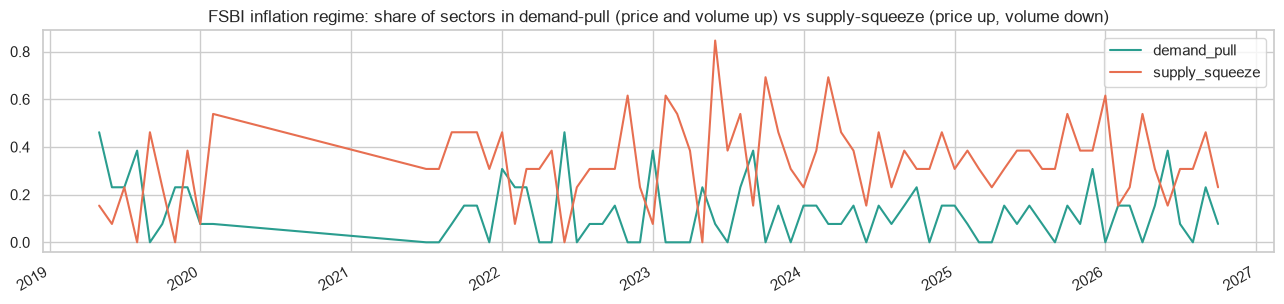

In [72]:
_sh = SHAPIRO.mask(pd.Series(in_covid(IDX), index=IDX), axis=0)                   # COVID months are kept out of the history every z-score is measured against
z_dp, z_ss = expanding_z(_sh.demand_pull), expanding_z(_sh.supply_squeeze); z_pp = expanding_z(_sh.demand_pull + _sh.supply_squeeze)
REGIME = {"B1. Breakeven (TIP vs IEF) on broad price pressure": (z_pp, {"TIP": 0.5, "IEF": -0.5}), "B2. Real assets vs duration (DBC vs TLT) on demand-pull": (z_dp, {"DBC": 0.5, "TLT": -0.5}),
          "B3. Staples vs discretionary (XLP vs XLY) on supply-squeeze": (z_ss, {"XLP": 0.5, "XLY": -0.5}), "B4. Large vs small caps (SPY vs IWM) on supply-squeeze": (z_ss, {"SPY": 0.5, "IWM": -0.5}),
          "B5. Short duration (SHY vs TLT) on nominal activity surprise": (expanding_z(g("national", "sales")["US"].mask(in_covid(IDX))), {"SHY": 0.5, "TLT": -0.5})}
for name, (z, legs) in REGIME.items():
    pos = np.sign(z); register(name, "B. Inflation regime", timing_trades(pos, legs), placebo=timing_placebo(pos, legs), spec=tspec(z, legs))
fig, ax = plt.subplots(figsize=(13, 3.2))
SHAPIRO.loc[~in_covid(IDX)].plot(ax=ax, color=["#2a9d8f", "#e76f51"]); ax.set_title("FSBI inflation regime: share of sectors in demand-pull (price and volume up) vs supply-squeeze (price up, volume down)"); ax.set_xlabel("")
plt.tight_layout(); display(family_table("B. Inflation regime"))

### 4.C Sector demand rotation

**Research.** Agarwal, Qian & Zou (2021) show that card-spending growth at a firm predicts its returns, because disaggregated sales reach prices more slowly than earnings do; Froot et al. (2017) find the same with real-time sales proxies; Hong, Torous & Valkanov (2007) document slow diffusion of industry information. FSBI is card spending by industry, so the sector-level analogue is a long/short rotation.

**Signals** (FSBI sub-sectors averaged within the ETF they map to, section 1.1):

- **C1 demand surprise**: transaction growth, z-scored against the sub-sector's own history.
- **C2 demand acceleration**: transaction growth minus its previous three-month average.
- **C3 pricing power**: the smaller of the ticket and transaction z-scores, high only when prices rise *and* customers stay, the profile Knox & Timmer (2025) find is rewarded when inflation surprises.

Second round, aimed at a cleaner signal and a cleaner instrument:

- **C4 composite**: the average cross-sectional rank of C1 to C3. Averaging three noisy readings of the same idea is the standard way to raise signal-to-noise without adding a free parameter.
- **C5 broad sectors** (own construction): FSBI's thirteen top-level sectors mapped to the eight liquid SPDR sector funds, on a demand composite (average z-score of transaction and sales growth).
- **C6 pure-play baskets**: equal-weighted baskets of listed pure-plays for each sub-sector (restaurants, hotels, grocers, auto dealers and so on) replace the sector ETFs, most of which mix several FSBI sub-sectors. These are large chains, so the test is whether small-business demand in an industry carries over to its listed leaders.

Long the top third of sector ETFs (or baskets), short the bottom third, FSBI day to the next FSBI day. The placebo shuffles the signal across ETFs within each month.

In [73]:
etf_of = ENTITY.etf.dropna(); etf_of = etf_of[etf_of.isin(CLOSE.columns)]
to_etf = lambda df: pd.DataFrame({e: df[[x for x in etf_of.index[etf_of == e] if x in df]].mean(axis=1) for e in sorted(etf_of.unique())})
no_covid = lambda df: df.mask(pd.Series(in_covid(df.index), index=df.index), axis=0)
z_txn, z_tkt = no_covid(tx).apply(expanding_z), no_covid(tk).apply(expanding_z)
SECTOR_SIG = {"C1. Sector rotation on demand surprise": to_etf(z_txn), "C2. Sector rotation on demand acceleration": to_etf(no_covid(tx) - no_covid(tx).rolling(3, min_periods=2).mean().shift(1)),
              "C3. Sector rotation on pricing power": to_etf(np.minimum(z_txn, z_tkt))}
xrank = lambda df: df.rank(axis=1, pct=True)
SECTOR_SIG["C4. Sector rotation on the composite of C1-C3"] = sum(xrank(s) for s in list(SECTOR_SIG.values())) / 3
# C5: FSBI sectors mapped to the broad SPDR sector funds; signal = average z-score of transaction and sales growth
SPDR_MAP = {"XLY": ["Retail", "Accommodation & food", "Arts & recreation", "Other services"], "XLP": ["Grocery", "Drug stores"], "XLV": ["Health care"], "XLE": ["Gas stations"],
            "XLI": ["Transportation & warehousing", "Wholesale", "Construction", "Admin & support"], "XLK": ["Professional services"], "XLC": ["Information"], "XLRE": ["Real estate & rental"]}
_lvl = lambda m: pd.concat([g("sector", m), g("subsector", m)[[c for c in g("subsector", m) if c not in g("sector", m)]]], axis=1)
_dem = (no_covid(_lvl("txn")).apply(expanding_z) + no_covid(_lvl("sales")).apply(expanding_z)) / 2
SECTOR_SIG["C5. Broad SPDR sector rotation on demand composite"] = pd.DataFrame({etf: _dem[[c for c in cols if c in _dem]].mean(axis=1) for etf, cols in SPDR_MAP.items() if etf in CLOSE})
# C6: equal-weighted baskets of listed pure-plays per sub-sector instead of sector ETFs
SECTOR_SIG["C6. Pure-play stock baskets on demand surprise"] = z_txn[[e for e in BASKET if e in z_txn]].rename(columns=BASKET)
for name, sig in SECTOR_SIG.items():
    register(name, "C. Sector rotation", xs_trades(sig), placebo=xs_placebo(sig), spec={"type": "xs", "signal": sig, "min_n": 6})
print(f"sector ETFs in the rotation: {sorted(etf_of.unique())}"); display(family_table("C. Sector rotation"))

sector ETFs in the rotation: ['CARZ', 'IYT', 'PEJ', 'XHB', 'XLC', 'XLE', 'XLI', 'XLP', 'XLV', 'XRT']


,trades,mean (bp),hit rate,t-stat,total (%),placebo p
C1. Sector rotation on demand surprise,45.0,39.918804,0.666667,1.751917,19.028919,0.041916
C2. Sector rotation on demand acceleration,53.0,-16.262216,0.452830,-0.630387,-9.106092,0.536926
C3. Sector rotation on pricing power,45.0,4.638719,0.555556,0.227408,1.689561,0.247505
C4. Sector rotation on the composite of C1-C3,43.0,22.122049,0.534884,0.808508,9.229210,0.131737
C5. Broad SPDR sector rotation on demand composite,45.0,23.130574,0.555556,0.836968,10.126498,0.137725
C6. Pure-play stock baskets on demand surprise,45.0,66.791679,0.555556,1.826959,33.165030,0.007984


### 4.D Local economy → regional banks

**Research.** Korniotis & Kumar (2013) show that state-level economic conditions predict the returns of firms headquartered there; Smajlbegovic (2019) shows the same for forecasts of regional activity, with prices adjusting slowly. Regional banks are the cleanest case: they lend to and hold deposits from the small businesses FSBI measures, state by state. No public monthly series covers small-business sales by state, which makes this the family where FSBI has the least competition.

**Signal.** Each bank gets its headquarters state's FSBI sales growth (D1: year on year; D2: last three months). D3 (own construction) replaces the growth *level*, which mostly sorts fast-growing Sun Belt states against the rest every month, with each state's transaction growth relative to its **own** history, so the trade is on news and not on geography. D4 averages the ranks of D1 and D3. Long the top third of banks, short the bottom third. Caveats: headquarters is a rough proxy for footprint, and the ticker list is today's survivors.

In [74]:
bank_state = {b: s for b, s in BANKS.items() if b in CLOSE and s in FSBI["state"]["sales"]}
bank_sig = lambda months: pd.DataFrame({b: g("state", "sales", months)[s] for b, s in bank_state.items()})
z_state = no_covid(g("state", "txn")).apply(expanding_z).rolling(3, min_periods=2).mean()          # each state against its own history, smoothed over three months
bank_z = pd.DataFrame({b: z_state[s] for b, s in bank_state.items()})
for name, sig in (("D1. Regional banks on state sales growth (12m)", bank_sig(12)), ("D2. Regional banks on state sales growth (3m)", bank_sig(3)),
                  ("D3. Regional banks on state demand surprise (own history)", bank_z), ("D4. Regional banks on the composite of D1 and D3", (xrank(bank_sig(12)) + xrank(bank_z)) / 2)):
    register(name, "D. Regional banks", xs_trades(sig, min_n=9), placebo=xs_placebo(sig, min_n=9), spec={"type": "xs", "signal": sig, "min_n": 9})
display(family_table("D. Regional banks"))

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
D1. Regional banks on state sales growth (12m),46.0,13.779148,0.586957,0.655993,6.058656,0.069860
D2. Regional banks on state sales growth (3m),55.0,-7.738909,0.472727,-0.422809,-4.642351,0.333333
D3. Regional banks on state demand surprise (own history),43.0,3.332041,0.488372,0.190685,1.164774,0.265469
D4. Regional banks on the composite of D1 and D3,43.0,5.765704,0.511628,0.307496,2.184532,0.207585


### 4.E Small-business cycle → small caps and retailers

**Research.** Small firms are more sensitive to demand and credit conditions than large ones (Gertler & Gilchrist, 1994), and real-time sales data lead reported fundamentals (Froot et al., 2017). FSBI is a direct read on small-business revenue, so a positive transaction surprise should favour small caps over large, and retail small businesses' surprise should favour retailers.

**Signal.** E1: sign of the national transaction z-score → long IWM / short SPY (reverse if negative). E2: sign of the retail-sector transaction z-score → long XRT / short SPY. E3 (own construction): the same national signal as E1 expressed through consumer sectors, long discretionary (XLY) / short staples (XLP) when demand surprises on the upside. E4: small firms are the marginal borrowers, and credit spreads track the business cycle (Gilchrist & Zakrajšek, 2012); when the share of states with growing small-business sales is above its history → long high-yield credit (HYG), short Treasuries (IEF), the reverse when breadth is narrow.

In [75]:
SMALL = {"E1. Small vs large caps (IWM vs SPY) on national demand surprise": (expanding_z(no_covid(g("national", "txn"))["US"]), {"IWM": 0.5, "SPY": -0.5}),
         "E3. Discretionary vs staples (XLY vs XLP) on national demand surprise": (expanding_z(no_covid(g("national", "txn"))["US"]), {"XLY": 0.5, "XLP": -0.5}),
         "E4. High-yield credit vs Treasuries (HYG vs IEF) on state breadth": (expanding_z(F["nat"]["breadth_state"].mask(in_covid(IDX))), {"HYG": 0.5, "IEF": -0.5}),
         "E2. Retailers vs market (XRT vs SPY) on retail demand surprise": (expanding_z(no_covid(g("sector", "txn"))["Retail"]) if "Retail" in FSBI["sector"]["txn"] else pd.Series(np.nan, index=IDX), {"XRT": 0.5, "SPY": -0.5})}
for name, (z, legs) in SMALL.items():
    pos = np.sign(z); register(name, "E. Small-business cycle", timing_trades(pos, legs), placebo=timing_placebo(pos, legs), spec=tspec(z, legs))
display(family_table("E. Small-business cycle"))

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
E1. Small vs large caps (IWM vs SPY) on national demand surprise,45.0,13.923131,0.466667,0.468875,5.548682,0.291708
E3. Discretionary vs staples (XLY vs XLP) on national demand surprise,45.0,3.826732,0.488889,0.074663,-0.905533,0.390609
E4. High-yield credit vs Treasuries (HYG vs IEF) on state breadth,45.0,20.003660,0.555556,0.896066,8.865684,0.084915
E2. Retailers vs market (XRT vs SPY) on retail demand surprise,45.0,-60.876031,0.488889,-1.759840,-24.938493,0.968032


### 4.G Retail-sales announcement

**Research.** Aladangady et al. (2022) built real-time spending measures from the same card-processing data that underlies FSBI and showed they track the Census retail sales report. The advance retail sales print (mid-month, about ten days after FSBI) moves bonds and consumer stocks when it surprises (Balduzzi, Elton & Green, 2001). This is the most direct macro use of FSBI: it is a sample of the very thing the release measures.

**Forecast.** The walk-forward nowcast of the first print built in section 3.8: a public-information model (its own lag) against the same model plus FSBI retail sales, national sales and national transaction growth.

**Signal.** No free consensus series exists for retail sales, so the public model stands in for the market's expectation: `predicted surprise = forecast with FSBI − forecast without`. On a predicted upside surprise, G1 goes long discretionary / short staples, G2 short TLT, G3 long retailers / short the market; the reverse on a downside surprise. Enter at the close before the release, exit at the release-day close.

In [76]:
if RS_FC is None:
    print("Retail sales first prints unavailable or too short: family G skipped.")
else:
    print("Advance retail sales (first print, MoM %): does FSBI improve the nowcast?"); display(pd.Series(RS_TAB).round(3).to_frame("value").T)
    rs_pos = np.sign(RS_FC.with_fsbi - RS_FC.public)
    for name, legs in (("G1. Retail sales: discretionary vs staples (XLY vs XLP)", {"XLY": 0.5, "XLP": -0.5}), ("G2. Retail sales: short duration (TLT)", {"TLT": -1.0}), ("G3. Retail sales: retailers vs market (XRT vs SPY)", {"XRT": 0.5, "SPY": -0.5})):
        register(name, "G. Retail-sales announcement", timing_trades(rs_pos, legs, "rs_pre", "rs_rel"), placebo=timing_placebo(rs_pos, legs, "rs_pre", "rs_rel"), spec=tspec(RS_FC.with_fsbi - RS_FC.public, legs, "rs_pre", "rs_rel"))
    ideal = np.sign(RS_FC.actual - RS_FC.public); idl = {n: trade_stats(run_book(timing_trades(ideal, l, "rs_pre", "rs_rel"))[1]) for n, l in (("XLY vs XLP", {"XLY": 0.5, "XLP": -0.5}), ("short TLT", {"TLT": -1.0}), ("XRT vs SPY", {"XRT": 0.5, "SPY": -0.5}))}
    print("Ceiling: the same trades with the ACTUAL surprise vs the public model (look-ahead)."); display(pd.DataFrame(idl).T.round(2))
    display(family_table("G. Retail-sales announcement"))

Advance retail sales (first print, MoM %): does FSBI improve the nowcast?


,months,RMSE public only,RMSE with FSBI,ratio,DM p,CW p,R2 public only,R2 with FSBI
value,33.0,0.732,0.769,1.051,0.303,0.029,0.032,-0.07


Ceiling: the same trades with the ACTUAL surprise vs the public model (look-ahead).


,trades,mean (bp),hit rate,t-stat,total (%)
XLY vs XLP,33.0,-21.52,0.27,-2.31,-6.90
short TLT,33.0,-1.24,0.55,-0.06,-0.63
XRT vs SPY,33.0,-5.75,0.48,-0.47,-1.96


,trades,mean (bp),hit rate,t-stat,total (%),placebo p
G1. Retail sales: discretionary vs staples (XLY vs XLP),33.0,-7.760085,0.424242,-0.815648,-2.576005,0.301698
G2. Retail sales: short duration (TLT),33.0,-24.057821,0.424242,-1.183288,-7.842626,0.817183
G3. Retail sales: retailers vs market (XRT vs SPY),33.0,-7.327449,0.484848,-0.595613,-2.468125,0.201798


### 4.F Prediction markets: the model's distribution against the Kalshi ladder

**Research.** Prediction-market prices behave like probabilities (Wolfers & Zitzewitz, 2004), and Kalshi's CPI markets are at least as accurate as the Bloomberg consensus (Diercks, Katz & Wright, 2026), so this is the hardest benchmark FSBI can face. A forecast only has value here where it disagrees with the ladder *and* is right.

**Rule.** On FSBI day the model's view of the print is N(forecast, s²), with s the forecast's own out-of-sample RMSE so far. Every listed contract "print > K" gets a model probability; the contract and side (YES at the ask, NO at 1 − bid) with the highest expected value after Kalshi's fee is bought if that edge exceeds 2¢, and held to settlement. The stake is **quarter-Kelly** (Kelly, 1956), capped at 10% of the bankroll, so results are returns on a bankroll rather than dollars per contract.

**Controls on identical months:** the same rule driven by the forecast without FSBI, and by the Cleveland nowcast (free public information). FSBI earns credit only for what the first row adds over these.

In [77]:
kfee = lambda c: KALSHI_FEE * c * (1 - c)
def kalshi_bet(kind, ref, f, s, kelly=0.25, cap=0.10, edge_min=0.02):
    """Return on the bankroll from the best-edge contract on the first quoted day (FSBI day), held to settlement. 0 = no bet."""
    if (kind, ref) not in KAL_DAYS.index or not (np.isfinite(f) and np.isfinite(s) and s > 0):
        return np.nan
    lad = LADDER[(kind, ref, KAL_DAYS.loc[(kind, ref), "min"])]
    t = lad[(lad.strike_type == "greater") & lad.bid.notna() & lad.ask.notna() & lad.result.isin(["yes", "no"]) & lad.p.between(0.05, 0.95)]
    if t.empty:
        return np.nan
    q = norm.cdf((f - (t.strike.values + HALF_GRID)) / s); cy, cn = t.ask.values, 1 - t.bid.values
    ev = np.r_[q - cy - kfee(cy), (1 - q) - cn - kfee(cn)]; i = int(np.argmax(ev)); n = len(t); j, yes = i % n, i < n
    if ev[i] < edge_min:
        return 0.0
    cost, prob = (cy if yes else cn)[j], (q if yes else 1 - q)[j]; won = float(t.result.iloc[j] == ("yes" if yes else "no"))
    return min(cap, kelly * (prob - cost) / (1 - cost)) * (won - cost - kfee(cost)) / cost

exp_rmse = lambda k, fc: np.sqrt(((Y[k] - fc) ** 2).expanding(6).mean().shift(1))
for k in KAL_KINDS:
    months = SEL[k].index.intersection(TRADE_MONTHS)
    for tag, fc, store in (("", SEL[k], None), (" [no-FSBI twin]", SEL_NOFSBI[k], CONTROLS), (" [Cleveland nowcast]", NC[k], CONTROLS)):
        fc = fc.reindex(IDX); s = exp_rmse(k, fc)
        per = pd.Series({t: kalshi_bet(k, t, fc[t], s[t]) for t in months}, dtype=float).dropna()
        daily = pd.Series(0.0, index=TD); days = EV[f"{k}_rel"].reindex(per.index); okd = days.notna()
        daily.loc[days[okd].values] = per[okd].values
        register(f"F. Kalshi {LABEL[k]} contract, quarter-Kelly{tag}", "F. Prediction markets", daily=daily, per=per[per != 0], store=store)
if not KAL_KINDS:
    print("No Kalshi data: family F skipped.")
else:
    display(pd.concat([family_table("F. Prediction markets"), family_table("F. Prediction markets", CONTROLS)]).drop(columns="placebo p", errors="ignore"))

,trades,mean (bp),hit rate,t-stat,total (%)
"F. Kalshi CPI contract, quarter-Kelly",16.0,384.683156,0.250000,0.740249,44.181949
"F. Kalshi core CPI contract, quarter-Kelly",16.0,428.102182,0.312500,0.767504,49.183052
"F. Kalshi core PCE contract, quarter-Kelly",2.0,NaN,NaN,NaN,NaN
"F. Kalshi CPI contract, quarter-Kelly [no-FSBI twin]",13.0,342.817507,0.307692,0.719618,34.982913
"F. Kalshi CPI contract, quarter-Kelly [Cleveland nowcast]",23.0,203.862409,0.173913,0.395067,-2.168601
"F. Kalshi core CPI contract, quarter-Kelly [no-FSBI twin]",16.0,447.062821,0.375000,0.907403,60.175767
"F. Kalshi core CPI contract, quarter-Kelly [Cleveland nowcast]",24.0,136.519137,0.166667,0.263901,-17.257480
"F. Kalshi core PCE contract, quarter-Kelly [no-FSBI twin]",2.0,NaN,NaN,NaN,NaN
"F. Kalshi core PCE contract, quarter-Kelly [Cleveland nowcast]",2.0,NaN,NaN,NaN,NaN


### 4.H Options and volatility around the CPI release

**Research.** Option-implied volatility rises into scheduled macro releases and drops when the uncertainty resolves (Ederington & Lee, 1993; Beber & Brandt, 2006). Selling that premium pays on average and loses when the print is a large surprise. A forecast that says *how big* the surprise is likely to be, whatever its sign, is exactly what is needed to choose between owning and selling volatility. This uses the inflation forecast in a way the directional trades in 4.A cannot: it does not need the sign to be right.

**Signal.** The size of the predicted core CPI surprise (the 4.A signal in absolute value) against its own running median. Large → own volatility through the release; small → sell it.

- **H1 SPY straddle (modelled).** An at-the-money one-week SPY straddle bought (or sold) at the close before the release and closed at the release-day close. Free historical option quotes do not exist, so the straddle is priced with Black–Scholes at the VIX on each day, with 2% of premium charged per side. VIX is a 30-day measure and understates the event premium in a one-week option, so treat H1 as an indication to be confirmed with real option data (Cboe DataShop, OptionMetrics) before it is taken seriously.
- **H2 SVXY.** The same signal through a traded instrument: long the short-volatility ETF across the release when the predicted surprise is small, short it when large.

In [78]:
def bs_straddle(S, K, sigma, T):
    d1 = (np.log(S / K) + 0.5 * sigma ** 2 * T) / (sigma * np.sqrt(T)); d2 = d1 - sigma * np.sqrt(T)
    call = S * norm.cdf(d1) - K * norm.cdf(d2)
    return 2 * call - S + K                                  # call + put by put-call parity (zero rates)
k_ = "core_cpi"; mag = (refresh(SEL[k_], k_) - EXPECT[k_]).abs().reindex(SEL[k_].index.intersection(TRADE_MONTHS)).dropna()
vol_pos = pd.Series(np.where(mag > mag.expanding(6).median().shift(1), 1.0, -1.0), index=mag.index).where(mag.expanding(6).median().shift(1).notna())
vix = fred_try("VIXCLS"); OPT_COST = 0.02
if vix is not None and "SPY" in CLOSE:
    vix = vix.reindex(TD, method="ffill") / 100; per, daily = {}, pd.Series(0.0, index=TD)
    for t, p in vol_pos.dropna().items():
        d0, d1_ = EV.at[t, f"{k_}_pre"], EV.at[t, f"{k_}_rel"]
        if pd.isna(d0) or pd.isna(d1_) or not np.isfinite(vix[d0]) or not np.isfinite(vix[d1_]):
            continue
        S0, S1 = CLOSE.at[d0, "SPY"], CLOSE.at[d1_, "SPY"]; v0, v1 = bs_straddle(S0, S0, vix[d0], 5 / 252), bs_straddle(S1, S0, vix[d1_], 4 / 252)
        per[t] = p * (v1 - v0) / S0 - OPT_COST * (v0 + v1) / S0  # return on the notional of the underlying
        daily[d1_] += per[t]
    register("H1. SPY straddle through CPI (modelled from VIX) on predicted surprise size", "H. Options and volatility", daily=daily, per=pd.Series(per, dtype=float))
register("H2. Short-volatility ETF (SVXY) through CPI on predicted surprise size", "H. Options and volatility", timing_trades(-vol_pos, {"SVXY": 1.0}, f"{k_}_pre", f"{k_}_rel"),
         placebo=timing_placebo(-vol_pos, {"SVXY": 1.0}, f"{k_}_pre", f"{k_}_rel"), spec=tspec(mag.expanding(6).median().shift(1) - mag, {"SVXY": 1.0}, f"{k_}_pre", f"{k_}_rel"))
display(family_table("H. Options and volatility"))

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
H1. SPY straddle through CPI (modelled from VIX) on predicted surprise size,18.0,-6.551488,0.333333,-1.064587,-1.178459,NaN
H2. Short-volatility ETF (SVXY) through CPI on predicted surprise size,18.0,56.427365,0.666667,1.243493,10.313265,0.214785


### 4.I FX and commodities

Three monthly trades (FSBI day to the next FSBI day), each with one economic channel:

- **I1 Dollar vs yen (UUP vs FXY) on demand-pull.** Demand-driven inflation is the kind the Fed leans against (Shapiro, 2022), and the dollar-yen rate is the major pair most tied to the US rate differential; FX responds to US macro news through that channel (Andersen, Bollerslev, Diebold & Vega, 2003). High demand-pull share → long dollar, short yen.
- **I2 Copper vs gold (CPER vs GLD) on national demand surprise** (own construction). The copper-gold ratio is a standard growth-versus-safety barometer. A positive small-business transaction surprise is a domestic growth signal → long copper, short gold.
- **I3 Gasoline (UGA) on fuel-demand surprise** (own construction). Gas-station *transactions* count fill-ups, a volume measure that is separate from the pump price. Fuel demand above its own history → long gasoline. The caveat is causality: prices also drive fill-ups, so the placebo matters here.

In [79]:
FXC = {"I1. Dollar vs yen (UUP vs FXY) on demand-pull": (z_dp, {"UUP": 0.5, "FXY": -0.5}),
       "I2. Copper vs gold (CPER vs GLD) on national demand surprise": (expanding_z(no_covid(g("national", "txn"))["US"]), {"CPER": 0.5, "GLD": -0.5}),
       "I3. Gasoline (UGA) on fuel-demand surprise": (z_txn["Gas stations"] if "Gas stations" in z_txn else pd.Series(np.nan, index=IDX), {"UGA": 1.0})}
for name, (z, legs) in FXC.items():
    pos = np.sign(z); register(name, "I. FX and commodities", timing_trades(pos, legs), placebo=timing_placebo(pos, legs), spec=tspec(z, legs))
display(family_table("I. FX and commodities"))

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
I1. Dollar vs yen (UUP vs FXY) on demand-pull,42.0,-33.497448,0.404762,-0.860990,-14.272689,0.671329
I2. Copper vs gold (CPER vs GLD) on national demand surprise,45.0,75.155824,0.622222,1.786210,37.691194,0.024975
I3. Gasoline (UGA) on fuel-demand surprise,45.0,-93.618633,0.533333,-0.481221,-57.809902,0.669331


### 4.J TIPS on the inflation forecast

**Carried over from the earlier drafts** (same rules and instruments, so the results can be compared):

- **J1 TIPS long-only**: long short-term TIPS (STIP) when the CPI forecast for the month beats the monthly 10-year breakeven (T10YIE ÷ 12) by more than 0.1pp; cash otherwise.
- **J2 TIPS breakeven**: long STIP against duration-weighted SHY above +0.1pp, the reverse below −0.1pp.

**What is wrong with that comparison.** A 10-year breakeven is the market's *average annual* inflation over a decade plus a risk premium. Dividing it by 12 and comparing it with one month's seasonally adjusted CPI mostly asks whether inflation is above its long-run average, which is a regime signal, not information the market has missed.

**Improved versions.** TIPS principal is indexed to the *non-seasonally-adjusted* CPI-U with about a three-month lag, so the next CPI print fixes the next months of accrual on short TIPS. What short breakevens have not priced is the *surprise* in that print (Gürkaynak, Levin & Swanson, 2010, show breakevens react to CPI news). The improved rules therefore compare like with like:

- **J3 Short breakeven into the CPI release**: long STIP / short SHY (duration-matched) from FSBI day to the CPI release when the selected headline-CPI forecast is above the Cleveland nowcast, the reverse below. Headline, because TIPS index to headline CPI.
- **J4 Short breakeven, release day only**: the same, entered at the close before the release, with the forecast's adjustment carried onto the eve-of-release market expectation (Kalshi where it exists).
- **J5 Longer breakeven on a consistent horizon**: the forecast-implied **year-on-year** CPI against the 5-year breakeven (annual rate against annual rate); above → long TIP / short IEF (duration-matched), below → the reverse, held FSBI day to the next FSBI day.

Duration weights use typical effective durations: STIP ≈ 2.5 years, SHY ≈ 1.9, TIP ≈ 6.7, IEF ≈ 7.4. The hedges remove most of the interest-rate exposure, so what is left is mainly the breakeven.

In [80]:
BE10, BE5 = fred_try("T10YIE", "mean"), fred_try("T5YIE", "mean")
dur_pair = lambda long, short, dl, ds: {long: ds / (dl + ds), short: -dl / (dl + ds)}       # gross 1, duration-neutral
STIP_SHY, TIP_IEF = dur_pair("STIP", "SHY", 2.5, 1.9), dur_pair("TIP", "IEF", 6.7, 7.4)
yoy_of = lambda mom: ((1 + mom / 100) * LATEST["cpi"].shift(1).reindex(IDX) / LATEST["cpi"].shift(12).reindex(IDX) - 1) * 100
if BE10 is not None and "cpi" in SEL:
    d10 = SEL["cpi"].reindex(IDX) - BE10.reindex(IDX) / 12
    register("J1. TIPS long-only: forecast vs 10-year breakeven (earlier drafts)", "J. TIPS on the inflation forecast", timing_trades((d10 > 0.1).astype(float).where(d10.notna()), {"STIP": 1.0}),
             placebo=timing_placebo((d10 > 0.1).astype(float).where(d10.notna()), {"STIP": 1.0}), spec=tspec((d10 - 0.1).clip(lower=0), {"STIP": 1.0}), min_trades=3)   # trades rarely by design
    pos2 = pd.Series(np.select([d10 > 0.1, d10 < -0.1], [1.0, -1.0], 0.0), index=IDX).where(d10.notna())
    register("J2. TIPS breakeven: forecast vs 10-year breakeven (earlier drafts)", "J. TIPS on the inflation forecast", timing_trades(pos2, STIP_SHY), placebo=timing_placebo(pos2, STIP_SHY),
             spec=tspec(d10.where(d10.abs() > 0.1, 0.0), STIP_SHY))
if "cpi" in SEL:
    s3 = SEL["cpi"].reindex(IDX) - NC["cpi"]
    register("J3. Short breakeven (STIP vs SHY) from FSBI day into the CPI release", "J. TIPS on the inflation forecast", timing_trades(np.sign(s3), STIP_SHY, "fsbi", "cpi_rel"),
             placebo=timing_placebo(np.sign(s3), STIP_SHY, "fsbi", "cpi_rel"), spec=tspec(s3, STIP_SHY, "fsbi", "cpi_rel"))
    s4 = refresh(SEL["cpi"].reindex(IDX), "cpi") - EXPECT["cpi"]; p4 = np.sign(s4).where(s4.abs() > DEADBAND, 0.0).where(s4.notna())
    register("J4. Short breakeven (STIP vs SHY) on the CPI release day", "J. TIPS on the inflation forecast", timing_trades(p4, STIP_SHY, "cpi_pre", "cpi_rel"),
             placebo=timing_placebo(p4, STIP_SHY, "cpi_pre", "cpi_rel"), spec=tspec(s4, STIP_SHY, "cpi_pre", "cpi_rel", DEADBAND))
if BE5 is not None and "cpi" in SEL:
    s5 = yoy_of(SEL["cpi"].reindex(IDX)) - BE5.reindex(IDX)
    register("J5. Longer breakeven (TIP vs IEF): forecast YoY CPI vs 5-year breakeven", "J. TIPS on the inflation forecast", timing_trades(np.sign(s5), TIP_IEF), placebo=timing_placebo(np.sign(s5), TIP_IEF),
             spec=tspec(s5, TIP_IEF))
display(family_table("J. TIPS on the inflation forecast"))

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
J1. TIPS long-only: forecast vs 10-year breakeven (earlier drafts),9.0,39.242841,0.777778,1.707733,3.568209,0.252747
J2. TIPS breakeven: forecast vs 10-year breakeven (earlier drafts),12.0,-4.276249,0.333333,-0.970665,-0.513221,0.110889
J3. Short breakeven (STIP vs SHY) from FSBI day into the CPI release,24.0,-8.608639,0.166667,-5.077716,-2.046526,0.203796
J4. Short breakeven (STIP vs SHY) on the CPI release day,19.0,-10.321897,0.000000,-7.124769,-1.943401,0.579421
J5. Longer breakeven (TIP vs IEF): forecast YoY CPI vs 5-year breakeven,24.0,-4.754483,0.458333,-0.523549,-1.157412,1.000000


### 4.K Small-cap sectors and regions, read through FSBI's own classification

**Idea.** FSBI classifies every small business by industry (NAICS sector and sub-sector) and by state. Listed small caps are much closer to FSBI's population than the large caps in the SPDR sector funds, and the evidence says news reaches small firms' prices later and more slowly (Hou & Moskowitz, 2005; Hong, Lim & Stein, 2000), while small firms are more exposed to their sector's demand (Gertler & Gilchrist, 1994). So FSBI's sector reading should matter most **within small caps**, and most of all for the **gap between small and large caps in the same sector**, which strips out the sector-wide news everyone sees.

**Mapping.** FSBI sectors (or sub-sectors) are mapped to the S&P SmallCap 600 sector funds and to the large-cap fund for the same sector:

| small-cap fund | FSBI sectors / sub-sectors | large-cap pair |
|---|---|---|
| PSCD consumer discretionary | Retail, Accommodation & food, Arts & recreation, Other services | XLY |
| PSCC consumer staples | Grocery, Drug stores | XLP |
| PSCH health care | Health care | XLV |
| PSCI industrials | Transportation & warehousing, Construction, Admin & support, Wholesale | XLI |
| PSCF financials (incl. real estate) | Real estate & rental | XLF |
| PSCT technology | Professional services, Information | XLK |
| PSCE energy | Gas stations | XLE |

The signal for each fund is FSBI's **demand composite** for its sectors: the average z-score (against each series' own history) of transaction and sales growth.

- **K1 Small-cap sector rotation**: long the top third of small-cap sector funds by signal, short the bottom third.
- **K2 Small-minus-large rotation**: each sector's spread (half small-cap fund, half short the large-cap fund) is ranked by the same signal; long the top third of spreads, short the bottom third. Neutral to the market, to size and to sector-wide moves.
- **K3 Small-minus-large timing**: in every sector, hold the small-minus-large spread in the direction of that sector's signal (long when small businesses in the sector beat their own history, short when not), equal weight across sectors.
- **K4 Small caps vs large caps on sector-weighted small-business demand**: IJR vs SPY, signed by the average of the seven sector signals.
- **K5 Regional rotation**: regional banks grouped into Census-region baskets, ranked by the region's FSBI demand composite; long the strongest region, short the weakest.

**Leading indication.** Before any trading, the table after the cell measures the information content directly: each month, the rank correlation (information coefficient, IC) between the sector signals and the next one to three months' returns of (a) small-cap sector funds, (b) large-cap sector funds and (c) the small-minus-large spreads. The hypothesis predicts IC(small) > IC(large), with the spread carrying the difference.

In [81]:
SC_MAP = {"PSCD": (["Retail", "Accommodation & food", "Arts & recreation", "Other services"], "XLY"), "PSCC": (["Grocery", "Drug stores"], "XLP"), "PSCH": (["Health care"], "XLV"),
          "PSCI": (["Transportation & warehousing", "Construction", "Admin & support", "Wholesale"], "XLI"), "PSCF": (["Real estate & rental"], "XLF"),
          "PSCT": (["Professional services", "Information"], "XLK"), "PSCE": (["Gas stations"], "XLE")}
SC_MAP = {k: ([c for c in v[0] if c in _dem], v[1]) for k, v in SC_MAP.items() if k in CLOSE and v[1] in CLOSE and any(c in _dem for c in v[0])}
SC_SIG = pd.DataFrame({k: _dem[cols].mean(axis=1) for k, (cols, _) in SC_MAP.items()})
SPREAD = {}
for k, (_, big) in SC_MAP.items():                                 # small-minus-large spread as a tradable column (half each leg, gross 1)
    col = f"spread:{k}-{big}"; r = 0.5 * (RET[k] - RET[big])
    CLOSE[col] = 100 * (1 + r.fillna(0)).cumprod().where(CLOSE[[k, big]].notna().all(axis=1)); RET[col] = ret_of(CLOSE[col]); SPREAD[k] = col
SP_SIG = SC_SIG.rename(columns=SPREAD)
REG_BASKET = {}
for r_, sts in REGIONS.items():                                    # regional bank baskets, equal weight
    members = [b for b, s in BANKS.items() if s in sts and b in CLOSE]
    if len(members) >= 2:
        col = f"banks:{r_}"; rr = RET[members].mean(axis=1).where(RET[members].notna().sum(axis=1) >= 2)
        CLOSE[col] = 100 * (1 + rr.fillna(0)).cumprod(); RET[col] = ret_of(CLOSE[col]); REG_BASKET[r_] = col
REG_SIG = pd.DataFrame({REG_BASKET[r_]: (no_covid(g("region", "txn")).apply(expanding_z)[r_] + no_covid(g("region", "sales")).apply(expanding_z)[r_]) / 2 for r_ in REG_BASKET})

# leading-indication test: monthly rank IC of the sector signal with the next h windows' returns (design period)
def ic_series(S, R, h=1):
    R_h = R.shift(-(h - 1)); out = {}
    for t in S.index.intersection(R_h.index):
        s_, r_ = S.loc[t], R_h.loc[t].reindex(S.columns)
        ok = s_.notna() & r_.notna()
        if ok.sum() >= 5:
            out[t] = s_[ok].corr(r_[ok], method="spearman")
    return pre(pd.Series(out, dtype=float)).dropna()
ic_rows = {}
if len(SC_MAP) >= 5:
    W_ = window_ret(list(SC_MAP) + [v[1] for v in SC_MAP.values()] + list(SPREAD.values()))
    for lab_, cols in (("small-cap sector funds", list(SC_MAP)), ("large-cap sector funds", [v[1] for v in SC_MAP.values()]), ("small-minus-large spreads", list(SPREAD.values()))):
        R_ = W_[cols].copy(); R_.columns = list(SC_MAP)
        for h in (1, 2, 3):
            ic = ic_series(SC_SIG, R_, h)
            if len(ic) >= 12:
                nw = sm.OLS(ic.values, np.ones(len(ic))).fit(cov_type="HAC", cov_kwds={"maxlags": max(1, h)})
                ic_rows[(lab_, f"{h} month{'s' if h > 1 else ''} ahead")] = {"months": len(ic), "mean IC": ic.mean(), "t-stat (Newey-West)": nw.tvalues[0], "p": nw.pvalues[0], "share of months IC > 0": (ic > 0).mean()}
SC_IC = pd.DataFrame(ic_rows).T
if len(SC_IC):
    print("Leading indication: rank correlation between FSBI sector signals and later returns (design period)"); display(SC_IC.round(3))

if len(SC_MAP) >= 5:
    register("K1. Small-cap sector rotation on FSBI sector demand", "K. Small-cap sectors by FSBI classification", xs_trades(SC_SIG, min_n=5), placebo=xs_placebo(SC_SIG, min_n=5), spec={"type": "xs", "signal": SC_SIG, "min_n": 5})
    register("K2. Small-minus-large spread rotation on FSBI sector demand", "K. Small-cap sectors by FSBI classification", xs_trades(SP_SIG, min_n=5), placebo=xs_placebo(SP_SIG, min_n=5), spec={"type": "xs", "signal": SP_SIG, "min_n": 5})
    def sign_book(S):
        """Hold every column in the direction of its own signal, equal weight, gross 1."""
        out = []
        for t in S.index.intersection(TRADE_MONTHS):
            row = np.sign(S.loc[t].dropna()); row = row[row != 0]; row = row[[c for c in row.index if pd.notna(EV.at[t, "fsbi"]) and pd.notna(CLOSE.at[EV.at[t, "fsbi"], c])]]
            if len(row) >= 4:
                out.append({"ref": t, "entry": EV.at[t, "fsbi"], "exit": EV.at[t, "next_fsbi"], "w": (row / len(row)).to_dict()})
        return out
    def sign_placebo(S, n=None):
        n = n or (200 if FAST else 1000); R_ = pre(window_ret(list(S.columns))); S_ = np.sign(S.reindex(index=R_.index, columns=R_.columns))
        val = lambda M: np.nanmean((M.values * R_.values).sum(axis=1) / np.maximum(1, (M.values != 0).sum(axis=1)))
        actual = val(S_.fillna(0)); g_ = np.random.default_rng(SEED)
        return float((1 + sum(val(S_.fillna(0).iloc[g_.permutation(len(S_))].set_axis(S_.index)) >= actual for _ in range(n))) / (n + 1))
    register("K3. Small-minus-large timing in every sector", "K. Small-cap sectors by FSBI classification", sign_book(SP_SIG), placebo=sign_placebo(SP_SIG))
    k4 = SC_SIG.mean(axis=1)
    register("K4. Small caps vs large caps (IJR vs SPY) on sector-weighted small-business demand", "K. Small-cap sectors by FSBI classification", timing_trades(np.sign(k4), {"IJR": 0.5, "SPY": -0.5}),
             placebo=timing_placebo(np.sign(k4), {"IJR": 0.5, "SPY": -0.5}), spec=tspec(k4, {"IJR": 0.5, "SPY": -0.5}))
if len(REG_BASKET) >= 4:
    register("K5. Regional bank baskets rotated on the region's small-business demand", "K. Small-cap sectors by FSBI classification", xs_trades(REG_SIG, min_n=4, frac=0.25),
             placebo=xs_placebo(REG_SIG, min_n=4, frac=0.25), spec={"type": "xs", "signal": REG_SIG, "min_n": 4})
display(family_table("K. Small-cap sectors by FSBI classification"))

Leading indication: rank correlation between FSBI sector signals and later returns (design period)


months  mean IC  t-stat (Newey-West)      p  share of months IC > 0
small-cap sector funds    1 month ahead     45.0    0.066                1.279  0.201                   0.511
                          2 months ahead    45.0   -0.071               -1.278  0.201                   0.422
                          3 months ahead    45.0   -0.013               -0.284  0.777                   0.489
large-cap sector funds    1 month ahead     45.0    0.074                1.255  0.209                   0.578
                          2 months ahead    45.0   -0.035               -0.651  0.515                   0.378
                          3 months ahead    45.0    0.026                0.542  0.588                   0.489
small-minus-large spreads 1 month ahead     45.0   -0.060               -0.975  0.329                   0.422
                          2 months ahead    45.0   -0.023               -0.373  0.709                   0.489
                          3 months ahead    45.0   -0.025               -0.354  0.723                   0.444

,trades,mean (bp),hit rate,t-stat,total (%),placebo p
K1. Small-cap sector rotation on FSBI sector demand,45.0,-22.009247,0.422222,-0.584417,-10.720509,0.602794
K2. Small-minus-large spread rotation on FSBI sector demand,45.0,-29.693318,0.400000,-2.155500,-12.690035,0.902196
K3. Small-minus-large timing in every sector,45.0,-8.937263,0.377778,-0.578685,-4.169750,0.732268
K4. Small caps vs large caps (IJR vs SPY) on sector-weighted small-business demand,45.0,14.306156,0.488889,0.469851,5.679297,0.304695
K5. Regional bank baskets rotated on the region's small-business demand,45.0,13.282889,0.466667,0.525220,5.489528,0.139721


### 4.L Fixed income: TIPS, Treasuries and corporate bonds by rating

**Carried over from the team's fixed income prototypes.** The draft rotated between a short Treasury or TIPS fund (STIP, SHY) and corporate bond funds across the rating scale (QLTA, LQDB, HYG, JNK, XBB, XB) on `ARIMAX CPI forecast − public estimate`, with a 0.1pp threshold, in three signal types (long/short, long-only, reversed) over 18 pairs: 54 backtests on 32 months.

**What needed correcting.**

1. **The best results had the sign reversed.** The top of the draft's table is signal type C on the pairs and type A on the corporate-only legs. Both mean *long corporates after a hot forecast*, the opposite of the stated thesis. Type C is type A with every position flipped, so the 54 variants are really 36 tests and a choice of sign; picking the better sign in sample is not evidence. The grid is re-run below on this notebook's engine with a Holm adjustment over the 36 independent tests.
2. **The pairs were mostly a duration bet.** STIP and SHY have about 2 years of duration; QLTA has about 7. Long SHY / short QLTA is short 5 years of interest-rate risk whatever the credit view, so the result is dominated by the 2022-24 rates path. The corrected pairs match duration, or state the duration bet openly.
3. **Timing.** Month *t*'s forecast was applied to all of month *t+1*'s return, including the days before FSBI is published. The engine enters at the FSBI-day close.
4. **Thin funds.** LQDB, XBB and XB trade little and started in 2020-21. The registered strategies use the liquid funds for the same rating buckets (IGSB, VCSH, VCLT, LQD, HYG); the draft's tickers stay in the grid.
5. **Forecast.** The selected forecast of section 3.6 replaces the single ARIMAX, so the signal is the one the rest of the notebook uses.

**Registered strategies.** Each separates one risk at a time:

- **L1 Inflation vs credit carry (STIP vs IGSB, duration-matched)**: hot CPI forecast → long short-dated TIPS, short short-dated investment-grade corporates, FSBI day to the CPI release. Both legs have about 2.6 years of duration, so the trade is the breakeven against the credit spread: the draft's "TIPS vs corporates" idea with the rate exposure removed.
- **L2 Corporate duration (VCSH vs VCLT)**: hot forecast → long short-dated, short long-dated investment-grade corporates, FSBI day to the CPI release (Chang & Pinegar 1986: long bonds lose on unexpected inflation). Same issuers, same rating; what is left is the rate move on a hot or cool print. This is the draft's "short corporates on hot inflation" leg, stated as the duration bet it is.
- **L3 Credit quality on the inflation regime (HYG vs IGSB, duration-matched)**: demand-pull inflation lifts small-business revenue and supports weak credits; a supply squeeze (ticket up, transactions down) compresses margins and hurts them first. Signal: z(demand-pull) − z(supply-squeeze); positive → long high yield, short investment grade.
- **L5 Long Treasury bond on the CPI release (TLT vs SHY)** and **L6 Long bond on FSBI price dispersion (TLT vs SHY)**: see the two papers below.
- **L4 Investment-grade spread on breadth momentum (LQD vs IEF, duration-matched)**: when the share of states with growing small-business sales has risen over three months, spreads should tighten; long LQD against Treasuries of matching duration, the reverse when breadth is falling.

**Two further papers, and what they change.**

- **Chang & Pinegar (1986)** study holding-period returns on long-term government and corporate bonds against inflation. Nominal long bonds are hurt by inflation that was not expected, and the damage scales with duration: a long bond is a short position in inflation surprises. Two consequences here. L2's thesis (hot forecast → short long-dated corporates) is this result, so L2 stays as it is and now cites it. And the cleanest test of the result is the long Treasury bond on the release day itself, where the only news is the print: **L5** trades TLT against SHY on the predicted surprise (refreshed forecast minus the eve-of-release expectation), entered the day before the release. Duration is deliberately *not* matched, because duration is the exposure the paper says is priced.
- **Hong, Sraer & Yu (2017)** show that when investors disagree more about inflation, long-maturity Treasuries become overpriced: optimists bid them up and pessimists cannot short them cheaply, so the curve flattens and long bonds subsequently earn *less*. The authors measure disagreement with the dispersion of survey forecasts, which is quarterly and published late. FSBI gives a monthly analogue that no survey has: the **dispersion of price growth across small businesses**. When ticket growth spreads out across sub-sectors and states, firms (and the households who buy from them) see very different inflation, which is the raw material for disagreement. **L6** goes short the long bond against SHY when that dispersion is high relative to its own history and long when it is low, FSBI day to FSBI day. Before trusting the trade, the cell tests the two predictions of the paper directly: higher dispersion → lower next-month long-bond excess return, and a flatter curve. The paper finds the effect concentrated where short-selling Treasuries is expensive; lending fees are not public, so that conditioning is left out.

Durations are typical effective durations (years): STIP 2.5, IGSB 2.7, VCSH 2.7, VCLT 12.5, LQD 8.4, HYG 3.2, IEF 7.4, TLT 16.5, SHY 1.9.

Hong, Sraer & Yu (2017) predictions, with FSBI price dispersion standing in for inflation disagreement (design period; 'effect per 1 sd' of dispersion):


,effect per 1 sd,t-stat,p,months,shift p,paper's sign
"next-window long-bond excess return (TLT - SHY, %)",0.174042,0.177921,0.858785,34,0.875,negative
next-window change in the 10y-2y slope (pp),-0.000834,-0.030443,0.975714,34,1.0,negative


,trades,mean (bp),hit rate,t-stat,total (%),placebo p
L1. Inflation vs credit carry (STIP vs IGSB) into the CPI release,20.0,-6.564238,0.350000,-2.373110,-1.306129,0.119880
L2. Corporate duration (VCSH vs VCLT) into the CPI release,20.0,-2.365603,0.450000,-0.179229,-0.505033,0.260739
L3. Credit quality (HYG vs IGSB) on demand-pull minus supply-squeeze,42.0,3.590361,0.309524,0.320178,1.410170,0.096903
L4. Investment-grade spread (LQD vs IEF) on state breadth momentum,42.0,-7.555769,0.428571,-0.660485,-3.234200,0.385614
"L5. Long Treasury bond (TLT vs SHY) on the CPI release day, on the predicted surprise",19.0,-11.352611,0.368421,-1.000361,-2.156653,0.561439
L6. Long Treasury bond (TLT vs SHY) on FSBI price dispersion (inflation disagreement),34.0,-74.514170,0.411765,-1.836220,-23.181352,1.000000


Draft grid (threshold 0.03pp): 36 independent backtests (type C is type A reversed and is shown for reference only). Raw p < 0.10: 8 (about 4 expected by chance); Holm p < 0.10: 2. Pairs where the stated sign (A) loses money: 6 of 18.


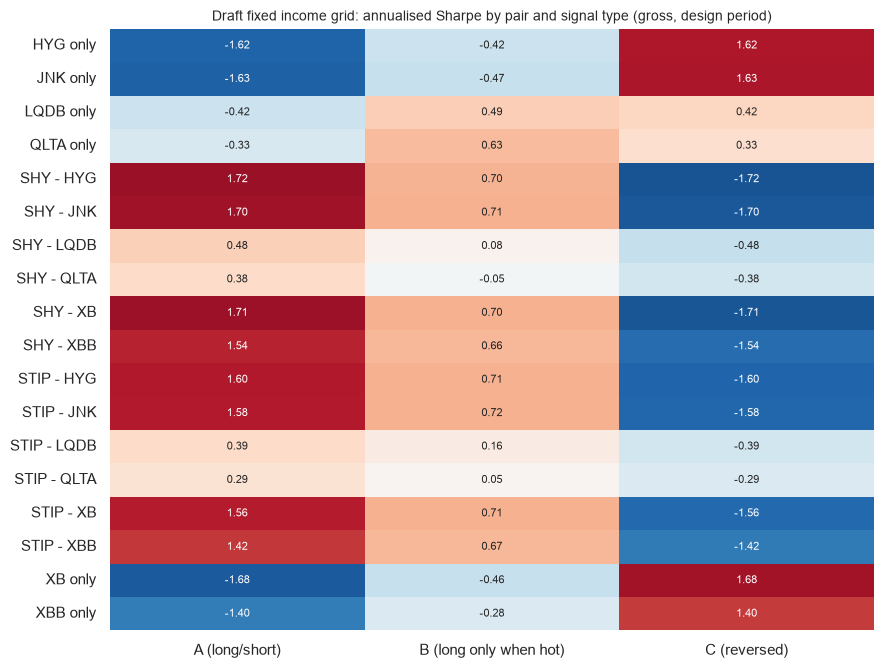

In [82]:
FAM_L = "L. Fixed income: credit and rating"
if "cpi" in SEL:
    sL = SEL["cpi"].reindex(IDX) - NC["cpi"]; posL = np.sign(sL).where(sL.abs() > DEADBAND, 0.0).where(sL.notna())
    for name, legs in (("L1. Inflation vs credit carry (STIP vs IGSB) into the CPI release", dur_pair("STIP", "IGSB", 2.5, 2.7)), ("L2. Corporate duration (VCSH vs VCLT) into the CPI release", {"VCSH": 0.5, "VCLT": -0.5})):
        if set(legs) <= set(CLOSE.columns):
            register(name, FAM_L, timing_trades(posL, legs, "fsbi", "cpi_rel"), placebo=timing_placebo(posL, legs, "fsbi", "cpi_rel"), spec=tspec(sL, legs, "fsbi", "cpi_rel", DEADBAND))
zL3 = z_dp - z_ss; zL4 = expanding_z(F["nat"]["breadth_state"].diff(3).mask(in_covid(IDX)))
for name, z, legs in (("L3. Credit quality (HYG vs IGSB) on demand-pull minus supply-squeeze", zL3, dur_pair("HYG", "IGSB", 3.2, 2.7)), ("L4. Investment-grade spread (LQD vs IEF) on state breadth momentum", zL4, dur_pair("LQD", "IEF", 8.4, 7.4))):
    if set(legs) <= set(CLOSE.columns):
        register(name, FAM_L, timing_trades(np.sign(z), legs), placebo=timing_placebo(np.sign(z), legs), spec=tspec(z, legs))

# L5 (Chang & Pinegar 1986): the long bond on the release day, against the predicted CPI surprise. Hot -> short duration.
LONG_BOND = {"SHY": 0.5, "TLT": -0.5}                          # +1 = short the long bond (hot); duration is the exposure, so it is not matched
if "cpi" in SEL and set(LONG_BOND) <= set(CLOSE.columns):
    s5L = refresh(SEL["cpi"].reindex(IDX), "cpi") - EXPECT["cpi"]; p5L = np.sign(s5L).where(s5L.abs() > DEADBAND, 0.0).where(s5L.notna())
    register("L5. Long Treasury bond (TLT vs SHY) on the CPI release day, on the predicted surprise", FAM_L, timing_trades(p5L, LONG_BOND, "cpi_pre", "cpi_rel"),
             placebo=timing_placebo(p5L, LONG_BOND, "cpi_pre", "cpi_rel"), spec=tspec(s5L, LONG_BOND, "cpi_pre", "cpi_rel", DEADBAND))

# L6 (Hong, Sraer & Yu 2017): dispersion of small-business price growth as a monthly measure of inflation disagreement.
_tk12 = lambda lvl: (lambda d: d.mask(pd.Series(in_covid(d.index), index=d.index), axis=0))(g(lvl, "ticket", 12))
DISAGREE = pd.DataFrame({"sub-sector ticket dispersion": _tk12("subsector").std(axis=1), "state ticket dispersion": _tk12("state").std(axis=1)}).reindex(IDX)
z_dis = DISAGREE.apply(expanding_z).mean(axis=1)                # higher = more spread-out price experiences = more room for inflation disagreement
HSY_TESTS = {}
if set(LONG_BOND) <= set(CLOSE.columns):
    _wl = window_ret(["TLT", "SHY"]); lb_ex = 100 * (_wl["TLT"] - _wl["SHY"])          # long-bond return over the short bond, FSBI day to next FSBI day (%)
    slope = fred_try("T10Y2Y")
    if slope is not None:
        _at = pd.Series(slope.reindex(TD, method="ffill").reindex(EV.fsbi.reindex(IDX).values).values, index=IDX); d_slope = _at.shift(-1) - _at
    for lab_, y_, own_ in (("next-window long-bond excess return (TLT - SHY, %)", lb_ex, lb_ex.shift(1)), ("next-window change in the 10y-2y slope (pp)", d_slope if slope is not None else None, None)):
        if y_ is not None:
            r_ = pred_reg(pre(y_), pre(z_dis), own=None if own_ is None else pre(own_), hac=2, shift=True)
            if r_:
                HSY_TESTS[lab_] = {**r_, "paper's sign": "negative"}
    HSY_TESTS = pd.DataFrame(HSY_TESTS).T
    if len(HSY_TESTS):
        print("Hong, Sraer & Yu (2017) predictions, with FSBI price dispersion standing in for inflation disagreement (design period; 'effect per 1 sd' of dispersion):"); display(HSY_TESTS)
    register("L6. Long Treasury bond (TLT vs SHY) on FSBI price dispersion (inflation disagreement)", FAM_L, timing_trades(np.sign(z_dis), LONG_BOND),
             placebo=timing_placebo(np.sign(z_dis), LONG_BOND), spec=tspec(z_dis, LONG_BOND))
display(family_table(FAM_L))

# The draft's grid, re-run on this engine (FSBI day to next FSBI day, gross of costs, design period): 3 signal types x 18 pairs.
L_GRID = pd.DataFrame()
if "cpi" in SEL:
    _gap = pre(sL).abs().dropna(); L_THR = 0.1 if (_gap > 0.1).sum() >= 8 else float(_gap.median())   # the draft's 0.1pp where it trades often enough, else the median gap
    CORP = ["QLTA", "LQDB", "HYG", "JNK", "XBB", "XB"]; hot, cool = sL > L_THR, sL < -L_THR
    SIG = {"A (long/short)": pd.Series(np.select([hot, cool], [1.0, -1.0], 0.0), index=IDX), "B (long only when hot)": hot.astype(float), "C (reversed)": pd.Series(np.select([hot, cool], [-1.0, 1.0], 0.0), index=IDX)}
    WR = window_ret(["STIP", "SHY"] + CORP); grid = []
    for base in ("STIP", "SHY", None):
        for c in CORP:
            if c not in WR or (base and base not in WR):
                continue
            unit = pre((WR[base] - WR[c]) if base else WR[c]).dropna()
            for sname, sg in SIG.items():
                r_ = (sg.where(sL.notna()).reindex(unit.index) * unit).dropna()
                if len(r_) >= 12 and r_.std() > 0:
                    grid.append({"pair": f"{base} - {c}" if base else f"{c} only", "signal type": sname, "months": len(r_), "trades": int((r_ != 0).sum()), "Sharpe": r_.mean() / r_.std() * np.sqrt(12), "p": boot_p(r_)})
    L_GRID = pd.DataFrame(grid)
    if len(L_GRID):
        _ind = ~L_GRID["signal type"].str.startswith("C")          # C is A with every sign flipped: its Sharpe is minus A's, so it is not an independent test
        L_GRID["Holm p"] = holm(L_GRID.p.where(_ind))           # NaN for type C
        G_ = L_GRID.pivot_table(index="pair", columns="signal type", values="Sharpe", aggfunc="first")
        print(f"Draft grid (threshold {L_THR:.2f}pp): {int(_ind.sum())} independent backtests (type C is type A reversed and is shown for reference only). Raw p < 0.10: {int((L_GRID.p[_ind] < 0.10).sum())} (about {0.1 * _ind.sum():.0f} expected by chance); "
              f"Holm p < 0.10: {int((L_GRID['Holm p'] < 0.10).sum())}. Pairs where the stated sign (A) loses money: {int((G_.get('A (long/short)', pd.Series(dtype=float)) < 0).sum())} of {len(G_)}.")
        fig, ax = plt.subplots(figsize=(9, 0.9 + 0.33 * len(G_)))
        sns.heatmap(G_, cmap="RdBu_r", center=0, vmin=-2, vmax=2, annot=True, fmt=".2f", annot_kws={"size": 8}, cbar=False, ax=ax)
        ax.set_title("Draft fixed income grid: annualised Sharpe by pair and signal type (gross, design period)", fontsize=10); ax.set_xlabel(""); ax.set_ylabel(""); plt.tight_layout(); plt.show()

### 4.1 Leaderboard: every strategy, one set of metrics

All metrics come from monthly net returns built from the engine's daily series: ROI, annualised return and volatility, Sharpe, Sortino, maximum drawdown, win rate and win/loss ratio (the capstone's list), plus four checks on whether the number means anything:

- **bootstrap p**: probability that the mean return is not above zero (block bootstrap of monthly returns), and a 90% interval for the Sharpe ratio;
- **Holm p**: the same after adjusting for every strategy on the board, the honest correction for having tried this many;
- **reality-check p**: a joint bootstrap in the spirit of White (2000): how often would the *best* strategy on a board with no real edge reach this strategy's t-statistic? It keeps the correlations between strategies, so it is less conservative than Holm when many strategies are variants of one idea;
- **placebo p**: from shuffling the signal (every ETF strategy);
- **beta to SPY** and the result with **one day of execution delay**.

Every statistic is computed on the design period. Three more columns report the **live track record** since then (months, mean return and Sharpe after the design period ended). A strategy counts as confirmed only if it passes the adjusted tests here *and* keeps its sign live.

Rank by Sharpe, trust by the Holm and reality-check p-values. With about forty months per strategy and some thirty strategies on the board, a Sharpe near 1 is typically still inside its own noise band.

,family,trades,months,ROI (%),ann. return (%),ann. vol (%),Sharpe,Sharpe 5%,Sharpe 95%,Sortino,max DD (%),trade win rate,win/loss,bootstrap p,Holm p,reality-check p,placebo p,beta to SPY,"Sharpe, 1-day delay",months (holdout),"mean (holdout, bp/month)",Sharpe (holdout)
J1. TIPS long-only: forecast vs 10-year breakeven (earlier drafts),J. TIPS on the inflation forecast,9,23,3.568,1.846,1.493,1.233,0.910,2.521,1.650,-0.266,0.778,1.929,0.001,0.073,0.762,0.253,0.030,0.954,15.0,-1.225,-0.076
H2. Short-volatility ETF (SVXY) through CPI on predicted surprise size,H. Options and volatility,18,18,10.313,6.762,6.669,1.015,-0.146,2.256,1.427,-3.918,0.667,1.092,0.076,1.000,0.966,0.215,0.013,NaN,20.0,12.517,0.171
C6. Pure-play stock baskets on demand surprise,C. Sector rotation,45,48,33.165,7.423,7.936,0.943,0.193,1.577,2.115,-8.670,0.556,1.503,0.017,0.840,0.644,0.008,0.073,0.683,20.0,2.327,0.051
I2. Copper vs gold (CPER vs GLD) on national demand surprise,I. FX and commodities,45,48,37.691,8.324,9.251,0.912,-0.099,1.513,2.116,-11.926,0.622,1.246,0.074,1.000,0.687,0.025,-0.057,0.800,20.0,32.874,0.360
C1. Sector rotation on demand surprise,C. Sector rotation,45,48,19.029,4.451,6.135,0.741,0.146,1.486,1.421,-7.279,0.667,1.282,0.025,1.000,0.875,0.042,0.053,0.721,20.0,-41.467,-0.805
"F. Kalshi core CPI contract, quarter-Kelly",F. Prediction markets,16,18,49.183,30.561,72.759,0.628,-1.039,1.878,5.108,-24.986,0.312,4.245,0.157,1.000,1.000,NaN,1.070,NaN,19.0,59.558,0.201
"F. Kalshi CPI contract, quarter-Kelly",F. Prediction markets,16,18,44.182,27.626,67.776,0.605,-2.612,1.410,3.795,-27.714,0.250,5.814,0.283,1.000,1.000,NaN,-2.494,NaN,20.0,162.767,0.490
B3. Staples vs discretionary (XLP vs XLY) on supply-squeeze,B. Inflation regime,42,43,24.766,6.370,11.511,0.593,-0.181,1.608,1.135,-18.926,0.548,1.357,0.098,1.000,0.986,0.095,0.006,0.413,20.0,79.672,1.228
E4. High-yield credit vs Treasuries (HYG vs IEF) on state breadth,E. Small-business cycle,45,48,8.866,2.146,4.599,0.485,-0.158,1.704,0.577,-3.349,0.556,1.254,0.083,1.000,0.999,0.085,0.059,0.665,20.0,-18.166,-1.008
B5. Short duration (SHY vs TLT) on nominal activity surprise,B. Inflation regime,45,48,10.886,2.617,6.409,0.435,-0.445,1.486,0.724,-7.379,0.511,1.326,0.205,1.000,1.000,0.094,0.012,0.374,20.0,-31.949,-0.860


50 strategies. Raw bootstrap p < 0.10: 7 (about 5.0 expected by chance). Surviving the Holm adjustment: 1 -> J1. TIPS long-only: forecast vs 10-year breakeven (earlier drafts) Reality-check p < 0.10: 0.
Primary strategies (one per family, 12 tests instead of 50): 0 survive the Holm adjustment.


,family,Sharpe,bootstrap p,Holm p (primary),Sharpe (holdout)
H2. Short-volatility ETF (SVXY) through CPI on predicted surprise size,H. Options and volatility,1.015,0.076,0.912,0.171
"F. Kalshi core CPI contract, quarter-Kelly",F. Prediction markets,0.628,0.157,1.000,0.201
C4. Sector rotation on the composite of C1-C3,C. Sector rotation,0.359,0.151,1.000,-0.600
E1. Small vs large caps (IWM vs SPY) on national demand surprise,E. Small-business cycle,0.276,0.407,1.000,-0.060
D4. Regional banks on the composite of D1 and D3,D. Regional banks,0.167,0.361,1.000,-1.592
A. Surprise basket on core CPI,A. Announcement surprise,-0.260,0.627,1.000,-0.803
B1. Breakeven (TIP vs IEF) on broad price pressure,B. Inflation regime,-0.441,0.858,1.000,-1.723
G1. Retail sales: discretionary vs staples (XLY vs XLP),G. Retail-sales announcement,-0.492,0.749,1.000,0.208
I1. Dollar vs yen (UUP vs FXY) on demand-pull,I. FX and commodities,-0.513,0.760,1.000,-0.961
K2. Small-minus-large spread rotation on FSBI sector demand,K. Small-cap sectors by FSBI classification,-1.191,0.989,1.000,-0.936


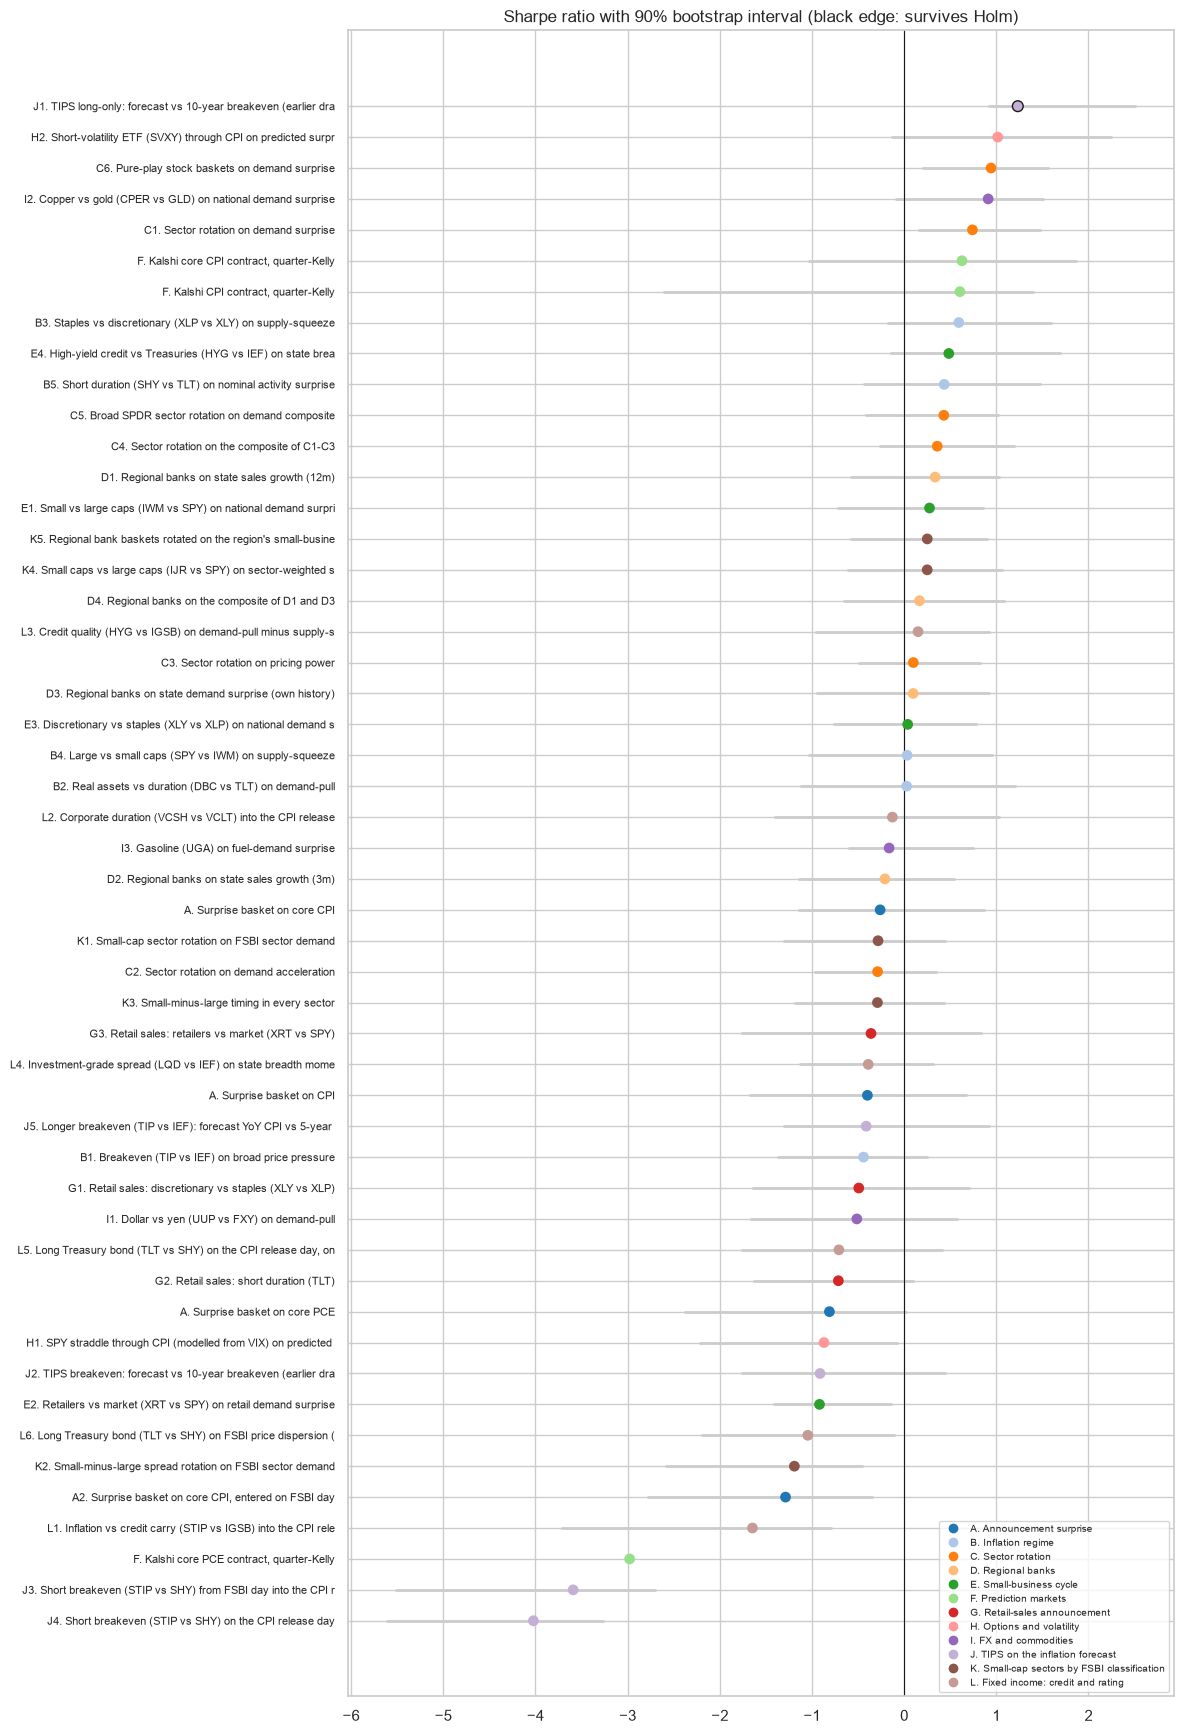

Months with a loss above 25% (inspect these trades before trusting the strategy):
  I3. Gasoline (UGA) on fuel-demand surprise: -58.5% in Mar 2020; worst trades: 2020-02-01 00:00:00 -50.0%, 2022-01-01 00:00:00 -23.0%, 2026-01-01 00:00:00 -21.5%


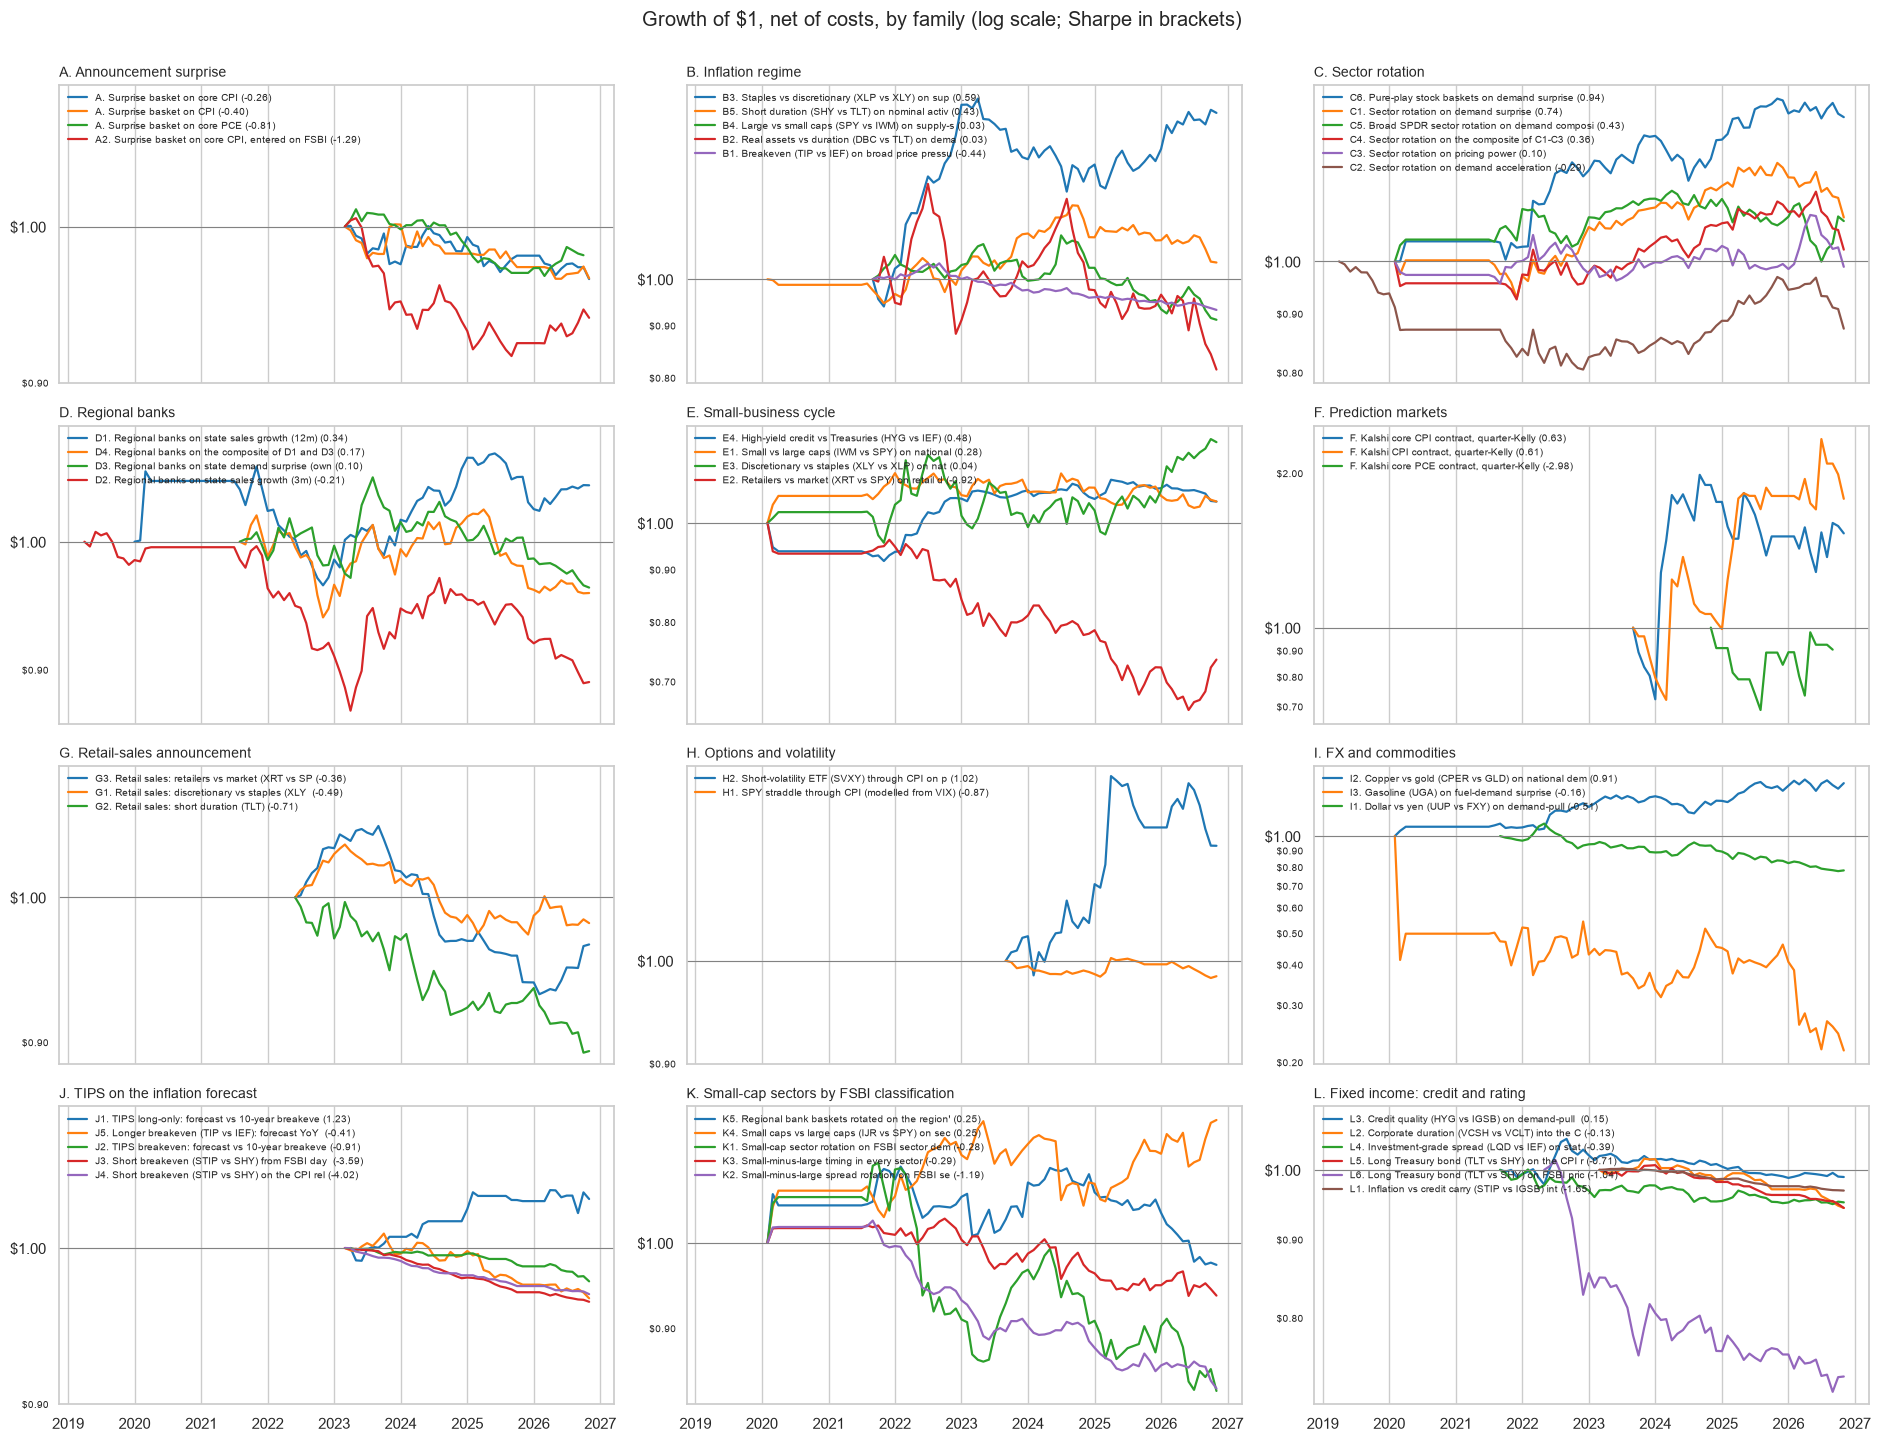

In [83]:
spy_m = to_monthly(RET["SPY"].fillna(0)); ief_m = to_monthly(RET["IEF"].fillna(0)) if "IEF" in RET else pd.Series(dtype=float)
_rf = fred_try("TB3MS")                                       # 3-month Treasury bill, % per year, monthly
RF_M = (_rf / 1200).reindex(spy_m.index, method="ffill").fillna(0.0) if _rf is not None else pd.Series(0.0, index=spy_m.index)
def net_exposure(s_):
    """Average net weight of a strategy's trades: about 0 for a long-short (self-financing) book, 1 for a long-only one. Daily-only strategies
    (Kalshi stakes, modelled straddles) are returns on a bankroll or notional and are treated as excess returns."""
    return float(np.mean([sum(t_["w"].values()) for t_ in s_["trades"]])) if s_.get("trades") else 0.0
def alphas(m, net=0.0, hac=3):
    """Market-adjusted return, Jensen's alpha (CAPM, against SPY) and a two-factor alpha (SPY and IEF, so Treasury duration is not counted as skill).
    Returns are made excess of the T-bill for the share of capital a strategy actually commits (net exposure) in months it is invested."""
    m = m.dropna(); rf = RF_M.reindex(m.index).fillna(0.0)
    ex = m - net * rf * (m != 0); mk = (spy_m - RF_M).reindex(m.index); bd = (ief_m - RF_M).reindex(m.index)
    d = pd.concat({"r": ex, "mkt": mk, "bond": bd}, axis=1).dropna()
    if len(d) < 12 or d.r.std() == 0:
        return {}
    capm = sm.OLS(d.r, sm.add_constant(d[["mkt"]])).fit(cov_type="HAC", cov_kwds={"maxlags": hac})
    two = sm.OLS(d.r, sm.add_constant(d[["mkt", "bond"]])).fit(cov_type="HAC", cov_kwds={"maxlags": hac}) if d.bond.std() > 0 else None
    res_sd = capm.resid.std()
    out = {"market-adjusted return (ann. %)": 1200 * (d.r - d.mkt).mean(), "Jensen's alpha (ann. %)": 1200 * capm.params["const"], "Jensen's alpha t": capm.tvalues["const"], "Jensen's alpha p": capm.pvalues["const"],
           "CAPM beta": capm.params["mkt"], "appraisal ratio": capm.params["const"] / res_sd * np.sqrt(12) if res_sd > 0 else np.nan,
           "Treynor ratio (ann. %)": 1200 * d.r.mean() / capm.params["mkt"] if abs(capm.params["mkt"]) > 0.05 else np.nan,
           "mean excess return (ann. %)": 1200 * d.r.mean(), "from market beta (ann. %)": 1200 * capm.params["mkt"] * d.mkt.mean()}
    if two is not None:
        out.update({"two-factor alpha (ann. %)": 1200 * two.params["const"], "two-factor alpha t": two.tvalues["const"], "two-factor alpha p": two.pvalues["const"], "bond beta": two.params["bond"],
                    "from bond beta (ann. %)": 1200 * two.params["bond"] * d.bond.mean()})
    return out
stat_m = lambda daily: to_monthly(daily[daily.index <= STAT_END_DAY])          # monthly returns of the design period
live_m = lambda daily: to_monthly(daily[daily.index > STAT_END_DAY])
def board_row(s):
    m = stat_m(s["daily"]); p = perf(m)
    if "Sharpe" not in p:
        return None
    sh = block_bootstrap(m, lambda x: x.mean() / x.std() * np.sqrt(12) if x.std() > 0 else 0.0)
    d = pd.concat([m, spy_m], axis=1).dropna()
    row = {"family": s["family"], "trades": len(pre(s["per"])), "months": len(m), **{k: p[k] for k in ("ROI (%)", "ann. return (%)", "ann. vol (%)", "Sharpe", "Sortino", "max DD (%)", "win/loss")},
           "trade win rate": float((pre(s["per"]) > 0).mean()), "Sharpe 5%": np.nanpercentile(sh, 5), "Sharpe 95%": np.nanpercentile(sh, 95), "bootstrap p": boot_p(m), "placebo p": s["placebo"],
           "beta to SPY": np.polyfit(d.iloc[:, 1], d.iloc[:, 0], 1)[0] if len(d) > 12 else np.nan}
    if s["trades"] is not None:
        row["Sharpe, 1-day delay"] = perf(stat_m(run_book(s["trades"], delay=1)[0])).get("Sharpe", np.nan)
    row["net exposure"] = net_exposure(s); row.update(alphas(m, row["net exposure"]))
    return row
BOARD = pd.DataFrame({n: r for n, r in ((n, board_row(s)) for n, s in STRATS.items()) if r}).T
for c in BOARD.columns.drop("family"):
    BOARD[c] = pd.to_numeric(BOARD[c])
BOARD["Holm p"] = holm(BOARD["bootstrap p"])
if "Jensen's alpha p" in BOARD:
    BOARD["Jensen's alpha Holm p"] = holm(BOARD["Jensen's alpha p"])
PRIMARY = ["A. Surprise basket on core CPI", "B1.", "C4.", "D4.", "E1.", "F. Kalshi core CPI contract, quarter-Kelly", "G1.", "H2.", "I1.", "J3.", "K2.", "L1."]   # named before any result was seen: one per family
BOARD["primary"] = [any(n == p or (p.endswith(".") and n.startswith(p)) for p in PRIMARY) for n in BOARD.index]
BOARD["Holm p (primary)"] = holm(BOARD.loc[BOARD.primary, "bootstrap p"]).reindex(BOARD.index)

def reality_check(M_, n_boot=None, block=3):
    """Joint bootstrap p-value for each strategy's t-statistic against the distribution of the BEST t-statistic on the board
    when no strategy has an edge (returns centred, months resampled jointly so correlations between strategies are kept)."""
    n_boot = n_boot or (300 if FAST else 2000); X = M_.dropna(how="all"); cnt, sd = X.count().values, X.std().values
    t_obs = X.mean().values / (sd / np.sqrt(cnt)); Xc = (X - X.mean()).fillna(0.0).values; n = len(Xc)
    g_ = np.random.default_rng(SEED); starts = np.arange(n - block + 1); mx = np.empty(n_boot)
    for b in range(n_boot):
        ix = np.concatenate([np.arange(s, s + block) for s in g_.choice(starts, n // block + 1)])[:n]
        mx[b] = np.nanmax(Xc[ix].sum(axis=0) / cnt / (sd / np.sqrt(cnt)))
    return pd.Series([(1 + (mx >= t).sum()) / (n_boot + 1) for t in t_obs], index=X.columns)
BOARD["reality-check p"] = reality_check(pd.DataFrame({n: stat_m(STRATS[n]["daily"]) for n in BOARD.index}).sort_index())
if not RUN_HOLDOUT:                                          # live track record: real-time results since the design period ended
    for n in BOARD.index:
        h = live_m(STRATS[n]["daily"])
        BOARD.loc[n, ["months (holdout)", "mean (holdout, bp/month)", "Sharpe (holdout)"]] = [len(h), 1e4 * h.mean() if len(h) else np.nan, perf(h).get("Sharpe", np.nan)]
        BOARD.loc[n, "Jensen's alpha (holdout, ann. %)"] = alphas(h, BOARD.at[n, "net exposure"]).get("Jensen's alpha (ann. %)", np.nan) if len(h) >= 12 else np.nan
BOARD = BOARD.sort_values("Sharpe", ascending=False)
show = ["family", "trades", "months", "ROI (%)", "ann. return (%)", "ann. vol (%)", "Sharpe", "Sharpe 5%", "Sharpe 95%", "Sortino", "max DD (%)", "trade win rate", "win/loss", "bootstrap p", "Holm p", "reality-check p", "placebo p", "beta to SPY", "Sharpe, 1-day delay", "months (holdout)", "mean (holdout, bp/month)", "Sharpe (holdout)"]
display(BOARD[[c for c in show if c in BOARD]].round(3))
n_raw, n_holm = int((BOARD["bootstrap p"] < 0.10).sum()), int((BOARD["Holm p"] < 0.10).sum())
print(f"{len(BOARD)} strategies. Raw bootstrap p < 0.10: {n_raw} (about {0.10 * len(BOARD):.1f} expected by chance). Surviving the Holm adjustment: {n_holm}"
      + (f" -> {', '.join(BOARD.index[BOARD['Holm p'] < 0.10])}" if n_holm else " (none is distinguishable from the best of this many tries).")
      + f" Reality-check p < 0.10: {int((BOARD['reality-check p'] < 0.10).sum())}."
      + f"\nPrimary strategies (one per family, {int(BOARD.primary.sum())} tests instead of {len(BOARD)}): {int((BOARD['Holm p (primary)'] < 0.10).sum())} survive the Holm adjustment"
      + (f" -> {', '.join(BOARD.index[BOARD['Holm p (primary)'] < 0.10])}." if (BOARD['Holm p (primary)'] < 0.10).any() else "."))
display(BOARD.loc[BOARD.primary, ["family", "Sharpe", "bootstrap p", "Holm p (primary)"] + [c for c in ("Sharpe (holdout)",) if c in BOARD]].round(3))

fams = sorted(BOARD.family.unique()); pal = dict(zip(fams, sns.color_palette("tab20" if len(fams) > 10 else "tab10", len(fams))))   # one distinct colour per family
fig, axes = plt.subplots(1, 1, figsize=(12, max(4.5, 0.32 * len(BOARD) + 1.5))); axes = [axes]
d = BOARD.iloc[::-1]; yy = np.arange(len(d))
axes[0].errorbar(d.Sharpe.astype(float), yy, xerr=[(d.Sharpe - d["Sharpe 5%"]).astype(float), (d["Sharpe 95%"] - d.Sharpe).astype(float)], fmt="none", ecolor="#cccccc", lw=2)
axes[0].scatter(d.Sharpe.astype(float), yy, c=[pal[f] for f in d.family], s=60, zorder=3, edgecolor=["k" if p < 0.10 else "none" for p in d["Holm p"]])
axes[0].axvline(0, color="k", lw=0.8); axes[0].set_yticks(yy); axes[0].set_yticklabels([n[:62] for n in d.index], fontsize=8)
axes[0].set_title("Sharpe ratio with 90% bootstrap interval (black edge: survives Holm)")
axes[0].legend(handles=[plt.Line2D([], [], marker="o", ls="", color=c_, label=f_) for f_, c_ in pal.items()], fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

# Growth of $1: one panel per family so lines do not pile up, a distinct colour per strategy inside each panel, every curve starting
# at $1 on its own first month, and a shared log scale so a halving and a doubling are the same distance from $1.
MONTHLY = {n: to_monthly(STRATS[n]["daily"]) for n in BOARD.index}
worst = pd.Series({n: m.min() for n, m in MONTHLY.items() if len(m)}).sort_values()
if (worst < -0.25).any():
    print("Months with a loss above 25% (inspect these trades before trusting the strategy):")
    for n in worst[worst < -0.25].index:
        m = MONTHLY[n]; tr = STRATS[n].get("per", pd.Series(dtype=float))
        print(f"  {n}: {m.min():+.1%} in {m.idxmin():%b %Y}; worst trades: " + ", ".join(f"{k} {v:+.1%}" for k, v in tr.sort_values().head(3).items()))
_mm = pd.DataFrame(MONTHLY).fillna(0); _cc = _mm.corr().abs().where(np.triu(np.ones((_mm.shape[1],) * 2, bool), 1)).stack()
if (_cc > 0.95).any():
    print("Pairs whose monthly returns are almost the same (|correlation| > 0.95), so their lines overlap or mirror each other:")
    for (a_, b_), v in _cc[_cc > 0.95].sort_values(ascending=False).items():
        print(f"  {a_}  <->  {b_}  ({_mm[a_].corr(_mm[b_]):+.2f})")
ncol = 3; nrow = int(np.ceil(len(fams) / ncol))
fig, axs = plt.subplots(nrow, ncol, figsize=(19, 3.6 * nrow), sharex=True); axs = np.atleast_1d(axs).ravel()
for ax, f_ in zip(axs, fams):
    names = list(BOARD.index[BOARD.family == f_]); cols_ = plt.cm.tab10(np.arange(len(names)) % 10)
    for n, c_ in zip(names, cols_):
        gr = growth(MONTHLY[n])
        if len(gr):
            ax.plot(gr.index, gr.values, color=c_, lw=1.6, ls=["-", "--", ":", "-."][names.index(n) // 10 % 4] if len(names) > 10 else "-", label=f"{n[:48]} ({BOARD.at[n, 'Sharpe']:.2f})")
    ax.axhline(1, color="grey", lw=0.7); ax.set_yscale("log"); ax.set_title(f_, fontsize=10, loc="left")
    lo, hi = ax.get_ylim(); ax.set_ylim(min(lo, 0.9), max(hi, 1.1))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"${v:.2f}")); ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"${v:.2f}"))
    ax.tick_params(axis="y", which="minor", labelsize=7); ax.legend(fontsize=7, loc="upper left", frameon=False)
for ax in axs[len(fams):]:
    ax.set_visible(False)
fig.suptitle("Growth of $1, net of costs, by family (log scale; Sharpe in brackets)", y=1.0); plt.tight_layout()

**Attribution: what did FSBI itself contribute?** The forecast-driven families (A and F) each have a twin run on the forecast built without FSBI. The difference between the two rows is the part of the result that belongs to FSBI rather than to public data or modelling.

In [84]:
att = {}
for n, c in CONTROLS.items():
    base = n.split(" [")[0]
    if base in STRATS:
        a, b = pre(STRATS[base]["per"]), pre(c["per"]); a0, b0 = a.reindex(a.index.union(b.index)).fillna(0), b.reindex(a.index.union(b.index)).fillna(0); diff = a0 - b0
        att[(base, n.split(" [")[1].rstrip("]"))] = {"mean with FSBI (bp)": 1e4 * a0.mean(), "mean control (bp)": 1e4 * b0.mean(), "difference (bp)": 1e4 * diff.mean(),
                                                     "t-stat of difference": diff.mean() / diff.std() * np.sqrt(len(diff)) if diff.std() > 0 else np.nan, "months": len(diff)}
ATTRIB = pd.DataFrame(att).T
display(ATTRIB.round(2)) if len(ATTRIB) else print("No forecast-driven strategy with a twin was registered.")

mean with FSBI (bp)  mean control (bp)  difference (bp)  t-stat of difference  months
A. Surprise basket on core CPI             no-FSBI twin                     -5.60              10.61           -16.20                 -0.96    23.0
A. Surprise basket on CPI                  no-FSBI twin                     -8.39              10.87           -19.27                 -2.79    22.0
A. Surprise basket on core PCE             no-FSBI twin                     -9.93             -21.27            11.34                  1.31    24.0
F. Kalshi CPI contract, quarter-Kelly      no-FSBI twin                    384.68             278.54           106.14                  0.59    16.0
                                           Cleveland nowcast               267.61             203.86            63.74                  0.15    23.0
F. Kalshi core CPI contract, quarter-Kelly no-FSBI twin                    428.10             447.06           -18.96                 -0.07    16.0
                                           Cleveland nowcast               285.40             136.52           148.88                  0.56    24.0
F. Kalshi core PCE contract, quarter-Kelly no-FSBI twin                   -962.79            -916.51           -46.29                 -1.00     2.0
                                           Cleveland nowcast              -962.79            -674.34          -288.45                 -1.67     2.0

### 4.1c Alpha: what is left after market and bond exposure

A positive Sharpe can come from simply holding the market or holding duration in a period when both paid. Alpha removes that.

- **Market-adjusted return**: the strategy's excess return minus the market's (beta assumed to be 1). Meaningful only for long-only equity books; for long-short books it mostly measures the market's return with the sign flipped.
- **Jensen's alpha** (Jensen 1968): the intercept of the strategy's excess return regressed on the market's excess return (SPY minus T-bills), annualised. It is the return the strategy earned beyond what its own beta to equities explains. Tested with Newey-West errors and Holm-adjusted across the board, like the Sharpe ratios.
- **Two-factor alpha**: the same with intermediate Treasuries (IEF) as a second factor. Most of the fixed income and TIPS strategies carry duration; without this factor, a book that is simply long bonds in a rally looks like skill.
- **Appraisal ratio** (Treynor & Black 1973): Jensen's alpha divided by the volatility the market does not explain. It ranks strategies by how much alpha they deliver per unit of risk that could not be hedged away with SPY, which is the right yardstick for adding a strategy to a diversified book.

Excess returns: a long-short book is self-financing, so its return is already an excess return; a long-only book (net exposure 1) has the T-bill rate deducted in the months it is invested. Design period only; the live-period Jensen's alpha is shown separately.

,family,net exposure,Sharpe,mean excess return (ann. %),from market beta (ann. %),from bond beta (ann. %),market-adjusted return (ann. %),Jensen's alpha (ann. %),Jensen's alpha t,Jensen's alpha p,Jensen's alpha Holm p,CAPM beta,appraisal ratio,two-factor alpha (ann. %),two-factor alpha t,bond beta,Treynor ratio (ann. %),"Jensen's alpha (holdout, ann. %)"
"F. Kalshi CPI contract, quarter-Kelly",F. Prediction markets,0.000,0.605,41.033,-38.448,-0.449,25.712,79.481,1.247,0.213,1.000,-2.509,1.342,78.478,1.358,-0.277,-16.351,16.617
"F. Kalshi core CPI contract, quarter-Kelly",F. Prediction markets,0.000,0.628,45.664,16.320,-9.586,30.343,29.344,0.563,0.573,1.000,1.065,0.411,7.941,0.204,-5.921,42.869,0.753
I2. Copper vs gold (CPER vs GLD) on national demand surprise,I. FX and commodities,0.000,0.912,8.433,-0.320,-0.930,2.631,8.753,1.952,0.051,1.000,-0.055,0.952,9.925,2.186,0.221,-153.111,2.635
C6. Pure-play stock baskets on demand surprise,C. Sector rotation,0.000,0.943,7.483,0.439,0.691,1.681,7.044,1.923,0.054,1.000,0.076,0.902,6.173,1.772,-0.164,98.861,-0.406
B3. Staples vs discretionary (XLP vs XLY) on supply-squeeze,B. Inflation regime,0.000,0.593,6.830,0.084,1.667,0.610,6.746,0.970,0.332,1.000,0.014,0.586,4.558,0.679,-0.287,NaN,8.131
H2. Short-volatility ETF (SVXY) through CPI on predicted surprise size,H. Options and volatility,0.059,1.015,6.483,0.213,0.625,-8.838,6.270,1.582,0.114,1.000,0.014,0.940,7.666,3.136,0.386,NaN,2.926
C1. Sector rotation on demand surprise,C. Sector rotation,0.000,0.741,4.546,0.304,0.616,-1.256,4.242,1.686,0.092,1.000,0.052,0.700,3.466,1.353,-0.146,86.728,-6.822
B5. Short duration (SHY vs TLT) on nominal activity surprise,B. Inflation regime,0.000,0.435,2.787,0.066,-0.991,-3.016,2.721,0.779,0.436,1.000,0.011,0.425,3.970,1.220,0.235,NaN,-4.760
C5. Broad SPDR sector rotation on demand composite,C. Sector rotation,0.000,0.431,2.589,-0.119,-0.418,-3.214,2.708,0.974,0.330,1.000,-0.021,0.451,3.235,1.085,0.099,NaN,1.683
C4. Sector rotation on the composite of C1-C3,C. Sector rotation,0.000,0.359,2.433,0.253,1.132,-3.369,2.180,0.776,0.438,1.000,0.044,0.324,0.754,0.296,-0.269,NaN,-5.736


Positive Jensen's alpha: 22 of 50; positive with raw p < 0.10: 3; positive and surviving Holm: 0. Negative with raw p < 0.10: 8 (candidates for the reversal analysis in 4.1b).
Sharpe above 0.3 with more than half the return from equity beta: none.
Sharpe above 0.3 with more than half the return from Treasury duration: none.


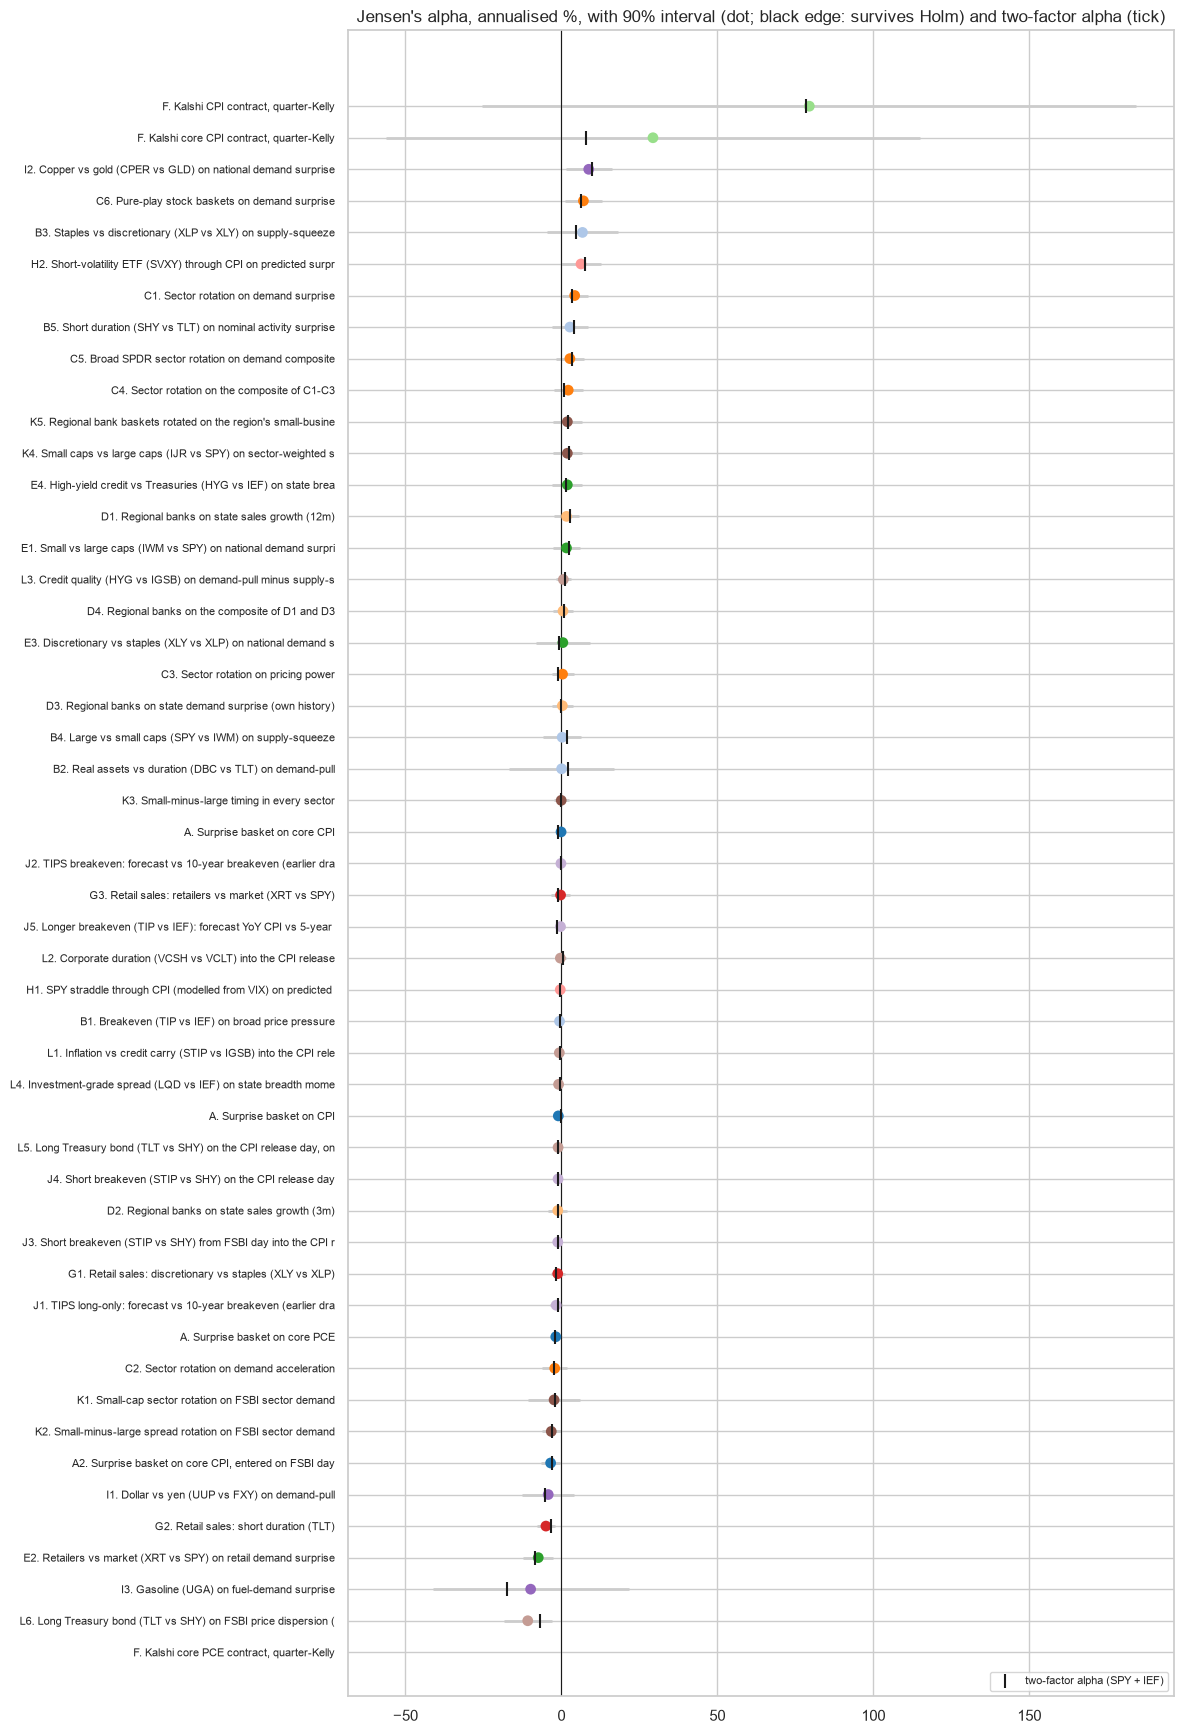

In [85]:
ALPHA_COLS = ["family", "net exposure", "Sharpe", "mean excess return (ann. %)", "from market beta (ann. %)", "from bond beta (ann. %)", "market-adjusted return (ann. %)", "Jensen's alpha (ann. %)", "Jensen's alpha t", "Jensen's alpha p", "Jensen's alpha Holm p", "CAPM beta", "appraisal ratio",
              "two-factor alpha (ann. %)", "two-factor alpha t", "bond beta", "Treynor ratio (ann. %)", "Jensen's alpha (holdout, ann. %)"]
ALPHA = BOARD[[c for c in ALPHA_COLS if c in BOARD]].sort_values("Jensen's alpha (ann. %)", ascending=False) if "Jensen's alpha (ann. %)" in BOARD else pd.DataFrame()
if len(ALPHA):
    display(ALPHA.round(3))
    ja = pd.to_numeric(ALPHA["Jensen's alpha (ann. %)"]); t2 = pd.to_numeric(ALPHA.get("two-factor alpha t", pd.Series(np.nan, index=ALPHA.index)))
    mex, fm, fb = (pd.to_numeric(ALPHA.get(c, pd.Series(np.nan, index=ALPHA.index))) for c in ("mean excess return (ann. %)", "from market beta (ann. %)", "from bond beta (ann. %)"))
    beta_driven = ALPHA.index[(pd.to_numeric(ALPHA.Sharpe) > 0.3) & (mex > 0) & (fm > 0.5 * mex)]                        # over half the return is equity beta
    dur_driven = ALPHA.index[(pd.to_numeric(ALPHA.Sharpe) > 0.3) & (mex > 0) & (fb > 0.5 * mex)]                         # over half the return is Treasury duration
    sig_pos = (ja > 0) & (ALPHA["Jensen's alpha p"] < 0.10)
    jp_, jh_ = ALPHA["Jensen's alpha p"], ALPHA["Jensen's alpha Holm p"]
    print(f"Positive Jensen's alpha: {int((ja > 0).sum())} of {len(ALPHA)}; positive with raw p < 0.10: {int(sig_pos.sum())}; positive and surviving Holm: {int((sig_pos & (jh_ < 0.10)).sum())}. "
          f"Negative with raw p < 0.10: {int(((ja < 0) & (jp_ < 0.10)).sum())} (candidates for the reversal analysis in 4.1b).")
    print("Sharpe above 0.3 with more than half the return from equity beta: " + (", ".join(n.split(".")[0] for n in beta_driven) or "none") + ".")
    print("Sharpe above 0.3 with more than half the return from Treasury duration: " + (", ".join(n.split(".")[0] for n in dur_driven) or "none") + ".")
    d_ = ALPHA.iloc[::-1]; yy = np.arange(len(d_)); se = (pd.to_numeric(d_["Jensen's alpha (ann. %)"]) / pd.to_numeric(d_["Jensen's alpha t"]).replace(0, np.nan)).abs()
    fig, ax = plt.subplots(figsize=(12, max(4.5, 0.32 * len(d_) + 1.5)))
    ax.errorbar(pd.to_numeric(d_["Jensen's alpha (ann. %)"]), yy, xerr=1.645 * se, fmt="none", ecolor="#cccccc", lw=2)
    ax.scatter(pd.to_numeric(d_["Jensen's alpha (ann. %)"]), yy, c=[pal[f] for f in d_.family], s=60, zorder=3, edgecolor=["k" if p < 0.10 and a > 0 else "none" for p, a in zip(d_["Jensen's alpha Holm p"], pd.to_numeric(d_["Jensen's alpha (ann. %)"]))])
    if "two-factor alpha (ann. %)" in d_:
        ax.scatter(pd.to_numeric(d_["two-factor alpha (ann. %)"]), yy, marker="|", color="k", s=90, zorder=4, label="two-factor alpha (SPY + IEF)")
    ax.axvline(0, color="k", lw=0.8); ax.set_yticks(yy); ax.set_yticklabels([n[:62] for n in d_.index], fontsize=8); ax.legend(fontsize=8, loc="lower right")
    ax.set_title("Jensen's alpha, annualised %, with 90% interval (dot; black edge: survives Holm) and two-factor alpha (tick)"); plt.tight_layout(); plt.show()

### 4.1b When a strategy loses badly: is the opposite position the right one?

A strategy with a strongly negative Sharpe is not just "no signal"; something systematic is going on. For every strategy whose design-period Sharpe is below −0.5, the same trades are rerun with every position reversed (costs still paid), and the loss is taken apart to see which of three things happened:

1. **Costs and noise.** The reversed strategy also loses or earns next to nothing (Sharpe below 0.3). There was no relationship in either direction; the original loss was trading cost plus bad luck. Reversing is not a strategy.
2. **Drift, not timing.** The strategy was on one side most of the time, and that side's instruments drifted against it (for example a book that is usually short volatility-carry, or short the higher-yielding leg). The reversal earns that drift. It would have earned it with no FSBI signal at all, so it says nothing about FSBI. Shown by the split of the average return into *average position × average instrument return* and the *timing* remainder.
3. **The relationship has the opposite sign.** The timing part itself is negative: the instrument tends to move against the signal. Then the original hypothesis was wrong in a specific way, and the family's economics usually say how (listed under each case below).

A reversal chosen after seeing the result is a new, data-mined strategy. It is reported with its own bootstrap p-value, Holm-adjusted across the reversals tried, and its live-period Sharpe, and it is **not** added to the leaderboard. It becomes a candidate only if the reversed sign also holds in the live period.

In [86]:
REV_THRESHOLD = -0.5
WHY = {"A": "Hypothesis: prices move with the forecast surprise on release day. If the converse works, the forecast's edge over the market is negative on the days it disagrees most: the market's expectation already contains the public information FSBI repeats, so the model's disagreement is mostly its own error, and fading it trades with the better forecaster.",
       "B": "Hypothesis: demand-pull favours real assets and supply-squeeze favours defensives over the next month. If the converse works, the regime is already in prices by the time FSBI confirms it (it is a lagging read on a move markets made during the month), and the following month mean-reverts.",
       "C": "Hypothesis: sectors with strong small-business demand outperform. If the converse works, strong card spending is already reflected in sector prices before FSBI day, and the rotation buys recent winners at the point they reverse (short-term industry reversal).",
       "D": "Hypothesis: banks in states with strong small-business sales outperform. If the converse works, strong local demand has come with higher deposit costs and tighter margins in this sample, or the signal is sorting on a regional factor (Sun Belt vs the rest) that happened to lose.",
       "E": "Hypothesis: strong small-business demand favours small caps, retailers and credit. If the converse works, strong demand is read as a reason for tighter policy, which hurts the rate-sensitive, lower-quality side more than the demand helps.",
       "G": "Hypothesis: FSBI predicts the retail sales surprise. If the converse works, the 'public model' is a poor stand-in for consensus: analysts already use card data, so the FSBI-implied surprise is in the consensus and the print surprises the other way relative to it.",
       "H": "Hypothesis: own volatility when a large surprise is predicted. If the converse works, the result is the variance risk premium: implied volatility is richer than realised around releases on average, so being long volatility loses carry whenever the predicted surprise does not arrive, and the forecast of surprise size is not accurate enough to pay for it.",
       "I": "Hypothesis: FSBI demand moves the dollar, copper and gasoline. If the converse works, these are global prices driven by non-US demand and supply in this sample, and US small-business strength has coincided with moves in the opposite direction (for gasoline, high pump prices also raise ticket and cut fill-ups).",
       "J": "Hypothesis: a forecast above the breakeven or nowcast favours TIPS. If the converse works, breakevens already price the print by FSBI day and fall back once it lands (buy the rumour, sell the news), or real yields rose when inflation was hot, which hurts TIPS more than the inflation accrual helps.",
       "K": "Hypothesis: small caps in sectors with strong small-business demand outperform. If the converse works, the sector news reached large caps first and small caps were already bid up, or small-cap funds were driven by financing conditions that move against strong demand.",
       "L": "Hypothesis: hot inflation favours TIPS over corporates and short over long duration; strong small-business conditions favour lower-rated credit. If the converse works, credit carry dominated: corporates out-earned the hedge leg in most months whatever the signal, which is drift, or hot-inflation months coincided with risk-on spread tightening."}
def _rev_trades(trades):
    return [{**t_, "w": {a: -w for a, w in t_["w"].items()}} for t_ in trades]
def _decompose(s_):
    """Timing strategies: split the mean gross trade return into (average position x average instrument return) and the timing remainder, in bp."""
    sp = s_.get("spec") or {}
    if sp.get("type") != "timing" or not s_["trades"]:
        return np.nan, np.nan, np.nan
    legs = sp["legs"]; a0 = next(iter(legs)); unit = (window_ret(list(legs), sp["entry"], sp["exit"]) * pd.Series(legs)).sum(axis=1, min_count=len(legs))
    pos = pd.Series({t_["ref"]: t_["w"].get(a0, 0.0) / legs[a0] for t_ in s_["trades"]}); d_ = pre(pd.concat({"p": pos.reindex(unit.index).fillna(0.0), "u": unit}, axis=1).dropna())
    if len(d_) < 8:
        return np.nan, np.nan, np.nan
    drift = d_.p.mean() * d_.u.mean(); return 1e4 * drift, 1e4 * ((d_.p * d_.u).mean() - drift), float(d_.p.mean())
rev_rows = {}
for n in BOARD.index[BOARD.Sharpe < REV_THRESHOLD]:
    s_ = STRATS[n]
    if s_["trades"] is None:
        rev_rows[n] = {"family": s_["family"], "Sharpe": BOARD.at[n, "Sharpe"], "diagnosis": "not reversible by flipping a sign (the opposite contract has its own price); see the family note"}; continue
    rd, rper = run_book(_rev_trades(s_["trades"])); gross = run_book(s_["trades"], cost=0.0)[0]; rm, rl = stat_m(rd), live_m(rd)
    drift, timing, avg_pos = _decompose(s_); pr_ = perf(rm); rs = pr_.get("Sharpe", np.nan)
    if not rs > 0.3:                                        # a reversed Sharpe near zero is no relationship in either direction
        diag = "costs and noise: the reverse does not make money either"
    elif np.isfinite(drift) and abs(drift) > abs(timing) and drift < 0:
        diag = "drift, not timing: the reverse earns what the instruments earned regardless of the signal"
    else:
        diag = "opposite sign: the instrument moved against the signal"
    rev_rows[n] = {"family": s_["family"], "Sharpe": BOARD.at[n, "Sharpe"], "gross Sharpe (no costs)": perf(stat_m(gross)).get("Sharpe", np.nan), "reversed Sharpe": rs, "reversed ann. return (%)": pr_.get("ann. return (%)", np.nan),
                   "reversed bootstrap p": boot_p(rm), "reversed Sharpe (live)": perf(rl).get("Sharpe", np.nan), "months (live)": len(rl), "average position": avg_pos, "from drift (bp/trade)": drift, "from timing (bp/trade)": timing, "diagnosis": diag}
REVERSALS = pd.DataFrame(rev_rows).T
if len(REVERSALS):
    if "reversed bootstrap p" in REVERSALS:
        REVERSALS["reversed Holm p"] = holm(pd.to_numeric(REVERSALS["reversed bootstrap p"], errors="coerce"))
        REVERSALS["holds live"] = (pd.to_numeric(REVERSALS["reversed Sharpe"], errors="coerce") > 0) & (pd.to_numeric(REVERSALS["reversed Sharpe (live)"], errors="coerce") > 0)
        REVERSALS["why"] = [WHY.get(f[0], "") if str(d).startswith("opposite") else ("" if not str(d).startswith("drift") else "The reversal is a carry or beta position that needs no FSBI input; compare it with simply holding the instruments.") for f, d in zip(REVERSALS.family, REVERSALS.diagnosis)]
    print(f"{len(REVERSALS)} strategies have a design-period Sharpe below {REV_THRESHOLD}. Diagnosis counts: {REVERSALS.diagnosis.str.split(':').str[0].value_counts().to_dict()}")
    with pd.option_context("display.max_colwidth", 90):
        display(REVERSALS.drop(columns=["why"], errors="ignore").apply(lambda c: pd.to_numeric(c, errors="coerce").round(3) if c.name not in ("family", "diagnosis", "holds live") else c))
    for n, r in REVERSALS.iterrows():
        if str(r.diagnosis).startswith("opposite"):
            print(f"\n{n}\n  reversed Sharpe {r['reversed Sharpe']:.2f} (Holm p {r['reversed Holm p']:.2f}); live {r['reversed Sharpe (live)']:.2f} over {int(r['months (live)'])} months -> {'holds in the live period' if r['holds live'] else 'does NOT hold in the live period: treat as chance'}"
                  f"\n  {WHY.get(r.family[0], '')}")
else:
    REVERSALS = pd.DataFrame(); print(f"No strategy has a design-period Sharpe below {REV_THRESHOLD}; nothing to reverse.")

14 strategies have a design-period Sharpe below -0.5. Diagnosis counts: {'costs and noise': 8, 'opposite sign': 4, 'not reversible by flipping a sign (the opposite contract has its own price); see the family note': 2}


,family,Sharpe,gross Sharpe (no costs),reversed Sharpe,reversed ann. return (%),reversed bootstrap p,reversed Sharpe (live),months (live),average position,from drift (bp/trade),from timing (bp/trade),diagnosis,reversed Holm p,holds live
I1. Dollar vs yen (UUP vs FXY) on demand-pull,I. FX and commodities,-0.513,-0.362,0.205,1.303,0.399,0.505,20.0,-0.103,-5.582,-11.698,costs and noise: the reverse does not make money either,1.0,True
"L5. Long Treasury bond (TLT vs SHY) on the CPI release day, on the predicted surprise",L. Fixed income: credit and rating,-0.707,-0.085,-0.540,-0.829,0.857,1.450,19.0,0.017,0.085,-0.528,costs and noise: the reverse does not make money either,1.0,False
G2. Retail sales: short duration (TLT),G. Retail-sales announcement,-0.714,-0.417,0.120,0.408,0.448,-0.282,20.0,-0.259,-3.387,-4.612,costs and noise: the reverse does not make money either,1.0,False
A. Surprise basket on core PCE,A. Announcement surprise,-0.810,-0.063,-0.686,-1.014,0.819,-1.680,19.0,-0.241,2.348,-2.664,costs and noise: the reverse does not make money either,1.0,False
H1. SPY straddle through CPI (modelled from VIX) on predicted surprise size,H. Options and volatility,-0.869,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,not reversible by flipping a sign (the opposite contract has its own price); see the f...,NaN,False
J2. TIPS breakeven: forecast vs 10-year breakeven (earlier drafts),J. TIPS on the inflation forecast,-0.912,1.140,-2.575,-0.981,1.000,-0.410,20.0,0.103,0.080,1.116,costs and noise: the reverse does not make money either,1.0,False
E2. Retailers vs market (XRT vs SPY) on retail demand surprise,E. Small-business cycle,-0.918,-0.767,0.560,4.069,0.177,-0.163,20.0,-0.121,8.032,-43.920,opposite sign: the instrument moved against the signal,1.0,False
L6. Long Treasury bond (TLT vs SHY) on FSBI price dispersion (inflation disagreement),L. Fixed income: credit and rating,-1.045,-0.905,0.769,6.288,0.096,0.089,20.0,-0.552,-2.801,-36.169,opposite sign: the instrument moved against the signal,1.0,True
K2. Small-minus-large spread rotation on FSBI sector demand,K. Small-cap sectors by FSBI classification,-1.191,-0.796,0.383,1.036,0.171,0.087,20.0,NaN,NaN,NaN,opposite sign: the instrument moved against the signal,1.0,True
"A2. Surprise basket on core CPI, entered on FSBI day",A. Announcement surprise,-1.286,-0.888,0.478,1.404,0.169,-1.406,20.0,-0.034,0.099,-9.261,opposite sign: the instrument moved against the signal,1.0,False



E2. Retailers vs market (XRT vs SPY) on retail demand surprise
  reversed Sharpe 0.56 (Holm p 1.00); live -0.16 over 20 months -> does NOT hold in the live period: treat as chance
  Hypothesis: strong small-business demand favours small caps, retailers and credit. If the converse works, strong demand is read as a reason for tighter policy, which hurts the rate-sensitive, lower-quality side more than the demand helps.

L6. Long Treasury bond (TLT vs SHY) on FSBI price dispersion (inflation disagreement)
  reversed Sharpe 0.77 (Holm p 1.00); live 0.09 over 20 months -> holds in the live period
  Hypothesis: hot inflation favours TIPS over corporates and short over long duration; strong small-business conditions favour lower-rated credit. If the converse works, credit carry dominated: corporates out-earned the hedge leg in most months whatever the signal, which is drift, or hot-inflation months coincided with risk-on spread tightening.

K2. Small-minus-large spread rotation on FSBI secto

### 4.2 Combining strategies and managing risk

**Combination.** Thin edges that are uncorrelated add up; the correlation matrix shows how many independent bets the board really holds. Two portfolios, both with weights known in advance. The **inverse-volatility** portfolio weights each strategy by the inverse of its volatility over the previous 12 months. The **family-balanced** portfolio does the same within each family and then across families, so a family with six variants does not get six times the weight of a family with two. The family-balanced portfolio is the one pre-specified test of the question *does FSBI, used every way this notebook uses it, make money?* It is a single test, so its p-value needs no multiple-testing adjustment.

**Risk management** (the brief's stop-loss and position-sizing rules), applied to the monthly-hold strategies through the engine: a per-trade **stop-loss** at −3% and −5%, and **volatility targeting** to 10% a year using the strategy's own trailing 63-day volatility (leverage capped at 2×).

50 strategies behave like about 16.5 independent bets (mean |correlation| 0.18). Median single-strategy Sharpe: -0.19. (Design period; the charts run through the newest month.)


,periods,ROI (%),ann. return (%),ann. vol (%),Sharpe,Sortino,max DD (%),win rate,win/loss,bootstrap p,Jensen's alpha (ann. %),Jensen's alpha t,CAPM beta,appraisal ratio,two-factor alpha (ann. %)
Inverse-volatility portfolio,52.0,-3.310,-0.774,1.704,-0.447,-0.646,-3.594,0.431,0.898,0.832,-0.834,-0.955,0.015,-0.495,-0.973
Family-balanced portfolio,46.0,-3.017,-0.796,1.948,-0.401,-0.651,-3.038,0.356,1.253,0.847,-0.900,-1.473,0.020,-0.469,-0.964


,as tested,stop -3%,stop -5%,vol target 10%
maximum drawdown (%),,,,
B1. Breakeven (TIP vs IEF) on broad price pressure,-7.51,-7.51,-7.51,-14.54
B2. Real assets vs duration (DBC vs TLT) on demand-pull,-28.68,-20.10,-24.55,-20.40
B3. Staples vs discretionary (XLP vs XLY) on supply-squeeze,-18.93,-18.02,-18.19,-22.16
B4. Large vs small caps (SPY vs IWM) on supply-squeeze,-9.41,-9.70,-9.41,-14.97
B5. Short duration (SHY vs TLT) on nominal activity surprise,-7.38,-6.99,-7.38,-10.82
C1. Sector rotation on demand surprise,-7.28,-7.28,-7.28,-13.41
C2. Sector rotation on demand acceleration,-18.98,-20.53,-18.98,-31.84
C3. Sector rotation on pricing power,-8.72,-10.27,-8.72,-12.76
C4. Sector rotation on the composite of C1-C3,-6.74,-7.79,-6.74,-8.29


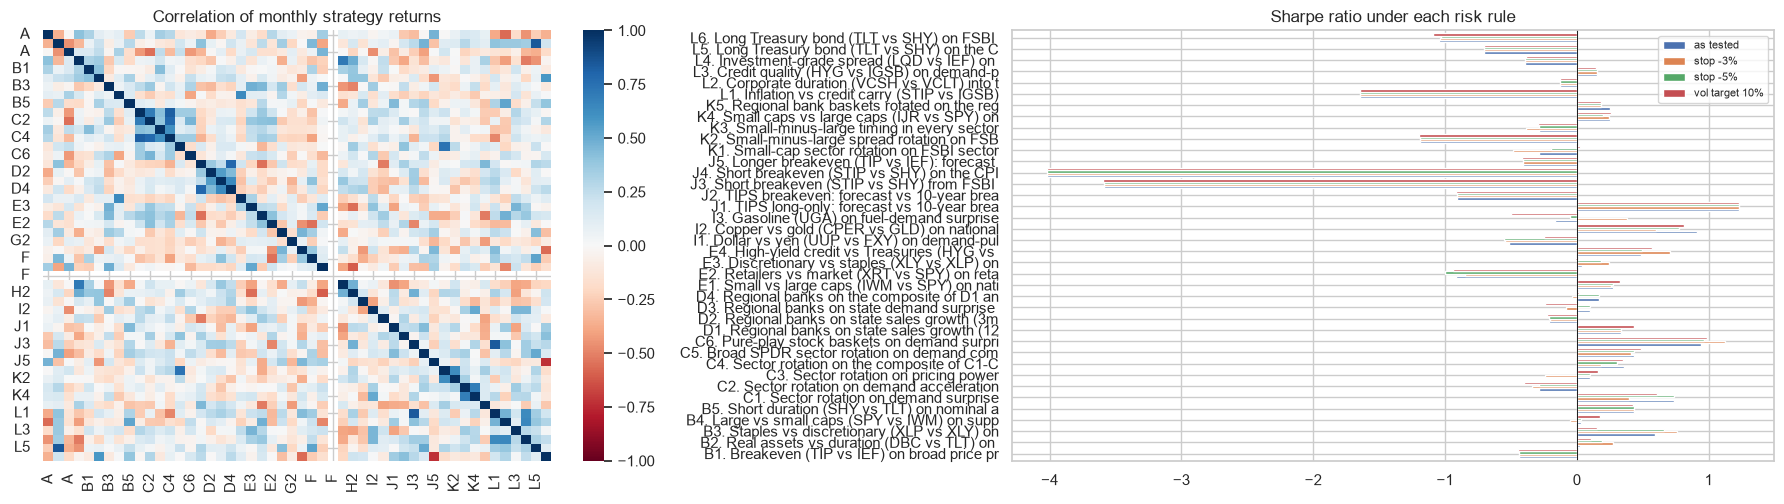

In [87]:
M = pd.DataFrame({n: to_monthly(s["daily"]) for n, s in STRATS.items()}).sort_index()          # full history, for charts and the dashboard
M_D = pd.DataFrame({n: stat_m(s["daily"]) for n, s in STRATS.items()}).sort_index()      # design period, for statistics
C = M_D.corr(min_periods=12)
def ivp(R):
    """Inverse-volatility portfolio: weights from the previous 12 months, renormalised each month over the strategies that have a return."""
    sd_ = R.rolling(12, min_periods=6).std().shift(1); w_ = (1 / sd_.where(sd_ > 1e-8)).where(R.notna()); w_ = w_.div(w_.sum(axis=1), axis=0)   # idle strategies (zero volatility) get no weight, not an infinite one
    return (w_ * R).sum(axis=1, min_count=1)
FAM = pd.DataFrame({fam: ivp(M[[n for n in M if STRATS[n]["family"] == fam]]) for fam in sorted({s["family"] for s in STRATS.values()})})
PORT = pd.DataFrame({"Inverse-volatility portfolio": ivp(M), "Family-balanced portfolio": ivp(FAM)}).dropna(how="all")
eig = np.clip(np.linalg.eigvalsh(C.fillna(0).values + np.eye(len(C)) * (C.isna().all().values)), 0, None); n_eff = eig.sum() ** 2 / (eig ** 2).sum()
FAM_D = pd.DataFrame({fam: ivp(M_D[[n for n in M_D if STRATS[n]["family"] == fam]]) for fam in FAM.columns})
PORT_D = pd.DataFrame({"Inverse-volatility portfolio": ivp(M_D), "Family-balanced portfolio": ivp(FAM_D)}).dropna(how="all")
port_tab = pd.DataFrame({c: {**perf(PORT_D[c]), "bootstrap p": boot_p(PORT_D[c]), **{k_: v_ for k_, v_ in alphas(PORT_D[c]).items() if k_ in ("Jensen's alpha (ann. %)", "Jensen's alpha t", "CAPM beta", "appraisal ratio", "two-factor alpha (ann. %)")}} for c in PORT}).T
print(f"{M.shape[1]} strategies behave like about {n_eff:.1f} independent bets (mean |correlation| {np.nanmean(np.abs(C.values[~np.eye(len(C), dtype=bool)])):.2f}). "
      f"Median single-strategy Sharpe: {BOARD.Sharpe.astype(float).median():.2f}. (Design period; the charts run through the newest month.)"); display(port_tab.round(3))

risk = {}
for n in [n for n in BOARD.index if STRATS[n]["trades"] is not None and BOARD.at[n, "family"][0] in "BCDEIJKL"]:
    tr = STRATS[n]["trades"]; d0 = STRATS[n]["daily"]
    lev = (0.10 / (d0.rolling(63).std() * np.sqrt(252))).shift(1).clip(upper=2.0).fillna(1.0)
    for tag, dd in (("as tested", d0), ("stop -3%", run_book(tr, stop=0.03)[0]), ("stop -5%", run_book(tr, stop=0.05)[0]), ("vol target 10%", d0 * lev)):
        p = perf(stat_m(dd)); risk[(n, tag)] = {k: p.get(k, np.nan) for k in ("ann. return (%)", "ann. vol (%)", "Sharpe", "max DD (%)")}
RISK = pd.DataFrame(risk).T
fig, axes = plt.subplots(1, 2, figsize=(18, 5.2), gridspec_kw={"width_ratios": [1, 1.2]})
ids = {n: n.split(".")[0] for n in C.index}
sns.heatmap(C.rename(index=ids, columns=ids), cmap="RdBu", center=0, vmin=-1, vmax=1, annot=len(C) <= 16, fmt=".1f", annot_kws={"size": 7}, ax=axes[0]); axes[0].set_title("Correlation of monthly strategy returns")
if len(RISK):
    RISK["Sharpe"].unstack().reindex(columns=["as tested", "stop -3%", "stop -5%", "vol target 10%"]).rename(index=lambda n: n[:44]).plot.barh(ax=axes[1], width=0.8)
    axes[1].axvline(0, color="k", lw=0.7); axes[1].set_title("Sharpe ratio under each risk rule"); axes[1].legend(fontsize=8)
plt.tight_layout()
if len(RISK):
    display(RISK["max DD (%)"].unstack().reindex(columns=["as tested", "stop -3%", "stop -5%", "vol target 10%"]).round(2).rename_axis("maximum drawdown (%)"))

### 4.3 Monte Carlo and sensitivity

Three simulations, each answering a question from the brief:

1. **What is the range of outcomes?** 2,000 block-bootstrap paths of the combined portfolio give a fan chart of cumulative return and the distribution of maximum drawdown.
2. **How much is a better forecast worth?** The surprise basket (4.A) is rerun with the forecast replaced by *the true print plus noise* of a chosen size. Zero noise is perfect foresight; the curve shows how fast the edge decays as forecast error grows, and the vertical lines mark the errors actually achieved by the selected model and by the market's own expectation. One caution: simulated noise is independent of the market's error, while a real forecast shares much of its error with the market, so real results sit below this curve.
3. **Optimistic and pessimistic scenarios.** The same strategy with the actual forecast shifted by ∓0.1pp, which shows the sensitivity to a systematic forecast bias.

Combined portfolio, Monte Carlo summary:


,value
P(total return > 0),0.16
median total return (%),-3.00
5th pct total return (%),-7.91
median max drawdown (%),-4.52
95th pct max drawdown (%),-8.40


Sharpe of the surprise basket by forecast error (sd, pp):


noise sd,0.000,0.025,0.050,0.075,0.100,0.150,0.200,0.300
target,,,,,,,,
CPI,0.99,0.95,0.81,0.64,0.53,0.38,0.24,0.07
core CPI,1.24,1.15,0.96,0.80,0.64,0.45,0.29,0.10


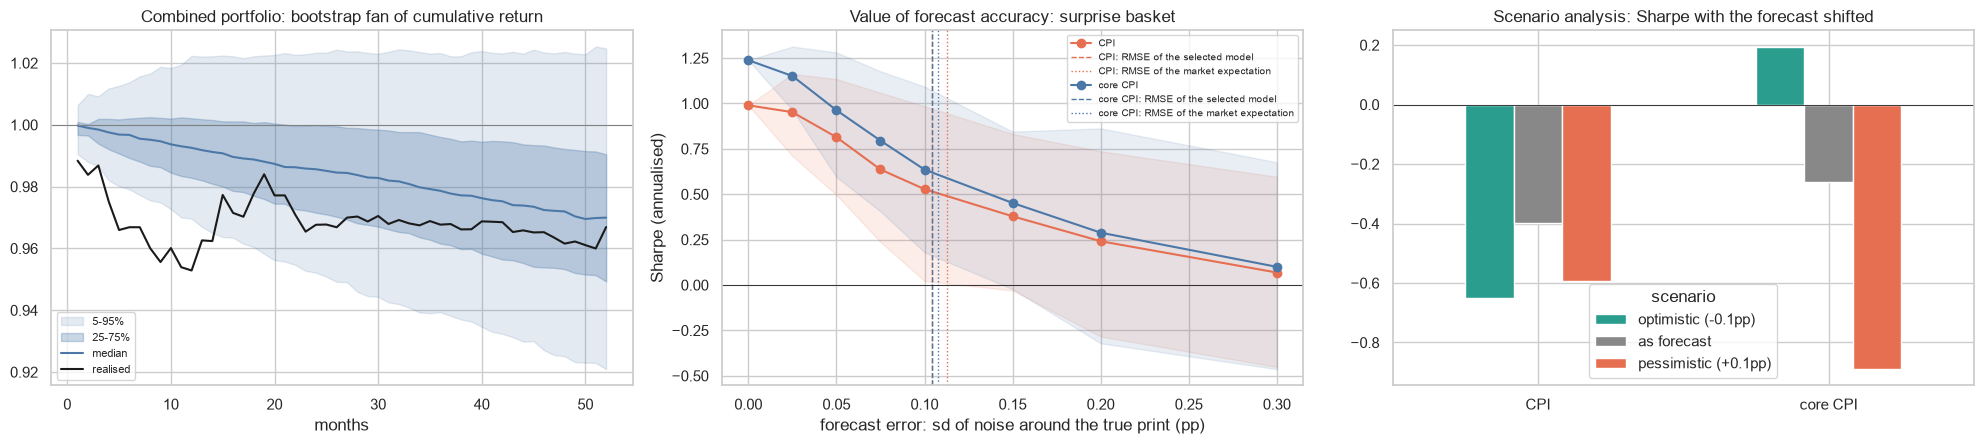

In [88]:
N_MC = 300 if FAST else 2000
fig, axes = plt.subplots(1, 3, figsize=(20, 4.6))
pr = PORT_D["Inverse-volatility portfolio"].dropna().values
if len(pr) >= 12:
    g_ = np.random.default_rng(SEED); starts = np.arange(len(pr) - 2)
    paths = np.array([np.cumprod(1 + np.concatenate([pr[s:s + 3] for s in g_.choice(starts, len(pr) // 3 + 1)])[:len(pr)]) for _ in range(N_MC)])
    q = np.percentile(paths, [5, 25, 50, 75, 95], axis=0); x = np.arange(1, len(pr) + 1)
    axes[0].fill_between(x, q[0], q[4], color="#4c78a8", alpha=0.15, label="5-95%"); axes[0].fill_between(x, q[1], q[3], color="#4c78a8", alpha=0.3, label="25-75%")
    axes[0].plot(x, q[2], color="#4c78a8", label="median"); axes[0].plot(x, np.cumprod(1 + pr), "k-", lw=1.5, label="realised"); axes[0].axhline(1, color="grey", lw=0.7)
    axes[0].set_title("Combined portfolio: bootstrap fan of cumulative return"); axes[0].set_xlabel("months"); axes[0].legend(fontsize=8)
    mdd = (paths / np.maximum.accumulate(paths, axis=1) - 1).min(axis=1)
    MC_SUMMARY = {"P(total return > 0)": float((paths[:, -1] > 1).mean()), "median total return (%)": 100 * (np.median(paths[:, -1]) - 1), "5th pct total return (%)": 100 * (np.percentile(paths[:, -1], 5) - 1),
                  "median max drawdown (%)": 100 * np.median(mdd), "95th pct max drawdown (%)": 100 * np.percentile(mdd, 5)}
else:
    MC_SUMMARY = {}; axes[0].text(0.5, 0.5, "too few months for the portfolio simulation", ha="center", transform=axes[0].transAxes)

NOISE = [0.0, 0.025, 0.05, 0.075, 0.10, 0.15, 0.20, 0.30]; DRAWS = 40 if FAST else 300; sens, marks = [], {}
basket = ANN_LEGS["Basket (equal weight of the four)"]; g_s = np.random.default_rng(SEED)
for k in ("core_cpi", "cpi"):
    if not set(basket) <= set(CLOSE.columns):
        continue
    unit = (window_ret(list(basket), f"{k}_pre", f"{k}_rel") * pd.Series(basket)).sum(axis=1, min_count=len(basket))
    d = pre(pd.concat({"u": unit, "y": Y[k], "e": EXPECT[k]}, axis=1).dropna()); cost2 = 2 * COST * sum(abs(v) for v in basket.values())
    def sharpe_of(fc):
        s = fc - d.e; pos = np.sign(s) * (np.abs(s) > DEADBAND); r = pos * d.u - cost2 * (pos != 0)
        return r.mean() / r.std() * np.sqrt(12) if r.std() > 0 else np.nan
    for sg in NOISE:
        v = [sharpe_of(d.y + g_s.normal(0, sg, len(d))) for _ in range(1 if sg == 0 else DRAWS)]
        sens.append({"target": LABEL[k], "noise sd": sg, "Sharpe": np.nanmean(v), "lo": np.nanpercentile(v, 10), "hi": np.nanpercentile(v, 90)})
    marks[LABEL[k]] = {"selected model": rmse((Y[k] - SEL[k]).reindex(d.index)), "market expectation": rmse(d.y - d.e)}
    for tag, shift in (("optimistic (-0.1pp)", -0.1), ("as forecast", 0.0), ("pessimistic (+0.1pp)", 0.1)):
        dd = d.loc[d.index.intersection(SEL[k].index)]; s = refresh(SEL[k], k).reindex(dd.index) + shift - dd.e; pos = np.sign(s) * (np.abs(s) > DEADBAND); r = pos * dd.u - cost2 * (pos != 0)
        sens.append({"target": LABEL[k], "scenario": tag, "Sharpe": r.mean() / r.std() * np.sqrt(12) if r.std() > 0 else np.nan, "mean (bp)": 1e4 * r.mean(), "trades": int((pos != 0).sum())})
SENS = pd.DataFrame(sens)
if len(SENS):
    curve = SENS[SENS["noise sd"].notna()]
    for (t, gdf), c in zip(curve.groupby("target"), ("#e76f51", "#4c78a8")):
        axes[1].plot(gdf["noise sd"], gdf.Sharpe, "-o", color=c, label=t); axes[1].fill_between(gdf["noise sd"], gdf.lo, gdf.hi, color=c, alpha=0.12)
        for (lbl, v), ls in zip(marks[t].items(), ("--", ":")):
            axes[1].axvline(v, color=c, ls=ls, lw=1, label=f"{t}: RMSE of the {lbl}")
    axes[1].axhline(0, color="k", lw=0.6); axes[1].set_xlabel("forecast error: sd of noise around the true print (pp)"); axes[1].set_ylabel("Sharpe (annualised)")
    axes[1].set_title("Value of forecast accuracy: surprise basket"); axes[1].legend(fontsize=7)
    sc = SENS[SENS.scenario.notna()].pivot(index="target", columns="scenario", values="Sharpe").reindex(columns=["optimistic (-0.1pp)", "as forecast", "pessimistic (+0.1pp)"])
    sc.plot.bar(ax=axes[2], color=["#2a9d8f", "#888888", "#e76f51"]); axes[2].axhline(0, color="k", lw=0.6); axes[2].set_title("Scenario analysis: Sharpe with the forecast shifted"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout()
if MC_SUMMARY:
    print("Combined portfolio, Monte Carlo summary:"); display(pd.Series(MC_SUMMARY).round(2).to_frame("value"))
if len(SENS):
    print("Sharpe of the surprise basket by forecast error (sd, pp):"); display(SENS[SENS["noise sd"].notna()].pivot(index="target", columns="noise sd", values="Sharpe").round(2))

## 5. Interactive dashboard

One self-contained Plotly page, written to `processed/fsbi_dashboard.html` (open it in any browser; no server needed), with four views:

1. **Forecasts vs actuals** for each target, with the Cleveland nowcast and Kalshi (dropdown), followed by the **model score table** per target.
2. **Feature importance**: the top features for each target under any view (overall, online-selected, or a single model such as Lasso), coloured by block, and the split of each model's importance across blocks.
3. **FSBI explorer**: sales, transactions and ticket for any sector, sub-sector or region (dropdown), and a map of the latest state sales growth.
4. **Strategy performance**: cumulative net return of every strategy, toggled by family.
5. **Leaderboard** table.

This page is a snapshot with dropdown filters only. The full interactive dashboard (FSBI trends, inflation predictions, trading results with drill-down and Monte Carlo, FSBI correlations) is the Streamlit app fed by section 7 at the end of the notebook.

In [89]:
try:
    import plotly.graph_objects as go
    import plotly.io as pio
    HAVE_PLOTLY = True
except ImportError:
    HAVE_PLOTLY = False; print("plotly is not installed (pip install plotly): the dashboard is skipped, the CSV exports are still written.")

def dropdown(fig, groups, title):
    """groups: {label: [trace indices]}; adds a dropdown that shows one group at a time."""
    n = len(fig.data)
    fig.update_layout(title=title, template="plotly_white", height=460, margin=dict(t=90),
                      updatemenus=[dict(x=0, y=1.16, xanchor="left", buttons=[dict(label=lab, method="update", args=[{"visible": [i in idx for i in range(n)]}]) for lab, idx in groups.items()])])
    first = next(iter(groups.values()))
    for i, tr in enumerate(fig.data):
        tr.visible = i in first
    return fig

if HAVE_PLOTLY:
    figs = []
    # 1. forecasts vs actuals
    fig, groups = go.Figure(), {}
    for k in TARGETS:
        f = OOS[k]; start = len(fig.data)
        fig.add_scatter(x=f.index, y=f.actual, name="first print", mode="lines+markers", line=dict(color="black"))
        fig.add_scatter(x=f.index, y=f.Anchor, name="Cleveland nowcast", line=dict(color="#1f77b4"))
        fig.add_scatter(x=SEL[k].index, y=SEL[k], name="selected model (with FSBI)", line=dict(color="#e76f51", width=3))
        fig.add_scatter(x=SEL_NOFSBI[k].index, y=SEL_NOFSBI[k], name="selected model (no FSBI)", line=dict(color="#e76f51", dash="dot"))
        if "Kalshi" in f:
            fig.add_scatter(x=f.index, y=f.Kalshi, name="Kalshi median", line=dict(color="#2a9d8f", dash="dash"))
        groups[LABEL[k]] = list(range(start, len(fig.data)))
    figs.append(dropdown(fig, groups, "Inflation forecasts vs first prints (MoM %, out-of-sample)").update_yaxes(title="% month on month"))
    # 1b. model scores (R2 = 1 - SSE/SST; negative means worse than the mean of the prints)
    fig, groups = go.Figure(), {}
    for k in TARGETS:
        t_ = ZOO_TAB.loc[LABEL[k]].round(3).reset_index().rename(columns={"index": "model"})
        fig.add_trace(go.Table(header=dict(values=list(t_.columns), fill_color="#264653", font=dict(color="white", size=11), align="left"), cells=dict(values=[t_[c] for c in t_.columns], align="left", font=dict(size=10), height=22)))
        groups[LABEL[k]] = [len(fig.data) - 1]
    figs.append(dropdown(fig, groups, "Model scores, out-of-sample (RMSE and MAE in pp; R2 = 1 - SSE/SST, can be negative; ratio below 1 beats the nowcast)").update_layout(height=430))
    # 1c. feature importance: overall, online-selected and per model, for each target
    fig, groups = go.Figure(), {}
    for k in TARGETS:
        for view in IMP_VIEWS:
            s = IMP[k][view].sort_values(ascending=False).head(15)[::-1]; s = s[s > 0]
            blocks = [BLOCK_NAME[BLOCK_OF.get(c, "mac")] for c in s.index]
            fig.add_bar(x=100 * s.values, y=list(s.index), orientation="h", marker_color=[BLOCK_COLOR[b] for b in blocks], customdata=blocks, hovertemplate="%{y}: %{x:.1f}%<br>%{customdata}<extra></extra>", showlegend=False)
            groups[f"{LABEL[k]} | {view}"] = [len(fig.data) - 1]
    f_imp = dropdown(fig, groups, "Feature importance: share of each model's permutation importance (top 15)").update_layout(height=520).update_xaxes(title="share of importance (%)")
    for b, c in BLOCK_COLOR.items():                         # colour key
        f_imp.add_bar(x=[None], y=[None], marker_color=c, name=b, showlegend=True)
    for btn in f_imp.layout.updatemenus[0].buttons:
        btn.args[0]["visible"] = list(btn.args[0]["visible"]) + [True] * len(BLOCK_COLOR)
    figs.append(f_imp)
    fig = go.Figure(); n_v = len(IMP_VIEWS); groups = {}
    for k in TARGETS:
        start = len(fig.data)
        for b, c in BLOCK_COLOR.items():
            fig.add_bar(y=IMP_VIEWS[::-1], x=100 * BLOCK_SHARE[k][b].values[::-1], orientation="h", name=b, marker_color=c)
        groups[LABEL[k]] = list(range(start, len(fig.data)))
    figs.append(dropdown(fig, groups, "Where each model's signal comes from: importance by feature block (%)").update_layout(barmode="stack", height=460).update_xaxes(title="share of importance (%)"))
    # 2. FSBI explorer + state map
    fig, groups = go.Figure(), {}
    for lvl in ("national", "sector", "subsector", "region"):
        for e in FSBI[lvl]["sales"].columns:
            start = len(fig.data)
            for m, c in (("sales", "#e76f51"), ("txn", "#4c78a8"), ("ticket", "#2a9d8f")):
                s = FSBI[lvl][m][e]; fig.add_scatter(x=s.index, y=100 * s / s.dropna().iloc[0], name={"sales": "sales", "txn": "transactions", "ticket": "ticket (sales / txn)"}[m], line=dict(color=c))
            groups[f"{lvl}: {e}"] = list(range(start, len(fig.data)))
    figs.append(dropdown(fig, groups, "FSBI explorer: index levels rebased to 100").update_yaxes(title="index"))
    yoy = g("state", "sales", 12).dropna(how="all").iloc[-1]
    figs.append(go.Figure(go.Choropleth(locations=yoy.index, z=yoy.values, locationmode="USA-states", colorscale="RdYlGn", zmid=0, colorbar_title="% YoY"))
                .update_layout(title=f"FSBI sales growth by state, year on year, {g('state', 'sales', 12).dropna(how='all').index[-1]:%B %Y}", geo_scope="usa", height=460, template="plotly_white"))
    # 3. strategies
    fig, groups = go.Figure(), {"All families": []}
    for n in BOARD.index:
        m = to_monthly(STRATS[n]["daily"]); fam = BOARD.at[n, "family"]
        gr = growth(m); fig.add_scatter(x=gr.index, y=gr.values, name=f"{n[:60]} (Sharpe {BOARD.at[n, 'Sharpe']:.2f})")
        groups["All families"].append(len(fig.data) - 1); groups.setdefault(fam, []).append(len(fig.data) - 1)
    for c in PORT:
        fig.add_scatter(x=PORT.index, y=(1 + PORT[c].fillna(0)).cumprod(), name=c, line=dict(color="black", width=3, dash="dash" if "Family" in c else "solid"))
        groups["All families"].append(len(fig.data) - 1); groups.setdefault("Combined portfolios", []).append(len(fig.data) - 1)
    figs.append(dropdown(fig, groups, "Strategy performance: growth of $1, net of costs").update_layout(height=560, legend=dict(font=dict(size=9))))
    # 4. leaderboard
    cols = ["family", "trades", "ROI (%)", "ann. return (%)", "ann. vol (%)", "Sharpe", "Sortino", "max DD (%)", "trade win rate", "bootstrap p", "Holm p", "reality-check p", "placebo p"]
    tb = BOARD[cols].round(3).reset_index().rename(columns={"index": "strategy"})
    figs.append(go.Figure(go.Table(header=dict(values=list(tb.columns), fill_color="#264653", font=dict(color="white", size=11), align="left"),
                                   cells=dict(values=[tb[c] for c in tb.columns], align="left", font=dict(size=10), height=24)))
                .update_layout(title="Leaderboard (ranked by Sharpe; trust the Holm and reality-check p-values)", height=120 + 26 * len(tb), margin=dict(l=10, r=10)))
    html = ["<html><head><meta charset='utf-8'><title>FSBI dashboard</title></head><body style='font-family:sans-serif;max-width:1250px;margin:auto'>",
            f"<h1>FSBI: inflation forecasts and trading strategies</h1><p>Generated {pd.Timestamp.now():%Y-%m-%d}. FSBI data through {IDX.max():%B %Y}; evaluation ends before {EVAL_END:%B %Y}"
            f"{'' if RUN_HOLDOUT else ' (holdout untouched)'}. Research tool, not investment advice.</p>"]
    html += [pio.to_html(f, full_html=False, include_plotlyjs="cdn" if i == 0 else False) for i, f in enumerate(figs)] + ["</body></html>"]
    (PROC / "fsbi_dashboard.html").write_text("\n".join(html), encoding="utf-8")
    print("dashboard written:", (PROC / "fsbi_dashboard.html").resolve())
    figs[0].show()

# exports: everything a BI tool or the final report needs
pd.concat({LABEL[k]: OOS[k].assign(selected=SEL[k], selected_no_fsbi=SEL_NOFSBI[k]) for k in TARGETS}, names=["target", "ref_month"]).to_csv(PROC / "forecasts_oos.csv")
M.rename_axis("month").to_csv(PROC / "strategy_monthly_returns.csv"); BOARD.rename_axis("strategy").to_csv(PROC / "leaderboard.csv")
ZOO_TAB.rename_axis(["target", "model"]).to_csv(PROC / "model_scores.csv"); ABLATION.to_csv(PROC / "fsbi_ablation.csv"); CURRENT.rename_axis("target").to_csv(PROC / "current_forecast.csv")
print("exports written to", PROC.resolve(), ":", sorted(p.name for p in PROC.glob("*.csv")))

dashboard written: C:\Users\liamf\OneDrive - Georgia Institute of Technology\QCF\Classes\Fall 2026\MGT 6785\QCF_Capstone_Fiserv\Data\processed\fsbi_dashboard.html


exports written to C:\Users\liamf\OneDrive - Georgia Institute of Technology\QCF\Classes\Fall 2026\MGT 6785\QCF_Capstone_Fiserv\Data\processed : ['current_forecast.csv', 'data_dictionary.csv', 'feature_importance.csv', 'forecasts_oos.csv', 'fsbi_ablation.csv', 'fsbi_macro_dataset.csv', 'leaderboard.csv', 'model_scores.csv', 'scorecard.csv', 'strategy_monthly_returns.csv']


## 6. Findings

The scorecard below is generated from this run, so it always matches the tables above. Each row is one place FSBI was put to work, the result, and the evidence standard it had to meet. "Evidence" means an out-of-sample improvement, a multiple-testing-adjusted p-value or a placebo, never a raw correlation.

In [90]:
card = []
a = ABLATION.iloc[:, 2]
card.append({"use of FSBI": "3.2 National inflation nowcast (remove FSBI from the full model)", "result": f"removing FSBI raised RMSE in {int((a > 0).sum())} of {len(a)} target x model cells (mean {a.mean():+.1f}%)",
             "evidence": f"{int((ABLATION['CW p'] < 0.10).sum())} cells significant (Clark-West p < 0.10)"})
for anchor, lab in (("none", "3.4 FSBI as a stand-alone leading indicator (vs AR)"), ("nowcast", "3.4 FSBI beyond the Cleveland nowcast"), ("kalshi", "3.4 FSBI beyond the Kalshi market")):
    if anchor in ANCHOR_TAB.index.get_level_values(0):
        t = ANCHOR_TAB.loc[anchor]; e = t["FSBI effect on RMSE (%)"]
        card.append({"use of FSBI": lab, "result": f"FSBI lowered RMSE in {int((e < 0).sum())} of {len(e)} cells (mean {e.mean():+.1f}%); beat the reference in {int((t['with FSBI / reference'] < 1).sum())}",
                     "evidence": f"{int((t['CW p (with vs without)'] < 0.10).sum())} significant (Clark-West); {int(t.months.median())} out-of-sample months"})
for lab, tab in (("3.5 CPI component nowcasts from matched sub-sectors", COMP_TAB), ("3.5 Regional CPI from regional FSBI", REGION_TAB)):
    if len(tab):
        card.append({"use of FSBI": lab, "result": f"FSBI improved {int((tab.ratio < 1).sum())} of {len(tab)}" + (f"; best: {tab.ratio.astype(float).idxmin()} (ratio {tab.ratio.min():.2f})" if (tab.ratio < 1).any() else ""),
                     "evidence": f"{int((tab['CW p'] < 0.10).sum())} significant (Clark-West)"})
fs = FSBI_SHARE.loc["Online-selected forecast"]
card.append({"use of FSBI": "3.7 FSBI's share of the selected forecast's feature importance", "result": "; ".join(f"{t}: {v:.0f}%" for t, v in fs.items()), "evidence": "in-sample permutation importance (descriptive)"})
for lab, tab in (("3.8 National activity nowcasts (retail sales, PCE, payrolls, CFNAI)", ECON_NAT), ("3.8 Census retail sales by kind of business from FSBI sub-sectors", ECON_SEC), ("3.8 State economies (unemployment, coincident index; pooled panel)", ECON_STATE)):
    if len(tab):
        num = tab.apply(pd.to_numeric, errors="coerce"); best = num.ratio.idxmin()
        card.append({"use of FSBI": lab, "result": f"FSBI lowered RMSE in {int((num.ratio < 1).sum())} of {len(tab)}; best: {best if isinstance(best, str) else ' / '.join(best)} (ratio {num.ratio.min():.2f})",
                     "evidence": f"{int((num['CW p'] < 0.10).sum())} significant (Clark-West)"})
if len(LEADS):
    card.append({"use of FSBI": "3.9 Leading-indicator scan (Granger, both directions)", "result": f"FSBI leads {int((BEST_LEAD.verdict == 'FSBI leads').sum())} of {len(BEST_LEAD)} series; two-way {int((BEST_LEAD.verdict == 'two-way').sum())}; "
                 + (f"strongest: {BEST_LEAD.index[0]} ({BEST_LEAD['FSBI measure'].iloc[0]})" if len(BEST_LEAD) else ""), "evidence": "Holm-adjusted Granger p < 0.10 FSBI -> series and not the reverse (in sample)"})
if len(COMB_TAB):
    card.append({"use of FSBI": "3.6c Selected forecast combined with the nowcast", "result": "; ".join(f"{t}: ratio {r['combination / nowcast RMSE']:.2f}, weight {r['mean weight']:.2f}" for t, r in COMB_TAB.iterrows()),
                 "evidence": f"{int((COMB_TAB['CW p (combination vs nowcast)'] < 0.10).sum())} of {len(COMB_TAB)} targets at Clark-West p < 0.10; hit rate when model and nowcast disagree most: "
                             + ", ".join(f"{t} {r['hit rate, large disagreement']:.2f}" for t, r in COMB_TAB.iterrows())})
if len(MACRO_READS):
    _b = MACRO_READS.sort_values("p").iloc[0]
    card.append({"use of FSBI": "3.10 Spending mix, dispersion, price vs volume, acceleration as predictors", "result": f"{int((MACRO_READS.p < 0.10).sum())} of {len(MACRO_READS)} tests at raw p < 0.10; strongest: {_b['FSBI indicator'].split(' (')[0]} -> {_b['target']} ({_b['horizon']}, t = {_b['t-stat']:.2f})",
                 "evidence": f"{int((MACRO_READS['Holm p'] < 0.10).sum())} survive Holm; {int(((MACRO_READS.p < 0.10) & (MACRO_READS['shift p'] < 0.10)).sum())} also pass the shift test"})
if REVISION:
    card.append({"use of FSBI": "3.10 Predicting revisions to advance retail sales", "result": f"effect {REVISION['effect per 1 sd']:+.3f}pp per 1 sd gap (mean absolute revision {REVISION['mean absolute revision (pp)']:.2f}pp)", "evidence": f"t = {REVISION['t-stat']:.2f}, p = {REVISION['p']:.3f}"})
if len(FSBI_EVENT):
    card.append({"use of FSBI": "3.10 Market reaction on the FSBI release day", "result": f"{int((FSBI_EVENT.p < 0.10).sum())} of {len(FSBI_EVENT)} assets move with the surprise; release-day / other-day volatility {FSBI_EVENT.ratio.mean():.2f}",
                 "evidence": "no reaction = not priced on arrival"})
if len(ALPHA):
    _jh = ALPHA["Jensen's alpha Holm p"] if "Jensen's alpha Holm p" in ALPHA else pd.Series(dtype=float)
    _top = ALPHA.iloc[0]
    _ja, _jt = "Jensen's alpha (ann. %)", "Jensen's alpha t"
    card.append({"use of FSBI": "4.1c Jensen's alpha (CAPM) and two-factor alpha (SPY + IEF)", "result": f"{int((pd.to_numeric(ALPHA[_ja]) > 0).sum())} of {len(ALPHA)} positive; highest {ALPHA.index[0].split('.')[0]} at {_top[_ja]:.2f}% a year (t = {_top[_jt]:.2f})",
                 "evidence": f"{int(((_jh < 0.10) & (pd.to_numeric(ALPHA[_ja]) > 0)).sum())} positive alphas survive Holm"})
if len(REVERSALS) and "reversed Sharpe" in REVERSALS:
    _op = REVERSALS[REVERSALS.diagnosis.astype(str).str.startswith("opposite")]
    card.append({"use of FSBI": "4.1b Reversing the strategies that lost badly", "result": f"{len(REVERSALS)} strategies below Sharpe {REV_THRESHOLD}; {len(_op)} with the opposite sign profitable, {int(REVERSALS.diagnosis.astype(str).str.startswith('drift').sum())} explained by drift, {int(REVERSALS.diagnosis.astype(str).str.startswith('costs').sum())} by costs and noise",
                 "evidence": f"{int((pd.to_numeric(REVERSALS['reversed Holm p'], errors='coerce') < 0.10).sum())} reversals survive Holm; {int(REVERSALS['holds live'].sum())} keep the reversed sign live"})
if len(L_GRID):
    card.append({"use of FSBI": "4.L Draft fixed income grid (2 independent signal types x 18 pairs)", "result": f"{int((L_GRID.p[~L_GRID['signal type'].str.startswith('C')] < 0.10).sum())} of {int((~L_GRID['signal type'].str.startswith('C')).sum())} at raw p < 0.10; best Sharpe {L_GRID.Sharpe.max():.2f}", "evidence": f"{int((L_GRID['Holm p'] < 0.10).sum())} survive Holm"})
if len(SC_IC):
    _ic = SC_IC.xs("1 month ahead", level=1) if "1 month ahead" in SC_IC.index.get_level_values(1) else SC_IC
    card.append({"use of FSBI": "4.K Sector signal as a leading indicator for small caps (1 month)", "result": "; ".join(f"{i}: IC {r['mean IC']:+.3f}" for i, r in _ic.iterrows()),
                 "evidence": "; ".join(f"{i.split()[0]} t = {r['t-stat (Newey-West)']:.2f}" for i, r in _ic.iterrows())})
card.append({"use of FSBI": "3.6 Selected forecast vs nowcast", "result": "; ".join(f"{t}: ratio {r['ratio']:.2f} ({r['90% interval']})" for t, r in SEL_TAB.iterrows()),
             "evidence": f"{int((SEL_TAB['DM p'].astype(float) < 0.10).sum())} of {len(SEL_TAB)} targets significant"})
for fam, grp in BOARD.groupby("family"):
    best = grp.Sharpe.astype(float).idxmax(); pl = grp["placebo p"].astype(float)
    card.append({"use of FSBI": f"4.{fam}", "result": f"{len(grp)} strategies; best Sharpe {grp.Sharpe.max():.2f} ({best.split('. ', 1)[-1][:50]}); {int((grp.Sharpe.astype(float) > 0).sum())} positive",
                 "evidence": f"{int((grp['Holm p'] < 0.10).sum())} survive Holm; {int((grp['reality-check p'] < 0.10).sum())} pass the reality check; {int((pl < 0.10).sum())} of {int(pl.notna().sum())} pass the placebo"})
if len(ATTRIB):
    card.append({"use of FSBI": "4.1 FSBI vs its no-FSBI twin (families A, F)", "result": f"FSBI version ahead in {int((ATTRIB['difference (bp)'] > 0).sum())} of {len(ATTRIB)} comparisons",
                 "evidence": f"{int((ATTRIB['t-stat of difference'].astype(float) > 1.65).sum())} with t > 1.65"})
if len(port_tab) and "Sharpe" in port_tab:
    if "Family-balanced portfolio" in port_tab.index:
        card.append({"use of FSBI": "4.2 Family-balanced portfolio (the one pre-specified test)", "result": f"Sharpe {port_tab.at['Family-balanced portfolio', 'Sharpe']:.2f}, max drawdown {port_tab.at['Family-balanced portfolio', 'max DD (%)']:.1f}%",
                     "evidence": f"bootstrap p = {port_tab.at['Family-balanced portfolio', 'bootstrap p']:.2f} (no multiple-testing adjustment needed)"})
    card.append({"use of FSBI": "4.2 Combined portfolio (inverse volatility)", "result": f"Sharpe {port_tab.at['Inverse-volatility portfolio', 'Sharpe']:.2f}, max drawdown {port_tab.at['Inverse-volatility portfolio', 'max DD (%)']:.1f}%, about {n_eff:.1f} independent bets",
                 "evidence": f"bootstrap p = {port_tab.at['Inverse-volatility portfolio', 'bootstrap p']:.2f}"})
SCORECARD = pd.DataFrame(card).set_index("use of FSBI"); SCORECARD.to_csv(PROC / "scorecard.csv")
with pd.option_context("display.max_colwidth", 140):
    display(SCORECARD)

,result,evidence
use of FSBI,,
3.2 National inflation nowcast (remove FSBI from the full model),removing FSBI raised RMSE in 6 of 12 target x model cells (mean -3.2%),4 cells significant (Clark-West p < 0.10)
3.4 FSBI as a stand-alone leading indicator (vs AR),FSBI lowered RMSE in 1 of 8 cells (mean +12.7%); beat the reference in 5,1 significant (Clark-West); 30 out-of-sample months
3.4 FSBI beyond the Cleveland nowcast,FSBI lowered RMSE in 3 of 8 cells (mean +4.3%); beat the reference in 1,3 significant (Clark-West); 30 out-of-sample months
3.4 FSBI beyond the Kalshi market,FSBI lowered RMSE in 2 of 4 cells (mean +11.1%); beat the reference in 1,1 significant (Clark-West); 23 out-of-sample months
3.5 CPI component nowcasts from matched sub-sectors,FSBI improved 6 of 14; best: Gas stations -> CUSR0000SETB01 (ratio 0.91),6 significant (Clark-West)
3.5 Regional CPI from regional FSBI,FSBI improved 1 of 4; best: Northeast (ratio 0.95),1 significant (Clark-West)
3.7 FSBI's share of the selected forecast's feature importance,CPI: 30%; core CPI: 0%; PCE: 54%; core PCE: 63%,in-sample permutation importance (descriptive)
"3.8 National activity nowcasts (retail sales, PCE, payrolls, CFNAI)",FSBI lowered RMSE in 5 of 11; best: Food services and drinking places sales (ratio 0.87),5 significant (Clark-West)
3.8 Census retail sales by kind of business from FSBI sub-sectors,FSBI lowered RMSE in 5 of 10; best: Gas stations -> RSGASS (ratio 0.60),7 significant (Clark-West)


### How to read the scorecard, and what it means for Fiserv

**Three kinds of value, in order of how much evidence each needs.**

1. **FSBI as a nowcasting input** (rows 3.x). The bar is the Cleveland nowcast and, harder, Kalshi. A block that lowers RMSE consistently across targets and models in 3.2, even without individual significance, is a credible input; a single green cell is not. Where the national result is weak, look at 3.5: component and regional nowcasts are where FSBI has no public substitute, and they are a product in themselves (a small-business *price* index by sector and state, weeks ahead of BLS).
2. **FSBI as a regime indicator** (family B). The demand-pull / supply-squeeze split is a monthly, sector-level version of a decomposition the Federal Reserve publishes with a lag. Its value does not depend on beating a forecast benchmark: it is a descriptive product (which sectors are raising prices with or against volume) that also yields testable allocation rules.
3. **FSBI as a trading signal** (families A to L). Here the standard is the Holm-adjusted p-value and the placebo. Strategies that pass are candidates for the holdout and paper trading. Strategies that fail because the *ideal* signal works but the model's does not (4.A) say the forecast is not yet accurate enough, and the value-of-accuracy curve in 4.3 says how much accuracy would be needed. Strategies in D are the ones where FSBI's granularity is unique: no public source reports monthly small-business sales by state.

**Limits that apply to every number here.**

- **Short sample.** About thirty out-of-sample forecast months and forty trading months. Most intervals in this notebook include "no effect"; that is a statement about the sample, not about FSBI.
- **Design vs live period.** Every statistic used to choose a model or strategy is computed on months before `HOLDOUT_START`; the forecasts and backtests continue through the newest month as a live track record, reported separately. Do not change the design because of the live results.
- **Multiple testing.** Some thirty strategies and dozens of model configurations were tried; the Holm and reality-check columns and the placebo are the guards. The best raw Sharpe on any board this size is partly luck.
- **Data assumptions.** FSBI is assumed available on the 6th (`FSBI_DAY`) unless `fsbi_release_dates.csv` gives the date; macro features use latest-vintage data with a one-month lag; failed banks count only if Yahoo still serves them; unpublished CPI months (October 2025) are estimated for lags only; Kalshi fills are at the day's closing quote for one small position. FSBI itself may be revised, and this file is a single vintage.

### What changed from v3

| v3 | here | why |
|---|---|---|
| Parts A and B each loaded FSBI, FRED and prices (87 duplicated names behind an `ms_` prefix) | one data layer (section 1) | one source of truth |
| Track A / Track B, lag-treatment grid, Kalshi median-vs-mean comparison, regional two-stage model | one `design(target, blocks, anchor)` with three anchors | the anchor *is* the question being asked |
| vintage tracking for 24 macro series; state population from 50 FRED calls | one-month publication-lag rule; fixed Census weights | far fewer downloads; first-print targets kept |
| keyword matching of sector names to ETFs and CPI components | explicit `SUBMAP` table | auditable |
| three backtest systems (vectorised monthly, backtrader replay, quantstats) | one daily engine with stop, delay and placebo options | identical costs and metrics everywhere |
| ~45 strategies, many variants of one idea | 12 families, each tied to published research or an explicit economic argument, with no-FSBI twins and one primary strategy per family | fewer tests, clearer attribution |
| Kalshi Greeks (Part D), PDF generator (Part E), product-price contracts against an assumed market | removed | no downstream dependency; not backed by tradable quotes |

### References

**Inflation forecasting and nowcasting**
- Bates, J. & Granger, C. (1969). The combination of forecasts. *Operational Research Quarterly* 20(4).
- Knotek, E. & Zaman, S. (2017). Nowcasting U.S. headline and core inflation. *Journal of Money, Credit and Banking* 49(5).
- Faust, J. & Wright, J. (2013). Forecasting inflation. *Handbook of Economic Forecasting*, vol. 2A.
- Medeiros, M., Vasconcelos, G., Veiga, Á. & Zilberman, E. (2021). Forecasting inflation in a data-rich environment: the benefits of machine learning methods. *Journal of Business & Economic Statistics* 39(1).
- Shapiro, A. (2022). How much do supply and demand drive inflation? *FRBSF Economic Letter* 2022-15; Shapiro, A. (2024). Decomposing supply- and demand-driven inflation. *Journal of Money, Credit and Banking*.
- Aladangady, A., Aron-Dine, S., Dunn, W., Feiveson, L., Lengermann, P. & Sahm, C. (2022). From transactions data to economic statistics: constructing real-time, high-frequency, geographic measures of consumer spending. In *Big Data for Twenty-First-Century Economic Statistics*, NBER / University of Chicago Press.
- Diebold, F. & Mariano, R. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics* 13(3).
- Clark, T. & West, K. (2007). Approximately normal tests for equal predictive accuracy in nested models. *Journal of Econometrics* 138(1).
- Galbraith, J. & Tkacz, G. (2018). Nowcasting with payments system data. *International Journal of Forecasting* 34(2).
- Aprigliano, V., Ardizzi, G. & Monteforte, L. (2019). Using payment system data to forecast economic activity. *International Journal of Central Banking* 15(4).
- Chetty, R., Friedman, J., Stepner, M. & the Opportunity Insights Team (2024). The economic impacts of COVID-19: evidence from a new public database built using private sector data. *Quarterly Journal of Economics* 139(2).

**Inflation and asset prices**
- Balduzzi, P., Elton, E. & Green, T. C. (2001). Economic news and bond prices: evidence from the U.S. Treasury market. *Journal of Financial and Quantitative Analysis* 36(4).
- Gürkaynak, R., Kısacıkoğlu, B. & Wright, J. (2020). Missing events in event studies: identifying the effects of partially measured news surprises. *American Economic Review* 110(12).
- Knox, B. & Timmer, Y. (2025). Stagflationary stock returns. Finance and Economics Discussion Series 2025-056, Federal Reserve Board.
- Fang, X., Liu, Y. & Roussanov, N. (2022). Getting to the core: inflation risks within and across asset classes. NBER Working Paper 30169.
- Cieslak, A. & Pflueger, C. (2023). Inflation and asset returns. *Annual Review of Financial Economics* 15.
- Neville, H., Draaisma, T., Funnell, B., Harvey, C. & Van Hemert, O. (2021). The best strategies for inflationary times. *Journal of Portfolio Management* 47(8).

- Andersen, T., Bollerslev, T., Diebold, F. & Vega, C. (2003). Micro effects of macro announcements: real-time price discovery in foreign exchange. *American Economic Review* 93(1).
- Beber, A. & Brandt, M. (2006). The effect of macroeconomic news on beliefs and preferences: evidence from the options market. *Journal of Monetary Economics* 53(8).
- Ederington, L. & Lee, J. H. (1993). How markets process information: news releases and volatility. *Journal of Finance* 48(4).

- Gürkaynak, R., Levin, A. & Swanson, E. (2010). Does inflation targeting anchor long-run inflation expectations? Evidence from the U.S., UK, and Sweden. *Journal of the European Economic Association* 8(6).
- Fleckenstein, M., Longstaff, F. & Lustig, H. (2014). The TIPS-Treasury bond puzzle. *Journal of Finance* 69(5).

**Spending data, local information and returns**
- Agarwal, S., Qian, W. & Zou, X. (2021). Disaggregated sales and stock returns. *Management Science* 67(11).
- Froot, K., Kang, N., Ozik, G. & Sadka, R. (2017). What do measures of real-time corporate sales say about earnings surprises and post-announcement returns? *Journal of Financial Economics* 125(1).
- Hong, H., Torous, W. & Valkanov, R. (2007). Do industries lead stock markets? *Journal of Financial Economics* 83(2).
- Korniotis, G. & Kumar, A. (2013). State-level business cycles and local return predictability. *Journal of Finance* 68(3).
- Smajlbegovic, E. (2019). Regional economic activity and stock returns. *Journal of Financial and Quantitative Analysis* 54(3).
- Gilchrist, S. & Zakrajšek, E. (2012). Credit spreads and business cycle fluctuations. *American Economic Review* 102(4).
- Hou, K. & Moskowitz, T. (2005). Market frictions, price delay, and the cross-section of expected returns. *Review of Financial Studies* 18(3).
- Kang, J. & Pflueger, C. (2015). Inflation risk in corporate bonds. *Journal of Finance* 70(1).
- Chang, E. & Pinegar, J. M. (1986). Inflation and rates of return on long-term bonds. *Economics Letters* 20(2).
- Hong, H., Sraer, D. & Yu, J. (2017). Inflation bets on the long bond. *Review of Financial Studies* 30(3).
- Jensen, M. (1968). The performance of mutual funds in the period 1945-1964. *Journal of Finance* 23(2).
- Treynor, J. & Black, F. (1973). How to use security analysis to improve portfolio selection. *Journal of Business* 46(1).
- Gilchrist, S. & Zakrajšek, E. (2012). Credit spreads and business cycle fluctuations. *American Economic Review* 102(4).
- Hong, H., Lim, T. & Stein, J. (2000). Bad news travels slowly: size, analyst coverage, and the profitability of momentum strategies. *Journal of Finance* 55(1).
- Gertler, M. & Gilchrist, S. (1994). Monetary policy, business cycles, and the behavior of small manufacturing firms. *Quarterly Journal of Economics* 109(2).

**Prediction markets, sizing and inference**
- Wolfers, J. & Zitzewitz, E. (2004). Prediction markets. *Journal of Economic Perspectives* 18(2).
- Diercks, A., Katz, J. D. & Wright, J. (2026). Kalshi and the rise of macro markets. Finance and Economics Discussion Series 2026-010, Federal Reserve Board.
- Kelly, J. (1956). A new interpretation of information rate. *Bell System Technical Journal* 35(4).
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics* 6(2).
- Harvey, C., Liu, Y. & Zhu, H. (2016). …and the cross-section of expected returns. *Review of Financial Studies* 29(1).
- White, H. (2000). A reality check for data snooping. *Econometrica* 68(5).
- Granger, C. (1969). Investigating causal relations by econometric models and cross-spectral methods. *Econometrica* 37(3).
- Politis, D. & Romano, J. (1994). The stationary bootstrap. *Journal of the American Statistical Association* 89(428).

## 7. Export for the interactive dashboard app

The Plotly page above is a static snapshot. The full interactive dashboard is the Streamlit app `app.py`, which reads only the files written here (`Data/processed/dashboard/`), so it opens instantly and needs no access to FRED, Kalshi or Yahoo. A running dashboard picks up a new run automatically on its next page refresh. To start it:

```
pip install streamlit plotly
streamlit run app.py
```

| file | feeds |
|---|---|
| `fsbi.csv` | FSBI explorer: every national, sector, sub-sector, state and region series |
| `inflation.csv`, `model_scores.csv`, `ladder.csv`, `ablation.csv`, `anchor_test.csv`, `component_tests.csv`, `region_tests.csv` | forecast charts (MoM and YoY), model comparison, what FSBI adds |
| `feature_importance.csv` | importance by target, model and block |
| `strategies_monthly.csv`, `strategies_trades.csv`, `strategies_daily.csv`, `leaderboard.csv`, `risk.csv`, `attribution.csv`, `portfolios.csv` | strategy performance, drawdowns, leaderboard filters |
| `signals.csv`, `strategy_signals.csv`, `window_returns.csv`, `sector_signals.csv` | strategy drill-down (each strategy's recipe and signal thresholds) and the signal-vs-asset tool on the correlations page |
| `econ_national.csv`, `econ_sector_sales.csv`, `econ_state.csv`, `econ_state_map.csv` | economic applications (section 3.8) |
| `sensitivity.csv`, `scorecard.csv`, `meta.json` | Monte Carlo and sensitivity, findings, current forecasts and latest signals |

In [91]:
DASH = PROC / "dashboard"; DASH.mkdir(parents=True, exist_ok=True)

# FSBI panel, long format
parts = []
for lvl, nice in (("national", "National"), ("sector", "Sector"), ("subsector", "Subsector"), ("state", "State"), ("region", "Region"), ("region_sector", "Region x sector")):
    for e in FSBI[lvl]["sales"].columns:
        region = STATE_REGION.get(e, "") if lvl == "state" else e if lvl == "region" else e.split(" | ")[0] if lvl == "region_sector" else ""
        parts.append(pd.DataFrame({"date": IDX, "level": nice, "name": e.split(" | ")[-1], "region": region, "sales_index": FSBI[lvl]["sales"][e].values,
                                   "txn_index": FSBI[lvl]["txn"][e].values, "ticket_index": FSBI[lvl]["ticket"][e].values}))
pd.concat(parts).to_csv(DASH / "fsbi.csv", index=False)
SHAPIRO.assign(z_demand_pull=z_dp, z_supply_squeeze=z_ss).rename_axis("date").to_csv(DASH / "regime.csv")

# forecasts, MoM and bridged to YoY with the latest seasonally adjusted index: YoY_t = (1 + MoM_t) x I(t-1) / I(t-12) - 1
def to_yoy(mom, k):
    lvl = LATEST[k]; return ((1 + mom / 100) * lvl.shift(1).reindex(mom.index) / lvl.shift(12).reindex(mom.index) - 1) * 100
inf = []
for k in TARGETS:
    f = OOS[k]; series = {"Cleveland nowcast": f.Anchor, **{m: f[m] for m in MODEL_NAMES}, "Online-selected (with FSBI)": SEL[k], "Online-selected (no FSBI)": SEL_NOFSBI[k]}
    if "Kalshi" in f:
        series["Kalshi median"] = f.Kalshi
    actual_yoy = (LATEST[k].pct_change(12, fill_method=None) * 100)
    if k in LIVE:                                              # every model's forecast for the live month, so the history charts end at the newest FSBI month
        for name in list(series):
            v = LIVE[k]["preds"].get(name, LIVE[k]["nowcast"] if name == "Cleveland nowcast" else KAL.at[LIVE_MONTH, k] if name == "Kalshi median" and k in KAL else None)
            if v is not None and pd.notna(v) and LIVE_MONTH not in series[name].dropna().index:
                series[name] = pd.concat([series[name], pd.Series({LIVE_MONTH: v})])
    for name, s in series.items():
        s = s.dropna().astype(float); s = s[~s.index.duplicated(keep="last")].sort_index()
        inf.append(pd.DataFrame({"date": s.index, "target": LABEL[k], "model": name, "forecast": s.values, "actual": Y[k].reindex(s.index).values,
                                 "period": np.where(s.index >= EVAL_END, "live", "design"),
                                 "forecast_yoy": to_yoy(s, k).values, "actual_yoy": actual_yoy.reindex(s.index).values}))
    h = Y[k].dropna(); inf.append(pd.DataFrame({"date": h.index, "target": LABEL[k], "model": "First print (history)", "forecast": h.values, "actual": h.values, "period": np.where(h.index >= EVAL_END, "live", "design"),
                                                "forecast_yoy": actual_yoy.reindex(h.index).values, "actual_yoy": actual_yoy.reindex(h.index).values}))
pd.concat(inf).to_csv(DASH / "inflation.csv", index=False)
ZOO_TAB.rename_axis(["target", "model"]).reset_index().to_csv(DASH / "model_scores.csv", index=False)
LAD.to_csv(DASH / "ladder.csv", index=False); ABLATION.reset_index().to_csv(DASH / "ablation.csv", index=False); ANCHOR_TAB.reset_index().to_csv(DASH / "anchor_test.csv", index=False)
COMP_TAB.rename_axis("pair").reset_index().to_csv(DASH / "component_tests.csv", index=False); REGION_TAB.rename_axis("region").reset_index().to_csv(DASH / "region_tests.csv", index=False)
pd.concat({LABEL[k]: IMP[k].assign(block=[BLOCK_NAME[BLOCK_OF.get(c, "mac")] for c in IMP[k].index]) for k in TARGETS}, names=["target", "feature"]).reset_index() \
    .melt(id_vars=["target", "feature", "block"], var_name="view", value_name="share").to_csv(DASH / "feature_importance.csv", index=False)

# strategies
fam_of = {n: s["family"] for n, s in STRATS.items()}
M.rename_axis("date").reset_index().melt(id_vars="date", var_name="strategy", value_name="ret").dropna().assign(family=lambda d: d.strategy.map(fam_of)).to_csv(DASH / "strategies_monthly.csv", index=False)
D = pd.DataFrame({n: s["daily"] for n, s in STRATS.items()}); D = D.loc[D.ne(0).any(axis=1).idxmax():]
D.rename_axis("date").reset_index().melt(id_vars="date", var_name="strategy", value_name="ret").query("ret != 0").assign(family=lambda d: d.strategy.map(fam_of)).to_csv(DASH / "strategies_daily.csv", index=False)
pd.concat([s["per"].rename("ret").rename_axis("date").reset_index().assign(strategy=n, family=s["family"]) for n, s in STRATS.items()]).to_csv(DASH / "strategies_trades.csv", index=False)
lb = BOARD.copy()
lb["Calmar"] = lb["ann. return (%)"] / lb["max DD (%)"].abs().replace(0, np.nan)
lb["profit factor"] = pd.Series({n: (lambda m: m[m > 0].sum() / -m[m < 0].sum() if (m < 0).any() else np.nan)(M[n].dropna()) for n in lb.index})
lb.rename_axis("strategy").reset_index().to_csv(DASH / "leaderboard.csv", index=False)
for name, tab in (("econ_national.csv", ECON_NAT), ("econ_sector_sales.csv", ECON_SEC)):
    tab.rename_axis("target").reset_index().to_csv(DASH / name, index=False)
(ECON_STATE.rename_axis(["target", "version"]).reset_index() if len(ECON_STATE) else pd.DataFrame()).to_csv(DASH / "econ_state.csv", index=False)
ECON_MAP.rename("corr").rename_axis("state").reset_index().to_csv(DASH / "econ_state_map.csv", index=False)
LEADS.to_csv(DASH / "econ_leads.csv", index=False)
MACRO_READS.to_csv(DASH / "macro_reads.csv", index=False); FSBI_EVENT.to_csv(DASH / "fsbi_event.csv", index=False); L_GRID.to_csv(DASH / "fixed_income_grid.csv", index=False)
(HSY_TESTS.rename_axis("test").reset_index() if len(HSY_TESTS) else pd.DataFrame()).to_csv(DASH / "disagreement_tests.csv", index=False)
(REVERSALS.rename_axis("strategy").reset_index() if len(REVERSALS) else pd.DataFrame()).to_csv(DASH / "reversals.csv", index=False)
MX.rename_axis("date").to_csv(DASH / "macro_indicators.csv")
pd.DataFrame({f"{s} | {x}": v for (s, x), v in LEAD_CORR.items()}).rename_axis("lead").reset_index().melt(id_vars="lead", var_name="pair", value_name="corr") \
    .assign(series=lambda d: d.pair.str.split(" \\| ").str[0], measure=lambda d: d.pair.str.split(" \\| ").str[1]).drop(columns="pair").to_csv(DASH / "econ_lead_profiles.csv", index=False)
(SC_IC.rename_axis(["returns", "horizon"]).reset_index() if len(SC_IC) else pd.DataFrame()).to_csv(DASH / "smallcap_ic.csv", index=False)
(RISK.rename_axis(["strategy", "rule"]).reset_index() if len(RISK) else pd.DataFrame()).to_csv(DASH / "risk.csv", index=False)
(ATTRIB.rename_axis(["strategy", "control"]).reset_index() if len(ATTRIB) else pd.DataFrame()).to_csv(DASH / "attribution.csv", index=False)
PORT.rename_axis("date").to_csv(DASH / "portfolios.csv"); SENS.to_csv(DASH / "sensitivity.csv", index=False); SCORECARD.reset_index().to_csv(DASH / "scorecard.csv", index=False)

# signal lab: every signal by reference month, and the return of every instrument over each holding window
sig = pd.DataFrame({"FSBI demand-pull share (z)": z_dp, "FSBI supply-squeeze share (z)": z_ss, "FSBI broad price pressure (z)": z_pp,
                    "FSBI national transactions surprise (z)": expanding_z(no_covid(g("national", "txn"))["US"]), "FSBI national sales surprise (z)": expanding_z(no_covid(g("national", "sales"))["US"]),
                    "FSBI national ticket surprise (z)": expanding_z(no_covid(g("national", "ticket"))["US"]), "FSBI squeeze: ticket minus transactions (z)": expanding_z(no_covid(g("national", "ticket") - g("national", "txn"))["US"])})
for k in TARGETS:
    sig[f"{LABEL[k]}: predicted surprise, with FSBI (pp)"] = refresh(SEL[k], k) - EXPECT[k]; sig[f"{LABEL[k]}: predicted surprise, no FSBI (pp)"] = refresh(SEL_NOFSBI[k], k) - EXPECT[k]
    sig[f"{LABEL[k]}: actual surprise, look-ahead (pp)"] = Y[k] - EXPECT[k]; sig[f"{LABEL[k]}: model adjustment to nowcast (pp)"] = SEL[k] - NC[k]
    if k in KAL_KINDS:
        sig[f"{LABEL[k]}: Kalshi minus nowcast (pp)"] = KAL[k] - NC[k]
if RS_FC is not None:
    sig["Retail sales: predicted surprise, with FSBI (pp)"] = RS_FC.with_fsbi - RS_FC.public; sig["Retail sales: actual surprise, look-ahead (pp)"] = RS_FC.actual - RS_FC.public
sig = sig.reindex(TRADE_MONTHS).dropna(how="all"); sig.rename_axis("date").to_csv(DASH / "signals.csv")
WINDOWS = {"FSBI day to next FSBI day": ("fsbi", "next_fsbi"), "FSBI day to CPI release": ("fsbi", "cpi_rel"), "FSBI day to core CPI release": ("fsbi", "core_cpi_rel"),
           "Day before CPI to CPI release": ("cpi_pre", "cpi_rel"), "Day before core CPI to core CPI release": ("core_cpi_pre", "core_cpi_rel"), "Day before PCE to PCE release": ("pce_pre", "pce_rel"),
           "Day before core PCE to core PCE release": ("core_pce_pre", "core_pce_rel"), "Day before retail sales to release": ("rs_pre", "rs_rel")}
WINDOW_OF = {v: k for k, v in WINDOWS.items()}
lab_tickers = list(dict.fromkeys([t for grp in UNIVERSE.values() for t in grp if t in CLOSE] + list(BASKET.values()) + [b for b in BANKS if b in CLOSE] + list(SPREAD.values()) + list(REG_BASKET.values())))
pd.concat([window_ret(lab_tickers, a, b).rename_axis("date").reset_index().melt(id_vars="date", var_name="ticker", value_name="ret").dropna().assign(window=w) for w, (a, b) in WINDOWS.items()]).to_csv(DASH / "window_returns.csv", index=False)
xs_sig = {n: s["spec"]["signal"] for n, s in STRATS.items() if s.get("spec") and s["spec"]["type"] == "xs"}
t_sig = {n: s["spec"]["signal"].reindex(IDX) for n, s in {**STRATS, **CONTROLS}.items() if s.get("spec") and s["spec"]["type"] == "timing"}
pd.concat([v.dropna().rename("value").rename_axis("date").reset_index().assign(strategy=n) for n, v in t_sig.items()]).to_csv(DASH / "strategy_signals.csv", index=False)
SPECS = {n: ({"type": "timing", "legs": s["spec"]["legs"], "window": WINDOW_OF[(s["spec"]["entry"], s["spec"]["exit"])], "deadband": s["spec"]["deadband"]} if s.get("spec") and s["spec"]["type"] == "timing"
             else {"type": "xs", "window": "FSBI day to next FSBI day", "min_n": s["spec"]["min_n"]} if s.get("spec") else {"type": "fixed"}) for n, s in STRATS.items()}
pd.concat([s.reindex(TRADE_MONTHS).rename_axis("date").reset_index().melt(id_vars="date", var_name="asset", value_name="value").dropna().assign(signal=n) for n, s in xs_sig.items()]).to_csv(DASH / "sector_signals.csv", index=False)

FAMILY_ABOUT = {
    "A. Announcement surprise": "Trades the predicted CPI / PCE surprise (selected forecast minus the market's expectation) through the release: hot = short TLT and QQQ, long the dollar, long large vs small caps.",
    "B. Inflation regime": "Monthly allocation on FSBI's demand-pull / supply-squeeze split: the share of sectors where ticket and transactions rise together, or ticket rises while transactions fall.",
    "C. Sector rotation": "Ranks sector ETFs (or pure-play stock baskets) each FSBI day by their FSBI sub-sectors' demand signal; long the top third, short the bottom third, to the next FSBI day.",
    "D. Regional banks": "Long the regional banks whose home state shows the strongest small-business trend, short the weakest, to the next FSBI day.",
    "E. Small-business cycle": "National small-business demand and breadth as a timing signal for small caps, retailers, consumer sectors and high-yield credit.",
    "F. Prediction markets": "Kalshi contracts: the model's distribution against the market ladder on FSBI day, best-edge contract held to settlement, quarter-Kelly stake. Returns are on the bankroll.",
    "G. Retail-sales announcement": "Trades the FSBI-based forecast of the advance retail sales print against a public (own-lag) expectation through the release.",
    "H. Options and volatility": "Owns or sells volatility through the CPI release depending on the size of the predicted surprise. H1 is priced from VIX with Black-Scholes, not from option quotes.",
    "I. FX and commodities": "Dollar-yen on demand-pull, copper vs gold on national demand, gasoline on fuel-station transactions.",
    "J. TIPS on the inflation forecast": "Inflation-protected bonds against nominal Treasuries. J1-J2 are the earlier drafts' rules (forecast vs 10-year breakeven); J3-J5 compare like with like: the forecast against the market's expectation of the same print, or forecast YoY against the 5-year breakeven.",
    "K. Small-cap sectors by FSBI classification": "FSBI's industry and state classification mapped to small-cap sector funds, small-minus-large spreads within each sector, and regional bank baskets: where small-business news should reach prices last.",
    "L. Fixed income: credit and rating": "TIPS, Treasuries and corporate bonds by rating. L1-L2 trade the CPI forecast against the nowcast into the release (breakeven vs credit carry; corporate duration). L3-L4 trade credit quality and the investment-grade spread on FSBI's inflation regime and breadth. L5 shorts the long bond into a predicted hot CPI print (Chang & Pinegar). L6 shorts the long bond when FSBI price growth is unusually dispersed, a monthly stand-in for inflation disagreement (Hong, Sraer & Yu). Pairs are duration-matched unless the duration bet is the point."}
cur = CURRENT.copy()
if len(cur):
    key = {v: k for k, v in LABEL.items()}
    for col in ("forecast", "model average", "Cleveland nowcast", "Kalshi"):
        cur[f"{col} YoY"] = [float(to_yoy(pd.Series([r[col]], index=[pd.Timestamp(r["month"])], dtype=float), key[t]).iloc[0]) if pd.notna(r[col]) else np.nan for t, r in cur.iterrows()]
sched = SCHEDULE.assign(**{"next month": lambda d: pd.to_datetime(d["next month"]).dt.strftime("%Y-%m"), "release date": lambda d: pd.to_datetime(d["release date"]).dt.strftime("%Y-%m-%d")})
sched = {**{k: r.to_dict() for k, r in sched.iterrows()},
         "fsbi": {"series": "Fiserv Small Business Index", "next month": f"{LIVE_MONTH + pd.DateOffset(months=1):%Y-%m}",
                  "release date": f"{fsbi_day(LIVE_MONTH + pd.DateOffset(months=1)):%Y-%m-%d}", "source": "fsbi_release_dates.csv" if (LIVE_MONTH + pd.DateOffset(months=1)) in FSBI_REL else f"estimated (FSBI_DAY = {FSBI_DAY})"}}
meta = {"updated": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M"), "fsbi_last_month": f"{IDX.max():%Y-%m}", "live_month": f"{LIVE_MONTH:%Y-%m}", "schedule": sched,
        "previous": json.loads(PREVIOUS.rename_axis("target").reset_index().to_json(orient="records")) if len(PREVIOUS) else [],
        "stat_end_day": f"{STAT_END_DAY:%Y-%m-%d}", "design_end": f"{EVAL_END:%Y-%m}", "fsbi_file": NOMINAL_PATH.name, "fsbi_file_modified": f"{pd.Timestamp(NOMINAL_PATH.stat().st_mtime, unit='s'):%Y-%m-%d %H:%M}",
        "stale_downloads": sorted(STALE), "holdout_start": f"{HOLDOUT_START:%Y-%m}", "holdout_used": bool(RUN_HOLDOUT), "cost_per_side": COST,
        "deadband": DEADBAND, "regions": REGIONS, "kalshi_markets": [LABEL[k] for k in KAL_KINDS], "nowcast_loaded": bool(HAVE_NC), "mc_summary": MC_SUMMARY,
        "current": json.loads(cur.rename_axis("target").reset_index().to_json(orient="records")), "latest_signals": {c: (None if sig[c].dropna().empty else float(sig[c].dropna().iloc[-1])) for c in sig.columns[:7]},
        "latest_signal_month": f"{sig.index.max():%Y-%m}", "strategy_specs": SPECS, "family_about": FAMILY_ABOUT, "announcement_legs": ANN_LEGS, "sector_map": ENTITY.reset_index().replace({np.nan: None}).to_dict(orient="records"),
        "references": {"A": "Balduzzi, Elton & Green (2001); Knox & Timmer (2025)", "B": "Shapiro (2022); Cieslak & Pflueger (2023)", "C": "Agarwal, Qian & Zou (2021); Hong, Torous & Valkanov (2007)",
                       "D": "Korniotis & Kumar (2013); Smajlbegovic (2019)", "E": "Gertler & Gilchrist (1994)", "F": "Diercks, Katz & Wright (2026); Kelly (1956)", "G": "Aladangady et al. (2022)",
                       "H": "Beber & Brandt (2006)", "I": "Andersen, Bollerslev, Diebold & Vega (2003)",
                       "J": "Gürkaynak, Levin & Swanson (2010); Fleckenstein, Longstaff & Lustig (2014)", "K": "Hou & Moskowitz (2005); Hong, Lim & Stein (2000)", "L": "Kang & Pflueger (2015); Gilchrist & Zakrajšek (2012); Chang & Pinegar (1986); Hong, Sraer & Yu (2017)"}}
(DASH / "meta.json").write_text(json.dumps(meta, indent=1, default=str))
print(f"dashboard data written to {DASH.resolve()} for FSBI month {LIVE_MONTH:%B %Y}:"); print("  " + ", ".join(sorted(p.name for p in DASH.iterdir())))
if STALE:
    print(f"WARNING: these downloads could not be refreshed and use older cached copies: {', '.join(sorted(STALE))}")

dashboard data written to C:\Users\liamf\OneDrive - Georgia Institute of Technology\QCF\Classes\Fall 2026\MGT 6785\QCF_Capstone_Fiserv\Data\processed\dashboard for FSBI month October 2026:
  ablation.csv, anchor_test.csv, attribution.csv, component_tests.csv, disagreement_tests.csv, econ_lead_profiles.csv, econ_leads.csv, econ_national.csv, econ_sector_sales.csv, econ_state.csv, econ_state_map.csv, feature_importance.csv, fixed_income_grid.csv, fsbi.csv, fsbi_event.csv, inflation.csv, ladder.csv, leaderboard.csv, macro_indicators.csv, macro_reads.csv, meta.json, model_scores.csv, portfolios.csv, regime.csv, region_tests.csv, reversals.csv, risk.csv, scorecard.csv, sector_signals.csv, sensitivity.csv, signals.csv, smallcap_ic.csv, strategies_daily.csv, strategies_monthly.csv, strategies_trades.csv, strategy_signals.csv, window_returns.csv
